# Single-Cell Analysis of Collateral-Lethality Dependency-Associated Transcriptional Signatures Across Classical and Basal-like States in Pancreatic Ductal Adenocarcinoma

This notebook is the complete, self-contained analysis behind the manuscript of the
same title. **Every method and every statistic reported in the manuscript is computed
here**, from the processed input matrices through to each figure. Section headings below
carry the name of the manuscript section they implement, so the notebook and the paper
can be read side by side.

> **Revision (NHSJS peer review).** Sections 1–17 are the original analysis. Their code is
> unchanged; their wording was corrected where the review found it overstated ("cNMF",
> "CNV-confirmed", "uniform", "the positive controls prove power", "independent
> replication"), and each such place is marked *Revision*. The new analyses the reviewers
> asked for are sections **R0–R10**, inserted between Section 15 and Section 16. This version
> was executed top to bottom in one kernel session; sections 3–6 load their cached intermediates
> (`FORCE_REBUILD = False`), and every other output shown is from that run.

## The question, in one line

Three known *collateral-lethality* targets — **VPS4A**, **PRMT5** and **MAT2A** — were
discovered in **bulk** cell-line screens, which average every cell into one profile. PDAC
tumours are not uniform: their malignant cells occupy a **classical–basal** axis of states.
This notebook asks whether each target's **dependency-associated transcriptional signature**
(the genes whose expression correlates with measured DepMap dependency) is **associated with**
the classical or the basal state, in two single-cell cohorts. Whether these signatures
*predict* dependency in cell lines they were not derived from is tested in §R4.

## Result

| target | apparent (uncontrolled) effect | after the negative controls |
|---|---|---|
| **VPS4A** | weakly classical-depleted | classical score: not separated from random gene sets — **no detected association** (equivalence in §R6). Basal score: **rises in every patient of both cohorts** — an association found during revision, not anticipated, tested in §R8c |
| **PRMT5** | flat | not separated from random gene sets — **no detected association** (§R6) |
| **MAT2A** | classical-**enriched** | positively associated with the classical score in both cohorts, beyond the commonly-essential control, but carried by epithelial-identity genes and lost with lineage held constant (§R4–R5) — an **epithelial-state transcriptional correlation** |

No result number is hard-coded in this notebook's prose. Every figure and every value
is produced by the cell beneath it, so the manuscript can always be re-checked against a
fresh run rather than against remembered output.

## How the notebook maps to the manuscript

| notebook section | manuscript section | manuscript figure / table |
|---|---|---|
| 3 Peng preprocessing | Methods → Single-Cell Preprocessing; Malignant Compartment | — |
| 4 Steele preprocessing | Methods → Single-Cell Preprocessing; Malignant Compartment | — |
| 5 NMF programs (consensus-clustered, adapted from cNMF) | Methods → Transcriptional Programs and Copy-Number Inference | — |
| 6 inferCNV (pooled reference) | Methods → Transcriptional Programs and Copy-Number Inference | **Fig. 1** |
| 7 DepMap signatures | Methods → Derivation of the Dependency Signature | — |
| 8 load + score | Methods → Signature Scoring | — |
| 9 technical confound | Methods → Statistical Analysis | **Fig. 2** |
| 10 naive analysis | Results → Distribution … (the uncontrolled baseline) | — |
| 11 controls | Methods/Results → Controls | **Fig. 3**, Table 1 |
| 12 head-to-head | Results → Distribution … (specificity, Δρ) | **Fig. 4a** |
| 13 gene-overlap positive controls | Methods/Results → Controls | original Fig. 4b (redrawn in R7) |
| 14 robustness tests | Methods → Robustness Tests; Results → Validation | Table 2; original Fig. 5 (redrawn in R10) |
| 15 Steele, second cohort | Results → Distribution … (second cohort) | **Fig. 3** |
| R1 doublets on the original counts | Supplementary Methods → Doublet Detection | Supplementary Fig. S2 |
| R2 patient-specific copy number | Supplementary Methods → Copy-Number Reference and High-Confidence Malignant Cells | Supplementary Fig. S1 |
| R3 passenger-gene loss | Methods/Results → Inference of Passenger-Gene Loss; Association Within Tumors with Evidence of Passenger-Gene Loss | Supplementary Table S8, Fig. S7 |
| R4 DepMap validation | Results → Prediction of Measured Dependency by the Signatures in DepMap | Supplementary Table S3, Fig. S3 |
| R5 independent programs | Results → Robustness of the MAT2A Association with the Classical State | Table 2, Fig. 5; Supplementary Table S5 |
| R6 harder nulls, CIs, equivalence | Methods → Statistical Analysis; Controls | Table 1; Supplementary Table S4, Fig. S5 |
| R7 dependency-based positive controls | Methods → Controls | **Fig. 4b**; Supplementary Fig. S4 |
| R8 the classical–basal axis | Methods → Analysis of the Basal Score; Results → Association of the VPS4A Signature with the Basal State | **Fig. 6**, Tables 1–2; Supplementary Fig. S6, Tables S6–S7 |
| R9 benchmark against standard cNMF | Results → Composition of the Malignant Transcriptional Programs | Supplementary Fig. S8 |
| R10 revised forest, every number | Results → Robustness | **Fig. 5** |
| 16 druggability | not in the revised manuscript (removed at the reviewers' request) | — |
| 17 summary | Results / Conclusion | summary panel |

## Structure

Sections 3–6 are **conditional**: each rebuilds an intermediate object only if it is
missing. Running from the raw inputs (`FORCE_REBUILD = True`) executes all of them and
**prints every piece of supporting evidence** — the per-cell QC table and figures, the
Leiden resolution sweep, the NMF K-sweep run twice, and the inferCNV evidence — so a
reviewer can check each decision rather than trust an "exists — skipping" message.

| § | stage | runtime if rebuilt |
|---|---|---|
| 3 | Peng preprocessing — per-cell QC, doublet screen, resolution sweep, Moffitt | ~10 min |
| 4 | Steele preprocessing — QC, Harmony, compartments, Moffitt | ~20 min |
| 5 | consensus-clustered NMF — variance normalisation, K-sweep, K = 10 | ~30 min |
| 6 | inferCNV — full transcriptome, CNV-positive calling (both cohorts) | ~20 min |
| 7–15 | the analysis proper | ~25 min |
| R0–R10 | revision analyses (cached in `~/Downloads/revision`) | ~2–4 h first run |
| 16 | druggability (Pharos, live; not in the revised manuscript) | ~5 min |

## Data

| dataset | source | role |
|---|---|---|
| Peng et al. 2019, *Cell Res* | TISCH (log-normalised, cell-type annotated) | discovery cohort |
| Steele et al. 2020, *Nat Cancer* | GEO **GSE155698** (raw 10x) | second cohort (a separate analysis, not a replication) |
| DepMap **26Q1** (Chronos gene-effect scores) | depmap.org | dependency signature source |
| Pharos / TCRD | pharos-api.ncats.io | Target Development Levels (§16 only; not in the revised manuscript) |
| DepMap gene-level relative copy number (`OmicsCNGeneWGS.csv`, 26Q3) and model annotation (`Model.csv`) | depmap.org | deletion calls, lineage (R4) |
| DEMETER2 Data v6 (RNAi) | depmap.org | second dependency measure (R4) |
| Raghavan et al. 2021, *Cell* | supplementary table | published scClassical / scBasal signatures (R5, R8) |


## Scope, claims and design rationale

This cell states, in one place, what the study claims, what it deliberately does not claim, how
its statistics are built, and why each major design choice was made. Every section below repeats
the rationale for its own choices in a **Why these choices** table, so no parameter in this
notebook is left unexplained.

### What the study claims, and what it does not

**Claims.** Within the malignant cells of each patient, how three transcriptional signatures
associated with collateral-lethality dependencies (*VPS4A*, *PRMT5*, *MAT2A*) vary with the
classical and basal-like state scores, in two public PDAC single-cell cohorts; and, inside DepMap,
how well each signature predicts measured dependency in cell lines it was not derived from (§R4).

**Does not claim.** That any cell in a tumor *is* dependent on a target, that inhibiting a target
would kill one state preferentially, or any causal relationship. Each signature is a
transcriptional correlate of dependency measured in cultured cell lines; the notebook and the
manuscript call these *dependency-associated transcriptional signatures* for that reason.

**Why there is no wet-lab or in vivo validation.** This is a computational reanalysis of public,
de-identified data, carried out without laboratory access. Rather than claim what only an
experiment could show, every conclusion is stated at the level these data support (a
transcriptional association), and the experiments that would test each hypothesis are specified
in the manuscript (Future Research): *VPS4A* knockout or RNA interference in PDAC organoids with
defined classical and basal-like states and known *VPS4B* status, with survival read out by state;
*MAT2A* knockout alongside pharmacological inhibition in *MTAP*-deleted models; and measurement of
methionine-cycle metabolites to test mechanism.

### The statistical unit is the patient, not the cell

Cells from one tumor share genotype, microenvironment, dissociation and sequencing run, so they are
not independent observations; treating thousands of cells as independent would inflate
significance (pseudoreplication). Every association is therefore computed **within a patient**
(one coefficient per patient) and tested **across patients** (Wilcoxon signed-rank test,
patient-bootstrap confidence intervals). Two consequences follow:

- Differences in composition between patients cannot create an association, because no
  comparison is ever made across patients (no Simpson's-paradox pooling).
- Power is set by the number of patients (24 in Peng et al., 14 in Steele et al.), not cells. The
  smallest two-sided Wilcoxon p value attainable with n patients is 2/2ⁿ: 1.2 × 10⁻⁴ for n = 14,
  but 0.0625 for n = 5. Subgroup tests with five or fewer patients (for example, tumors with 9p21
  loss in Steele et al.) cannot reach p < 0.05 by construction, so they are read from their
  confidence intervals, not their p values.

### Which analyses were planned, requested, or found afterwards

| analysis | status |
|---|---|
| QC-controlled within-patient partial Spearman against the classical score; random, expression-matched and commonly-essential controls; the two-SD criterion; the six *MAT2A* robustness tests with their pass criteria (§10–15) | specified before those results were computed (original submission) |
| §R1–R9 (doublets, per-patient copy number, passenger loss, held-out DepMap validation, independent programs, harder nulls, dependency-based positive controls, the basal axis, cNMF benchmark) | added at the reviewers' request; the *MAT2A* tests use the pass criteria of manuscript Table 2 |
| the *VPS4A*–basal association and its test battery (§R8c), including the one-third retention bar | **post hoc**: observed in §R8a and tested afterwards; reported as unanticipated in the manuscript, with every criterion stated as set after the observation |

### Anticipated questions

| question | short answer | where |
|---|---|---|
| Why no functional validation? | Computational reanalysis of public data; claims are limited to transcriptional associations and the deciding experiments are specified. | this cell; manuscript Future Research |
| Do the signatures track dependency at all? | Tested inside DepMap on held-out lines: *VPS4A* yes (AUROC 0.83, gain over expression, lineage and proliferation); *PRMT5* and *MAT2A* weakly. Conclusions are weighted accordingly. | §R4 |
| Are the passenger genes deleted in these tumors? | No matched genomic data or *MTAP* immunohistochemistry exist for either cohort; loss is inferred from copy number and expression with bootstrap uncertainty, and the associations are re-tested inside tumors with evidence of loss. | §R3 |
| Signatures from cell lines, applied to tumors? | A real limitation (culture lacks the microenvironment). The within-patient design at least compares cells exposed to the same tumor environment. | manuscript Limitations |
| Are the "malignant" cells malignant? | Copy number supports, but does not confirm, malignancy; every test is repeated in high-confidence (CNV-positive, not doublet-flagged) cells. | §6, §R2 |
| Doublets? | Scrublet on original Steele et al. counts; heterotypic marker flags in both cohorts; sensitivity analyses. | §R1 |
| Ambient RNA? | Not modelled: ambient-removal tools need the raw droplet matrices, which are not distributed for Peng et al. Ambient transcripts reach low-UMI cells most, which the sequencing-depth covariate partly absorbs; the acinar program is interpreted as ambient (§R9c); the high-confidence and doublet-excluded analyses are unchanged. | §9, §R1, §R2, §R9c |
| Batch and patient effects? | All tests are within patient. Harmony is used only to cluster Steele et al. cells into compartments. | §4 |
| Technical confounding? | Measured first (§9); both sides of every correlation are residualized on depth, detected genes and mitochondrial fraction. | §2, §9 |
| Multiple testing? | Benjamini–Hochberg across targets and controls within each cohort; empirical null p values and patient-level CIs alongside. | §R6 |
| Is the two-SD line arbitrary? | Yes, it is a convention, and it is reported as one; empirical p values, CIs and BH q values carry the inference. | §11, §R6 |
| Is a flat result a true absence? | Not by itself; equivalence is tested (TOST, ±0.10), and flat results are called "no detected association". | §R6 |
| Can the pipeline detect a real state-specific dependency? | Gene-overlap controls show only that it is not grossly insensitive; dependency-based controls (*CDS2*, *KRAS*) were not recovered, and this is reported as a limitation. | §13, §R7 |
| Is the *MAT2A* signal generic epithelial identity? | Largely yes; the conclusion was revised to an epithelial-state transcriptional correlation. | §R4, §R5 |
| Is the *VPS4A*–basal signal mesenchymal identity? | Partly (63% and 35% of the effect remain after all programs are adjusted); removing mesenchymal-identity genes leaves it intact. | §R8c |
| Why 100 genes and the bottom quartile? | Both are conventions; the association is tested under 10%, 33% and 50% cut-offs and copy-number calls, and no single gene carries more than 10% (*MAT2A*) or 17% (*VPS4A*) of it. | §7, §R4, §R8c |
| Why the Moffitt et al. subtype signatures? | The most widely used tumor-intrinsic PDAC subtype lists, built to exclude stroma; results are re-checked with the single-cell signatures of Raghavan et al. | §2, §R8 |
| Do the two cohorts measure the same axis? | Not fully (classical–basal ρ −0.45 vs −0.03); Steele et al. is treated as a separate analysis, and both scores are modelled independently. | §R8 |
| Is the factorization cNMF? | It is a consensus-clustered NMF adapted from cNMF, renamed and benchmarked against the published package. | §5, §R9 |
| Mixed DepMap releases? | Expression and Chronos come from one release; gene-level copy number (used only to call deletions) from a later file. Lines are matched by ModelID, which is stable across releases. | §7, §R4 |
| Reproducible? | Fixed seed; one random generator per stochastic step; gene-name sets sorted before sampling; cached intermediates regenerable with `FORCE_REBUILD` / `REV_FORCE`; package versions printed in §1. | §1, §11 |
| Ethics? | Public, de-identified human data only; no new subjects. | manuscript Ethical Considerations |

### Limitations these data cannot remove

No matched genomic data, protein or metabolite measurements exist for these tumors; Peng et al.
original counts are not distributed, so Scrublet could not be rerun for that cohort; ambient RNA is
not modelled; the signatures come from cultured lines; the dependency-based positive controls were
not recovered; and the *VPS4A*–basal association is post hoc. Each is stated in the manuscript.

## 1 · Configuration

*Methods → Software and Reproducibility.* All paths, the random **seed (0)**, and every
tunable constant are fixed here in one place, before any data is read, so that a reviewer
can see the exact parameters the whole analysis runs on. The `TARGETS`, their deleted
**passenger** context (`TARGET_CONTEXT`), and the ten NMF **program names** are defined
here as well; the program names are labels read off the K = 10 factorisation in Section 5,
not inputs to it.

**Why these choices**

| constant | value | why |
|---|---|---|
| `SEED` | 0 | Any fixed value makes every stochastic step repeatable. Results do not hinge on it: null draws are averaged over 1,000 sets, and each stochastic step has its own generator (§11). |
| `QC_COVARS` | log total counts, detected genes, % mitochondrial | The three standard per-cell quality axes, each shown in §9 to be associated with either the subtype or the signature scores. Ribosomal fraction is not used: it partly reflects biology (protein synthesis in proliferating cells), so residualizing on it could remove real signal. |
| `MIN_CELLS` | 50 | A per-patient correlation needs enough cells to be stable: its standard error is about 1/√(n−3), ≈ 0.15 at n = 50. Patients below this are excluded rather than allowed to add noisy coefficients. Analyses restricted to a subset of cells (CNV-positive, high-confidence) use 30, because the restriction removes cells from every patient (§14, §R2). |
| `SIG_SIZE` | 96 | Null and control sets must be the same size as the scored signatures, which have 90–96 of their 100 genes detected; 96 is the largest detected count. A null drawn at 96 genes is at most √(96/90) ≈ 3% narrower than one at 90, which moves no SD distance in this notebook by more than about 3% (for example +3.4 → +3.3). |
| `N_NULL` | 1,000 | Enough draws to estimate the null mean and SD to within a few percent, and to resolve empirical p values down to 0.001. |
| `LOW_Q` | 0.25 | Defines the passenger-low derivation context. A quartile balances enrichment for true passenger loss (181 of the 265 *MTAP* bottom-quartile lines carry a deep deletion, §R4a) against sample size (285 lines per target). The 10%, 33% and 50% cut-offs and copy-number calls are tested in §R4 and §R8c. |
| `LEIDEN_RES`, `N_PCS` | 1.0, 30 | Common scanpy defaults. The Peng et al. resolution sweep shows the clustering is stable (§3), and malignant identity in Peng et al. does not depend on these clusters at all. |
| `CNMF_K` | 10 | The stability peak of the factorization (§5); behaviour across K = 6–12 is benchmarked in §R9. |
| `TARGETS` | *VPS4A*, *PRMT5*, *MAT2A* | Established collateral-lethality targets whose passenger deletions are common in PDAC (18q *VPS4B* with *SMAD4*; 9p21 *MTAP* with *CDKN2A*); the two *MTAP*-linked targets have clinical-stage inhibitors. |

In [1]:
# ==========================================================================
# 1 · CONFIGURATION   (Methods -> Software and Reproducibility)
#
# Imports, file paths, the reproducibility seed, and every tunable constant, fixed
# in one place before any data is read. FORCE_REBUILD=True rebuilds every intermediate
# from the raw inputs and prints the evidence for each preprocessing decision -- this is
# the run the manuscript reports (~90 min, needs all raw data + internet).
#
# TARGETS            the three collateral-lethality targets under test
# TARGET_CONTEXT     the passenger gene whose deletion creates each dependency
# PROG_NAMES         labels for the 10 NMF programs, read off the K=10 factorisation
#                    in Section 5 (labels on the OUTPUT of the decomposition, not inputs)
# ==========================================================================

import os, sys, glob, time, gc, warnings
import numpy as np
import pandas as pd
import scanpy as sc
import statsmodels.api as sm
from scipy.stats import spearmanr, wilcoxon, rankdata

warnings.filterwarnings("ignore")


DOWNLOADS = os.path.expanduser("~/Downloads")

# raw / upstream inputs
PENG_PROC     = os.path.join(DOWNLOADS, "peng_processed.h5ad")          # from TISCH
STEELE_QC     = os.path.join(DOWNLOADS, "steele_qc_lognorm.h5ad")       # QC'd raw 10x
DEPMAP_CRISPR = os.path.join(DOWNLOADS, "CRISPRGeneEffect.csv")
DEPMAP_EXPR   = os.path.join(DOWNLOADS, "OmicsExpressionTPMLogp1HumanProteinCodingGenes.csv")

# intermediates -- rebuilt by sections 3-6 if absent
PENG_MAL   = os.path.join(DOWNLOADS, "peng_malignant_aim2.h5ad")
STEELE_MAL = os.path.join(DOWNLOADS, "steele_malignant_scored.h5ad")
PENG_CNMF  = os.path.join(DOWNLOADS, "peng_cnmf_K10_varnorm.npz")
PENG_CNV   = os.path.join(DOWNLOADS, "peng_infercnv_v2.h5ad")

FORCE_REBUILD = False   # False: load the cached intermediates, the exact objects every reported
                        # number came from. True regenerates them from the raw inputs (~90 min). If an
                        # upstream file has since been re-processed by its host, cell counts can differ
                        # slightly; section 8 prints them, so any difference is visible.

def need_build(path):
    return FORCE_REBUILD or not os.path.exists(path)
    
SEED       = 0
rng        = np.random.default_rng(SEED)
np.random.seed(SEED)
sc.settings.verbosity = 1

# WHY THESE CONSTANTS (full table in the markdown above):
#   QC_COVARS  the three standard per-cell quality axes; each is shown in section 9 to be
#              associated with a score, so both sides of every correlation are residualised on them.
#   MIN_CELLS  per-patient correlation SE ~ 1/sqrt(n-3) ~ 0.15 at n = 50; smaller patients would
#              add noisy coefficients. Cell-subset analyses use 30 (sections 14, R2).
#   SIG_SIZE   nulls must match the scored signatures (90-96 of 100 genes detected); 96 is the
#              largest detected count. A 96-gene null is at most ~3% narrower than a 90-gene one.
#   N_NULL     1,000 draws: null SD to within a few percent; empirical p resolvable to 0.001.
#   LOW_Q      bottom quartile = passenger-low context; 181 of 265 MTAP bottom-quartile lines carry a
#              deep deletion (R4a). 10/33/50% cut-offs and copy-number calls are tested in R4/R8c.
#   LEIDEN_RES / N_PCS  scanpy defaults; Peng malignant identity does not depend on the clusters.
#   CNMF_K     stability peak (section 5); benchmarked across K in R9.
QC_COVARS  = ["log_counts", "n_genes_by_counts", "pct_counts_mt"]
MIN_CELLS  = 50     # min malignant cells per patient for within-patient tests
SIG_SIZE   = 96     # signature size for every matched control
N_NULL     = 1000     # random / expression-matched null signatures
LOW_Q      = 0.25   # bottom quartile of marker expression = "marker-low" context
LEIDEN_RES = 1.0
N_PCS      = 30
CNMF_K     = 10

TARGETS        = ["VPS4A", "PRMT5", "MAT2A"]
TARGET_CONTEXT = {"VPS4A": "VPS4B", "PRMT5": "MTAP", "MAT2A": "MTAP"}
# Program names are assigned from the top-loading genes of the K=10 factorisation
# printed in section 5, in the order the factorisation returns them. They are labels on the
# output of the decomposition, not inputs to it.
#   1  generic ductal (no distinguishing markers above housekeeping)
#   2  COL4A1, PDGFRB, BGN, ACTA2, MYLK, THY1, MCAM        -> CAF / pericyte
#   3  RGS13, BMX, LRMP, HPGDS, TRPM5, GNAT3, AVIL         -> tuft
#   4  BIRC5, MKI67, TOP2A, CCNB1, CDC20, TPX2             -> cell cycle
#   5  CTRB1, CTRB2, CTRC, CPA1, CELA3A, CLPS              -> acinar
#   6  CDH17, PHGR1, CLDN15, FABP1, PCK1, PRAP1            -> intestinal
#   7  KRT13, TACSTD2, CEACAM5, TIMP1, C15orf48            -> squamous / basal-like
#   8  LGALS4, AGR2, FXYD3, SPINK1, TFF-axis               -> classical
#   9  FOS, TSC22D3, SERPINA1, PDZK1IP1                    -> stress
#  10  MAGEA3, MAGEA4, MAGEA6, CSAG1                       -> MAGE / cancer-testis
PROG_NAMES     = ["1_ductal", "2_CAF", "3_tuft", "4_cellcycle", "5_acinar",
                  "6_intestinal", "7_basal", "8_classical", "9_stress", "10_MAGE_CTA"]
CLASSICAL_PROG = "8_classical"   # used by the positive control in section 13
MAL_COL        = "Celltype (malignancy)"   # TISCH annotation column in Peng

print("python  ", sys.version.split()[0])
for m in [np, pd, sc, sm]:
    print("{:<8}".format(m.__name__), m.__version__)
print("\nseed:", SEED, "| data:", DOWNLOADS)


def free(*objs):
    """Delete objects and actually return the memory. Python's `del` alone does not."""
    for o in objs:
        try:
            del o
        except Exception:
            pass
    gc.collect()

try:
    import psutil
    def mem():
        return "RAM in use: {:.1f} GB".format(psutil.Process().memory_info().rss / 1e9)
except ImportError:
    def mem():
        return "(pip install psutil to see memory usage)"

print("\n" + mem())

python   3.11.15
numpy    2.4.6
pandas   2.2.3
scanpy   1.11.5
statsmodels.api 0.14.6

seed: 0 | data: C:\Users\The_R/Downloads

RAM in use: 0.3 GB


### Find the input files

*Revision.* Run this before the preflight if any input is missing from `~/Downloads`. It searches
the whole computer (subfolders, renamed copies, zips, the Recycle Bin) for every raw input and
every extra input the revision sections need, checks each by content, and hard-links or copies
the newest into `~/Downloads`. It moves and deletes nothing. Skip it once everything is in place.

In [2]:
# ==========================================================================
# FIND EVERY INPUT FILE ANYWHERE ON THIS COMPUTER (standalone -- run it before the preflight)
# The notebook reads its inputs from ~/Downloads. This cell walks the home folder first,
# then every other drive, looking for each input under the names it may have ended up with
# (a subfolder such as Downloads\DepMap, "Model (1).csv", a figshare zip, or the Windows
# Recycle Bin, which renames deleted files). Each match is checked by content, listed, and the
# newest is put into ~/Downloads under the name the notebook reads:
#   * big files are HARD-LINKED (same file, two names, no extra disk space) when possible,
#     otherwise copied; zip members are extracted;
#   * nothing is moved, deleted or overwritten.
# A file that is not found anywhere is not on this computer; the printout says where to get it.
# ==========================================================================

import os, re, sys, time, shutil, string, zipfile, fnmatch

COPY_TO_DOWNLOADS = True        # False = only report where the files are
SEARCH_WHOLE_DISK = True        # False = home folder only (faster)
MAX_MINUTES       = 30          # stop walking after this long, report what was found
DOWNLOADS = os.path.expanduser("~/Downloads")
HOME      = os.path.expanduser("~")

HDF5_SIG = b"\x89HDF\r\n\x1a\n"                 # first 8 bytes of every .h5ad file


def _line1(raw):
    """First line of a CSV given its first bytes."""
    return raw.decode("utf-8", "ignore").split("\n", 1)[0]


# key: what the notebook needs. pats: lower-case filename patterns that count as a match.
# accept: names the notebook reads (a match keeps its own name if it is one of these,
# otherwise it goes in as accept[0]). check: does the start of the file look right?
# where: how to get it if it is nowhere on this computer. The first four are the raw
# inputs of sections 1-17 (the preflight stops without them); the rest are for R0-R10.
WANTED = {
    "Peng processed (TISCH)": dict(
        pats=["peng_processed*.h5ad"], accept=["peng_processed.h5ad"],
        check=lambda b: b.startswith(HDF5_SIG),
        where="the TISCH Peng et al. 2019 PDAC h5ad you converted earlier -- re-download from TISCH"),
    "Steele QC'd log-normalised": dict(
        pats=["steele_qc_lognorm*.h5ad"], accept=["steele_qc_lognorm.h5ad"],
        check=lambda b: b.startswith(HDF5_SIG),
        where="made from GEO GSE155698 by your earlier Steele preprocessing script"),
    "DepMap CRISPR (Chronos)": dict(
        pats=["crisprgeneeffect*.csv"], accept=["CRISPRGeneEffect.csv"],
        check=lambda b: "PRMT5" in _line1(b) and "MAT2A" in _line1(b),
        where="depmap.org/portal -> Data -> Downloads -> All Data -> DepMap Public 26Q1 "
              "(use 26Q1: every number in the manuscript comes from it)"),
    "DepMap expression": dict(
        pats=["omicsexpressiontpmlogp1humanproteincodinggenes*.csv"],
        accept=["OmicsExpressionTPMLogp1HumanProteinCodingGenes.csv"],
        check=lambda b: "MAT2A" in _line1(b) and "MTAP" in _line1(b),
        where="same DepMap Public 26Q1 file list"),
    "copy number (gene level)": dict(
        pats=["*omicscngene*.csv", "*omicsabsolutecngene*.csv", "*cngene*log2*.csv"],
        accept=["OmicsCNGene.csv", "OmicsCNGeneWGS.csv", "PortalOmicsCNGeneLog2.csv",
                "OmicsCNGeneLog2.csv", "OmicsAbsoluteCNGene.csv"],
        check=lambda b: "MTAP" in _line1(b) and "VPS4B" in _line1(b),
        where="DepMap Downloads -> All Data -> DepMap Public 26Q1 (or a later release); search "
              "the file list for 'CNGene' (gene-level, NOT the segments file)"),
    "model metadata": dict(
        pats=["model.csv", "models.csv"], accept=["Model.csv", "Models.csv"],
        check=lambda b: "ModelID" in _line1(b) and "Oncotree" in _line1(b),   # not some other model.csv
        where="same DepMap file list: Model.csv"),
    "DEMETER2": dict(
        pats=["d2_combined_gene_dep_scores*.csv"], accept=["D2_combined_gene_dep_scores.csv"],
        check=lambda b: _line1(b).count(",") > 100,                         # one column per cell line
        where="figshare.com/articles/DEMETER2_data/6025238 -> D2_combined_gene_dep_scores.csv"),
    "Raghavan signatures": dict(
        pats=["raghavan2021_signatures*.csv", "*raghavan*signature*.csv"],
        accept=["raghavan2021_signatures.csv"],
        check=lambda b: "signature" in _line1(b).lower() and "gene" in _line1(b).lower(),
        where="not downloadable as-is: a CSV with columns signature,gene built from the scClassical / "
              "scBasal lists in Raghavan et al. 2021 (Cell) supplementary tables"),
}
RAW_KEYS = list(WANTED)[:4]
# zip archives worth opening (figshare 'download all', DepMap bundles); other zips are ignored
ZIP_PATS = ["*demeter*.zip", "*6025238*.zip", "*depmap*.zip", "*26q*.zip"]

# folders never worth entering: system internals, package trees, caches, VCS metadata
SKIP_NAMES = {"proc", "sys", "dev", "run", "snap", "cores", "node_modules", ".git", ".svn",
              "__pycache__", "site-packages", "dist-packages", ".cache", "Caches", ".npm",
              ".conda", "pkgs", "Windows", "Program Files", "Program Files (x86)",
              "ProgramData", "System Volume Information", "$WinREAgent", "System",
              "private", "Applications", "revision"}   # 'revision' = R0's own output folder
# Windows legacy shortcut folders: always refuse listing and hold nothing, so not reported
LEGACY = {"application data", "cookies", "history", "temporary internet files", "my music",
          "my pictures", "my videos", "local settings", "nethood", "printhood", "recent",
          "sendto", "start menu", "templates", "my documents"}


def _clean(name):
    """'Model (1).csv' -> 'model.csv': strip browser duplicate suffixes, lower-case."""
    base, ext = os.path.splitext(name)
    return (re.sub(r"\s*\(\d+\)$", "", base) + ext).lower()


def _basename(path):
    """File name from a path written with either / or \\ (Recycle Bin paths are Windows-style)."""
    return re.split(r"[\\/]", path)[-1]


def _which(name):
    """Which WANTED key a file name belongs to, or None."""
    n, c = name.lower(), _clean(name)
    for key, spec in WANTED.items():
        if any(fnmatch.fnmatch(n, p) or fnmatch.fnmatch(c, p) for p in spec["pats"]):
            return key
    return None


def _head(path, member=None, nbytes=2_000_000):
    """First bytes of a file (or of a member inside a zip), for the content check."""
    try:
        if member:
            with zipfile.ZipFile(path) as zf, zf.open(member) as fh:
                return fh.read(nbytes)
        with open(path, "rb") as fh:
            return fh.read(nbytes)
    except (OSError, zipfile.BadZipFile, KeyError):
        return b""


def _recycled_original(ipath):
    """Windows Recycle Bin: '$Ixxxxxx.ext' stores the deleted file's original path, and the
    file itself is '$Rxxxxxx.ext' beside it. Returns the original path, or None."""
    try:
        with open(ipath, "rb") as fh:
            data = fh.read(4096)
        if int.from_bytes(data[0:8], "little") == 2:          # Windows 10/11 layout
            n = int.from_bytes(data[24:28], "little")
            return data[28:28 + 2 * n].decode("utf-16-le", "ignore").rstrip("\x00")
        return data[24:24 + 520].decode("utf-16-le", "ignore").split("\x00")[0]   # Vista-8 layout
    except OSError:
        return None


def _roots():
    """Home first (where downloads almost always are), then every other drive/volume."""
    roots = [HOME]
    if SEARCH_WHOLE_DISK:
        if sys.platform.startswith("win"):
            roots += ["{}:\\".format(d) for d in string.ascii_uppercase if os.path.exists("{}:\\".format(d))]
        elif sys.platform == "darwin":
            roots += sorted(os.path.join("/Volumes", v) for v in os.listdir("/Volumes")) + ["/"]
        else:
            roots += ["/"]
    return roots


def _place(src, member, dest):
    """Put a found file at dest: extract a zip member, else hard link, else copy."""
    if member:
        with zipfile.ZipFile(src) as zf, zf.open(member) as fin, open(dest, "wb") as fout:
            shutil.copyfileobj(fin, fout)
        return "extracted"
    try:
        os.link(src, dest)                  # same drive: instant, no extra disk space
        return "hard-linked"
    except OSError:
        shutil.copy2(src, dest)             # another drive, or a filesystem without links
        return "copied"


def _find_inputs():
    """Walk, report, place. A function so none of its working variables leak into the
    notebook's namespace."""
    found = {k: [] for k in WANTED}          # key -> [(path, size, mtime, zip_member, original)]
    seen_dirs, t0, n_dirs = set(), time.time(), 0
    denied, timed_out = [], False
    for root in _roots():
        print("searching", root, flush=True)
        for dirpath, dirnames, filenames in os.walk(
                root, topdown=True, followlinks=False,
                onerror=lambda e: denied.append(getattr(e, "filename", ""))):
            real = os.path.realpath(dirpath)
            if real in seen_dirs:            # home is walked first; don't walk it again under C:\ or /
                dirnames[:] = []
                continue
            seen_dirs.add(real)
            dirnames[:] = [d for d in dirnames if d not in SKIP_NAMES and not d.startswith(".Trash-")]
            n_dirs += 1
            if n_dirs % 20000 == 0:
                print("  ... {:,} folders checked ({:.0f} s)".format(n_dirs, time.time() - t0), flush=True)
            if time.time() - t0 > MAX_MINUTES * 60:
                timed_out = True
                break
            in_bin = "$recycle.bin" in dirpath.lower()
            for f in filenames:
                p, name, original = os.path.join(dirpath, f), f, None
                if in_bin:                   # Recycle Bin: match on the ORIGINAL name in $I files
                    if not f.startswith("$I"):
                        continue
                    original = _recycled_original(p)
                    p = os.path.join(dirpath, "$R" + f[2:])
                    if not original or not os.path.exists(p):
                        continue
                    name = _basename(original)
                key = _which(name)
                if key:
                    try:
                        st = os.stat(p)
                        found[key].append((p, st.st_size, st.st_mtime, None, original))
                    except OSError:
                        pass
                elif name.lower().endswith(".zip") and any(fnmatch.fnmatch(name.lower(), z) for z in ZIP_PATS):
                    try:                     # look inside likely archives without extracting
                        with zipfile.ZipFile(p) as zf:
                            for m in zf.infolist():
                                k2 = _which(os.path.basename(m.filename))
                                if k2:
                                    found[k2].append((p, m.file_size, os.stat(p).st_mtime, m.filename, original))
                    except (zipfile.BadZipFile, OSError):
                        pass
        if timed_out:
            print("!! stopped after {} min (MAX_MINUTES) -- results below are partial".format(MAX_MINUTES))
            break

    print("\nchecked {:,} folders in {:.0f} s\n".format(n_dirs, time.time() - t0))
    # 'NOT on this computer' is only trustworthy if the folders could actually be read
    real_denied = [d for d in denied if d and os.path.basename(str(d).rstrip("\\/")).lower() not in LEGACY
                   and os.path.realpath(d).startswith(os.path.realpath(HOME))]
    if real_denied:
        print("!! could not read {} folder(s) in your home folder, e.g.:".format(len(real_denied)))
        for d in real_denied[:8]:
            print("     ", d)
        print("   Files there were NOT searched. On a Mac: System Settings -> Privacy & Security -> Full")
        print("   Disk Access -> turn on the app that launched Jupyter, restart it, run this again.\n")

    os.makedirs(DOWNLOADS, exist_ok=True)
    missing = []
    for key, spec in WANTED.items():
        if key == RAW_KEYS[0]:
            print("---- raw inputs of sections 1-17 ----")
        if key == list(WANTED)[len(RAW_KEYS)]:
            print("\n---- extra inputs for R0-R10 ----")
        hits = sorted(found[key], key=lambda h: -h[2])                  # newest first
        bad = [h for h in hits if not spec["check"](_head(h[0], h[3]))]
        hits = [h for h in hits if h not in bad]
        for p, _, _, member, _ in bad:
            print("[??] {:<28} ignored (right name, wrong contents): {}{}".format(
                key, p, "  ::  " + member if member else ""))
        if not hits:
            missing.append(key)
            print("[--] {:<28} NOT on this computer\n       get it: {}".format(key, spec["where"]))
            continue
        print("[OK] {:<28} {} copy/copies found:".format(key, len(hits)))
        for p, size, mt, member, original in hits:
            print("       {}{}  ({:,.0f} MB, {}){}".format(
                p, "  ::  " + member if member else "", size / 1e6,
                time.strftime("%Y-%m-%d", time.localtime(mt)),
                "  <- in the Recycle Bin, was " + original if original else ""))
        p, size, mt, member, original = hits[0]
        src_name = _basename(member or original or p)
        # keep the file's own name when the notebook reads it directly, else accept[0]
        clean = {a.lower(): a for a in spec["accept"]}.get(_clean(src_name), spec["accept"][0])
        dest = os.path.join(DOWNLOADS, clean)
        if os.path.exists(dest):
            print("       -> {} is already in Downloads; left as is".format(clean))
        elif not COPY_TO_DOWNLOADS:
            print("       -> not placed (COPY_TO_DOWNLOADS = False)")
        else:
            print("       -> {} the newest into Downloads as {}".format(_place(p, member, dest), clean))
        if original:
            print("       (that copy is in the Recycle Bin -- restore it there too if you want it back)")

    raw_missing = [k for k in missing if k in RAW_KEYS]
    if raw_missing:
        print("\n!! still missing raw input(s) of sections 1-17: {}. If the intermediates exist the notebook still "
              "runs, but section 6 inferCNV, the aneuploidy test and R1-R3 are skipped until these are back in Downloads."
              .format(", ".join(raw_missing)))
    else:
        print("\nAll raw inputs are in Downloads -- run the notebook from the top.")


_find_inputs()

searching C:\Users\The_R
  ... 20,000 folders checked (19 s)
searching C:\

checked 29,383 folders in 30 s

---- raw inputs of sections 1-17 ----
[OK] Peng processed (TISCH)       1 copy/copies found:
       C:\Users\The_R\Downloads\peng_processed.h5ad  (1,284 MB, 2026-10-30)
       -> peng_processed.h5ad is already in Downloads; left as is
[OK] Steele QC'd log-normalised   1 copy/copies found:
       C:\Users\The_R\Downloads\steele_qc_lognorm.h5ad  (1,527 MB, 2026-10-30)
       -> steele_qc_lognorm.h5ad is already in Downloads; left as is
[OK] DepMap CRISPR (Chronos)      4 copy/copies found:
       C:\Users\The_R\Downloads\CRISPRGeneEffect.csv  (441 MB, 2026-09-01)
       C:\Users\The_R\Downloads\DepMap\CRISPRGeneEffect.csv  (441 MB, 2026-09-01)
       C:\Users\The_R\gbm_tp53_project\data\raw\CRISPRGeneEffect.csv  (441 MB, 2026-06-19)
       C:\Users\The_R\gbm_tp53_project\data\raw\depmap\CRISPRGeneEffect.csv  (441 MB, 2026-05-31)
       -> CRISPRGeneEffect.csv is already in Download

### Preflight

The four **raw inputs** must exist; the analysis stops loudly if any is missing. The four
**intermediates** may be absent — the relevant section rebuilds them. With
`FORCE_REBUILD = True` every intermediate is rebuilt from scratch regardless, which is the
run the manuscript reports.

In [3]:
# ==========================================================================
# PREFLIGHT
# Raw inputs are required and their absence stops the run. Intermediates may be
# missing; each section rebuilds its own via need_build(). With FORCE_REBUILD=True
# an existing intermediate is flagged and rebuilt anyway.
# ==========================================================================

RAW = {"PENG_PROC": PENG_PROC, "STEELE_QC": STEELE_QC,
       "DEPMAP_CRISPR": DEPMAP_CRISPR, "DEPMAP_EXPR": DEPMAP_EXPR}
INTERMEDIATE = {"PENG_MAL": PENG_MAL, "STEELE_MAL": STEELE_MAL,
                "PENG_CNMF": PENG_CNMF, "PENG_CNV": PENG_CNV}

print("RAW INPUTS (required)\n")
missing = []
for k, v in RAW.items():
    ok = os.path.exists(v)
    if not ok:
        missing.append(k)
    print("  [{}] {:<15}{:>8}  {}".format(
        "OK " if ok else "!! ", k,
        "{:.0f} MB".format(os.path.getsize(v) / 1e6) if ok else "--",
        os.path.basename(v)))

print("\nINTERMEDIATES (each section below checks its own file via need_build)\n")
for k, v in INTERMEDIATE.items():
    ok = os.path.exists(v)
    print("  [{}] {:<15}{:>8}  {}{}".format(
        "OK " if ok else "-- ", k,
        "{:.0f} MB".format(os.path.getsize(v) / 1e6) if ok else "--",
        os.path.basename(v),
        "   <- FORCE_REBUILD: will be REBUILT" if (ok and FORCE_REBUILD)
        else ("" if ok else "   <- will be rebuilt")))

# REVISION: a missing raw input is fatal only if something still has to be built from it.
# DepMap is always needed (section 7); the single-cell files only to rebuild their intermediate.
BUILT_FROM = {"PENG_PROC": ["PENG_MAL"], "STEELE_QC": ["STEELE_MAL"]}
fatal = [k for k in missing
         if k.startswith("DEPMAP") or any(need_build(INTERMEDIATE[i]) for i in BUILT_FROM.get(k, []))]
if fatal:
    raise FileNotFoundError("missing raw inputs needed for this run: " + ", ".join(fatal))
if missing:
    print("\n!! missing but not needed to rebuild anything: {}".format(", ".join(missing)))
    print("   continuing from the existing intermediates; section 6 inferCNV, the aneuploidy test and R1-R3 need")
    print("   the full single-cell files and will say they are skipped.")
else:
    print("\nall raw inputs present")

RAW INPUTS (required)

  [OK ] PENG_PROC       1284 MB  peng_processed.h5ad
  [OK ] STEELE_QC       1527 MB  steele_qc_lognorm.h5ad
  [OK ] DEPMAP_CRISPR    441 MB  CRISPRGeneEffect.csv
  [OK ] DEPMAP_EXPR      305 MB  OmicsExpressionTPMLogp1HumanProteinCodingGenes.csv

INTERMEDIATES (each section below checks its own file via need_build)

  [OK ] PENG_MAL         451 MB  peng_malignant_aim2.h5ad
  [OK ] STEELE_MAL       455 MB  steele_malignant_scored.h5ad
  [OK ] PENG_CNMF          0 MB  peng_cnmf_K10_varnorm.npz
  [OK ] PENG_CNV         187 MB  peng_infercnv_v2.h5ad

all raw inputs present


## 2 · Gene sets and statistical helpers

*Methods → Malignant Compartment and the Subtype Scoring; Statistical Analysis.*

This section defines the fixed **gene sets** (the Moffitt et al. classical and basal-like
25-gene subtype signatures, the 11-gene proliferation signature, and the compartment
marker sets used to label Steele's clusters) and the **statistical machinery** the rest of
the notebook calls.

**The within-patient two-sided partial Spearman correlation** is the methodological core.
Both quantities that enter the correlation are contaminated by technical covariates here:
`classical_score` tracks mitochondrial fraction, and the dependency signature scores track
sequencing depth (Section 9 prints these). Residualising **only one** side, or residualising
on raw values and then rank-correlating, leaves the confound on the untreated side. The
correct procedure — implemented in `partial_spearman` — is, *within each patient*: rank the
signature score, the classical score **and** the three QC covariates; OLS-residualise
**both** scores on the QC-covariate ranks; then Pearson-correlate the two residual vectors.
That yields one coefficient per patient; the distribution across patients is tested with a
Wilcoxon signed-rank test.

**CTSL2 → CTSV.** The published Moffitt basal list uses `CTSL2`, a symbol deprecated under
current HGNC nomenclature; without the substitution the gene is silently dropped from the
basal score.

**Why these choices**

| choice | why |
|---|---|
| Moffitt et al. classical and basal-like lists | The most widely used tumor-intrinsic PDAC subtype signatures, derived by virtual microdissection to exclude stromal and immune expression, so they score the state of malignant cells rather than their contamination. The single-cell signatures of Raghavan et al. are used as an independent check (§R8). |
| 11-gene proliferation signature | Canonical S/G2M markers. Proliferation is the most likely shared driver of both a state score and a dependency signature, so it is used as a covariate (§14) and as a positive control (§13). |
| `scanpy.tl.score_genes` | Subtracts, in each cell, the mean of control genes drawn from the same expression bins as the signature genes (Tirosh et al.), so a score reflects the signature rather than overall expression level. A rank-based AUCell-style score that shares no arithmetic with it is the orthogonal check (§14). |
| Spearman (rank) correlation | Single-cell scores are skewed and zero-inflated; ranks are robust to outliers and assume only a monotone, not linear, relationship. |
| Residualizing **both** scores on the covariate ranks | This is the definition of a partial correlation. Residualizing one side leaves the covariate's association with the other side in place, so a shared technical driver could still create a correlation. |
| One coefficient per patient, Wilcoxon signed-rank across patients | The patient is the unit of replication (see the Scope cell); the signed-rank test makes no normality assumption, which matters with 14–24 patients. Each patient's coefficient is weighted equally, so large tumors do not dominate. |
| CTSL2 → CTSV | Without the current HGNC symbol the gene is silently dropped from the basal score. |

In [4]:
# ==========================================================================
# 2 · FIXED GENE SETS   (Methods -> Malignant Compartment and the Subtype Scoring)
#
# MOFFITT_CLASSICAL / MOFFITT_BASAL  the two 25-gene PDAC subtype signatures that
#                                    define the classical-basal axis.
# MOFFITT_BASAL_RAW -> MOFFITT_BASAL substitutes CTSV for the deprecated symbol CTSL2;
#                                    without it the gene is silently dropped.
# PROLIF                             11 S/G2M proliferation-signature genes.
# COMPARTMENT_MARKERS                seven canonical marker sets used to label Steele's
#                                    Leiden clusters into compartments (Steele has no
#                                    supplied cell-type annotation).
# ==========================================================================

MOFFITT_CLASSICAL = ["BTNL8","FAM3D","ATAD4","AGR3","CTSE","LOC400573","LYZ","TFF2","TFF1",
                     "ANXA10","LGALS4","PLA2G10","CEACAM6","VSIG2","TSPAN8","ST6GALNAC1",
                     "AGR2","TFF3","CYP3A7","MYO1A","CLRN3","KRT20","CDH17","SPINK4","REG4"]
MOFFITT_BASAL_RAW = ["VGLL1","UCA1","S100A2","LY6D","SPRR3","SPRR1B","LEMD1","KRT15","CTSL2",
                     "DHRS9","AREG","CST6","SERPINB3","KRT6C","KRT6A","SERPINB4","FAM83A",
                     "SCEL","FGFBP1","KRT7","KRT17","GPR87","TNS4","SLC2A1","ANXA8L2"]
MOFFITT_BASAL = ["CTSV" if g == "CTSL2" else g for g in MOFFITT_BASAL_RAW]

PROLIF = ["MCM5","PCNA","TYMS","MKI67","RRM2","CDK1","TOP2A","UBE2C","BIRC5","CENPF","CCNB2"]

COMPARTMENT_MARKERS = {
    "ductal_malignant": ["KRT19","KRT8","KRT18","EPCAM","TSPAN8","SOX9","MUC1","CEACAM6"],
    "acinar":           ["PRSS1","CTRB1","CTRB2","CPA1","CELA3A"],
    "fibroblast":       ["COL1A1","COL1A2","DCN","LUM","ACTA2"],
    "endothelial":      ["PECAM1","VWF","CDH5"],
    "Tcell":            ["CD3D","CD3E","CD8A","IL7R"],
    "myeloid":          ["LYZ","CD68","ITGAM","CD14"],
    "Bcell":            ["CD79A","MS4A1","CD19"],
}


In [5]:
# ==========================================================================
# 2 · STATISTICAL HELPERS   (Methods -> Statistical Analysis)
#
# partial_spearman  THE methodological core. Per patient: rank the signature score, the
#                   classical score AND the QC covariates; OLS-residualise BOTH scores on
#                   the covariate ranks; Pearson-correlate the residuals. One coefficient
#                   per patient; the across-patient distribution is Wilcoxon-tested.
# naive_spearman    the same correlation with NO covariate correction (the baseline, S10).
# manual_aucell     AUCell-style rank-based scoring (fraction of signature genes in each
#                   cell's top 5% by expression) -- shares no arithmetic with score_genes,
#                   so it is a genuine orthogonal check (the scoring-method robustness test).
# purge_stale       drops score columns carried over from earlier runs, so nothing is
#                   silently inherited.
# pct_ribo          ribosomal fraction, computed memory-lean straight off .raw.X.
# ==========================================================================

# resid: OLS residuals of y on X (with intercept). Applied to RANKS, this removes the
# monotone part of a covariate's effect, which is what a partial Spearman correlation needs.
def resid(y, X):
    y = np.asarray(y, float)
    X = sm.add_constant(np.asarray(X, float))
    return y - sm.OLS(y, X).fit().predict(X)


# Within-patient, two-sided partial Spearman: residualise BOTH the signature ranks
# and the classical ranks on the QC-covariate ranks, then correlate the residuals.
def partial_spearman(obs, score_col, covars=None, min_cells=MIN_CELLS):
    if covars is None:
        covars = QC_COVARS
    out = {}
    for pat, g in obs.groupby("Patient", observed=True):
        if len(g) < min_cells:
            continue
        y = rankdata(g[score_col].values)
        c = rankdata(g["classical_score"].values)
        Q = np.column_stack([rankdata(g[q].values) for q in covars])
        ry, rc = resid(y, Q), resid(c, Q)
        if ry.std() < 1e-9 or rc.std() < 1e-9:
            continue
        out[pat] = float(np.corrcoef(ry, rc)[0, 1])
    return out


def naive_spearman(obs, score_col, min_cells=MIN_CELLS):
    return {pat: float(spearmanr(g[score_col], g["classical_score"])[0])
            for pat, g in obs.groupby("Patient", observed=True) if len(g) >= min_cells}


# summarise: the per-patient coefficients are averaged with equal weight per patient (so large
# tumours do not dominate) and tested with a Wilcoxon signed-rank test: the patient is the unit
# of replication, and the test assumes no normality, which matters with 14-24 patients.
def summarise(rhos, label=""):
    r = np.array(list(rhos.values()))
    return dict(label=label, n=len(r), neg=int((r < 0).sum()),
                mean_rho=float(r.mean()), p=float(wilcoxon(r)[1]))


def show(rows):
    print("  {:<24}{:>5}{:>10}{:>12}{:>10}".format("signature", "n", "neg", "mean_rho", "p"))
    for s in rows:
        print("  {:<24}{:>5}{:>10}{:>+12.4f}{:>10.4f}".format(
            s["label"], s["n"], "{}/{}".format(s["neg"], s["n"]), s["mean_rho"], s["p"]))


def add_qc(ad):
    """Guarantee QC_COVARS exist. Computes them if the object arrived without."""
    need = {"total_counts", "n_genes_by_counts", "pct_counts_mt"} - set(ad.obs.columns)
    if need:
        ad.var["mt"] = ad.var_names.str.startswith("MT-")
        sc.pp.calculate_qc_metrics(ad, qc_vars=["mt"], inplace=True, percent_top=None)
    ad.obs["log_counts"] = np.log1p(ad.obs["total_counts"])
    return ad


def score(ad, genes, name):
    present = [g for g in genes if g in set(ad.raw.var_names)]
    sc.tl.score_genes(ad, present, score_name=name, use_raw=True)
    return present


# sd_from: distance of an observed coefficient from a null distribution, in SD units.
def sd_from(value, null):
    return (value - null.mean()) / null.std()


# paired_vs: the within-patient head-to-head (Delta-rho). Positive-difference count and
# Wilcoxon p across the patients present in BOTH dicts.
def paired_vs(target, control):
    pats = sorted(set(target) & set(control))
    d = np.array([target[p] - control[p] for p in pats])
    return dict(n=len(d), mean_diff=float(d.mean()),
                n_more_neg=int((d < 0).sum()), p=float(wilcoxon(d)[1]))


# manual_aucell: rank-based score = fraction of the signature's genes among the cell's top 5% most
# expressed genes. top_frac = 0.05 follows AUCell's convention of looking only at the top of each
# cell's ranking; it uses no control genes and no means, so it cannot share an artefact with
# score_genes.
def manual_aucell(ad, genes, top_frac=0.05, chunk=2000):
    names = list(ad.raw.var_names)
    idx = set(names.index(g) for g in genes if g in names)
    n_top = int(len(names) * top_frac)
    X, scores = ad.raw.X, np.zeros(ad.n_obs)
    for s in range(0, ad.n_obs, chunk):
        e = min(s + chunk, ad.n_obs)
        blk = X[s:e]
        blk = blk.toarray() if hasattr(blk, "toarray") else np.asarray(blk)
        order = np.argsort(-blk, axis=1)[:, :n_top]
        for i in range(e - s):
            scores[s + i] = len(idx.intersection(order[i])) / max(len(idx), 1)
    return scores


def purge_stale(ad, label):
    """Saved objects carry score columns from earlier runs. Drop them, so every
    number in this notebook is computed IN this notebook."""
    stale = [c for c in ad.obs.columns
             if c.endswith("_sig") or c.startswith("prog_") or c.startswith("fresh_")
             or c in ("prolif", "CE_sig", "MAT2A_auc", "dominant_program",
                      "_r", "_m", "_lo", "_null", "_tmp")]
    if stale:
        ad.obs = ad.obs.drop(columns=stale)
        print("  purged {} stale score columns from {}".format(len(stale), label))
    return ad


def pct_ribo(ad):
    """MEMORY-LEAN: index .raw.X directly. .raw.to_adata() copies obs/var/obsm
    plus the whole 21k-gene matrix -- on Peng that alone is enough to OOM."""
    src = ad.raw if ad.raw is not None else ad
    names = list(src.var_names)
    idx = [i for i, g in enumerate(names) if g.startswith(("RPS", "RPL"))]
    X = src.X
    r = np.asarray(X[:, idx].sum(axis=1)).ravel()
    t = np.asarray(X.sum(axis=1)).ravel()
    return 100.0 * r / np.maximum(t, 1e-9)

print("helpers defined")

helpers defined


## 2b · Cell-level quality-control thresholds and figure helpers

*Methods → Single-Cell Preprocessing.* Every threshold that can remove a cell is a **named
constant** here, in one place, before any data is read, so the exact numbers can be checked
without reading the filtering code. The same thresholds are applied **identically to both
cohorts** — a replication is only meaningful if the second cohort is processed like the first.

**No ribosomal-fraction cut.** The ribosomal fraction is computed and plotted for both
cohorts, and the number of cells a 15 % cut *would* remove is reported — but it is **not**
applied. It is not a standard exclusion criterion, and here it would flag cells that are
otherwise unremarkable on gene count, UMIs and mitochondrial fraction.

This cell also defines the **doublet screen** (`scrublet_per_patient`) and the **figure
helpers**. Scrublet builds synthetic doublets by *summing* count vectors, which is invalid
on log-normalised values, so counts are reconstructed (see the inline comments) before it
runs, and it is fitted **per patient** because doublet rate scales with how many cells were
loaded per lane. `FIGURES = True` draws every figure inline.

**Why these thresholds**

| threshold | value | why |
|---|---|---|
| minimum detected genes | 200 | Removes empty droplets and debris; a widely used lower bound. |
| maximum detected genes | 7,000 | Removes cells with implausibly high complexity, a typical doublet signature. In Peng et al. this was the only criterion that removed any cells (198 of 57,443). |
| maximum mitochondrial fraction | 20% | Removes damaged or dying cells. A stricter 5–10% cut, common for blood cells, would preferentially remove dissociated pancreatic and tumor epithelium, which routinely carries a higher mitochondrial fraction; 20% is a commonly used bound for solid tumors. The mitochondrial fraction is, in addition, a covariate in every test (§9). |
| ribosomal fraction | reported, not applied | Partly biological (high in proliferating cells); see above. |
| the original Scrublet screen | kept, superseded | It ran on reconstructed counts and removed no cells; §R1 replaces it, and it stays here only so the original preprocessing still reproduces. |

In [6]:
# ==========================================================================
# 2b · PER-CELL QC THRESHOLDS   (Methods -> Single-Cell Preprocessing)
# Every cell-removing threshold as a named constant, applied identically to both
# cohorts. RIBO_REPORT_CUT is REPORTED ONLY, never applied.
# ==========================================================================

import matplotlib.pyplot as plt
import anndata
from scipy import sparse

FIGURES   = True                                   # draw figures inline
SAVE_FIGS = False                                  # also write PNGs alongside
FIG_DIR   = os.path.join(DOWNLOADS, "figures")

# ---- per-cell QC thresholds ------------------------------------------------
# Standard criteria, applied identically to both cohorts. These are the same
# gene/mitochondrial bounds Steele was already filtered on upstream; stating them
# here makes them visible code rather than something inherited from a lost script.
# WHY: >= 200 genes removes empty droplets and debris (a widely used lower bound);
# <= 7,000 genes removes implausibly complex cells, a doublet signature (the only cut that
# removed cells in Peng: 198); <= 20% mitochondrial removes damaged cells without the
# 5-10% cut used for blood, which would preferentially remove dissociated pancreatic and tumour
# epithelium. Mitochondrial fraction is also a covariate in every test (section 9).
QC_MIN_GENES       = 200
QC_MAX_GENES       = 7000
QC_MAX_PCT_MT      = 20.0
RIBO_REPORT_CUT    = 15.0    # REPORTED ONLY -- never applied. See the markdown above.
SCRUBLET_RATE      = 0.06    # expected doublet rate at typical 10x loading
SCRUBLET_MIN_CELLS = 100     # below this a per-sample doublet model is not fittable

print("per-cell QC:  {} <= genes <= {} | pct_mt < {} | Scrublet per patient (rate {})".format(
    QC_MIN_GENES, QC_MAX_GENES, QC_MAX_PCT_MT, SCRUBLET_RATE))
print("ribosomal fraction: reported at {}%, NOT filtered on".format(RIBO_REPORT_CUT))


per-cell QC:  200 <= genes <= 7000 | pct_mt < 20.0 | Scrublet per patient (rate 0.06)
ribosomal fraction: reported at 15.0%, NOT filtered on


In [7]:
# ==========================================================================
# 2b · DOUBLET SCREEN (Scrublet), fitted per patient
# Scrublet simulates doublets by SUMMING count vectors, invalid on log-normalised data,
# so counts are reconstructed (expm1 -> integer multiples of each cell's smallest nonzero
# value) first. Fitted per patient because doublet rate scales with cells loaded per lane.
# Called with an explicit threshold above the score range: it harvests scores and calls no
# doublets, needing no scikit-image and running the simulation once. In every patient the
# score distribution is non-bimodal, so no threshold is supported and none is imposed.
# REVISION: superseded by section R1 (Scrublet on the exactly inverted ORIGINAL counts, an
# explicit per-sample threshold, epithelial-stromal/immune doublet flags, and a sensitivity
# analysis). Kept so the original preprocessing still reproduces; R1 does the detection.
# ==========================================================================

# ===========================================================================
# Per-patient doublet screen (Scrublet)
# ===========================================================================
# Scrublet needs counts (it builds synthetic doublets by SUMMING count vectors).
# This matrix is natural-log1p normalised, so counts are recovered per cell with
# expm1 and rescaled to integer multiples of each cell's smallest nonzero value.
#
# Scrublet is called ONCE with an explicit threshold (1.0, above the [0,1] score
# range): it harvests the per-cell scores and calls no doublets. This (a) needs no
# scikit-image -- scanpy's auto-threshold path requires it -- and (b) does the
# doublet simulation once rather than twice. In every patient of both cohorts the
# score distribution is not bimodal (the per-patient histogram shows this), so no
# threshold is supported and no cells are removed.
import anndata
from scipy import sparse


def scrublet_per_patient(ad, patient_key="Patient", restrict=None, label=""):
    """Fit Scrublet per patient (doublet rates are sample-specific). Returns
    (scores, calls, ran) over the FULL object so the threshold and doublet masks
    apply in one subset."""
    try:
        _scrub = sc.pp.scrublet
    except AttributeError:
        _scrub = sc.external.pp.scrublet
    src   = ad.raw if ad.raw is not None else ad
    names = list(src.var_names)
    pats  = ad.obs[patient_key].astype(str).values
    keep  = np.ones(ad.n_obs, bool) if restrict is None else np.asarray(restrict, bool)
    score = np.full(ad.n_obs, np.nan)
    call  = np.zeros(ad.n_obs, bool)
    ran   = False

    print("\nSCRUBLET -- fitted per patient ({})\n".format(label))
    print("  {:<14}{:>9}{:>11}{:>9}".format("patient", "n_cells", "doublets", "rate"))
    for p in pd.unique(pats):
        rows = np.flatnonzero((pats == p) & keep)
        if len(rows) < SCRUBLET_MIN_CELLS:
            print("  {:<14}{:>9,}{:>29}".format(str(p), len(rows), "too few cells -- kept"))
            continue
        # expm1 -> integer counts, per cell, kept sparse throughout
        M = sparse.csr_matrix(src.X[rows]).astype(np.float64)
        M.data = np.expm1(M.data)
        for i in range(M.shape[0]):
            s, e = M.indptr[i], M.indptr[i + 1]
            pos = M.data[s:e][M.data[s:e] > 0]
            if pos.size:
                M.data[s:e] = np.rint(M.data[s:e] / pos.min())
        M.eliminate_zeros()
        sub = anndata.AnnData(X=M.astype(np.float32), var=pd.DataFrame(index=pd.Index(names)))
        try:
            # explicit threshold above the score range: harvest scores, call none,
            # no auto-thresholding (so no scikit-image dependency)
            _scrub(sub, expected_doublet_rate=SCRUBLET_RATE, random_state=SEED,
                   verbose=False, threshold=1.0)
        except Exception as err:
            print("  {:<14}{:>9,}   scrublet skipped, cells kept: {}".format(
                str(p), len(rows), str(err)[:38]))
            free(sub, M)
            continue
        score[rows] = sub.obs["doublet_score"].values
        call[rows]  = np.asarray(sub.obs["predicted_doublet"].values, bool)
        ran = True
        print("  {:<14}{:>9,}{:>11,}{:>8.1f}%".format(
            str(p), len(rows), int(call[rows].sum()), 100.0 * call[rows].mean()))
        free(sub, M)
    return score, call, ran


In [8]:
# ==========================================================================
# 2b · FIGURE HELPERS
# scanpy built-ins where one exists (QC violins, genes-vs-UMIs, Harmony before/after);
# custom functions only where scanpy has no equivalent (pooled per-patient Scrublet
# histogram, null-distribution + per-patient forest, confound scatter). _show() renders
# inline and optionally writes a PNG. All subsampling here uses its OWN RNG stream so a
# figure can never shift a downstream null (see the note in Section 11).
# ==========================================================================

# ===========================================================================
# Figures  (scanpy built-ins where one exists; custom only where it does not)
# ===========================================================================
def _show(name):
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        plt.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()


# ---- scanpy: QC metric distributions --------------------------------------
def fig_qc_distributions(ad, title, tag):
    """scanpy's violin (sc.pl.violin). The numeric thresholds are in the printed
    QC table above and are drawn on the genes-vs-UMIs panel below."""
    if not FIGURES:
        return
    keys = [k for k in ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_ribo"]
            if k in ad.obs]
    sc.pl.violin(ad, keys, jitter=0.4, multi_panel=True, show=False)
    plt.suptitle(title, y=1.02, fontsize=11)
    _show(tag + "_qc_distributions")


# ---- scanpy: genes vs UMIs ------------------------------------------------
def fig_genes_vs_umis(ad, keep_mask, title, tag):
    """scanpy's scatter (sc.pl.scatter), coloured kept/removed. Log axes and the
    gene thresholds are added afterward so the QC decision stays visible."""
    if not FIGURES:
        return
    ad.obs["_qc"] = pd.Categorical(
        np.where(np.asarray(keep_mask, bool), "kept", "removed"))
    ax = sc.pl.scatter(ad, x="total_counts", y="n_genes_by_counts",
                       color="_qc", size=6, show=False)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.axhline(QC_MIN_GENES, color="crimson", ls="--", lw=1)
    ax.axhline(QC_MAX_GENES, color="crimson", ls="--", lw=1)
    ax.set_title(title, fontsize=10)
    del ad.obs["_qc"]
    _show(tag + "_genes_vs_umis")


# ---- custom: no scanpy equivalent (histogram of harvested per-patient scores)
def fig_scrublet(score, call, title, tag):
    """Scrublet is only trustworthy if the score histogram is bimodal. If it is not,
    the cutoff is arbitrary and that has to be said out loud rather than hidden.
    Custom because the scores are pooled from per-patient fits, not a single run
    that sc.pl.scrublet_score_distribution could read."""
    if not FIGURES:
        return
    s = np.asarray(score, dtype=float)
    ok = np.isfinite(s)
    if ok.sum() == 0:
        return
    fig, ax = plt.subplots(figsize=(6.2, 3.8))
    ax.hist(s[ok & ~np.asarray(call)], bins=80, color="0.65", label="singlet")
    ax.hist(s[ok & np.asarray(call)], bins=80, color="crimson", alpha=0.85, label="predicted doublet")
    ax.set_yscale("log")
    ax.set_xlabel("Scrublet doublet score")
    ax.set_ylabel("cells (log)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
    plt.tight_layout()
    _show(tag + "_scrublet")


# ---- custom: no scanpy equivalent (bar chart of QC criteria) --------------
def fig_removal_bars(counts_dict, n_total, title, tag):
    """Cells removed by each criterion, counted independently -- criteria overlap,
    so the bars do not sum to the total. The total is shown separately."""
    if not FIGURES:
        return
    labels = list(counts_dict.keys())
    vals = [counts_dict[k] for k in labels]
    fig, ax = plt.subplots(figsize=(6.6, 3.4))
    ax.barh(labels, vals, color="0.55")
    for i, v in enumerate(vals):
        ax.text(v, i, " {:,} ({:.2f}%)".format(v, 100.0 * v / n_total),
                va="center", fontsize=8)
    ax.set_xlabel("cells failing this criterion (criteria overlap)")
    ax.set_title(title, fontsize=10)
    ax.margins(x=0.25)
    plt.tight_layout()
    _show(tag + "_removal")


# ---- scanpy: batch-correction UMAPs ---------------------------------------
def fig_harmony_before_after(hv, patient_key="Patient", n_show=15000, tag="steele"):
    """Before/after Harmony, coloured by patient, drawn with scanpy (sc.pl.umap).
    If patients separate on the left (raw PCA) and mix on the right (Harmony),
    the correction worked. Compartment assignment depends on this, so it is shown."""
    if not FIGURES or "X_pca_harmony" not in hv.obsm:
        return
    try:
        n_show = min(n_show, hv.n_obs)
        # own random stream, so drawing this figure cannot shift any downstream null
        sel = np.sort(np.random.default_rng(SEED).choice(hv.n_obs, n_show, replace=False))
        sub = hv[sel].copy()
        fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
        for ax, (rep, name) in zip(axes, [("X_pca", "before Harmony (raw PCA)"),
                                          ("X_pca_harmony", "after Harmony")]):
            sc.pp.neighbors(sub, n_neighbors=15, use_rep=rep, random_state=SEED)
            sc.tl.umap(sub, random_state=SEED)
            sc.pl.umap(sub, color=patient_key, ax=ax, show=False, title=name,
                       legend_loc="none", size=8)
        fig.suptitle("Batch correction, coloured by patient (n = {:,} cells shown)".format(n_show),
                     y=1.02, fontsize=11)
        plt.tight_layout()
        _show(tag + "_harmony_before_after")
        free(sub)
    except Exception as err:
        print("  [Harmony before/after figure skipped: {}]".format(str(err)[:60]))


# ---- custom: no scanpy equivalent (null distribution + per-patient forest) -
def fig_null_and_forest(res, null, title, tag, keys=None):
    """Two panels per signature.
    TOP    -- the random-null distribution with this signature's mean rho marked.
              A signature inside the null cloud is a null result, however large its rho.
    BOTTOM -- one point per patient. Turns 'mean rho = x' into visible consistency
              or visible dependence on one or two patients."""
    if not FIGURES:
        return
    keys = keys or list(res.keys())
    n = len(keys)
    fig, axes = plt.subplots(2, n, figsize=(3.6 * n, 6.4),
                             gridspec_kw={"height_ratios": [1, 1.5]})
    axes = np.atleast_2d(axes)
    for j, k in enumerate(keys):
        r = np.array(list(res[k].values()))
        m = float(r.mean())
        sd = (m - null.mean()) / null.std()

        ax = axes[0, j]
        ax.hist(null, bins=12, color="0.75", edgecolor="white")
        ax.axvline(m, color="crimson", lw=2)
        ax.set_title("{}\nmean rho {:+.4f}  ({:+.1f} SD)".format(k, m, sd), fontsize=9)
        ax.set_xlabel("mean rho of random signatures")
        ax.set_ylabel("null draws")

        ax = axes[1, j]
        order = np.argsort(r)
        y = np.arange(len(r))
        ax.scatter(r[order], y, s=18, color="0.3", zorder=3)
        ax.axvline(0, color="0.6", lw=1)
        ax.axvline(m, color="crimson", lw=1.5, ls="--")
        ax.axvspan(null.mean() - 2 * null.std(), null.mean() + 2 * null.std(),
                   color="0.85", zorder=0)
        ax.set_yticks([])
        ax.set_ylabel("patients (n = {})".format(len(r)) if j == 0 else "")
        ax.set_xlabel("within-patient partial rho")
    fig.suptitle(title + "   (grey band = random null +/- 2 SD)", y=1.02, fontsize=11)
    plt.tight_layout()
    _show(tag + "_null_forest")


# ---- custom: no scanpy equivalent (confound scatter with fit + rho) --------
def fig_confound(obs, pairs, title, tag):
    """The technical confound, drawn. This is the figure that justifies the entire
    partial-correlation method: if these scatters were flat, no correction would be needed."""
    if not FIGURES:
        return
    fig, axes = plt.subplots(1, len(pairs), figsize=(4.4 * len(pairs), 3.9))
    axes = np.atleast_1d(axes)
    n_show = min(6000, len(obs))
    idx = np.random.default_rng(SEED).choice(len(obs), n_show, replace=False)
    for ax, (xc, yc) in zip(axes, pairs):
        x = np.asarray(obs[xc].values, float)[idx]
        y = np.asarray(obs[yc].values, float)[idx]
        ax.scatter(x, y, s=3, color="0.5", alpha=0.25, linewidths=0)
        rho = spearmanr(obs[xc], obs[yc])[0]
        b = np.polyfit(x, y, 1)
        xs = np.linspace(x.min(), x.max(), 50)
        ax.plot(xs, np.polyval(b, xs), color="crimson", lw=1.6)
        ax.set_xlabel(xc)
        ax.set_ylabel(yc)
        ax.set_title("Spearman rho = {:+.3f}".format(rho), fontsize=10)
    fig.suptitle(title + "   (n = {:,} cells shown)".format(n_show), y=1.03, fontsize=11)
    plt.tight_layout()
    _show(tag + "_confound")


print("QC helpers and figure functions defined | FIGURES =", FIGURES)


QC helpers and figure functions defined | FIGURES = True


## 3 · Peng preprocessing — per-cell QC, doublet screen, resolution sweep, malignant compartment

*Methods → Single-Cell Preprocessing; Malignant Compartment and the Subtype Scoring.*
**Conditional** — rebuilt only if `peng_malignant_aim2.h5ad` is absent.

TISCH distributes Peng already log-normalised and cell-type annotated, so `normalize_total`
/ `log1p` are **not** re-run (the same holds for Steele in §4).

**The QC rule, stated before it is applied.** A cell is removed if it detects fewer than
`QC_MIN_GENES` (200) or more than `QC_MAX_GENES` (7,000) genes, or if more than
`QC_MAX_PCT_MT` (20 %) of its counts are mitochondrial. QC is applied **per cell** and
**before** clustering, so clusters are built from clean cells and a low-quality cell sitting
inside an otherwise healthy cluster is still removed. The ribosomal fraction is plotted and
quantified but not filtered on.

**Doublets.** Scrublet is fitted per patient on reconstructed counts. In every patient the
doublet-score distribution shows no minimum separating singlets from doublets, so no
threshold is imposed and none is invented; the distribution is plotted so the reader can see
why. *Revision:* that screen ran on counts reconstructed by rescaling and therefore called no
doublets at all. Section **R1** replaces it for both cohorts — Scrublet on the exactly inverted
original counts with an explicit threshold, plus epithelial–stromal and epithelial–immune
doublet flags — and repeats the single-cell tests without flagged cells.

**Resolution sweep.** Leiden is run at four resolutions and adjacent solutions are compared
by adjusted Rand index and normalised mutual information — evidence that the clustering is
stable. For Peng the malignant compartment is taken from the **TISCH annotation**, not from
these clusters, so this clustering is quality-control evidence only and cluster renumbering
does not propagate downstream.

**Why these choices**

| choice | why |
|---|---|
| The TISCH-processed Peng et al. object | It carries a uniform cell-type and malignancy annotation for every cell. Its cost is that TISCH does not distribute the original counts, which is why Scrublet could not be rerun for this cohort (§R1). |
| No re-normalization | The object is already log-normalized; normalizing again would distort it. |
| Reusing the shipped PCA basis | Fewer than 0.4% of cells are removed by QC, which does not move the principal components; only the neighbour graph is rebuilt. |
| 15 neighbours; resolutions 0.5–1.5 | scanpy's default neighbourhood size; the sweep and adjusted Rand index show the clustering is stable. These clusters are quality-control evidence only. |
| Malignant cells from the TISCH annotation | An annotation made independently of anything in this notebook, so the malignant set is not tuned to the result. It is checked by copy number (§6, §R2). |
| Control pancreata | The 16 cells labelled malignant in control pancreata belong to five samples that each fall below `MIN_CELLS`, so no control sample enters any test (§R2 prints this). |

In [9]:
# ==========================================================================
# 3 · PENG PREPROCESSING (conditional)
# per-cell QC (before clustering) -> per-patient doublet screen -> Leiden resolution sweep
# (QC evidence only; malignant identity comes from the TISCH annotation) -> Moffitt
# classical/basal scoring -> write peng_malignant_aim2.h5ad. Figures: QC distributions,
# genes-vs-UMIs, Scrublet histogram, per-criterion removal bars.
# ==========================================================================

if not need_build(PENG_MAL):
    print("peng_malignant_aim2.h5ad exists -- skipping Peng preprocessing")
else:
    from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

    # NOT backed='r': calculate_qc_metrics, leiden and boolean .copy() subsetting
    # all silently misbehave on a backed object. Load once, downcast to float32.
    peng = sc.read_h5ad(PENG_PROC)
    if peng.X.dtype != np.float32:
        peng.X = peng.X.astype(np.float32)
    peng = add_qc(peng)
    print("loaded: {:,} cells | {:,} genes | {} patients | {}".format(
        peng.n_obs, peng.n_vars, peng.obs["Patient"].nunique(), mem()))

    peng.obs["pct_ribo"] = pct_ribo(peng)

    # ---- 1. per-cell QC ----------------------------------------------------
    # Each criterion is evaluated and reported independently, so a reader can see
    # which one is doing the work. They overlap, so the counts do not sum.
    fail = {
        "genes < {}".format(QC_MIN_GENES):
            (peng.obs["n_genes_by_counts"] < QC_MIN_GENES).values,
        "genes > {}".format(QC_MAX_GENES):
            (peng.obs["n_genes_by_counts"] > QC_MAX_GENES).values,
        "pct_mt > {}".format(QC_MAX_PCT_MT):
            (peng.obs["pct_counts_mt"] > QC_MAX_PCT_MT).values,
    }
    fig_qc_distributions(peng, "Peng — per-cell QC distributions with applied thresholds",
                         "peng")

    n0 = peng.n_obs
    print("\nPER-CELL QC (Peng)\n")
    print("  {:<28}{:>10}{:>10}".format("criterion", "cells", "pct"))
    for k, v in fail.items():
        print("  {:<28}{:>10,}{:>9.2f}%".format(k, int(v.sum()), 100.0 * v.mean()))
    ribo_would = (peng.obs["pct_ribo"] > RIBO_REPORT_CUT).values
    print("  {:<28}{:>10,}{:>9.2f}%   <- REPORTED ONLY, not applied".format(
        "pct_ribo > {} ".format(RIBO_REPORT_CUT), int(ribo_would.sum()),
        100.0 * ribo_would.mean()))

    keep_thresh = ~np.any(np.column_stack(list(fail.values())), axis=1)
    print("\n  failing at least one applied criterion: {:,} ({:.2f}%)".format(
        int((~keep_thresh).sum()), 100.0 * (~keep_thresh).mean()))
    fig_genes_vs_umis(peng, keep_thresh,
                      "Peng — genes vs UMIs, cells removed by threshold QC", "peng")

    # ---- 2. doublets, fitted per patient -----------------------------------
    # Scored on row indices of the un-subset object so that both masks can be
    # applied in ONE copy. Two sequential .copy() calls put RAM over 5 GB.
    d_score, d_call, d_ran = scrublet_per_patient(peng, restrict=keep_thresh, label="Peng")
    if d_ran:
        fig_scrublet(d_score, d_call, "Peng — Scrublet doublet scores (all patients pooled)",
                     "peng")
        fail["Scrublet doublet"] = d_call
    fig_removal_bars({k: int(v.sum()) for k, v in fail.items()}, n0,
                     "Peng — cells failing each QC criterion", "peng")

    peng = peng[keep_thresh & ~d_call].copy()
    free()
    print("\nCELLS: {:,} loaded -> {:,} after thresholds -> {:,} after doublet removal "
          "({:,} removed, {:.2f}%)".format(
              n0, int(keep_thresh.sum()), peng.n_obs, n0 - peng.n_obs,
              100.0 * (n0 - peng.n_obs) / n0))
    print(mem())

    # ---- 3. clustering, on the cleaned cells -------------------------------
    # The neighbour graph shipped with the object was built on the full cell set and
    # is stale now. Drop it and rebuild. The PCA basis is reused where present:
    # removing a fraction of a percent of cells does not move the principal
    # components, and reusing it keeps this run comparable to the earlier one.
    for k in ("connectivities", "distances"):
        if k in peng.obsp:
            del peng.obsp[k]
    if "X_pca" not in peng.obsm:
        print("\n  no PCA on the object -- computing ({} comps)".format(N_PCS))
        sc.pp.pca(peng, n_comps=N_PCS, random_state=SEED)
    else:
        print("\n  reusing the existing PCA basis; rebuilding the neighbour graph")
    sc.pp.neighbors(peng, n_neighbors=15, random_state=SEED)

    print("\nLEIDEN RESOLUTION SWEEP (agreement between adjacent resolutions)\n")
    RES = [0.5, 0.8, 1.0, 1.5]
    labels = {}
    for r in RES:
        k = "leiden_{}".format(r)
        sc.tl.leiden(peng, resolution=r, key_added=k, random_state=SEED)
        labels[r] = peng.obs[k].values
        print("  resolution {:<5} -> {} clusters".format(r, peng.obs[k].nunique()))
    print("\n  {:<16}{:>8}{:>8}".format("pair", "ARI", "NMI"))
    for a, b in zip(RES[:-1], RES[1:]):
        print("  {:<16}{:>8.3f}{:>8.3f}".format(
            "{} -> {}".format(a, b),
            adjusted_rand_score(labels[a], labels[b]),
            normalized_mutual_info_score(labels[a], labels[b])))
    print("\n  using resolution {} throughout".format(LEIDEN_RES))
    peng.obs["leiden"] = peng.obs["leiden_{}".format(LEIDEN_RES)].values
    peng.obs = peng.obs.drop(columns=["leiden_{}".format(r) for r in RES])

    # The malignant compartment comes from the TISCH annotation, not from these
    # clusters, so cluster renumbering does not propagate. Only the cell set does.

    # ---- 4. malignant + Moffitt --------------------------------------------
    mal = add_qc(peng[peng.obs[MAL_COL] == "Malignant cells"].copy())
    raw_p = set(mal.raw.var_names)
    print("\nmalignant cells: {:,} | patients: {}".format(
        mal.n_obs, mal.obs["Patient"].nunique()))
    pp = mal.obs["Patient"].value_counts()
    print("patients with >= {} cells: {}".format(MIN_CELLS, int((pp >= MIN_CELLS).sum())))

    print("\nbasal coverage WITHOUT CTSL2->CTSV: {}/25".format(
        len([g for g in MOFFITT_BASAL_RAW if g in raw_p])))
    print("basal coverage WITH    CTSL2->CTSV: {}/25   <- gene recovered".format(
        len([g for g in MOFFITT_BASAL if g in raw_p])))

    score(mal, MOFFITT_CLASSICAL, "classical_score")
    score(mal, MOFFITT_BASAL, "basal_score")
    print("\nclassical vs basal (Spearman): {:+.3f}".format(
        spearmanr(mal.obs["classical_score"], mal.obs["basal_score"])[0]))

    mal.write_h5ad(PENG_MAL)
    print("wrote", os.path.basename(PENG_MAL))
    free(peng, mal)
    print(mem())


peng_malignant_aim2.h5ad exists -- skipping Peng preprocessing


## 4 · Steele preprocessing — per-cell QC, doublet screen, Harmony, compartments, Moffitt

*Methods → Single-Cell Preprocessing; Malignant Compartment and the Subtype Scoring.*
**Conditional** — rebuilt only if `steele_malignant_scored.h5ad` is absent.

Steele arrives QC'd and already log-normalised (library-size normalisation to 10,000 counts
per cell followed by `log1p`, upstream), so `normalize_total` / `log1p` are **not** re-run —
doing so would normalise twice. The same per-cell QC thresholds as Peng are re-applied here
in visible code; where the upstream filter already applied them these lines remove nothing,
and that is itself the evidence.

**Harmony is load-bearing here in a way it is not for Peng.** Steele has no supplied
cell-type annotation, so its malignant compartment is **defined by these clusters**: each
cell is scored for the seven compartment marker sets, each Leiden cluster is assigned to the
compartment with the highest mean score, and the `ductal_malignant` clusters become the
malignant set. Without batch correction, cells cluster by patient rather than by cell type
and the compartment assignment would be wrong — so the before/after Harmony UMAP is drawn as
the check, and a Harmony failure aborts to an explicit warning rather than silently using
uncorrected PCA.

**Why these choices**

| choice | why |
|---|---|
| Counts per 10,000, then log1p (upstream) | The standard single-cell normalization, putting Steele et al. on the same scale as the Peng et al. object. |
| 2,000 highly variable genes, `seurat` flavor | The standard default; the `seurat` flavor expects log-normalized input, which this is. |
| Scaling clipped at 10 | Standard practice, so a handful of extreme genes cannot dominate the principal components. |
| 30 principal components | A common default that captures the major cell-type axes. |
| Harmony on patient | Without it, cells cluster by patient, which would make the compartment labels wrong (the before/after UMAP is the check). It affects only the clustering, never a score or a test. |
| Compartment by the highest mean marker score per cluster | Steele et al. supplies no cell-type annotation; cluster-level marker labelling is the standard substitute. Because a cluster can absorb doublets or normal epithelium, every test is repeated in high-confidence malignant cells (§R1, §R2). |

In [10]:
# ==========================================================================
# 4 · STEELE PREPROCESSING (conditional)
# Same per-cell QC as Peng -> per-patient doublet screen -> HVG/scale/PCA -> Harmony (batch
# correction on Patient; load-bearing, because Steele's malignant compartment is DEFINED by
# these clusters) -> Leiden -> compartment labelling by marker scoring -> Moffitt scoring on
# the ductal_malignant cells -> write steele_malignant_scored.h5ad. The before/after Harmony
# UMAP is the check; a Harmony failure aborts to a warning rather than using uncorrected PCA.
# ==========================================================================

if not need_build(STEELE_MAL):
    print("steele_malignant_scored.h5ad exists -- skipping Steele preprocessing")
else:
    st = add_qc(sc.read_h5ad(STEELE_QC))
    print("loaded: {:,} cells | {:,} genes | {} patients".format(
        st.n_obs, st.n_vars, st.obs["Patient"].nunique()))
    if st.raw is None:
        st.raw = st
    st.obs["pct_ribo"] = pct_ribo(st)

    # ---- 1. per-cell QC, identical thresholds to Peng ----------------------
    fail = {
        "genes < {}".format(QC_MIN_GENES):
            (st.obs["n_genes_by_counts"] < QC_MIN_GENES).values,
        "genes > {}".format(QC_MAX_GENES):
            (st.obs["n_genes_by_counts"] > QC_MAX_GENES).values,
        "pct_mt > {}".format(QC_MAX_PCT_MT):
            (st.obs["pct_counts_mt"] > QC_MAX_PCT_MT).values,
    }
    fig_qc_distributions(st, "Steele — per-cell QC distributions with applied thresholds",
                         "steele")

    n0 = st.n_obs
    print("\nPER-CELL QC (Steele)\n")
    print("  {:<28}{:>10}{:>10}".format("criterion", "cells", "pct"))
    for k, v in fail.items():
        print("  {:<28}{:>10,}{:>9.2f}%".format(k, int(v.sum()), 100.0 * v.mean()))
    ribo_would = (st.obs["pct_ribo"] > RIBO_REPORT_CUT).values
    print("  {:<28}{:>10,}{:>9.2f}%   <- REPORTED ONLY, not applied".format(
        "pct_ribo > {} ".format(RIBO_REPORT_CUT), int(ribo_would.sum()),
        100.0 * ribo_would.mean()))
    print("\n  (zeros mean the upstream filter had already applied these thresholds)")

    keep_thresh = ~np.any(np.column_stack(list(fail.values())), axis=1)
    fig_genes_vs_umis(st, keep_thresh,
                      "Steele — genes vs UMIs, cells removed by threshold QC", "steele")

    # ---- 2. doublets, fitted per patient -----------------------------------
    d_score, d_call, d_ran = scrublet_per_patient(st, restrict=keep_thresh, label="Steele")
    if d_ran:
        fig_scrublet(d_score, d_call, "Steele — Scrublet doublet scores (all patients pooled)",
                     "steele")
        fail["Scrublet doublet"] = d_call
    fig_removal_bars({k: int(v.sum()) for k, v in fail.items()}, n0,
                     "Steele — cells failing each QC criterion", "steele")

    st = st[keep_thresh & ~d_call].copy()
    free()
    print("\nCELLS: {:,} loaded -> {:,} after thresholds -> {:,} after doublet removal "
          "({:,} removed, {:.2f}%)".format(
              n0, int(keep_thresh.sum()), st.n_obs, n0 - st.n_obs,
              100.0 * (n0 - st.n_obs) / n0))
    print(mem())

    # ---- 3. HVG / PCA / Harmony / Leiden -----------------------------------
    # HVGs are recomputed rather than reused: the cell set changed, and which genes
    # are variable is a property of the cells.
    # WHY: 2,000 HVGs with the 'seurat' flavour is the standard default for log-normalised data;
    # scaling is clipped at 10 so a few extreme genes cannot dominate the PCs; 30 PCs capture the
    # major cell-type axes. These choices affect clustering only, never a score or a test.
    sc.pp.highly_variable_genes(st, n_top_genes=2000, flavor="seurat")
    print("\nHVGs: {} (recomputed on the QC'd cells)".format(int(st.var.highly_variable.sum())))

    hv = st[:, st.var.highly_variable].copy()
    sc.pp.scale(hv, max_value=10)
    sc.tl.pca(hv, n_comps=N_PCS, random_state=SEED)

    try:
        # WHY Harmony on Patient: without it cells cluster by patient, and the per-cluster compartment
        # labels below would be wrong. It changes the embedding used for clustering, nothing else.
        sc.external.pp.harmony_integrate(hv, "Patient", random_state=SEED)
        rep = "X_pca_harmony"
        print("Harmony: converged")
    except Exception as e:
        rep = "X_pca"
        print("\n" + "!" * 66)
        print("HARMONY FAILED: {}".format(e))
        print("Falling back to UNCORRECTED PCA -- compartments will be WRONG.")
        print("Fix:  pip install harmonypy   then re-run.")
        print("!" * 66 + "\n")

    fig_harmony_before_after(hv, patient_key="Patient", tag="steele")

    sc.pp.neighbors(hv, n_neighbors=15, use_rep=rep, random_state=SEED)
    sc.tl.leiden(hv, resolution=LEIDEN_RES, key_added="leiden", random_state=SEED)
    st.obs["leiden"] = hv.obs["leiden"].values
    print("Leiden clusters: {}".format(st.obs["leiden"].nunique()))

    # WHY per-cluster marker labelling: Steele has no supplied annotation; assigning each cluster to
    # the compartment with the highest mean marker score is the standard substitute. Clusters can
    # absorb doublets or normal epithelium, which is why R1/R2 repeat every test in high-confidence cells.
    for ct, gl in COMPARTMENT_MARKERS.items():
        score(st, gl, "score_" + ct)
    cols = ["score_" + ct for ct in COMPARTMENT_MARKERS]
    assign = (st.obs.groupby("leiden", observed=True)[cols].mean()
              .idxmax(axis=1).str.replace("score_", "", regex=False))
    st.obs["compartment"] = st.obs["leiden"].map(assign).astype(str)

    print("\ncluster -> compartment:")
    print(assign.to_string())
    print("\ncells per compartment:")
    print(st.obs["compartment"].value_counts().to_string())

    st_mal = add_qc(st[st.obs["compartment"] == "ductal_malignant"].copy())
    score(st_mal, MOFFITT_CLASSICAL, "classical_score")
    score(st_mal, MOFFITT_BASAL, "basal_score")
    print("\nclassical vs basal (Spearman): {:+.3f}".format(
        spearmanr(st_mal.obs["classical_score"], st_mal.obs["basal_score"])[0]))
    print("  (expect WEAK -- Steele's subtype axis is compressed relative to Peng)")

    pp = st_mal.obs["Patient"].value_counts()
    print("\nmalignant cells: {:,} | patients: {} | patients with >= {} cells: {}".format(
        st_mal.n_obs, st_mal.obs["Patient"].nunique(), MIN_CELLS,
        int((pp >= MIN_CELLS).sum())))

    st_mal.write_h5ad(STEELE_MAL)
    print("\nwrote", os.path.basename(STEELE_MAL))
    free(st, hv, st_mal)
    print(mem())


steele_malignant_scored.h5ad exists -- skipping Steele preprocessing


## 5 · Transcriptional programs — consensus-clustered NMF adapted from cNMF; variance normalisation and K selection

*Methods → Transcriptional Programs and Copy-Number Inference.*
**Conditional** — rebuilt only if `peng_cnmf_K10_varnorm.npz` is absent.

A **consensus-clustered NMF adapted from cNMF** (Kotliar et al. 2019) decomposes the Peng
malignant compartment into transcriptional programs **without** using subtype labels: repeated
NMF runs whose L2-normalised spectra are clustered by k-means. *Revision:* it was previously
called a faithful reimplementation of cNMF. It is not one — it factorises the log-normalised
HVG matrix rather than linear-scale normalised counts, applies no local-density outlier filter,
and uses 10 restarts — so it is no longer called cNMF, and §**R9** benchmarks it against the
published `cnmf` package on the same cells and genes. Two decisions are **evidenced rather
than asserted**:

**(a) Variance normalisation.** Each gene is divided by its standard deviation *without*
centering (centering introduces negative values and breaks NMF's non-negativity constraint).
The K-sweep is run **twice** — before and after — so the housekeeping (ribosomal / MT) factor
that dominates the un-normalised decomposition is *shown* to disappear, not merely claimed to.

**(b) K = 10**, at the stability peak, where stability is the mean silhouette width of the
pooled program spectra across 10 random restarts. Because only 10 restarts are used, a
rebuild is Spearman-correlated against the retained programs and required to exceed 0.95
before any downstream use — the positive controls and program scores depend on these programs.

**Why these choices**

| choice | why |
|---|---|
| 2,000 highly variable genes | Factorization on informative genes, as in cNMF (whose default is also 2,000). |
| Log-normalized input | Differs from cNMF, which uses linear normalized counts; the consequence is measured in §R9 rather than assumed away. |
| Variance scaling without centering | Equalizes gene scales so highly expressed housekeeping genes do not dominate, while keeping the matrix non-negative, which NMF requires. |
| K = 6, 8, 10, 12 | An even grid wide enough to show where stability peaks. |
| 10 restarts per K, k-means on L2-normalized spectra, silhouette as stability | The consensus logic of cNMF: programs that recur across random restarts are kept. Ten restarts is fewer than cNMF's usual number, which is why a rebuild must reproduce the stored programs at Spearman > 0.95 before use. |
| Frobenius loss, coordinate-descent solver, 500 iterations | scikit-learn's standard NMF objective and solver; the iteration cap is raised from the default 200 so runs converge. |
| Program labels from top-loading genes | Labels are read off the output; they are never inputs. |

In [11]:
# ==========================================================================
# 5 · TRANSCRIPTIONAL PROGRAMS -- consensus-clustered NMF adapted from cNMF (conditional)
# Consensus NMF reimplementation on the 2,000 HVGs of the Peng malignant compartment,
# subtype-label-free. The K-sweep is run TWICE -- raw vs variance-normalised -- so the
# ribosomal/MT housekeeping factor is SHOWN to vanish under variance normalisation.
# Stability = silhouette of the pooled L2-normalised spectra over 10 restarts; peaks at
# K=10. A rebuild is correlated against the retained programs and must exceed 0.95, because
# the positive controls and program scores depend on the exact programs.
# ==========================================================================

if not need_build(PENG_CNMF):
    print("peng_cnmf_K10_varnorm.npz exists -- skipping cNMF")
else:
    from sklearn.decomposition import NMF
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
    from sklearn.preprocessing import normalize
    os.environ["OMP_NUM_THREADS"] = "1"

    import anndata as ad_mod
    gc.collect()
    print(mem())

    # MEMORY-LEAN: .raw.to_adata() copies obs/var/obsm and then scanpy copies the
    # sparse matrix again inside highly_variable_genes. On a 21k-gene raw matrix that
    # is enough to OOM. Build a minimal AnnData holding only X and gene names.
    _m = sc.read_h5ad(PENG_MAL)
    _X = _m.raw.X
    _genes = list(_m.raw.var_names)
    free(_m)

    tmp = ad_mod.AnnData(X=_X, var=pd.DataFrame(index=_genes))
    free(_X)
    print("raw matrix: {} cells x {} genes | {}".format(tmp.n_obs, tmp.n_vars, mem()))

    sc.pp.highly_variable_genes(tmp, n_top_genes=2000, flavor="seurat")
    hvg = tmp.var_names[tmp.var.highly_variable].tolist()

    X = tmp[:, hvg].X
    X = np.asarray(X.todense()) if hasattr(X, "todense") else np.asarray(X)
    X = np.clip(X, 0, None).astype(np.float32)
    free(tmp)
    print("NMF input: {} cells x {} HVGs | {}\n".format(X.shape[0], X.shape[1], mem()))

    # WHY: K grid wide enough to show the stability peak; random init + 10 restarts sample the solution
    # space (consensus logic of cNMF); Frobenius loss and the coordinate-descent solver are
    # scikit-learn's standard NMF; max_iter raised from 200 to 500 so runs converge.
    def sweep(mat, Ks=(6, 8, 10, 12), n_reps=10):
        store, rows = {}, []
        for K in Ks:
            t = time.time()
            spectra = []
            for rep in range(n_reps):
                m = NMF(n_components=K, init="random", random_state=rep,
                        max_iter=500, solver="cd", beta_loss="frobenius").fit(mat)
                spectra.append(normalize(m.components_, norm="l2", axis=1))
            spectra = np.vstack(spectra)
            km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(spectra)
            store[K] = km.cluster_centers_
            rows.append({"K": K,
                         "stability": round(float(silhouette_score(spectra, km.labels_)), 3),
                         "sec": round(time.time() - t, 1)})
            print("   ", rows[-1])
        return store, pd.DataFrame(rows)

    print("SWEEP 1 -- raw HVG matrix (NO variance normalisation)")
    store_raw, tab_raw = sweep(X)
    print("\n  Top 12 genes of each K=8 program (NO variance normalisation):")
    for i, prog in enumerate(store_raw[8]):
        print("    P{}: {}".format(i + 1, ", ".join(hvg[j] for j in np.argsort(prog)[::-1][:12])))
    print("    -> a program dominated by RPS*/RPL*/MT- genes is the housekeeping artifact:")
    print("       magnitude, not biology.\n")

    # WHY divide by SD without centering: equalises gene scales (housekeeping genes stop dominating)
    # while keeping the matrix non-negative, which NMF requires. Constant genes get SD 1 to avoid /0.
    gstd = X.std(axis=0); gstd[gstd == 0] = 1.0
    Xv = (X / gstd).astype(np.float32)
    print("SWEEP 2 -- variance-normalised")
    store_vn, tab_vn = sweep(Xv)
    print("\n  Top 12 genes of each K=8 program (WITH variance normalisation):")
    for i, prog in enumerate(store_vn[8]):
        print("    P{}: {}".format(i + 1, ", ".join(hvg[j] for j in np.argsort(prog)[::-1][:12])))
    print("    -> the housekeeping program should be gone.\n")

    comp = tab_raw[["K", "stability"]].merge(tab_vn[["K", "stability"]], on="K",
                                             suffixes=("_raw", "_varnorm"))
    print("STABILITY BY K\n")
    print(comp.to_string(index=False))
    print("\nstability peaks at K = {}".format(int(tab_vn.loc[tab_vn["stability"].idxmax(), "K"])))

    print("\nK=10 PROGRAMS (variance-normalised), top 15 genes each\n")
    for i, prog in enumerate(store_vn[CNMF_K]):
        label = PROG_NAMES[i] if i < len(PROG_NAMES) else "program_{}".format(i + 1)
        print("  [{}]  {}".format(label, ", ".join(hvg[j] for j in np.argsort(prog)[::-1][:15])))

    # ---- guard: a rebuild must not silently change the programs -------------
    if os.path.exists(PENG_CNMF):
        old = np.load(PENG_CNMF, allow_pickle=True)
        old_p, old_g = old["programs"], list(old["genes"])
        if old_g == hvg:
            print("\nREBUILT vs EXISTING programs (correlation of loadings)\n")
            worst = 1.0
            for i, name in enumerate(PROG_NAMES):
                r = spearmanr(old_p[i], store_vn[CNMF_K][i])[0]
                worst = min(worst, r)
                print("  {:<14}{:>8.3f}{}".format(
                    name, r, "" if r > 0.95 else "   <-- CHANGED"))
            if worst > 0.95:
                print("\n  programs reproduce -- downstream numbers unaffected")
            else:
                print("\n  *** PROGRAMS CHANGED ***")
                print("  The positive controls and program scores depend on these.")
                print("  Re-run the whole notebook and use the numbers throughout.")
        else:
            print("\n  HVG set differs from the existing .npz -- programs are not comparable")

    np.savez(PENG_CNMF, genes=np.array(hvg), programs=store_vn[CNMF_K])
    print("\nwrote", os.path.basename(PENG_CNMF))
    free(X, Xv, store_raw, store_vn)
    print(mem())

peng_cnmf_K10_varnorm.npz exists -- skipping cNMF


## 6 · inferCNV — copy-number evidence for the malignant compartment  ·  **Fig. 1**

*Methods → Transcriptional Programs and Copy-Number Inference; Results → Cell Populations.*
**Conditional** — rebuilt only if `peng_infercnv_v2.h5ad` (Peng) / `steele_infercnv.h5ad`
(Steele) is absent.

Marker-based malignant calling can admit normal ductal cells, which would distort the
signature scores. inferCNV infers copy number from expression: most malignant cells are
**aneuploid**, normal cells **diploid**. Immune and stromal cells form the **diploid
reference**; a malignant cell above the reference's **95th-percentile** CNV score is called
**CNV-positive**. *Revision:* previously "CNV-confirmed aneuploid". A CNV-positive call
*supports* malignant identity; it does not confirm it, and a cell below the threshold is not
thereby shown to be normal.

**Run on the full transcriptome (~21k genes), not an HVG subset** — an HVG-restricted run is
gene-starved per chromosome and yields a false null. The malignant-to-reference **ratio** and
the fraction above threshold are the primary evidence (manuscript **Fig. 1b/1d**); this
section is run for **both** cohorts so the copy-number evidence is available for each.
Section **R2** adds what the review asked for: patient-specific runs against each patient's own
immune and stromal cells plus normal epithelium, chromosome-level heatmaps, and a
high-confidence malignant set (CNV-positive, not doublet-flagged) in both cohorts. For Steele, the immune/stromal reference is labelled by the same marker sets that
labelled the malignant cells, so the copy-number result **corroborates** the marker-based
assignment rather than being a fully independent check.

**Why these choices**

| choice | why |
|---|---|
| 4,000 malignant, 2,000 immune and 2,000 stromal cells per cohort | Enough cells in each category to estimate the reference distribution and the malignant fraction above it, within laptop memory. The per-patient runs in §R2 use every malignant cell. |
| Immune and stromal cells as the diploid reference | The standard inferCNV design: these lineages are almost never aneuploid in carcinomas. §R2 adds normal epithelium to the reference, because epithelial expression programs could otherwise mimic copy-number change. |
| 250-gene window | Averaging over more genes suppresses single-gene expression noise, which suits arm-level aneuploidy; focal 9p21 and 18q calls use a 51-gene window instead (§R3). |
| 95th percentile of the reference | By construction, 5% of reference (diploid) cells exceed it, so the false-positive rate of a CNV-positive call is fixed and known. |

In [12]:
# ==========================================================================
# 6 · inferCNV -- PENG (conditional)   ·   Fig. 1a/1b
# Reads ONLY the sampled rows straight from the file (h5py + sparse_dataset) so the section
# is independent of how much memory earlier sections left held. Full transcriptome, NOT an
# HVG subset (an HVG run is gene-starved per chromosome and gives a false null). Immune +
# stromal cells are the diploid reference; malignant cells above the reference 95th
# percentile are CNV-positive (supporting, not confirming, malignancy). The ratio and the fraction above threshold are the
# primary evidence for Fig. 1.
# ==========================================================================

if not need_build(PENG_CNV):
    print("peng_infercnv_v2.h5ad exists -- skipping inferCNV")
elif not os.path.exists(PENG_PROC):          # REVISION: raw input lost -> skip, don't crash
    print("!! peng_infercnv_v2.h5ad and peng_processed.h5ad both missing -- Peng inferCNV (Fig. 1a/1b)")
    print("   skipped. The manuscript's Fig. 1 values come from the earlier run; R2 redoes this per patient.")
else:
    import infercnvpy as cnv
    from pybiomart import Server
    import anndata as ad_mod

    import h5py
    try:
        from anndata.io import read_elem, sparse_dataset
    except ImportError:
        from anndata.experimental import read_elem, sparse_dataset

    # Read ONLY the rows this section uses. sc.read_h5ad() would materialise the whole
    # object -- 142M nonzeros in /raw, 542 MiB for the index array alone -- and then
    # discard 86% of the cells. Whether that allocation succeeds depends on how much
    # memory the earlier sections left held, which makes it fail unpredictably. Pulling
    # the chosen rows straight from the file makes this section independent of what ran
    # before it.
    #
    # FULL gene set, not HVG -- an HVG-restricted run is gene-starved per chromosome
    # and yields a false null.
    _cnv_rng = np.random.default_rng(SEED)   # own stream: see the note in section 11

    with h5py.File(PENG_PROC, "r") as _f:
        _obs_all = read_elem(_f["obs"])

        def take(mask, n):
            idx = np.where(np.asarray(mask))[0]
            return _cnv_rng.choice(idx, size=min(n, len(idx)), replace=False)

        keep = np.sort(np.concatenate([
            take(_obs_all[MAL_COL] == "Immune cells", 2000),
            take(_obs_all[MAL_COL] == "Stromal cells", 2000),
            take(_obs_all[MAL_COL] == "Malignant cells", 4000)]))

        _X = sparse_dataset(_f["raw/X"])[keep]
        _var = pd.DataFrame(index=list(read_elem(_f["raw/var"]).index))
        _obs = _obs_all.iloc[keep].copy()
    free(_obs_all)
    full = ad_mod.AnnData(X=_X, obs=_obs, var=_var)
    free(_X)
    print("subsample: {:,} cells x {:,} genes (full transcriptome) | {}".format(
        full.n_obs, full.n_vars, mem()))

    ds = Server(host="http://www.ensembl.org").marts["ENSEMBL_MART_ENSEMBL"].datasets["hsapiens_gene_ensembl"]
    bm = ds.query(attributes=["external_gene_name", "chromosome_name",
                              "start_position", "end_position"])
    bm.columns = ["gene", "chromosome", "start", "end"]
    valid = [str(i) for i in range(1, 23)] + ["X", "Y"]
    bm = bm[bm["chromosome"].isin(valid)].drop_duplicates("gene").set_index("gene")

    full.var["chromosome"] = "chr" + full.var_names.map(bm["chromosome"]).astype(str)
    full.var["start"] = full.var_names.map(bm["start"])
    full.var["end"] = full.var_names.map(bm["end"])
    n_before = full.n_vars
    full = full[:, full.var["start"].notna()].copy()
    full.var["start"] = full.var["start"].astype(int)
    full.var["end"] = full.var["end"].astype(int)
    print("genes with chromosomal positions: {:,}/{:,}".format(full.n_vars, n_before))

    cnv.tl.infercnv(full, reference_key=MAL_COL,
                    reference_cat=["Immune cells", "Stromal cells"], window_size=250)
    cnv.tl.pca(full); cnv.pp.neighbors(full); cnv.tl.leiden(full); cnv.tl.cnv_score(full)

    print("\nCNV SCORE BY COMPARTMENT\n")
    print(full.obs.groupby(MAL_COL, observed=True)["cnv_score"]
          .agg(["mean", "median", "size"]).to_string())

    m_cnv = full.obs.loc[full.obs[MAL_COL] == "Malignant cells", "cnv_score"]
    r_cnv = full.obs.loc[full.obs[MAL_COL].isin(["Immune cells", "Stromal cells"]), "cnv_score"]
    ratio = m_cnv.mean() / r_cnv.mean()
    ref95 = r_cnv.quantile(0.95)
    print("\nmalignant / reference CNV ratio: {:.2f}x  -> {}".format(
        ratio, "supports aneuploidy" if ratio > 1.5 else "WEAK -- investigate"))
    print("CNV-positive (above the reference 95th pctile): {:,}/{:,} ({:.1%})".format(
        int((m_cnv > ref95).sum()), len(m_cnv), (m_cnv > ref95).mean()))
    print("fraction below the diploid 95th pctile: {:.1%}".format((m_cnv <= ref95).mean()))
    print("  (an UPPER BOUND on normal-cell contamination -- some malignant PDAC")
    print("   cells are genuinely near-diploid, so this over-counts)")

    # ---- FIGURE (additive): CNV score by compartment (Peng)  ·  Fig. 1b -----
    # Mirrors the Steele CNV figure in the next section so the two cohorts read
    # the same way. Uses only objects computed just above (full.obs, ref95).
    if FIGURES:
        _fig, _ax = plt.subplots(figsize=(5.2, 3.4))
        for _lb, _col in [("Immune cells", "#4C72B0"), ("Stromal cells", "#55A868"),
                          ("Malignant cells", "#C44E52")]:
            _v = full.obs.loc[full.obs[MAL_COL] == _lb, "cnv_score"]
            if len(_v):
                _ax.hist(_v, bins=60, alpha=0.55, color=_col,
                         label="{} (n={:,})".format(_lb, len(_v)))
        _ax.axvline(ref95, color="k", ls="--", lw=1, label="reference 95th pctile")
        _ax.set_xlabel("inferCNV score"); _ax.set_ylabel("cells")
        _ax.set_title("Peng - CNV score by compartment")
        _ax.legend(fontsize=7)
        plt.tight_layout()
        _show("peng_cnv_score")

    full.write_h5ad(PENG_CNV)
    print("\nwrote", os.path.basename(PENG_CNV))
    free(full)
    print(mem())


peng_infercnv_v2.h5ad exists -- skipping inferCNV


In [13]:
# ==========================================================================
# 6 · inferCNV -- STEELE (conditional)   ·   Fig. 1c/1d
# Mirrors the Peng block exactly (same 4,000/2,000/2,000 split, same window_size=250, same
# reference categories), so any difference in the result is a property of the cohort, not of
# the settings. Steele's reference is labelled by the SAME marker sets used for its malignant
# cells, so this corroborates the marker-based assignment rather than being fully independent.
# ==========================================================================

STEELE_CNV = os.path.join(DOWNLOADS, "steele_infercnv.h5ad")

if not need_build(STEELE_CNV):
    print("\nsteele_infercnv.h5ad exists -- skipping Steele inferCNV")
elif not os.path.exists(STEELE_QC):          # REVISION: raw input lost -> skip, don't crash
    print("!! steele_infercnv.h5ad and steele_qc_lognorm.h5ad both missing -- Steele inferCNV (Fig. 1c/1d)")
    print("   skipped. The manuscript's Fig. 1 values come from the earlier run; R2 redoes this per patient.")
else:
    import infercnvpy as cnv
    import anndata as ad_mod

    # Malignant identity comes from the file, never re-derived. backed='r' reads obs
    # only -- the matrix is never materialised.
    mal_ids = set(sc.read_h5ad(STEELE_MAL, backed="r").obs_names)
    print("\nmalignant cells from {}: {:,}".format(
        os.path.basename(STEELE_MAL), len(mal_ids)))

    sst = sc.read_h5ad(STEELE_QC)
    if sst.raw is not None and sst.raw.n_vars >= sst.n_vars:
        sst = sst.raw.to_adata()          # full transcriptome, not the HVGs
    print("all QC'd Steele cells: {:,} x {:,} genes | {}".format(
        sst.n_obs, sst.n_vars, mem()))

    # Fold the notebook's own COMPARTMENT_MARKERS into the three-level vocabulary §6
    # uses, so the marker lists live in exactly one place. Acinar -> "Other" and is
    # excluded from the reference, matching Peng's immune-plus-stromal-only reference.
    _REF_SETS = {
        "Immune cells":  COMPARTMENT_MARKERS["Tcell"] + COMPARTMENT_MARKERS["myeloid"]
                         + COMPARTMENT_MARKERS["Bcell"],
        "Stromal cells": COMPARTMENT_MARKERS["fibroblast"]
                         + COMPARTMENT_MARKERS["endothelial"],
        "Other":         COMPARTMENT_MARKERS["acinar"],
    }
    _sc = {}
    for _name, _genes in _REF_SETS.items():
        _present = [g for g in _genes if g in sst.var_names]
        sc.tl.score_genes(sst, _present, score_name="_s", use_raw=False)
        _sc[_name] = np.asarray(sst.obs["_s"].values, dtype=float)
        print("  {:<14} {}/{} markers found".format(_name, len(_present), len(_genes)))
    del sst.obs["_s"]

    _lab = pd.DataFrame(_sc, index=sst.obs_names).idxmax(axis=1)
    _lab[sst.obs_names.isin(mal_ids)] = "Malignant cells"
    sst.obs["ref_label"] = pd.Categorical(_lab)
    print("\nlabels:")
    print(sst.obs["ref_label"].value_counts().to_string())

    _cnv_rng = np.random.default_rng(SEED)   # own stream -- see the note in §11

    def _take(mask, n):
        idx = np.where(np.asarray(mask))[0]
        return _cnv_rng.choice(idx, size=min(n, len(idx)), replace=False)

    # Same 4,000 / 2,000 / 2,000 split as Peng above.
    _keep = np.sort(np.concatenate([
        _take(sst.obs["ref_label"] == "Immune cells", 2000),
        _take(sst.obs["ref_label"] == "Stromal cells", 2000),
        _take(sst.obs["ref_label"] == "Malignant cells", 4000)]))
    sfull = sst[_keep].copy()
    free(sst)

    # bm was built for Peng earlier in this cell; re-query only if §6's Peng branch
    # was skipped, so this block works whether or not Peng rebuilt.
    try:
        bm
    except NameError:
        from pybiomart import Server
        _ds = (Server(host="http://www.ensembl.org")
               .marts["ENSEMBL_MART_ENSEMBL"].datasets["hsapiens_gene_ensembl"])
        bm = _ds.query(attributes=["external_gene_name", "chromosome_name",
                                   "start_position", "end_position"])
        bm.columns = ["gene", "chromosome", "start", "end"]
        _valid = [str(i) for i in range(1, 23)] + ["X", "Y"]
        bm = bm[bm["chromosome"].isin(_valid)].drop_duplicates("gene").set_index("gene")

    sfull.var["chromosome"] = "chr" + sfull.var_names.map(bm["chromosome"]).astype(str)
    sfull.var["start"] = sfull.var_names.map(bm["start"])
    sfull.var["end"] = sfull.var_names.map(bm["end"])
    _n_before = sfull.n_vars
    sfull = sfull[:, sfull.var["start"].notna()].copy()
    sfull.var["start"] = sfull.var["start"].astype(int)
    sfull.var["end"] = sfull.var["end"].astype(int)
    print("\nsubsample: {:,} cells x {:,} genes with positions (of {:,})".format(
        sfull.n_obs, sfull.n_vars, _n_before))

    # Identical parameters to Peng -- same window, same reference categories. Any
    # difference in the result is then a property of the cohort, not the settings.
    cnv.tl.infercnv(sfull, reference_key="ref_label",
                    reference_cat=["Immune cells", "Stromal cells"], window_size=250)
    cnv.tl.pca(sfull); cnv.pp.neighbors(sfull); cnv.tl.leiden(sfull); cnv.tl.cnv_score(sfull)

    print("\nCNV SCORE BY COMPARTMENT (Steele)\n")
    print(sfull.obs.groupby("ref_label", observed=True)["cnv_score"]
          .agg(["mean", "median", "size"]).to_string())

    _m = sfull.obs.loc[sfull.obs["ref_label"] == "Malignant cells", "cnv_score"]
    _r = sfull.obs.loc[sfull.obs["ref_label"].isin(["Immune cells", "Stromal cells"]),
                       "cnv_score"]
    _ratio = _m.mean() / _r.mean()
    _ref95 = _r.quantile(0.95)
    print("\nmalignant / reference CNV ratio: {:.2f}x".format(_ratio))
    print("above reference 95th pctile:     {:,}/{:,} ({:.1%})".format(
        int((_m > _ref95).sum()), len(_m), (_m > _ref95).mean()))
    print("  Only 5% of reference cells clear this bar by construction, so this is")
    print("  the enrichment over a diploid baseline, not a pass rate.")
    print("  Compare against Peng's ratio and percentage printed above.")

    if FIGURES:
        _, ax = plt.subplots(figsize=(5.2, 3.4))
        for _lb, _col in [("Immune cells", "#4C72B0"), ("Stromal cells", "#55A868"),
                          ("Malignant cells", "#C44E52")]:
            _v = sfull.obs.loc[sfull.obs["ref_label"] == _lb, "cnv_score"]
            if len(_v):
                ax.hist(_v, bins=60, alpha=0.55, color=_col,
                        label="{} (n={:,})".format(_lb, len(_v)))
        ax.axvline(_ref95, color="k", ls="--", lw=1, label="reference 95th pctile")
        ax.set_xlabel("inferCNV score"); ax.set_ylabel("cells")
        ax.set_title("Steele - CNV score by compartment")
        ax.legend(fontsize=7)
        plt.tight_layout()
        _show("steele_cnv_score")

    sfull.write_h5ad(STEELE_CNV)
    print("\nwrote", os.path.basename(STEELE_CNV))
    free(sfull)
    print(mem())


steele_infercnv.h5ad exists -- skipping Steele inferCNV


## 7 · Dependency-associated signatures from DepMap  —  *Methods → Derivation of the Dependency Signature*

Dependency cannot be measured directly in single cells, so each target is represented by a
**transcriptomic proxy** derived from the cell lines where dependency *is* measured.
*Revision:* the original analysis did not test whether these proxies predict dependency in
lines they were not derived from; §**R4** does (held-out cross-validation, a second dependency
measure, and alternative derivations), so the signatures are called *dependency-associated*
until that test says otherwise. Crucially,
a signature is derived **within the genetic context in which the vulnerability operates**, not
across the whole panel — correlating expression against dependency across all lines would mostly
recover **generic essentiality**, which is exactly the confound this study controls for.

| target | passenger gene deleted | genetic context used for derivation |
|---|---|---|
| VPS4A | VPS4B (18q, co-deleted with SMAD4) | VPS4B-low lines |
| PRMT5 | MTAP (9p21, co-deleted with CDKN2A) | MTAP-low lines |
| MAT2A | MTAP (9p21, co-deleted with CDKN2A) | MTAP-low lines |

Within the passenger-low lines (bottom expression quartile of the passenger, `LOW_Q = 0.25`,
n = 285), each gene's expression is Spearman-correlated with the target's **Chronos gene-effect
score**. Chronos is signed so **lower = more dependent**, so the genes most *negatively*
correlated with Chronos are those whose high expression tracks the strongest dependency; the
top 100 are retained as the signature.

**Two sanity gates.** The DepMap expression file leads with *metadata* columns before the gene
columns, so a naive `index_col=0` load silently yields "signatures" made of metadata names.
Gate 1 asserts the passenger genes and all three targets are present as columns in both matrices;
gate 2 asserts the **PRMT5 signature recovers PRMT5 itself** (rank 10) and that ≥ 50 signature
genes are detected in the single-cell data.

**Why these choices**

| choice | why |
|---|---|
| Derivation inside the passenger-low context | Collateral lethality exists only where the passenger is lost; across all lines the strongest correlates of dependency are generic-essentiality and lineage genes. |
| Chronos (CRISPR) gene effects | DepMap's current dependency estimate, which corrects for guide efficacy and copy-number cutting effects. DEMETER2 (RNA interference) is the independent check (§R4). |
| Spearman correlation | Robust to the skewed distributions of Chronos and expression and to outlying lines. |
| The 100 most negative correlations | Chronos is signed so that lower means more dependent, so negative correlations are genes whose expression tracks stronger dependency. One hundred is a convention: enough genes to average out single-gene dropout when scored in sparse single-cell data (90–96 are detected), few enough to stay specific. No single gene carries more than 10% (*MAT2A*) or 17% (*VPS4A*) of any association (§14, §R8c). |
| Genes without variance in the context are excluded | A correlation is undefined for a constant gene. |
| Default expression profile per model | One expression profile per cell line, so no line counts twice. |
| *PRMT5* recovered at rank 10 | A wiring check that the loader works, not evidence that the signature predicts dependency (that is §R4). |

In [14]:
# ==========================================================================
# 7 · DEPENDENCY SIGNATURES FROM DEPMAP   (Methods -> Derivation of the Dependency Signature)
# DepMap loader guards against the metadata-column trap (a naive index_col=0 makes
# 'signatures' of metadata names). For each target: take passenger-low lines (bottom
# quartile of the passenger's expression), Spearman each gene's expression vs the target's
# Chronos score, keep the 100 most NEGATIVELY correlated (Chronos: lower = more dependent).
# Gate 1: passengers + targets present in both matrices. Gate 2: PRMT5 recovers PRMT5
# (rank 10) and >=50 signature genes are detected in the single-cell data.
# ==========================================================================

dep = pd.read_csv(DEPMAP_CRISPR, index_col=0)
dep.columns = [c.split(" (")[0].strip() for c in dep.columns]
dep = dep.loc[:, ~dep.columns.duplicated()]
print("dependency matrix: {} lines x {} genes".format(*dep.shape))

expr = pd.read_csv(DEPMAP_EXPR)
if "ModelID" in expr.columns:
    if "IsDefaultEntryForModel" in expr.columns:
        col = expr["IsDefaultEntryForModel"]
        keep = col.astype(str).str.lower().isin(["true", "yes", "1"]) | (col == True)
        n0 = len(expr); expr = expr[keep]
        print("kept default entries only: {} -> {} rows".format(n0, len(expr)))
    expr = expr.set_index("ModelID")
    print("indexed on ModelID")
else:
    expr = expr.set_index(expr.columns[0])

META = {"ProfileID","SequencingID","IsDefaultEntryForModel","IsDefaultEntryForMC","ProfileType",
        "ModelConditionID","StrippedCellLineName","CellLineName","DepmapModelType",
        "OncotreeLineage","OncotreePrimaryDisease","Unnamed: 0"}
drop = [c for c in expr.columns if c.split(" (")[0].strip() in META]
if drop:
    expr = expr.drop(columns=drop)
    print("dropped metadata columns:", drop)

expr.columns = [c.split(" (")[0].strip() for c in expr.columns]
expr = expr.loc[:, ~expr.columns.duplicated()]
expr = expr.select_dtypes(include=[np.number])
lines = dep.index.intersection(expr.index)
dep, expr = dep.loc[lines], expr.loc[lines]
print("expression matrix: {} lines x {} genes".format(*expr.shape))
print("\nDepMap 26Q1: {} cell lines with BOTH dependency and expression".format(len(lines)))
assert len(lines) > 100, "too few overlapping lines -- the index is wrong"

for m in ["VPS4B", "MTAP"] + TARGETS:
    assert m in expr.columns, "'{}' missing from expression -- columns are not genes".format(m)
    assert m in dep.columns,  "'{}' missing from dependency matrix".format(m)
print("sanity gate 1 passed: VPS4B, MTAP and all three targets present in both matrices\n")

# WHY: derive inside the passenger-low context (collateral lethality exists only there; across all
# lines the top correlates are generic-essentiality and lineage genes). Spearman: robust to skewed
# Chronos and expression and to outlying lines. Genes constant in the context are dropped (correlation
# undefined). The 100 most NEGATIVE correlations are kept because Chronos is lower = more dependent;
# 100 is a convention (enough genes to average single-cell dropout, few enough to stay specific).
signatures = {}
for target in TARGETS:
    marker = TARGET_CONTEXT[target]
    ctx = expr.index[expr[marker] <= expr[marker].quantile(LOW_Q)]
    ctx = ctx.intersection(dep.index[dep[target].notna()])
    d = dep.loc[ctx, target]
    e = expr.loc[ctx]; e = e.loc[:, e.std() > 0]
    sig = e.apply(lambda col: spearmanr(col, d)[0]).sort_values().head(100).index.tolist()
    signatures[target] = sig
    rank = sig.index(target) + 1 if target in sig else None
    print("{}  ({}-low context, n={} lines)".format(target, marker, len(ctx)))
    print("  top 12: {}".format(", ".join(sig[:12])))
    print("  recovers {} itself: {}\n".format(
        target, "YES (rank {})".format(rank) if rank else "no"))

_pg = set(sc.read_h5ad(PENG_MAL).raw.var_names)
for t, sig in signatures.items():
    n_found = len([g for g in sig if g in _pg])
    print("{:<8} {}/100 signature genes present in the Peng single-cell data".format(t, n_found))
    assert n_found >= 50, "{} signature has only {} real genes".format(t, n_found)
print("signatures contain real genes")

dependency matrix: 1208 lines x 18531 genes
kept default entries only: 1775 -> 1719 rows
indexed on ModelID
dropped metadata columns: ['Unnamed: 0', 'SequencingID', 'ModelConditionID', 'IsDefaultEntryForMC', 'IsDefaultEntryForModel']
expression matrix: 1140 lines x 19215 genes

DepMap 26Q1: 1140 cell lines with BOTH dependency and expression
sanity gate 1 passed: VPS4B, MTAP and all three targets present in both matrices

VPS4A  (VPS4B-low context, n=285 lines)
  top 12: ITCH, SH3GLB1, ARF4, CMTM6, HRH1, SLC25A24, PARVA, VGLL3, RUNX2, RND3, EMP1, TXNDC9
  recovers VPS4A itself: no

PRMT5  (MTAP-low context, n=285 lines)
  top 12: MED6, RCOR1, PARP2, PPP6R3, TOX4, HECTD1, DDX27, DLGAP5, EIF2S1, PRMT5, METTL3, ZDHHC20
  recovers PRMT5 itself: YES (rank 10)

MAT2A  (MTAP-low context, n=285 lines)
  top 12: RHOF, DUSP23, CRYBB3, MYO5C, SYNGR2, FREM2, MCCC2, CCDC57, ARRDC1, HTATIP2, SLC37A1, CCDC122
  recovers MAT2A itself: no

VPS4A    96/100 signature genes present in the Peng single-cell

## 8 · Load both cohorts and score everything fresh  —  *Methods → Signature Scoring*

Both malignant objects are re-loaded and every score is computed **in this notebook**: the
three dependency signatures, the 11-gene proliferation signature, the **commonly-essential**
control (the 96 genes with the most negative mean Chronos, all below −0.5, detected in the
data), and the ten NMF program scores. Signatures are scored with `scanpy.tl.score_genes`
on the log-normalised matrix, which centres each gene set against an expression-binned control.

**Stale score columns are purged on load.** The saved objects carry score columns from earlier
runs; `purge_stale` drops them, and a closing assert requires that every score used below was
computed in this run — so no number here can be silently inherited from a previous one.

**Why these choices**

| choice | why |
|---|---|
| Commonly-essential control: detected genes with mean Chronos below −0.5, the 96 most negative | Generic essentiality is the most plausible confound for any dependency-derived signature, because essential genes are expressed in proportion to growth. −0.5 is a widely used threshold for a substantial gene effect; the 96 most negative are the most universally essential genes (mean Chronos −2.75). |
| Programs scored from their top 30 genes | The top-loading genes define a program; 30 genes matches the size of published single-cell state signatures (Raghavan et al.). |
| Separate control sets per cohort | Gene detection differs between cohorts, so each control is drawn from the genes detected in that cohort. |

In [15]:
# ==========================================================================
# 8 · LOAD BOTH COHORTS AND SCORE FRESH   (Methods -> Signature Scoring)
# purge_stale drops inherited score columns on load. Then score, in THIS notebook: the
# three dependency signatures, the proliferation signature, the commonly-essential control
# (96 most-negative-Chronos genes below -0.5, detected in the data), and the 10 NMF program
# scores. A closing assert requires every needed score to exist from this run.
# ==========================================================================

mal = purge_stale(add_qc(sc.read_h5ad(PENG_MAL)), "Peng")
raw = set(mal.raw.var_names)
print("Peng malignant:   {:,} cells | {} patients".format(mal.n_obs, mal.obs["Patient"].nunique()))
assert "classical_score" in mal.obs

# WHY the commonly-essential control: generic essentiality is the most plausible confound for any
# dependency-derived signature. Mean Chronos < -0.5 is a widely used cut for a substantial effect;
# the 96 most negative detected genes are the most universally essential (mean about -2.75).
mean_eff = dep.mean().dropna()
def common_essential(present):
    eff = mean_eff[[g for g in mean_eff.index if g in present]]
    return [g for g in eff[eff < -0.5].sort_values().index][:SIG_SIZE]

CE_peng = common_essential(raw)
for t in TARGETS:
    print("  Peng {:<6} scored on {}/100 genes".format(t, len(score(mal, signatures[t], t + "_sig"))))
score(mal, PROLIF, "prolif"); score(mal, CE_peng, "CE_sig")
print("  common-essential control: {} genes (mean Chronos {:+.3f})".format(
    len(CE_peng), mean_eff[CE_peng].mean()))

npz = np.load(PENG_CNMF, allow_pickle=True)
programs, prog_genes = npz["programs"], list(npz["genes"])
# WHY the top 30 genes per program: the top-loading genes define a program, and 30 matches the size
# of published single-cell state signatures (Raghavan et al.).
for i, name in enumerate(PROG_NAMES):
    top = [prog_genes[j] for j in np.argsort(programs[i])[::-1][:30] if prog_genes[j] in raw]
    sc.tl.score_genes(mal, top, score_name="prog_" + name, use_raw=True)
print("  cNMF K=10 programs re-scored fresh from the factorisation")

print()
steele = purge_stale(add_qc(sc.read_h5ad(STEELE_MAL)), "Steele")
sraw = set(steele.raw.var_names)
print("Steele malignant: {:,} cells | {} patients".format(
    steele.n_obs, steele.obs["Patient"].nunique()))
CE_steele = common_essential(sraw)
for t in TARGETS:
    print("  Steele {:<6} scored on {}/100 genes".format(t, len(score(steele, signatures[t], t + "_sig"))))
score(steele, PROLIF, "prolif"); score(steele, CE_steele, "CE_sig")

for label, ad_ in [("Peng", mal), ("Steele", steele)]:
    need = [t + "_sig" for t in TARGETS] + ["prolif", "CE_sig", "classical_score"]
    absent = [c for c in need if c not in ad_.obs]
    assert not absent, "{} missing: {}".format(label, absent)

Peng malignant:   11,280 cells | 29 patients
  Peng VPS4A  scored on 96/100 genes
  Peng PRMT5  scored on 94/100 genes
  Peng MAT2A  scored on 93/100 genes
  common-essential control: 96 genes (mean Chronos -2.754)
  cNMF K=10 programs re-scored fresh from the factorisation

Steele malignant: 9,353 cells | 16 patients
  Steele VPS4A  scored on 96/100 genes
  Steele PRMT5  scored on 91/100 genes
  Steele MAT2A  scored on 90/100 genes


## 9 · The technical confound, measured before it can mislead  ·  **Fig. 2**

*Methods → Statistical Analysis; Results → Cell Populations and Technical Confounds.* The two
quantities that enter the correlation are each associated with technical covariates: the
classical score tracks **mitochondrial fraction**, and the dependency signatures track
**sequencing depth**. This is the measurement that **justifies the partial-correlation method** —
if these associations were absent, no correction would be needed. It is shown here, before any
result, so the reader meets the confound before the finding.

**Why it is shown first.** A reader should see that both sides of every correlation carry technical
variation before seeing any result, because that is what makes a two-sided partial correlation
necessary rather than optional.

In [16]:
# ==========================================================================
# 9 · TECHNICAL CONFOUND (Peng)   ·   Fig. 2a
# Spearman of each score against the three QC covariates. classical_score tracks
# mitochondrial fraction; the dependency signatures track sequencing depth. This is the
# measurement that justifies residualising BOTH sides on the covariate ranks.
# ==========================================================================

print("SPEARMAN vs TECHNICAL COVARIATES (Peng)\n")
print("  {:<18}{:>13}{:>11}{:>11}".format("quantity", "log_counts", "n_genes", "pct_mt"))
for c in ["classical_score", "VPS4A_sig", "PRMT5_sig", "MAT2A_sig", "CE_sig", "prolif"]:
    print("  {:<18}{:>+13.3f}{:>+11.3f}{:>+11.3f}".format(
        c, spearmanr(mal.obs[c], mal.obs["log_counts"])[0],
        spearmanr(mal.obs[c], mal.obs["n_genes_by_counts"])[0],
        spearmanr(mal.obs[c], mal.obs["pct_counts_mt"])[0]))
print("\n-> classical_score tracks mitochondrial fraction; the signatures track depth.")

SPEARMAN vs TECHNICAL COVARIATES (Peng)

  quantity             log_counts    n_genes     pct_mt
  classical_score          -0.076     +0.025     +0.339
  VPS4A_sig                +0.324     +0.192     -0.279
  PRMT5_sig                +0.158     +0.195     -0.015
  MAT2A_sig                +0.209     +0.157     -0.025
  CE_sig                   -0.024     +0.237     -0.106
  prolif                   -0.047     +0.023     -0.022

-> classical_score tracks mitochondrial fraction; the signatures track depth.


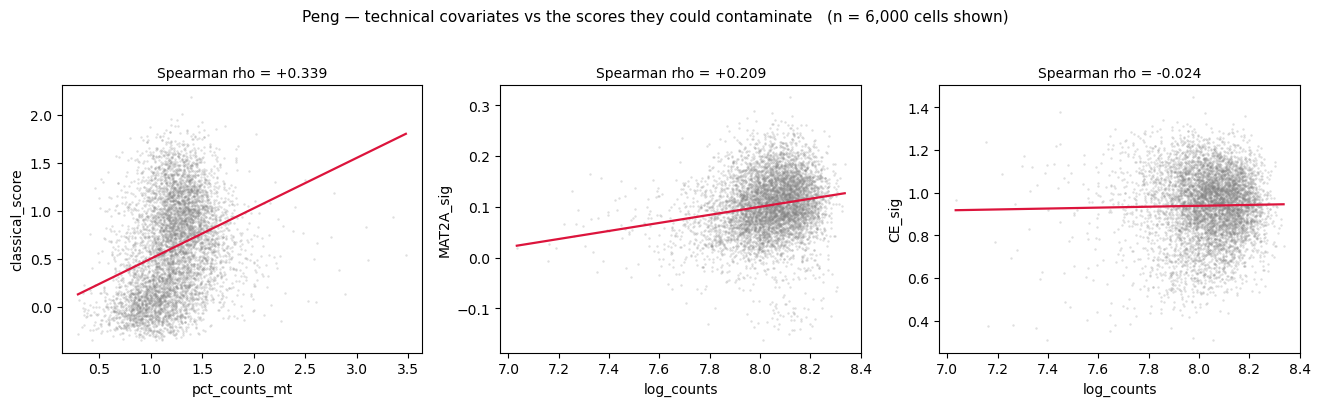

Both panels are non-flat, which is why every rho in this notebook is a PARTIAL
rho with both sides residualised on QC ranks. A flat panel would mean the
correction was unnecessary; these are not flat.


In [17]:
# ==========================================================================
# 9 · CONFOUND, DRAWN   ·   Fig. 2b/2c
# Same associations as the table above, as scatter + fit. Non-flat panels are the point:
# they are why every coefficient in this notebook is a partial rho with both sides
# residualised on QC ranks.
# ==========================================================================

# FIGURE — the confound, drawn. Same numbers as the table above.
fig_confound(mal.obs,
             [("pct_counts_mt", "classical_score"),
              ("log_counts", "MAT2A_sig"),
              ("log_counts", "CE_sig")],
             "Peng — technical covariates vs the scores they could contaminate",
             "peng")
print("Both panels are non-flat, which is why every rho in this notebook is a PARTIAL")
print("rho with both sides residualised on QC ranks. A flat panel would mean the")
print("correction was unnecessary; these are not flat.")


## 10 · What a standard (uncontrolled) analysis concludes

*Results → Distribution … (the uncontrolled baseline).* This is the **naive** within-patient
Spearman correlation, with **no** covariate correction — the analysis a standard pipeline would
run. It is reported so the effect of the controls in the next sections is visible as a change
from this baseline, not asserted.

In [18]:
# ==========================================================================
# 10 · NAIVE (UNCONTROLLED) ANALYSIS
# Within-patient Spearman with NO covariate correction -- the baseline a standard pipeline
# would report, shown so the effect of the controls is visible as a change from it.
# ==========================================================================

print("NAIVE within-patient Spearman vs classical score (NO controls)\n")
show([summarise(naive_spearman(mal.obs, t + "_sig"), t) for t in TARGETS])

NAIVE within-patient Spearman vs classical score (NO controls)

  signature                   n       neg    mean_rho         p
  VPS4A                      24     16/24     -0.0487    0.1074
  PRMT5                      24     10/24     +0.0207    0.2182
  MAT2A                      24      1/24     +0.3272    0.0000


## 11 · The proper method, and the negative controls  ·  **Fig. 3**

*Methods → Controls (Table 1); Results → Distribution of the Dependency Signatures.* The
QC-controlled within-patient partial Spearman correlation (both sides residualised) is computed
here, alongside the three negative controls of manuscript **Table 1**:

- **random gene-set null** (1,000 size-matched 96-gene sets drawn from the detected
  transcriptome) — is the effect above chance?
- **expression-matched null** (1,000 sets, each gene replaced by one of comparable mean
  expression, ±20 %) — a *harder* null: is the effect explained by expression level alone?
- **commonly-essential control** (the decisive one) — does generic essentiality deplete in
  classical cells as strongly?

Each stochastic step below takes its **own** generator seeded from `SEED`, rather than drawing
from a shared stream; the inline comment explains why this is not cosmetic.

**Why these choices**

| choice | why |
|---|---|
| Random sets of 96 detected genes | The same size as the signatures and drawn only from detected genes, so a null set has the same opportunity to be scored as a signature. |
| Expression-matched sets, each gene replaced by one within ±20% mean expression | Tight enough to match expression level, loose enough to leave many candidates per gene. It asks whether expression level alone explains an association. |
| 1,000 sets per null | Precise null mean and SD; empirical p down to 0.001. |
| Two SDs as the reference line | A convention, fixed before the results; it is reported as a convention, alongside empirical p values, CIs and BH q values (§R6). |
| The commonly-essential control | The decisive negative control: if a target signature behaved like generic essentiality, it would deplete in classical cells the same way. |

In [19]:
# ==========================================================================
# 11 · QC-CONTROLLED ANALYSIS + NEGATIVE CONTROLS   (Table 1)   ·   Fig. 3
# res: partial Spearman vs classical score for the three targets + commonly-essential.
# null: the random-gene-set null (N_NULL size-matched draws). SD-from-random reported for
# each. See the inline note on why each stochastic step gets its OWN generator.
# ==========================================================================

# Each stochastic step below takes its OWN generator, seeded from SEED, rather than
# drawing from the shared `rng`. With a shared generator, which gene sets the null
# draws depends on how many random numbers every earlier cell happened to consume --
# so adding a figure, or a QC step that subsamples, silently reseeds the null. That is
# what moved common-essential from -3.5 to -2.5 to -1.9 SD across runs whose rhos were
# byte-identical. Separate streams make each null reproducible on its own terms.
# WHY the random null: SIG_SIZE genes drawn from DETECTED genes only, so a null set has the same
# chance of being scored as a signature. Sorted before sampling because Python randomises string
# hashing per process, so the order of a set of gene names changes between sessions.
def random_null(ad, present, n=N_NULL):
    _null_rng = np.random.default_rng(SEED)
    out = []
    for _ in range(n):
        g = list(_null_rng.choice(sorted(present), size=SIG_SIZE, replace=False))
        sc.tl.score_genes(ad, g, score_name="_r", use_raw=True)
        out.append(np.mean(list(partial_spearman(ad.obs, "_r").values())))
    return np.array(out)

# WHY +/-20% mean expression: tight enough to match expression level, loose enough to leave many
# candidates per gene. The question it answers: does expression level alone explain the effect?
def expression_matched_null(ad, template, n=N_NULL):
    _expr_rng = np.random.default_rng(SEED + 1)   # own stream -- see random_null
    # .raw.X directly -- to_adata() here copied the entire matrix for a column mean
    gm = pd.Series(np.asarray(ad.raw.X.mean(axis=0)).ravel(),
                   index=list(ad.raw.var_names))
    out = []
    for _ in range(n):
        picked = []
        for g in template:
            if g not in gm.index:
                continue
            cands = gm[(gm > gm[g] * 0.8) & (gm < gm[g] * 1.2)].index
            if len(cands):
                picked.append(str(_expr_rng.choice(cands)))
        sc.tl.score_genes(ad, list(set(picked)), score_name="_m", use_raw=True)
        out.append(np.mean(list(partial_spearman(ad.obs, "_m").values())))
    return np.array(out)

res = {t: partial_spearman(mal.obs, t + "_sig") for t in TARGETS}
res["common_essential"] = partial_spearman(mal.obs, "CE_sig")
null = random_null(mal, raw)

print("PARTIAL SPEARMAN vs classical score (QC-controlled, BOTH sides)\n")
show([summarise(v, k) for k, v in res.items()])
print("\nrandom null (n={}): mean {:+.4f} | sd {:.4f}\n".format(N_NULL, null.mean(), null.std()))
print("  {:<24}{:>16}".format("signature", "SD from random"))
for k, v in res.items():
    print("  {:<24}{:>+16.1f}".format(k, sd_from(summarise(v)["mean_rho"], null)))

PARTIAL SPEARMAN vs classical score (QC-controlled, BOTH sides)

  signature                   n       neg    mean_rho         p
  VPS4A                      24     15/24     -0.0365    0.1515
  PRMT5                      24      9/24     +0.0325    0.0691
  MAT2A                      24      2/24     +0.3094    0.0000
  common_essential           24     19/24     -0.1650    0.0007

random null (n=1000): mean +0.0186 | sd 0.0850

  signature                 SD from random
  VPS4A                               -0.6
  PRMT5                               +0.2
  MAT2A                               +3.4
  common_essential                    -2.2


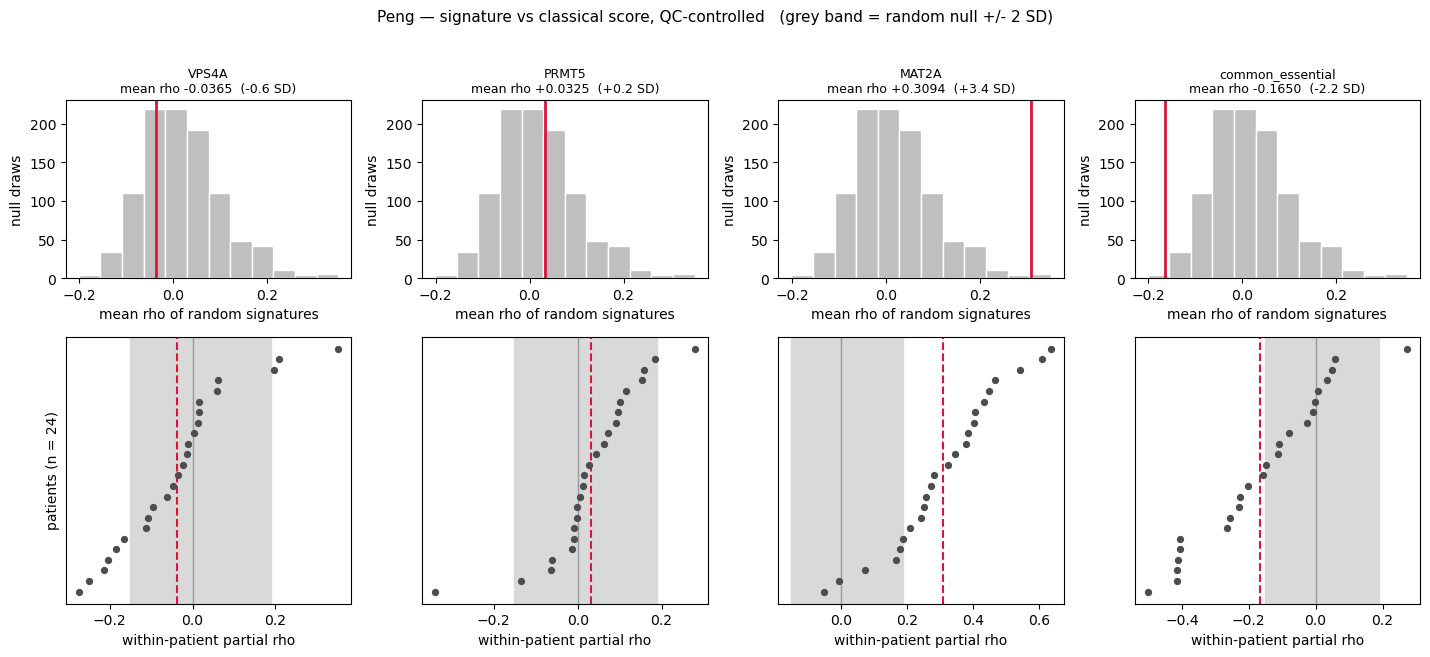

In [20]:
# ==========================================================================
# 11 · NULLS + PER-PATIENT FOREST (Peng)   ·   Fig. 3a/3c
# Pure consumer: reads res and null from the cell above and recomputes nothing.
# ==========================================================================

# FIGURE — null distributions and per-patient consistency (Peng).
# Reads the objects computed in the cell above; recomputes nothing.
fig_null_and_forest(res, null,
                    "Peng — signature vs classical score, QC-controlled",
                    "peng",
                    keys=TARGETS + ["common_essential"])


## 12 · The deciding test — head-to-head against generic essentiality  ·  **Fig. 4a**

*Results → Distribution … (specificity).* Paired, **within patient**, on the same cells: each
patient contributes its target coefficient and its commonly-essential coefficient, and the
**difference** (denoted **Δρ** in the manuscript) is tested with a Wilcoxon signed-rank test, so
any patient-level factor moving both signatures together cancels. A target that merely *matches*
generic essentiality **is** generic essentiality. The interpretation turns on **direction**:
VPS4A and PRMT5 sit above the depleted control only by staying flat, whereas MAT2A sits above it
by being **enriched** — the one direction a generic-essentiality confound cannot produce.

**Why a paired test.** Both coefficients come from the same cells of the same patient, so anything
that moves both (cell number, sequencing depth, tumor composition) cancels in the difference; a
Wilcoxon signed-rank test on the differences keeps the patient as the unit.

In [21]:
# ==========================================================================
# 12 · HEAD-TO-HEAD vs COMMONLY-ESSENTIAL (Peng)   ·   Fig. 4a
# Paired within patient (Delta-rho), Wilcoxon-tested. MAT2A beats the control in the
# OPPOSITE direction -- the one direction a generic-essentiality confound cannot fake.
# ==========================================================================

print("HEAD-TO-HEAD vs COMMON-ESSENTIAL (paired, within patient) -- PENG\n")
print("  {:<12}{:>5}{:>13}{:>20}{:>10}".format("target", "n", "mean diff", "more neg than CE", "p"))
for t in TARGETS:
    r = paired_vs(res[t], res["common_essential"])
    print("  {:<12}{:>5}{:>+13.4f}{:>20}{:>10.4f}".format(
        t, r["n"], r["mean_diff"], "{}/{}".format(r["n_more_neg"], r["n"]), r["p"]))
print("\n  MAT2A beats the control in the OPPOSITE direction, the one direction a")
print("  generic-essentiality confound cannot fake.")

HEAD-TO-HEAD vs COMMON-ESSENTIAL (paired, within patient) -- PENG

  target          n    mean diff    more neg than CE         p
  VPS4A          24      +0.1285                8/24    0.0491
  PRMT5          24      +0.1976                3/24    0.0000
  MAT2A          24      +0.4744                3/24    0.0000

  MAT2A beats the control in the OPPOSITE direction, the one direction a
  generic-essentiality confound cannot fake.


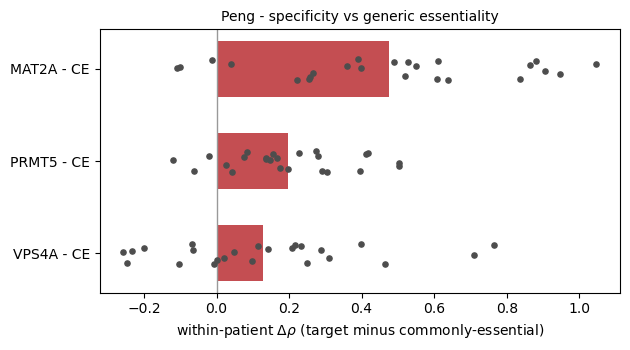

MAT2A is displaced above the control by being ENRICHED; VPS4A/PRMT5 sit above
it only because the control is depleted and they are flat.


In [22]:
# ===========================================================================
# FIGURE - HEAD-TO-HEAD vs COMMONLY-ESSENTIAL (Peng)   ·   manuscript Fig. 4a
# ===========================================================================
# Pure consumer of `res` from Section 12's cell: the within-patient difference
# (Delta-rho) between each target signature and the commonly-essential control.
# Bar = mean across patients; grey points = individual patients. Recomputes
# nothing stochastic.
if FIGURES:
    _keys = TARGETS
    _fig, _ax = plt.subplots(figsize=(6.4, 3.6))
    for _i, _t in enumerate(_keys):
        _pats = sorted(set(res[_t]) & set(res["common_essential"]))
        _d = np.array([res[_t][p] - res["common_essential"][p] for p in _pats])
        _ax.barh(_i, _d.mean(), color="#C44E52", height=0.6, zorder=2)
        _ax.scatter(_d, np.full(len(_d), _i) + np.random.default_rng(SEED).uniform(-0.12, 0.12, len(_d)),
                    s=14, color="0.3", zorder=3)
    _ax.axvline(0, color="0.6", lw=1)
    _ax.set_yticks(range(len(_keys)))
    _ax.set_yticklabels([t + " - CE" for t in _keys])
    _ax.set_xlabel(r"within-patient $\Delta\rho$ (target minus commonly-essential)")
    _ax.set_title("Peng - specificity vs generic essentiality", fontsize=10)
    plt.tight_layout()
    _show("peng_head_to_head")
    print("MAT2A is displaced above the control by being ENRICHED; VPS4A/PRMT5 sit above")
    print("it only because the control is depleted and they are flat.")


## 13 · Gene-overlap positive controls  ·  original **Fig. 4b**

*Methods/Results → Controls (sensitivity).* Two signatures with *known* state-restriction — the proliferation signature against
the cell-cycle program, and the classical score against the classical program — are passed through
the same program-restriction pipeline (top tertile of program-high cells vs the remainder,
within patient). The three target signatures are shown on the same axis for scale.

*Revision:* this section previously concluded that the VPS4A and PRMT5 nulls are "real nulls".
These two controls share genes with the program they are tested against, so they show only that
the pipeline detects restriction in that favourable case; they do not establish power for a
signature derived from DepMap. The revision therefore (i) calls the VPS4A and PRMT5 results
*no detected association* and tests equivalence to zero (§**R6**), and (ii) adds
dependency-based positive controls passed through the same DepMap-to-single-cell transfer and
redraws Fig. 4b on standardized scales (§**R7**).

**Why tertiles.** Splitting each patient's cells at the top third of a program score gives a
program-high group large enough for a stable mean in every patient, without a model of the score's
distribution. §R7 re-expresses the result on standardized and rank scales, so the choice of split
does not drive the comparison.

In [23]:
# ==========================================================================
# 13 · POSITIVE CONTROLS (sensitivity)   ·   Fig. 4b
# program_restriction: within-patient difference between program-high cells (top tertile)
# and the rest. Proliferation->cell-cycle and classical->classical are KNOWN state-restricted
# and should register strongly; the targets, on the same axis, should not. REVISION: these
# controls share genes with their programs, so they show the pipeline can detect restriction
# in that favourable case only; power for the targets is addressed in R6 (equivalence) and R7
# (dependency-based positive controls).
# ==========================================================================

def program_restriction(obs, score_col, program, min_cells=MIN_CELLS):
    col = "prog_" + program
    diffs = []
    for pat, g in obs.groupby("Patient", observed=True):
        if len(g) < min_cells:
            continue
        thr = g[col].quantile(0.66)
        hi, lo = g.loc[g[col] >= thr, score_col], g.loc[g[col] < thr, score_col]
        if len(hi) >= 10 and len(lo) >= 10:
            diffs.append(hi.mean() - lo.mean())
    d = np.array(diffs)
    return dict(n=len(d), mean_diff=float(d.mean()), p=float(wilcoxon(d)[1]))

print("POSITIVE CONTROLS (known state-restriction)\n")
print("  {:<18}{:<16}{:>5}{:>13}{:>10}".format("score", "program", "n", "mean diff", "p"))
for s_col, prog in [("prolif", "4_cellcycle"),
                    ("classical_score", CLASSICAL_PROG)]:
    r = program_restriction(mal.obs, s_col, prog)
    print("  {:<18}{:<16}{:>5}{:>+13.4f}{:>10.4f}".format(
        s_col, prog, r["n"], r["mean_diff"], r["p"]))
print("\n  The targets on the same axis, for scale:\n")
for t in TARGETS:
    r = program_restriction(mal.obs, t + "_sig", CLASSICAL_PROG)
    print("  {:<18}{:<16}{:>5}{:>+13.4f}{:>10.4f}".format(
        t + "_sig", CLASSICAL_PROG, r["n"], r["mean_diff"], r["p"]))
print("\n  -> the gene-overlap controls register far more strongly than the targets. Because they")
print("     share genes with their programs, this does not by itself show power for the targets;")
print("     see R6 (equivalence) and R7 (dependency-based positive controls).")

POSITIVE CONTROLS (known state-restriction)

  score             program             n    mean diff         p
  prolif            4_cellcycle        24      +0.2108    0.0000
  classical_score   8_classical        24      +0.3509    0.0000

  The targets on the same axis, for scale:

  VPS4A_sig         8_classical        24      +0.0047    0.2076
  PRMT5_sig         8_classical        24      -0.0082    0.0001
  MAT2A_sig         8_classical        24      +0.0292    0.0000

  -> the gene-overlap controls register far more strongly than the targets. Because they
     share genes with their programs, this does not by itself show power for the targets;
     see R6 (equivalence) and R7 (dependency-based positive controls).


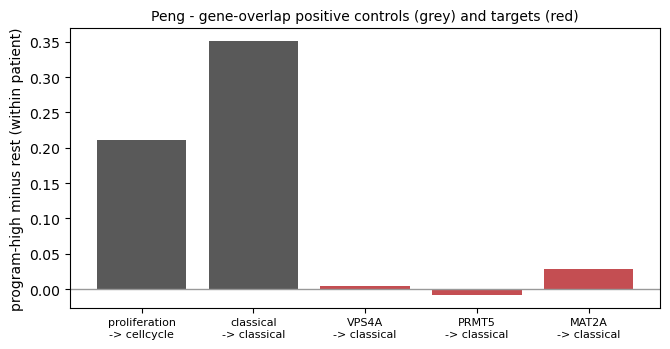

The gene-overlap controls register; compare the targets on the same axis.
Whether the VPS4A/PRMT5 results are true absences is tested in R6 (equivalence)
and R7 (dependency-based positive controls).


In [24]:
# ===========================================================================
# FIGURE - POSITIVE CONTROLS vs TARGETS on the program-restriction axis
#                (Peng)   ·   manuscript Fig. 4b
# ===========================================================================
# Recomputes via the same deterministic helper (program_restriction) used in the
# table above - no RNG, so identical to the printed values. The two gene-overlap
# controls are drawn next to the three targets.
if FIGURES:
    _rows = [("proliferation", "prolif", "4_cellcycle"),
             ("classical", "classical_score", CLASSICAL_PROG),
             ("VPS4A", "VPS4A_sig", CLASSICAL_PROG),
             ("PRMT5", "PRMT5_sig", CLASSICAL_PROG),
             ("MAT2A", "MAT2A_sig", CLASSICAL_PROG)]
    _labels, _vals, _cols = [], [], []
    for _name, _sc, _prog in _rows:
        _r = program_restriction(mal.obs, _sc, _prog)
        _labels.append("{}\n-> {}".format(_name, _prog.split("_", 1)[-1]))
        _vals.append(_r["mean_diff"])
        _cols.append("0.35" if _name in ("proliferation", "classical") else "#C44E52")
    _fig, _ax = plt.subplots(figsize=(6.8, 3.6))
    _ax.bar(range(len(_labels)), _vals, color=_cols)
    _ax.axhline(0, color="0.6", lw=1)
    _ax.set_xticks(range(len(_labels)))
    _ax.set_xticklabels(_labels, fontsize=8)
    _ax.set_ylabel("program-high minus rest (within patient)")
    _ax.set_title("Peng - gene-overlap positive controls (grey) and targets (red)", fontsize=10)
    plt.tight_layout()
    _show("peng_positive_controls")
    print("The gene-overlap controls register; compare the targets on the same axis.")
    print("Whether the VPS4A/PRMT5 results are true absences is tested in R6 (equivalence)")
    print("and R7 (dependency-based positive controls).")


## 14 · MAT2A robustness tests  ·  **Fig. 5**

*Methods → Robustness Tests (Table 2); Results → Validation of the MAT2A association.* Only the
MAT2A signature cleared the negative controls, so it alone is carried into the six robustness
tests. **Each pass criterion was fixed before the test was computed** — if any fails, MAT2A is
not a finding.

*Revision:* §R1–R5 and §R8 add the tests the review asked for (doublet-flagged cells removed,
high-confidence malignant cells, tumours with 9p21 loss evidence, independent epithelial and
secretory programs, epithelial-identity genes removed, the basal score modelled explicitly),
and §**R10** redraws Fig. 5 with every test in Table 2, for **both** cohorts, with 95% CIs.

| test | challenge | passes if |
|---|---|---|
| **Circularity** | overlap with Moffitt classical/basal genes | no classical-marker overlap drives it |
| **Proliferation** | proliferation added to the QC covariates | the effect persists |
| **Scoring method** | re-scored with a rank-based (AUCell-style) measure | the effect reproduces |
| **Aneuploidy** | restricted to CNV-positive cells (Peng) | the effect persists |
| **Single-gene** | each gene dropped in turn | no gene shifts the mean by > 30 % |
| **Compositional** | compared to the expression-matched null | > 2 SD from that null |

**Why each test**

| test | the alternative explanation it addresses |
|---|---|
| Circularity | The signature shares genes with the classical list, so the correlation is partly a gene list correlating with itself. |
| Proliferation | Cell cycling drives both the classical score and the signature. |
| Scoring method | The association is an artefact of `score_genes`' control-gene subtraction. |
| Aneuploidy | Non-malignant cells in the compartment create the association. Restricting to CNV-positive cells removes cells from every patient, so the per-patient minimum is 30 here. |
| Single-gene | One gene carries the association. A gene shifting the mean by more than 30% (about a third of the effect) would make the signature effectively a single-gene readout. |
| Compositional | Expression level alone produces the association. |

In [25]:
# ==========================================================================
# 14 · ROBUSTNESS TESTS -- CIRCULARITY, PROLIFERATION (Peng)   ·   Fig. 5
# Circularity: MAT2A signature genes vs the Moffitt classical/basal lists (a shared basal
# gene works AGAINST the enrichment, so it is conservative, not circular).
# Proliferation: adding proliferation to the QC covariates barely moves the coefficient,
# so the association is not a proliferation effect.
# ==========================================================================

mat = [g for g in signatures["MAT2A"] if g in raw]
full = summarise(res["MAT2A"])["mean_rho"]

print("CIRCULARITY")
print("    MAT2A n Moffitt-CLASSICAL: {}  {}".format(
    len(set(mat) & set(MOFFITT_CLASSICAL)), sorted(set(mat) & set(MOFFITT_CLASSICAL))))
print("    MAT2A n Moffitt-BASAL:     {}  {}".format(
    len(set(mat) & set(MOFFITT_BASAL)), sorted(set(mat) & set(MOFFITT_BASAL))))
print("    NB: a BASAL marker in a classical-ENRICHED signature works AGAINST the")
print("        finding -- it makes the result conservative, not circular.\n")

print("PROLIFERATION")
print("    classical vs prolif: {:+.3f} | MAT2A vs prolif: {:+.3f}".format(
    spearmanr(mal.obs["classical_score"], mal.obs["prolif"])[0],
    spearmanr(mal.obs["MAT2A_sig"], mal.obs["prolif"])[0]))
print("    (both nonzero => the mediation path classical <- prolif -> MAT2A is OPEN)\n")
show([summarise(res["MAT2A"], "MAT2A | QC only"),
      summarise(partial_spearman(mal.obs, "MAT2A_sig", covars=QC_COVARS + ["prolif"]),
                "MAT2A | QC + prolif")])

CIRCULARITY
    MAT2A n Moffitt-CLASSICAL: 0  []
    MAT2A n Moffitt-BASAL:     1  ['CTSV']
    NB: a BASAL marker in a classical-ENRICHED signature works AGAINST the
        finding -- it makes the result conservative, not circular.

PROLIFERATION
    classical vs prolif: -0.114 | MAT2A vs prolif: -0.183
    (both nonzero => the mediation path classical <- prolif -> MAT2A is OPEN)

  signature                   n       neg    mean_rho         p
  MAT2A | QC only            24      2/24     +0.3094    0.0000
  MAT2A | QC + prolif        24      2/24     +0.2965    0.0000


In [26]:
# ==========================================================================
# 14 · ROBUSTNESS TESTS -- SCORING METHOD, ANEUPLOIDY (Peng)   ·   Fig. 5
# Scoring method: AUCell-style rank scoring reproduces the effect (no shared arithmetic
# with score_genes). Aneuploidy: restricting to CNV-positive cells (30-cell floor, since
# the restriction thins each patient) leaves MAT2A intact and VPS4A/PRMT5 null.
# ==========================================================================

print("SCORING METHOD -- AUCell-style rank scoring\n")
mal.obs["MAT2A_auc"] = manual_aucell(mal, mat)
show([summarise(partial_spearman(mal.obs, "MAT2A_auc"), "MAT2A | AUCell")])
print("\n    AUCell vs score_genes agreement: {:+.3f}".format(
    spearmanr(mal.obs["MAT2A_auc"], mal.obs["MAT2A_sig"])[0]))

sub = None                                   # REVISION: stays None if the aneuploidy test cannot run
if not os.path.exists(PENG_CNV):
    print("\n\nANEUPLOIDY test skipped -- peng_infercnv_v2.h5ad is missing (R2 gives the per-patient CNV-positive test)")
else:
    print("\n\nANEUPLOIDY -- CNV-positive cells only\n")
    cnvobj = sc.read_h5ad(PENG_CNV)
    ref = cnvobj.obs.loc[cnvobj.obs[MAL_COL].isin(["Immune cells", "Stromal cells"]), "cnv_score"]
    aneu = set(cnvobj.obs.index[(cnvobj.obs[MAL_COL] == "Malignant cells") &
                                (cnvobj.obs["cnv_score"] > ref.quantile(0.95))])
    sub = mal.obs[mal.obs.index.isin(aneu)].copy()
    print("    CNV-positive cells: {:,}\n".format(len(sub)))
    show([summarise(partial_spearman(sub, t + "_sig", min_cells=30), t + " | CNV-positive")
          for t in TARGETS])

SCORING METHOD -- AUCell-style rank scoring

  signature                   n       neg    mean_rho         p
  MAT2A | AUCell             24      0/24     +0.2479    0.0000

    AUCell vs score_genes agreement: +0.693


ANEUPLOIDY -- CNV-positive cells only

    CNV-positive cells: 3,329

  signature                   n       neg    mean_rho         p
  VPS4A | CNV-positive       20     13/20     -0.0430    0.1327
  PRMT5 | CNV-positive       20      6/20     +0.0101    0.3488
  MAT2A | CNV-positive       20      1/20     +0.2403    0.0000


In [27]:
# ==========================================================================
# 14 · ROBUSTNESS TESTS -- SINGLE-GENE, COMPOSITIONAL (Peng)   ·   Fig. 5
# Single-gene (leave-one-out): no single gene shifts the mean coefficient by more than 30%.
# Compositional: MAT2A sits > 2 SD above the harder EXPRESSION-MATCHED null.
# ==========================================================================

print("SINGLE-GENE -- leave-one-out\n")
deltas = []
for g in mat:
    sc.tl.score_genes(mal, [x for x in mat if x != g], score_name="_lo", use_raw=True)
    deltas.append((g, np.mean(list(partial_spearman(mal.obs, "_lo").values())) - full))
deltas.sort(key=lambda x: abs(x[1]), reverse=True)
print("    MAT2A full mean |rho = {:+.4f}\n".format(full))
for g, d in deltas[:5]:
    print("      drop {:<12} -> {:+.4f}   ({:.0f}% of effect)".format(
        g, d, abs(d) / abs(full) * 100))

print("\n\nCOMPOSITIONAL -- expression-matched null\n")
mnull = expression_matched_null(mal, mat)
print("    MAT2A                          : {:+.4f}".format(full))
print("    expression-matched nulls (n={}) : mean {:+.4f} | sd {:.4f}".format(
    N_NULL, mnull.mean(), mnull.std()))
print("\n    -> MAT2A is {:+.1f} SD from the EXPRESSION-MATCHED null".format(sd_from(full, mnull)))

SINGLE-GENE -- leave-one-out

    MAT2A full mean |rho = +0.3094

      drop C19orf33     -> -0.0323   (10% of effect)
      drop CAPN8        -> -0.0298   (10% of effect)
      drop TPD52        -> -0.0209   (7% of effect)
      drop APOBEC3H     -> -0.0147   (5% of effect)
      drop TNFSF13      -> -0.0141   (5% of effect)


COMPOSITIONAL -- expression-matched null

    MAT2A                          : +0.3094
    expression-matched nulls (n=1000) : mean +0.0785 | sd 0.0932

    -> MAT2A is +2.5 SD from the EXPRESSION-MATCHED null


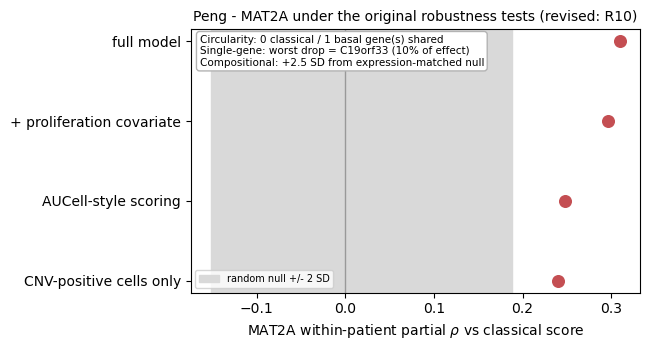

In [28]:
# ===========================================================================
# FIGURE - MAT2A ROBUSTNESS FOREST (Peng)   ·   manuscript Fig. 5
# ===========================================================================
# Consumes objects the robustness cells above already left in the namespace
# (full, sub, mnull, deltas, mat, null) and recomputes only the two cheap,
# deterministic partial-Spearman means for the +proliferation and AUCell rows
# (no RNG, no h5ad re-read). Each row is the MAT2A partial rho under one
# challenge, against the same +/-2 SD random-null band as Fig. 3.
if FIGURES:
    _full_rho  = full                                              # full model
    _prolif_rho = np.mean(list(partial_spearman(
        mal.obs, "MAT2A_sig", covars=QC_COVARS + ["prolif"]).values()))
    _auc_rho   = np.mean(list(partial_spearman(mal.obs, "MAT2A_auc").values()))
    _rows = [("full model", _full_rho),
             ("+ proliferation covariate", _prolif_rho),
             ("AUCell-style scoring", _auc_rho)]
    if sub is not None:                                            # the aneuploidy test ran
        _rows.append(("CNV-positive cells only",
                      np.mean(list(partial_spearman(sub, "MAT2A_sig", min_cells=30).values()))))
    _fig, _ax = plt.subplots(figsize=(6.6, 3.6))
    _y = np.arange(len(_rows))[::-1]
    _ax.axvspan(null.mean() - 2 * null.std(), null.mean() + 2 * null.std(),
                color="0.85", zorder=0, label="random null +/- 2 SD")
    _ax.axvline(0, color="0.6", lw=1)
    _ax.scatter([v for _, v in _rows], _y, s=70, color="#C44E52", zorder=3)
    _ax.set_yticks(_y)
    _ax.set_yticklabels([n for n, _ in _rows])
    _ax.set_xlabel(r"MAT2A within-patient partial $\rho$ vs classical score")
    _ax.set_title("Peng - MAT2A under the original robustness tests (revised: R10)", fontsize=10)
    # circularity / single-gene / compositional are not coefficients on this axis -> annotate them
    _circ_c = len(set(mat) & set(MOFFITT_CLASSICAL))
    _circ_b = len(set(mat) & set(MOFFITT_BASAL))
    _worst_g, _worst_d = deltas[0]
    _comp_sd = sd_from(full, mnull)
    _txt = ("Circularity: {} classical / {} basal gene(s) shared\n"
            "Single-gene: worst drop = {} ({:.0f}% of effect)\n"
            "Compositional: {:+.1f} SD from expression-matched null").format(
        _circ_c, _circ_b, _worst_g, abs(_worst_d) / abs(full) * 100, _comp_sd)
    # All four points hug the RIGHT edge, so both annotations live on the LEFT
    # half now: the annotation box moves to the upper-left (va="top", y=0.98) and
    # the legend to the lower-left. This clears the entire right column, where the
    # bottom "aneuploid cells only" point was being hidden under the old lower-
    # right legend.
    _ax.legend(loc="lower left", fontsize=7)
    _ax.text(0.02, 0.98, _txt, transform=_ax.transAxes, fontsize=7.5, va="top",
             bbox=dict(boxstyle="round", fc="white", ec="0.7"))
    plt.tight_layout()
    _show("peng_mat2a_robustness")

## 15 · Second cohort — Steele  ·  **Fig. 3**

*Results → Distribution … (second cohort).* The **entire** pipeline — QC-controlled partial
Spearman, negative controls, head-to-head against the commonly-essential control, and the proliferation,
scoring-method and compositional robustness tests — is re-run on the Steele cohort. *Revision:* previously called an
independent replication; the comparison is informative because the same QC thresholds, scoring
and statistics are applied to both cohorts (§3–4), but the two were generated and pre-processed
upstream by different groups, and Steele's malignant compartment is cluster-assigned (§4). This section also produces
the Steele half of manuscript **Fig. 3** and the two-cohort comparison scatter.

**Why the same code.** Running the identical functions, thresholds and controls on the second
cohort means any difference between cohorts comes from the data, not from the analysis.

In [29]:
# ==========================================================================
# 15 · SECOND COHORT -- STEELE   ·   Fig. 3b/3d
# The whole pipeline on the second cohort: partial Spearman + nulls, head-to-head vs
# commonly-essential, and the proliferation, scoring-method and compositional robustness
# tests. s_res / s_null mirror res / null.
# ==========================================================================

s_res = {t: partial_spearman(steele.obs, t + "_sig") for t in TARGETS}
s_res["common_essential"] = partial_spearman(steele.obs, "CE_sig")
s_null = random_null(steele, sraw)

print("STEELE -- partial Spearman vs classical score\n")
show([summarise(v, k) for k, v in s_res.items()])
print("\n  {:<24}{:>16}".format("signature", "SD from random"))
for k, v in s_res.items():
    print("  {:<24}{:>+16.1f}".format(k, sd_from(summarise(v)["mean_rho"], s_null)))

print("\n\nSTEELE -- head-to-head vs common-essential (paired)\n")
print("  {:<12}{:>5}{:>13}{:>20}{:>10}".format("target", "n", "mean diff", "more neg than CE", "p"))
for t in TARGETS:
    r = paired_vs(s_res[t], s_res["common_essential"])
    print("  {:<12}{:>5}{:>+13.4f}{:>20}{:>10.4f}".format(
        t, r["n"], r["mean_diff"], "{}/{}".format(r["n_more_neg"], r["n"]), r["p"]))

print("\n\nSTEELE -- MAT2A ROBUSTNESS TESTS (proliferation, scoring method, compositional)\n")
s_mat = [g for g in signatures["MAT2A"] if g in sraw]
steele.obs["MAT2A_auc"] = manual_aucell(steele, s_mat)
show([summarise(s_res["MAT2A"], "MAT2A | QC only"),
      summarise(partial_spearman(steele.obs, "MAT2A_sig", covars=QC_COVARS + ["prolif"]),
                "MAT2A | QC + prolif"),
      summarise(partial_spearman(steele.obs, "MAT2A_auc"), "MAT2A | AUCell")])
s_mnull = expression_matched_null(steele, s_mat)
print("\n  MAT2A is {:+.1f} SD from the expression-matched null (Steele)".format(
    sd_from(summarise(s_res["MAT2A"])["mean_rho"], s_mnull)))

STEELE -- partial Spearman vs classical score

  signature                   n       neg    mean_rho         p
  VPS4A                      14      8/14     -0.0104    0.9515
  PRMT5                      14      5/14     +0.0134    0.6257
  MAT2A                      14      1/14     +0.3168    0.0002
  common_essential           14     11/14     -0.1666    0.0107

  signature                 SD from random
  VPS4A                               -0.2
  PRMT5                               +0.1
  MAT2A                               +4.0
  common_essential                    -2.3


STEELE -- head-to-head vs common-essential (paired)

  target          n    mean diff    more neg than CE         p
  VPS4A          14      +0.1562                5/14    0.1531
  PRMT5          14      +0.1800                3/14    0.0040
  MAT2A          14      +0.4834                1/14    0.0006


STEELE -- MAT2A ROBUSTNESS TESTS (proliferation, scoring method, compositional)

  signature                

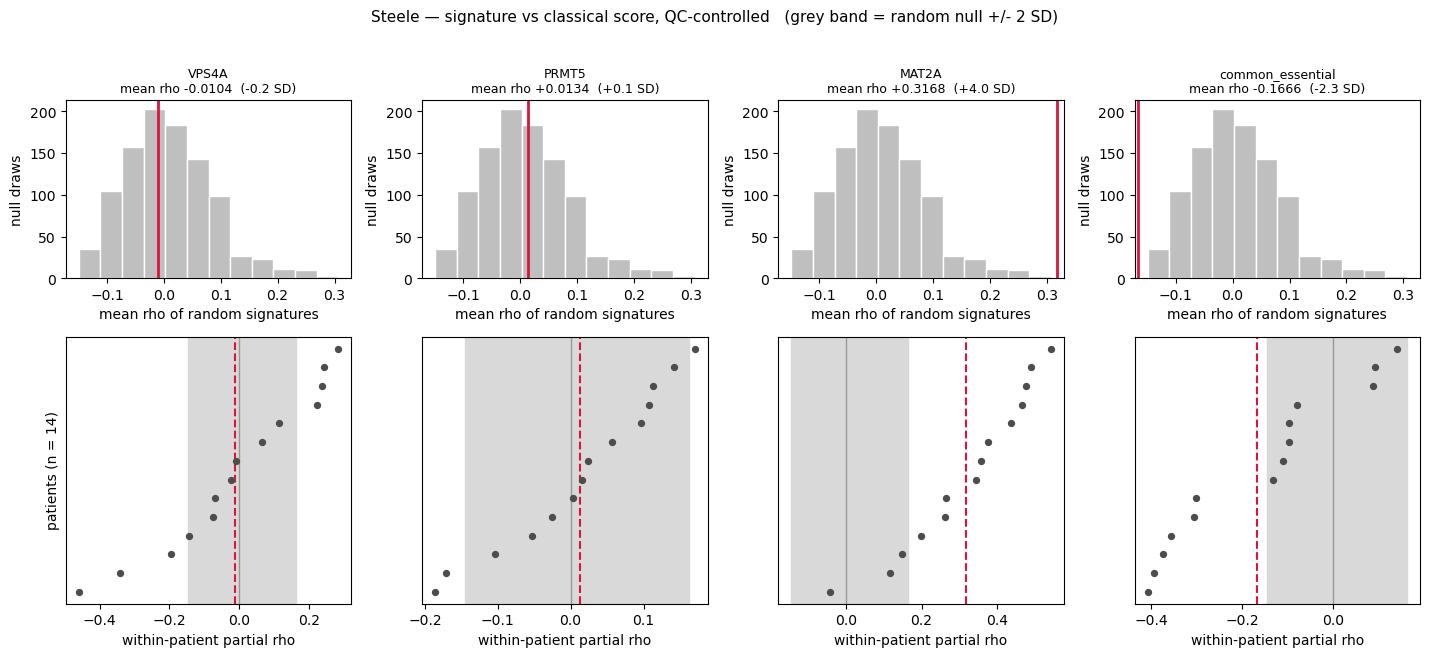

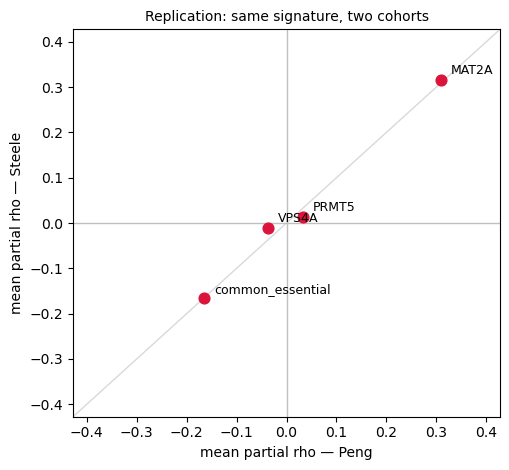

In [30]:
# ==========================================================================
# 15 · NULLS + FOREST (Steele) and TWO-COHORT REPLICATION SCATTER   ·   Fig. 3
# Mirrors the Peng figure so the cohorts can be compared by eye, then plots each signature's
# mean coefficient in Peng vs Steele (points on the diagonal = the cohorts agree).
# ==========================================================================

# FIGURE — null distributions and per-patient consistency (Steele).
# Mirrors the Peng figure exactly so the two cohorts can be compared by eye.
fig_null_and_forest(s_res, s_null,
                    "Steele — signature vs classical score, QC-controlled",
                    "steele",
                    keys=TARGETS + ["common_essential"])

# FIGURE — replication at a glance: each signature's rho in both cohorts.
if FIGURES:
    fig, ax = plt.subplots(figsize=(5.2, 4.8))
    keys = TARGETS + ["common_essential"]
    xs = [np.mean(list(res[k].values())) for k in keys]
    ys = [np.mean(list(s_res[k].values())) for k in keys]
    ax.axhline(0, color="0.75", lw=1)
    ax.axvline(0, color="0.75", lw=1)
    lim = max(map(abs, xs + ys)) * 1.35
    ax.plot([-lim, lim], [-lim, lim], color="0.85", lw=1, zorder=0)
    ax.scatter(xs, ys, s=60, color="crimson", zorder=3)
    for k, x, y in zip(keys, xs, ys):
        ax.annotate(k, (x, y), textcoords="offset points", xytext=(7, 4), fontsize=9)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_xlabel("mean partial rho — Peng")
    ax.set_ylabel("mean partial rho — Steele")
    ax.set_title("Replication: same signature, two cohorts", fontsize=10)
    plt.tight_layout()
    _show("peng_vs_steele_replication")


# Revision analyses (R0–R10) — response to the NHSJS reviewers

Everything from here to §16 was added for the revision. **Runtime:** roughly 2–4 h on the
first run (patient-specific inferCNV and the cNMF benchmark dominate); every expensive step is
cached in `~/Downloads/revision`, so a re-run with `REV_FORCE = False` takes minutes. Each section names the reviewer
point it answers and the manuscript section it feeds. Sections 1–15 above are unchanged
except for wording, so every number already in the manuscript is still produced exactly
as before; the sections below **add** analyses and never overwrite `res`, `s_res`, `null`,
`s_null` or the signature scores.

| section | reviewer point | what it adds |
|---|---|---|
| R0 | — | extra inputs, constants, shared helpers |
| R1 | Must-fix 10 | doublet detection on the original counts; epithelial–stromal / epithelial–immune doublets; sensitivity analysis |
| R2 | Must-fix 9, 13 | per-patient copy number against a reference that includes normal epithelium; high-confidence malignant cells in **both** cohorts; *MAT2A* score in CNV-positive vs CNV-negative epithelial cells |
| R3 | Must-fix 1, 11; Recommended 1 | 9p21 (*MTAP*) and 18q (*VPS4B*) loss per tumour and per cell, homozygous vs heterozygous, with bootstrap uncertainty; association inside tumours with loss |
| R4 | Must-fix 2, 3, 5 | held-out validation of the signatures against measured dependency (Chronos and DEMETER2), deletion-based / lineage-held / other-cut-off / passenger-intact derivations, over-representation of all 100 genes |
| R5 | Must-fix 5, 6; Recommended 3 | independent epithelial, secretory, methionine and published classical programs; adjustment; per-gene contributions; signature rebuilt without epithelial-identity genes |
| R6 | Must-fix 7, 12 | variability-, detection- and covariance-matched nulls; empirical p; patient-level CIs; Benjamini–Hochberg; equivalence tests (TOST) |
| R7 | Must-fix 7 | dependency-based positive controls (*CDS2*, *KRAS*) through the full DepMap-to-single-cell transfer; standardized Fig. 4b |
| R8 | Must-fix 8 | basal score modelled explicitly; dual-score cell groups; published single-cell subtype signatures |
| R9 | Must-fix 13 | benchmark of the consensus-clustered NMF against standard cNMF |
| R10 | — | revised Fig. 5 (both cohorts, 95% CIs) and one file holding every revision number, printed against the manuscript's placeholders |

**Extra inputs.** Download into `~/Downloads` before running. The input-search cell at the top
of the notebook (right after Configuration) looks for them anywhere on the computer (any folder,
renamed copies such as `Model (1).csv`, the figshare zip, the Recycle Bin) and puts what it finds
into `~/Downloads`; R0 then prints which are present. A missing input skips only the part that
needs it, and says so:

- `OmicsCNGeneWGS.csv` (gene-level relative copy number) and `Model.csv` — DepMap (depmap.org → Downloads); the run reported here used the copy-number file of a later release than the 26Q1 expression and Chronos files, matched by ModelID
- `D2_combined_gene_dep_scores.csv` — DEMETER2 Data v6 (depmap.org → Downloads → DEMETER2)
- `raghavan2021_signatures.csv` — two columns, `signature,gene`, holding the scClassical and
  scBasal genes from Raghavan et al. 2021 (*Cell*) supplementary table
- optional `peng_counts.h5ad` / `steele_counts.h5ad` — original integer UMI matrices (cells × genes,
  obs_names matching the processed files) if R1 cannot recover counts exactly from the stored data

**Packages:** `pip install gseapy cnmf` (R4/R5 gene sets and over-representation; R9 benchmark).

In [31]:
# ==========================================================================
# R0 · REVISION SETUP
# Paths to the extra inputs, every revision constant (set here, in one place, before the cells
# that use them), and the helpers shared by R1-R10. Expensive steps cache their output in REV_DIR;
# REV_FORCE = True recomputes every cached step from scratch -- the run the revision reports.
# Nothing here touches res / s_res / null / s_null or any existing score column.
# ==========================================================================

import json, h5py, zlib
from scipy.stats import mannwhitneyu, t as tdist
from statsmodels.stats.multitest import multipletests
try:
    from anndata.io import read_elem, sparse_dataset
except ImportError:
    from anndata.experimental import read_elem, sparse_dataset

REV_DIR = os.path.join(DOWNLOADS, "revision")      # every revision output and cache
os.makedirs(REV_DIR, exist_ok=True)
REV_FORCE = True                                    # True = recompute every cached step

def rev_path(name):
    return os.path.join(REV_DIR, name)

# gi: gene symbols italic in figure text, as in the manuscript (human gene symbols are italicized;
# reviewer minor issue 2). Wraps each symbol in matplotlib mathtext italics; other words untouched.
import re as _re_gi
GENE_SYMBOLS = ["VPS4A", "VPS4B", "PRMT5", "MAT2A", "MTAP", "CDKN2A", "SMAD4", "KRAS", "CDS1", "CDS2", "EMP1"]


def gi(text):
    return _re_gi.sub(r"\b({})\b".format("|".join(GENE_SYMBOLS)), r"$\\mathit{\1}$", str(text))


# ---- manuscript-figure layout -------------------------------------------------------------
# Every manuscript figure (Figs. 1-6: R11a-d, R10a, R8c-3) is drawn at its printed size with
# these settings, so the font sizes are the sizes on the page (6-7 pt text, 7.5 pt titles).
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple

MS_RC = {"font.size": 6.5, "axes.titlesize": 7.5, "axes.labelsize": 6.5, "xtick.labelsize": 6,
         "ytick.labelsize": 6, "legend.fontsize": 6, "axes.linewidth": 0.6, "xtick.major.width": 0.6,
         "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5}


def ms_figure(figsize):
    """A manuscript figure on matplotlib's constrained layout, which places every panel's tick
    labels, axis labels, titles, colorbars and legends so they cannot overlap one another
    (matplotlib >= 3.5; older versions take the equivalent constrained_layout=True)."""
    try:
        return plt.figure(figsize=figsize, layout="constrained")
    except TypeError:
        return plt.figure(figsize=figsize, constrained_layout=True)


def ms_legend_under_labels(ax, handles, labels, **kw):
    """A legend in the otherwise empty corner below a panel's y tick labels and beside its x
    label: right-aligned just left of the panel's lower-left corner, outside the plotting area.
    Constrained layout counts it with the panel, so it cannot overlap another element."""
    kw.setdefault("ncol", 1)
    return ax.legend(handles, labels, loc="upper right", bbox_to_anchor=(-0.02, -0.02), frameon=False,
                     borderaxespad=0.0, **kw)


def ms_legend(fig, handles, labels, where="lower", **kw):
    """One legend for the whole figure, in its own strip outside every panel, so it can never
    cover data. 'outside ...' locations need matplotlib >= 3.7; older versions put the same
    legend just below (or above) the figure, which bbox_inches='tight' then includes."""
    kw.setdefault("ncol", len(labels))
    try:
        return fig.legend(handles, labels, loc="outside {} center".format(where), frameon=False, **kw)
    except (ValueError, TypeError):
        y, va = (0.0, "upper") if where == "lower" else (1.0, "lower")
        return fig.legend(handles, labels, loc="{} center".format(va), bbox_to_anchor=(0.5, y),
                          frameon=False, **kw)


def fig_layout_check(fig, name, max_empty_frac=0.03, min_empty_in=0.35):
    """Treat every element of a figure as a box -- each panel's plotting area, colorbar, tick
    label, axis label, panel title, legend and piece of text -- and check two things: that no
    two boxes intersect, and that no large region of the figure is left empty (the largest
    empty rectangle is reported; it is flagged when both its sides exceed `min_empty_in` inches
    and it covers more than `max_empty_frac` of the figure). Text placed deliberately inside its
    own panel (the heatmap values of Fig. 2) belongs to that panel. Prints one verdict line;
    changes nothing in the figure."""
    fig.canvas.draw()                                   # runs the layout, so the boxes are final
    rnd = fig.canvas.get_renderer()
    boxes = []

    def add(kind, art, owner):
        if art is None or not art.get_visible():
            return
        if hasattr(art, "get_text") and not str(art.get_text()).strip():
            return
        try:
            bb = art.get_window_extent(rnd)
        except Exception:
            return
        if bb.width > 0.5 and bb.height > 0.5 and np.all(np.isfinite(bb.extents)):
            boxes.append((kind, bb, owner))

    def in_view(t, axis, ax):
        lo, hi = sorted(ax.get_xlim() if axis == "x" else ax.get_ylim())
        v = t.get_position()[0 if axis == "x" else 1]
        return lo - 1e-9 <= v <= hi + 1e-9

    def walk(f):                                        # the figure and its subfigures, if any
        yield f
        for sf in getattr(f, "subfigs", []):
            yield from walk(sf)
    figs = list(walk(fig))
    axes_all = list({id(a): a for f in figs for a in f.axes}.values())
    for i, ax in enumerate(axes_all):
        if not ax.get_visible():
            continue
        tag = "panel {}".format(i + 1)
        add(tag + " plotting area", ax, ("area", i))
        for axis, labels in (("x", ax.get_xticklabels()), ("y", ax.get_yticklabels())):
            for t in labels:
                if in_view(t, axis, ax):
                    add("{} tick label '{}'".format(tag, t.get_text()), t, ("dec", i))
        add(tag + " x label", ax.xaxis.label, ("dec", i))
        add(tag + " y label", ax.yaxis.label, ("dec", i))
        for t in (ax.title, getattr(ax, "_left_title", None), getattr(ax, "_right_title", None)):
            add(tag + " title", t, ("dec", i))
        add(tag + " legend", ax.get_legend(), ("leg", i))
        for t in ax.texts:
            add("{} text '{}'".format(tag, t.get_text()[:20]), t, ("in", i))
    for f in figs:
        for lg in f.legends:
            add("figure legend", lg, ("fig", -1))
        for t in f.texts:
            add("figure text '{}'".format(t.get_text()[:20]), t, ("fig", -1))

    tol = fig.dpi / 72.0                                # one point
    hits = []
    for a_ in range(len(boxes)):
        ka, ba, oa = boxes[a_]
        for b_ in range(a_ + 1, len(boxes)):
            kb, bb, ob = boxes[b_]
            if {oa[0], ob[0]} == {"area", "in"} and oa[1] == ob[1]:
                continue
            w = min(ba.x1, bb.x1) - max(ba.x0, bb.x0)
            h = min(ba.y1, bb.y1) - max(ba.y0, bb.y0)
            if w > tol and h > tol:
                hits.append((ka, kb))

    # largest empty rectangle on a 0.05-inch grid over the saved (tight) extent of the figure
    tb = fig.get_tightbbox(rnd)                         # inches
    nx, ny = max(1, int(tb.width * 20)), max(1, int(tb.height * 20))
    cw, ch = tb.width * fig.dpi / nx, tb.height * fig.dpi / ny
    full = np.zeros((ny, nx), bool)
    for _, bb, _ in boxes:
        i0 = int(np.floor((bb.x0 - tb.x0 * fig.dpi) / cw)); i1 = int(np.ceil((bb.x1 - tb.x0 * fig.dpi) / cw))
        j0 = int(np.floor((bb.y0 - tb.y0 * fig.dpi) / ch)); j1 = int(np.ceil((bb.y1 - tb.y0 * fig.dpi) / ch))
        full[max(j0, 0):max(min(j1, ny), 0), max(i0, 0):max(min(i1, nx), 0)] = True
    best, heights = (0, 0, 0), np.zeros(nx, int)
    for j in range(ny):
        heights = np.where(full[j], 0, heights + 1)
        stack = []
        for i in range(nx + 1):
            hgt = heights[i] if i < nx else 0
            start = i
            while stack and stack[-1][1] >= hgt:
                s0, h0 = stack.pop()
                if h0 * (i - s0) > best[0]:
                    best = (h0 * (i - s0), i - s0, h0)
                start = s0
            stack.append((start, hgt))
    ew, eh = best[1] * tb.width / nx, best[2] * tb.height / ny
    frac = best[0] / float(nx * ny)
    gap = frac > max_empty_frac and min(ew, eh) > min_empty_in
    print("{} layout: {} boxes, {} intersecting pair(s); largest empty area {:.2f} x {:.2f} in "
          "({:.1%} of the figure) -> {}".format(name, len(boxes), len(hits), ew, eh, frac,
                                                "OK" if not hits and not gap else "CHECK"))
    for ka, kb in hits[:10]:
        print("   overlap: {}  <->  {}".format(ka, kb))
    return dict(boxes=len(boxes), overlaps=hits, empty_in=(ew, eh), empty_frac=frac, ok=not hits and not gap)


LAYOUT = {}                                         # fig_layout_check verdict per manuscript figure (R11e lists them)


def need_rev(path):
    """Same contract as need_build(), for revision caches."""
    return REV_FORCE or not os.path.exists(path)

# ---- extra inputs (optional: each missing one skips only the analysis that needs it) --
# None of these is produced by sections 1-17: each has to be downloaded (or, for the Raghavan
# signatures, typed in) once, by hand. The printout below says which are missing and where from.
# DepMap renames files between releases and browsers rename repeat downloads ("Model (1).csv"),
# so each input is looked for under every known name, case-insensitively, in ~/Downloads and
# one folder below it (e.g. an unzipped "DepMap Public 26Q1" folder). The first match wins.
import re as _re

def _find_input(names):
    want = [n.lower() for n in names]
    folders = [DOWNLOADS] + sorted(d for d in glob.glob(os.path.join(DOWNLOADS, "*"))
                                   if os.path.isdir(d) and os.path.abspath(d) != os.path.abspath(REV_DIR))
    hits = {}
    for folder in folders:
        try:
            files = sorted(os.listdir(folder))
        except OSError:
            continue
        for f in files:
            base, ext = os.path.splitext(f)
            key = (_re.sub(r"\s*\(\d+\)$", "", base) + ext).lower()    # "Model (1).csv" -> "model.csv"
            if key in want and key not in hits:
                hits[key] = os.path.join(folder, f)
    for n in want:                                    # preference order = order of `names`
        if n in hits:
            return hits[n]
    return os.path.join(DOWNLOADS, names[0])          # not found: a path that does not exist

INPUTS = {   # variable: (accepted file names, where to get it, what is skipped without it)
    "DEPMAP_CN": (["OmicsCNGene.csv", "OmicsCNGeneWGS.csv", "PortalOmicsCNGeneLog2.csv",
                   "OmicsCNGeneLog2.csv", "OmicsAbsoluteCNGene.csv"],
                  "depmap.org/portal -> Data -> Downloads -> All Data -> DepMap Public 26Q1 "
                  "(same release as CRISPRGeneEffect.csv); the gene-level copy-number file",
                  "R4 deletion-based derivation and deleted-vs-intact tests are skipped"),
    "DEPMAP_MODEL": (["Model.csv", "Models.csv"],
                     "same DepMap Public 26Q1 file list (model metadata)",
                     "R4 lineage-held derivation, PDAC hold-out, DEMETER2 mapping and R7 line scores are skipped"),
    "DEMETER2": (["D2_combined_gene_dep_scores.csv"],
                 "DepMap Downloads -> choose the dataset 'DEMETER2 Data v6' (not a 26Q1 file), "
                 "or figshare.com/articles/DEMETER2_data/6025238",
                 "the R4 check against a second (RNAi) dependency dataset is skipped"),
    "RAGHAVAN_SIGS": (["raghavan2021_signatures.csv"],
                      "made by hand: columns signature,gene from the scClassical / scBasal gene "
                      "lists in Raghavan et al. 2021 (Cell) supplementary tables",
                      "the Raghavan rows of R5 and R8 are skipped"),
    "PENG_COUNTS": (["peng_counts.h5ad"], "optional -- only needed if R1 says it cannot invert the stored counts",
                    "nothing is skipped unless R1 asks for this file"),
    "STEELE_COUNTS": (["steele_counts.h5ad"], "optional -- only needed if R1 says it cannot invert the stored counts",
                      "nothing is skipped unless R1 asks for this file"),
}
for _k, (_names, _where, _skip) in INPUTS.items():
    globals()[_k] = _find_input(_names)
GENE_POS_CSV  = rev_path("gene_positions_grch38.csv")   # cache of the Ensembl positions
GENESET_JSON  = rev_path("enrichr_genesets.json")       # cache of the Enrichr libraries

print("EXTRA INPUTS FOR THE REVISION (searched in {} and one folder below)\n".format(DOWNLOADS))
for _k, (_names, _where, _skip) in INPUTS.items():
    _p = globals()[_k]
    if os.path.exists(_p):
        print("  [OK ] {:<14} {}".format(_k, os.path.relpath(_p, DOWNLOADS)))
    else:
        print("  [-- ] {:<14} none of: {}".format(_k, ", ".join(_names)))
        print("         get it: {}".format(_where))
        print("         without it: {}".format(_skip))
_csvs = sorted(f for f in os.listdir(DOWNLOADS) if "cn" in f.lower() and f.lower().endswith(".csv"))
if not os.path.exists(DEPMAP_CN) and _csvs:
    print("\n  CSVs in Downloads with 'CN' in the name (rename the gene-level copy-number one): " + ", ".join(_csvs))
for pkg in ["gseapy", "cnmf"]:
    try:
        __import__(pkg)
        print("  [OK ] package {}".format(pkg))
    except ImportError:
        print("  [-- ] package {}   <- pip install {}".format(pkg, pkg))

# ---- constants, fixed before any revision result is computed ----------------------
# ---- WHY THESE REVISION CONSTANTS (each section's markdown has the full table) ----------------
# R1  0.8% doublets per 1,000 cells = 10x loading guidance; log1p(CP10k) 1.5 ~ 3.5 counts per 10k,
#     above stray ambient transcripts; >= 2 of 4 stromal markers so one ambient collagen read cannot
#     flag a cell; PTPRC alone because epithelium does not express it; top 10% = sensitivity bound.
# R2  per-patient reference; caps bound memory and stop one reference category dominating;
#     95th percentile = 5% false-positive rate among diploid reference cells by construction.
# R3  5th percentile = 5% per-cell false positives; 30% of cells = clonal / major subclonal loss;
#     ratio < 0.25 = transcript near-absent (homozygous); 0.25-0.75 = roughly halved (heterozygous).
# R4  5 folds x 10 repeats; MTAP by DEEP deletion (homozygous loss is what PRMT5/MAT2A need);
#     VPS4B by copy LOSS (VPS4A dependency scales with VPS4B copy number, Neggers et al. 2020).
#     |rho| > 0.40 = conventional moderate correlation for identity genes.
# R6  +/-0.10 = 1% of rank variance (a 'small' correlation); 10,000 bootstraps for stable CI ends.
# R9  cnmf defaults (density threshold 0.5) at the same K grid as section 5.
# R1 doublets
DOUBLET_RATE_PER_1K = 0.008     # 10x guidance: ~0.8% doublets per 1,000 cells recovered
HET_THR    = 1.5                # log1p(CP10k) above which a marker counts as expressed
HET_EPI    = ["KRT19", "EPCAM", "KRT8"]
HET_STROMA = ["COL1A1", "COL1A2", "DCN", "LUM"]   # >= 2 of these = stromal signal
HET_IMMUNE = ["PTPRC"]
TOP_SCORE_EXCLUDE = 0.10        # sensitivity: drop the top 10% doublet scores per sample
# R2 copy number
CNV_WINDOW   = 250              # same window as section 6, for the aneuploidy call
FOCAL_WINDOW = 51               # narrower window for 9p21 / 18q (focal resolution)
CNV_STEP     = 10
REF_MAX_PER_CAT = 1000          # per-patient immune / stromal reference cells (max)
NORMAL_EPI_MAX  = 500           # normal epithelial reference cells (max)
REF_MIN       = 100             # fewer own reference cells than this -> patient skipped
CNV_POS_Q     = 0.95            # CNV-positive = above the patient's reference 95th pctile
MIN_MAL_CNV   = 20              # patients need this many malignant-labelled cells for R2
NORMAL_EPI_KEYS = ["ductal", "acinar", "acinal", "endocrine", "epithelial"]
# R3 passenger loss
LOCI = {"9p21": ["MTAP", "CDKN2A"], "18q": ["SMAD4", "VPS4B"]}
LOCUS_PASSENGER = {"9p21": "MTAP", "18q": "VPS4B"}
TARGET_LOCUS = {"VPS4A": "18q", "PRMT5": "9p21", "MAT2A": "9p21"}
LOCUS_PAD_MB  = 2.0             # genes within 2 Mb of the anchor genes
LOSS_REF_Q    = 0.05            # a cell has a loss below its patient's reference 5th pctile
LOSS_FRAC_MIN = 0.30            # tumour-level copy-number loss: >= 30% of malignant cells
HOM_RATIO_MAX = 0.25            # malignant/non-malignant expression < 0.25 = near-absent
HET_RATIO_MAX = 0.75            # 0.25-0.75 = reduced
N_BOOT_CALL   = 1000
# R4 DepMap validation
CV_FOLDS, CV_REPEATS = 5, 10
STRONG_DEP_ABS = -0.5           # Chronos at or below this = strongly dependent
DEL_REL_CN     = 0.25           # relative copy number below this = deep deletion
# how each passenger is called lost from copy number: MTAP by DEEP deletion (the PRMT5 / MAT2A
# vulnerability needs homozygous loss); VPS4B by copy LOSS, because its homozygous deletion is
# rare and the VPS4A vulnerability was defined by 18q loss (Neggers et al. 2020)
LOSS_CN        = {"MTAP": DEL_REL_CN, "VPS4B": 0.75}
LOSS_WORD      = {"MTAP": "deep deletion", "VPS4B": "copy loss"}
CN_SCALE       = "auto"         # scale of the DepMap copy-number file: "auto", "linear",
                                # "log2(x+1)", "log2" or "absolute" (auto: see R4a)
CUTOFFS        = [0.10, 0.25, 0.33, 0.50]
EPI_MARKERS = ["EPCAM", "CDH1", "KRT8", "KRT18", "KRT19", "CLDN4", "CLDN7",
               "ESRP1", "GRHL2", "SPINT1", "ELF3"]
EMT_MARKERS = ["VIM", "CDH2", "ZEB1", "ZEB2", "SNAI2", "TWIST1", "FN1"]
EPI_CORR_MAX = 0.40             # |rho| with the DepMap epithelial score above this = epithelial-identity gene
# R5 independent programs (curated methionine cycle / salvage / SAM-dependent polyamine genes)
METHIONINE = ["MAT1A", "MAT2A", "MAT2B", "AHCY", "AHCYL1", "AHCYL2", "MTR", "MTRR", "BHMT",
              "BHMT2", "CBS", "CTH", "GNMT", "MTAP", "AMD1", "SRM", "SMS", "ODC1", "APIP",
              "ENOPH1", "ADI1", "MRI1"]
GO_EPITHELIAL = "GO:0030855"    # epithelial cell differentiation
GO_SECRETORY  = "GO:0045055"    # regulated exocytosis
# R6 nulls and statistics
EQ_MARGIN  = 0.10               # equivalence margin on the mean partial rho
N_BOOT_CI  = 10000
DET_TOL    = 0.05               # detection-frequency tolerance for the variability-matched null
COV_TOL    = 0.005              # mean intergene correlation tolerance for the covariance-matched null
# R9 cNMF benchmark
CNMF_BENCH_K    = [6, 8, 10, 12]
CNMF_BENCH_ITER = 50
CNMF_DENSITY    = 0.50           # cnmf consensus() default local-density threshold

REV = {}                        # every revision number lands here; R10 writes it to disk


# ---- statistics ---------------------------------------------------------------------
def ps_vs(obs, score_col, state_col="classical_score", covars=None, min_cells=MIN_CELLS):
    """partial_spearman generalised to any state column (basal score, a program score, a
    published subtype score). Identical arithmetic: within each patient, rank everything,
    OLS-residualise BOTH ranked scores on the ranked covariates, Pearson the residuals."""
    if covars is None:
        covars = QC_COVARS
    out = {}
    for pat, g in obs.groupby("Patient", observed=True):
        if len(g) < min_cells:
            continue
        y = rankdata(g[score_col].values)
        c = rankdata(g[state_col].values)
        Q = np.column_stack([rankdata(g[q].values) for q in covars])
        ry, rc = resid(y, Q), resid(c, Q)
        if ry.std() < 1e-9 or rc.std() < 1e-9:
            continue
        out[pat] = float(np.corrcoef(ry, rc)[0, 1])
    return out

# guard: with the default state column ps_vs must reproduce partial_spearman exactly
_chk = np.mean(list(ps_vs(mal.obs, "MAT2A_sig").values())) - np.mean(list(res["MAT2A"].values()))
assert abs(_chk) < 1e-12, "ps_vs does not reproduce partial_spearman"


def _vals(rhos):
    return np.asarray(list(rhos.values()) if isinstance(rhos, dict) else rhos, float)


def boot_ci(rhos, n_boot=N_BOOT_CI, seed=SEED):
    """95% CI of the across-patient mean, resampling PATIENTS (the unit of replication)."""
    v = _vals(rhos)
    if len(v) < 3:
        return (np.nan, np.nan)
    r = np.random.default_rng(seed)                 # own stream -- see the note in section 11
    m = v[r.integers(0, len(v), size=(n_boot, len(v)))].mean(axis=1)
    return float(np.quantile(m, 0.025)), float(np.quantile(m, 0.975))


def emp_p(value, nulldist):
    """Two-sided empirical p: (k + 1) / (n + 1), k = null draws at least as far from the
    null mean as the observed value."""
    nd = np.asarray(nulldist, float)
    k = int(np.sum(np.abs(nd - nd.mean()) >= abs(value - nd.mean())))
    return (k + 1) / (len(nd) + 1)


def tost(rhos, margin=EQ_MARGIN):
    """Two one-sided t-tests that the across-patient mean lies inside (-margin, +margin).
    Equivalence is declared when the 90% CI lies entirely inside the margin."""
    v = _vals(rhos)
    n, m = len(v), v.mean()
    se = v.std(ddof=1) / np.sqrt(n)
    p_lo = 1 - tdist.cdf((m + margin) / se, n - 1)   # H0: mean <= -margin
    p_hi = tdist.cdf((m - margin) / se, n - 1)       # H0: mean >= +margin
    h = tdist.ppf(0.95, n - 1) * se
    return dict(mean=float(m), ci90=(float(m - h), float(m + h)),
                p_tost=float(max(p_lo, p_hi)), equivalent=bool(m - h > -margin and m + h < margin))


def rev_row(label, rhos, nulldist=None):
    """One row of a revision table: n, negatives, mean, 95% patient-bootstrap CI,
    Wilcoxon p, and (when a null is given) SD from it and the empirical p."""
    v = _vals(rhos)
    if len(v) == 0:                                  # nothing testable (e.g. too few cells)
        return dict(label=label, n=0, neg=0, mean=np.nan, ci_lo=np.nan, ci_hi=np.nan, p=np.nan,
                    **({"sd_null": np.nan, "emp_p": np.nan} if nulldist is not None else {}))
    lo, hi = boot_ci(v)
    row = dict(label=label, n=len(v), neg=int((v < 0).sum()), mean=float(v.mean()),
               ci_lo=lo, ci_hi=hi, p=float(wilcoxon(v)[1]) if len(v) >= 3 else np.nan)   # as summarise()
    if nulldist is not None:
        row["sd_null"] = float(sd_from(row["mean"], nulldist))
        row["emp_p"] = emp_p(row["mean"], nulldist)
    return row


def show_rev(rows):
    print("  {:<40}{:>4}{:>8}{:>10}{:>21}{:>10}{:>8}{:>9}".format(
        "", "n", "neg", "mean", "95% CI (patients)", "p", "SD", "emp p"))
    for r in rows:
        print("  {:<40}{:>4}{:>8}{:>+10.4f}   [{:>+7.4f}, {:>+7.4f}]{:>10.4f}{:>8}{:>9}".format(
            r["label"][:40], r["n"], "{}/{}".format(r["neg"], r["n"]), r["mean"],
            r["ci_lo"], r["ci_hi"], r["p"],
            "{:+.1f}".format(r["sd_null"]) if "sd_null" in r else "",
            "{:.4f}".format(r["emp_p"]) if "emp_p" in r else ""))


def bh(pvals):
    p = np.asarray(pvals, float)
    q = np.full(len(p), np.nan)
    ok = np.isfinite(p)
    if ok.any():
        q[ok] = multipletests(p[ok], method="fdr_bh")[1]
    return q


def mean_rho(rhos):
    return float(np.mean(list(rhos.values()))) if len(rhos) else np.nan


# ---- reading only the rows you need from an .h5ad (same idea as section 6) ----------
def h5_obs(path):
    with h5py.File(path, "r") as f:
        return read_elem(f["obs"])


def h5_has(path, key):
    with h5py.File(path, "r") as f:
        return key in f


def h5_rows(path, rows, key=None):
    """Read only `rows` of a stored matrix and its gene names, never the whole file.
    Default key: 'raw/X' (full transcriptome) when present, else 'X'."""
    rows = np.sort(np.asarray(rows, dtype=np.int64))
    with h5py.File(path, "r") as f:
        if key is None:
            key = "raw/X" if "raw/X" in f else "X"
        var_key = "raw/var" if key.startswith("raw") else "var"
        node = f[key]
        if isinstance(node, h5py.Dataset):                    # dense on disk
            X = sparse.csr_matrix(node[rows, :])
        else:
            X = sparse.csr_matrix(sparse_dataset(node)[rows])
        genes = [str(g) for g in read_elem(f[var_key]).index]
    return X, genes, rows


def matrix_kind(path, n=200):
    """'counts' if the default matrix holds integer UMI counts, else 'log-normalized'.
    Checked once per file, because CNV inference and CP10k arithmetic assume log1p(CP10k)."""
    if path not in _KIND:
        X, _, _ = h5_rows(path, np.arange(n))
        d = X.data
        _KIND[path] = ("counts" if d.size and np.mean(np.abs(d - np.rint(d)) < 1e-6) > 0.98
                       and d.max() > 20 else "log-normalized")
    return _KIND[path]


_KIND = {}


def h5_rows_lognorm(path, rows):
    """h5_rows, guaranteed log1p(CP10k): converts on the fly if the file stores counts."""
    X, genes, rows = h5_rows(path, rows)
    if matrix_kind(path) == "counts":
        tot = np.asarray(X.sum(axis=1)).ravel()
        X = sparse.csr_matrix(X.multiply((1e4 / np.maximum(tot, 1))[:, None]))
        X.data = np.log1p(X.data)
    return X, genes, rows


def expm1_sparse(X):
    """log1p(CP10k) -> CP10k, staying sparse."""
    Y = sparse.csr_matrix(X, dtype=np.float64, copy=True)
    Y.data = np.expm1(Y.data)
    return Y


# ---- gene positions (Ensembl), cached so later runs need no internet ------------------
def gene_positions():
    if os.path.exists(GENE_POS_CSV) and not REV_FORCE:
        gp = pd.read_csv(GENE_POS_CSV, index_col=0)
    else:
        try:
            gp = bm.copy()                                   # built in section 6
        except NameError:
            from pybiomart import Server
            _ds = (Server(host="http://www.ensembl.org")
                   .marts["ENSEMBL_MART_ENSEMBL"].datasets["hsapiens_gene_ensembl"])
            gp = _ds.query(attributes=["external_gene_name", "chromosome_name",
                                       "start_position", "end_position"])
            gp.columns = ["gene", "chromosome", "start", "end"]
            _valid = [str(i) for i in range(1, 23)] + ["X", "Y"]
            gp = gp[gp["chromosome"].isin(_valid)].drop_duplicates("gene").set_index("gene")
        gp.to_csv(GENE_POS_CSV)
    gp["chromosome"] = gp["chromosome"].astype(str)
    return gp


GP = gene_positions()


def locus_genes(anchors, pad_mb=LOCUS_PAD_MB):
    a = GP.loc[[g for g in anchors if g in GP.index]]
    chrom = a["chromosome"].iloc[0]
    lo, hi = a["start"].min() - pad_mb * 1e6, a["end"].max() + pad_mb * 1e6
    sel = GP[(GP["chromosome"] == chrom) & (GP["end"] >= lo) & (GP["start"] <= hi)]
    return list(sel.index), "chr" + chrom, int(lo), int(hi)


LOCUS_GENES = {}
for _loc, _anch in LOCI.items():
    _g, _c, _lo, _hi = locus_genes(_anch)
    LOCUS_GENES[_loc] = _g
    print("\nlocus {:<5} {}:{:,}-{:,}  {} genes (anchors {})".format(
        _loc, _c, _lo, _hi, len(_g), ", ".join(_anch)))

# R1-R3 need the FULL processed objects (every cell, not only the malignant compartment):
# doublets form between any two cells, and each patient's copy-number reference is its own
# immune / stromal / normal epithelial cells. Without both files R1-R3 skip, and every later
# result that depends on them (high-confidence cells, doublet-free and loss-stratified rows)
# is reported as missing rather than computed on something else.
RAW_SC_OK = os.path.exists(PENG_PROC) and os.path.exists(STEELE_QC)
for _p in [PENG_PROC, STEELE_QC]:
    if os.path.exists(_p):
        print("{}: default matrix is {}".format(os.path.basename(_p), matrix_kind(_p)))
    else:
        print("!! {} missing".format(os.path.basename(_p)))
if not RAW_SC_OK:
    print("!! R1 (doublets), R2 (per-patient copy number) and R3 (9p21 / 18q loss) will be SKIPPED:\n"
          "   they need peng_processed.h5ad AND steele_qc_lognorm.h5ad in Downloads.")
SIG_COLS = [t + "_sig" for t in TARGETS] + ["CE_sig"]   # the four signatures every R-test re-runs
print("\nrevision helpers defined | outputs ->", REV_DIR, "|", mem())

EXTRA INPUTS FOR THE REVISION (searched in C:\Users\The_R/Downloads and one folder below)

  [OK ] DEPMAP_CN      OmicsCNGeneWGS.csv
  [OK ] DEPMAP_MODEL   Model.csv
  [OK ] DEMETER2       D2_combined_gene_dep_scores.csv
  [OK ] RAGHAVAN_SIGS  raghavan2021_signatures.csv
  [-- ] PENG_COUNTS    none of: peng_counts.h5ad
         get it: optional -- only needed if R1 says it cannot invert the stored counts
         without it: nothing is skipped unless R1 asks for this file
  [-- ] STEELE_COUNTS  none of: steele_counts.h5ad
         get it: optional -- only needed if R1 says it cannot invert the stored counts
         without it: nothing is skipped unless R1 asks for this file
  [OK ] package gseapy
  [OK ] package cnmf

locus 9p21  chr9:19,802,614-23,995,301  60 genes (anchors MTAP, CDKN2A)

locus 18q   chr18:49,028,528-65,422,521  173 genes (anchors SMAD4, VPS4B)
peng_processed.h5ad: default matrix is log-normalized
steele_qc_lognorm.h5ad: default matrix is log-normalized

revision hel

## R1 · Doublet detection on the original counts  ·  Supplementary Fig. S2

*Reviewer must-fix 10. Methods → Single-Cell Preprocessing.* The screen in §2b/§3/§4 ran
Scrublet on counts **reconstructed** from log-normalised values and, with no bimodal score
distribution, removed **no** cells (its threshold was set above the score range). The
reviewer is right that this reconstruction cannot recover the original UMI counts. This
section does it properly:

1. **Original counts.** In order of preference: a counts file you supply; a stored
   `layers/counts`; or an **exact** inversion of `log1p(CP10k)` using a stored library-size
   column — accepted only if the recovered values are integers (checked, printed). If none
   exists for a cohort, Scrublet is **not** run on it and that is printed, rather than run
   on approximate counts again.
2. **Sample-specific parameters.** Scrublet is fitted per sample with an expected doublet rate
   of 0.8% per 1,000 cells recovered. The threshold is the minimum between the two modes of
   the simulated-doublet score histogram (Scrublet's own rule); where that histogram is not
   bimodal, the top expected-rate fraction of scores is flagged instead, and the rule used
   is reported per sample.
3. **Heterotypic doublets.** Malignant-compartment cells that express an epithelial marker
   together with ≥ 2 stromal markers, or with *PTPRC*, are flagged. This needs no counts, so
   it runs in both cohorts regardless.
4. **Sensitivity analysis.** The partial Spearman for every signature is recomputed after
   excluding flagged cells, and separately after excluding the top 10% of doublet scores in
   each sample.

**Why these choices**

| choice | why |
|---|---|
| Only exact original counts | Scrublet simulates doublets by summing UMI counts; counts reconstructed from normalized values cannot reproduce library sizes (the reviewers' point), so approximate counts are rejected rather than used again. |
| One model per 10x lane | Doublet rate depends on how many cells were loaded in each lane, so a pooled model would mis-set the expected rate. |
| Expected rate 0.8% per 1,000 cells recovered | 10x Genomics loading guidance. |
| Threshold at the minimum between the two modes | Scrublet's own recommended rule: the dip between the simulated-doublet mode and the singlet mode. All 17 lanes were bimodal, so the fallback (flag the top expected-rate fraction) was never needed. |
| Heterotypic marker flags | Detect the doublets the reviewers named (epithelial–stromal and epithelial–immune) directly, and need no counts, so they cover Peng et al. too. |
| Marker threshold log1p(CP10k) > 1.5 | About 3.5 counts per 10,000, well above the low-level ambient signal a single stray transcript produces. |
| At least two of four stromal markers, but *PTPRC* alone | One ambient collagen transcript should not flag an epithelial cell, so two stromal markers are required; *PTPRC* is a pan-immune marker that epithelial cells do not express. |
| Sensitivity analyses | Every signature is re-tested without flagged cells, and in Steele et al. without the top 10% of doublet scores, so the result does not depend on where the threshold sits. |

In [32]:
# ==========================================================================
# R1a · ORIGINAL COUNTS -- where they come from, verified
# A library-size column is accepted only if expm1(X) * lib / 1e4 gives INTEGER counts
# (>= 98% of nonzero entries within 0.02 of an integer, smallest nonzero ~ 1). Anything
# less is an approximation, which is exactly what the reviewer objected to.
#
# WHY: Scrublet builds synthetic doublets by summing UMI counts, so only exact integer counts are
# valid input. Counts reconstructed from normalised values (the original screen) are rejected; a
# cohort without exact counts is skipped and reported rather than run on approximations.
# ==========================================================================

if not RAW_SC_OK:
    print("R1a skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see R0)")
else:
    LIB_CANDIDATES = ["nCount_RNA", "n_counts", "total_counts", "nUMI", "UMI", "n_umi",
                      "total_UMIs", "nCount"]


    def integral_fraction(M):
        d = np.asarray(M.data, float)
        return float(np.mean(np.abs(d - np.rint(d)) < 0.02)) if d.size else 0.0


    def find_count_source(path, obs, user_counts, label):
        """Return (reader, description). reader(rows) -> (csr int counts, genes) for rows of
        `path`, or reader = None if no exact source exists."""
        # 1. a counts file supplied by hand, matched on obs_names
        if os.path.exists(user_counts):
            u_obs = h5_obs(user_counts)
            pos = pd.Series(np.arange(len(u_obs)), index=u_obs.index.astype(str))
            missing = (~obs.index.astype(str).isin(pos.index)).sum()
            print("  {}: user counts file found ({:,} cells; {:,} processed cells not in it)".format(
                label, len(u_obs), missing))
            def reader(rows):
                names = obs.index.astype(str)[np.sort(rows)]
                idx = pos.reindex(names)
                ok = idx.notna().values
                ui = idx[ok].astype(int).values                  # rows in the user file
                X, genes, _ = h5_rows(user_counts, ui, key="X")  # returned in sorted-ui order
                order = np.flatnonzero(ok)[np.argsort(ui)]       # where each returned row belongs
                P = sparse.csr_matrix((np.ones(len(order)), (order, np.arange(len(order)))),
                                      shape=(len(names), len(order)))
                return sparse.csr_matrix(P @ X), genes           # cells absent from the file stay empty
            return reader, "user-supplied counts file"
        # 2. a stored counts layer
        if h5_has(path, "layers/counts"):
            return (lambda rows: h5_rows(path, rows, key="layers/counts")[:2]), "stored layers/counts"
        # 3. the default matrix already holds integer counts
        if matrix_kind(path) == "counts":
            return (lambda rows: h5_rows(path, rows)[:2]), "default matrix already holds integer counts"
        # 4. exact inversion from a library-size column, verified on real rows
        first_pat = obs["Patient"].astype(str).iloc[0]
        test_rows = np.flatnonzero(obs["Patient"].astype(str).values == first_pat)[:300]
        X, genes, test_rows = h5_rows(path, test_rows)
        for col in LIB_CANDIDATES:
            if col not in obs.columns:
                continue
            lib = pd.to_numeric(obs[col], errors="coerce").values
            if not np.all(np.isfinite(lib[test_rows])) or lib[test_rows].min() <= 0:
                continue
            for target_sum in (1e4, 1e6):
                C = expm1_sparse(X).multiply((lib[test_rows] / target_sum)[:, None]).tocsr()
                frac = integral_fraction(C)
                nz = C.data[C.data > 0]
                print("  {}: library column '{}' x {:.0e}: {:.1%} integral, smallest nonzero {:.3f}".format(
                    label, col, target_sum, frac, nz.min() if nz.size else np.nan))
                if frac >= 0.98 and nz.size and abs(nz.min() - 1) < 0.05:
                    def reader(rows, col=col, ts=target_sum):
                        Xr, g, rr = h5_rows(path, rows)
                        Cr = expm1_sparse(Xr).multiply((lib[rr] / ts)[:, None]).tocsr()
                        Cr.data = np.rint(Cr.data)
                        Cr.eliminate_zeros()
                        return Cr, g
                    return reader, "exact inversion via '{}' (verified integral)".format(col)
        print("  {}: obs columns available: {}".format(label, ", ".join(map(str, obs.columns[:25]))))
        return None, "NO exact count source -- Scrublet not re-run for this cohort"


    print("ORIGINAL-COUNT SOURCES\n")
    peng_obs_all   = h5_obs(PENG_PROC)
    steele_obs_all = h5_obs(STEELE_QC)
    COUNT_SRC = {}
    for _lab, _path, _obs, _user in [("Peng", PENG_PROC, peng_obs_all, PENG_COUNTS),
                                     ("Steele", STEELE_QC, steele_obs_all, STEELE_COUNTS)]:
        COUNT_SRC[_lab] = find_count_source(_path, _obs, _user, _lab)
        print("  -> {}: {}\n".format(_lab, COUNT_SRC[_lab][1]))
    REV["count_source"] = {k: v[1] for k, v in COUNT_SRC.items()}
    print("If a cohort has no exact source: Steele -> GEO GSE155698 per-sample matrices;")
    print("Peng -> original count matrix (Genome Sequence Archive CRA001160). Save as")
    print("peng_counts.h5ad / steele_counts.h5ad with obs_names matching the processed files.")

ORIGINAL-COUNT SOURCES

  Peng: obs columns available: UMAP_1, UMAP_2, Celltype (malignancy), Celltype (major-lineage), Celltype (minor-lineage), Celltype (original), Cluster, Celltype, Patient, Source, Gender, Stage, TNMstage
  -> Peng: NO exact count source -- Scrublet not re-run for this cohort

  -> Steele: stored layers/counts

If a cohort has no exact source: Steele -> GEO GSE155698 per-sample matrices;
Peng -> original count matrix (Genome Sequence Archive CRA001160). Save as
peng_counts.h5ad / steele_counts.h5ad with obs_names matching the processed files.



Peng: no exact original counts -> Scrublet NOT re-run (see R1a).

SCRUBLET ON ORIGINAL COUNTS -- Steele

  sample         cells  expected  observed  threshold  rule
  TISSUE_1       1,043     0.8%      0.6%      0.053  bimodal minimum
  TISSUE_2       1,735     1.4%      0.2%      0.113  bimodal minimum
  TISSUE_3       1,888     1.5%      0.1%      0.169  bimodal minimum
  TISSUE_4       1,849     1.5%      0.2%      0.127  bimodal minimum
  TISSUE_5       1,295     1.0%      0.2%      0.073  bimodal minimum
  TISSUE_6       1,921     1.5%      0.4%      0.132  bimodal minimum
  TISSUE_7       7,160     5.7%      1.7%      0.310  bimodal minimum
  TISSUE_8       4,268     3.4%      0.0%      0.419  bimodal minimum
  TISSUE_9       4,045     3.2%      0.0%      0.400  bimodal minimum
  TISSUE_10      1,211     1.0%      0.7%      0.048  bimodal minimum
  TISSUE_11A     2,893     2.3%      0.0%      0.282  bimodal minimum
  TISSUE_11B     1,631     1.3%      0.0%      0.101  bimodal mi

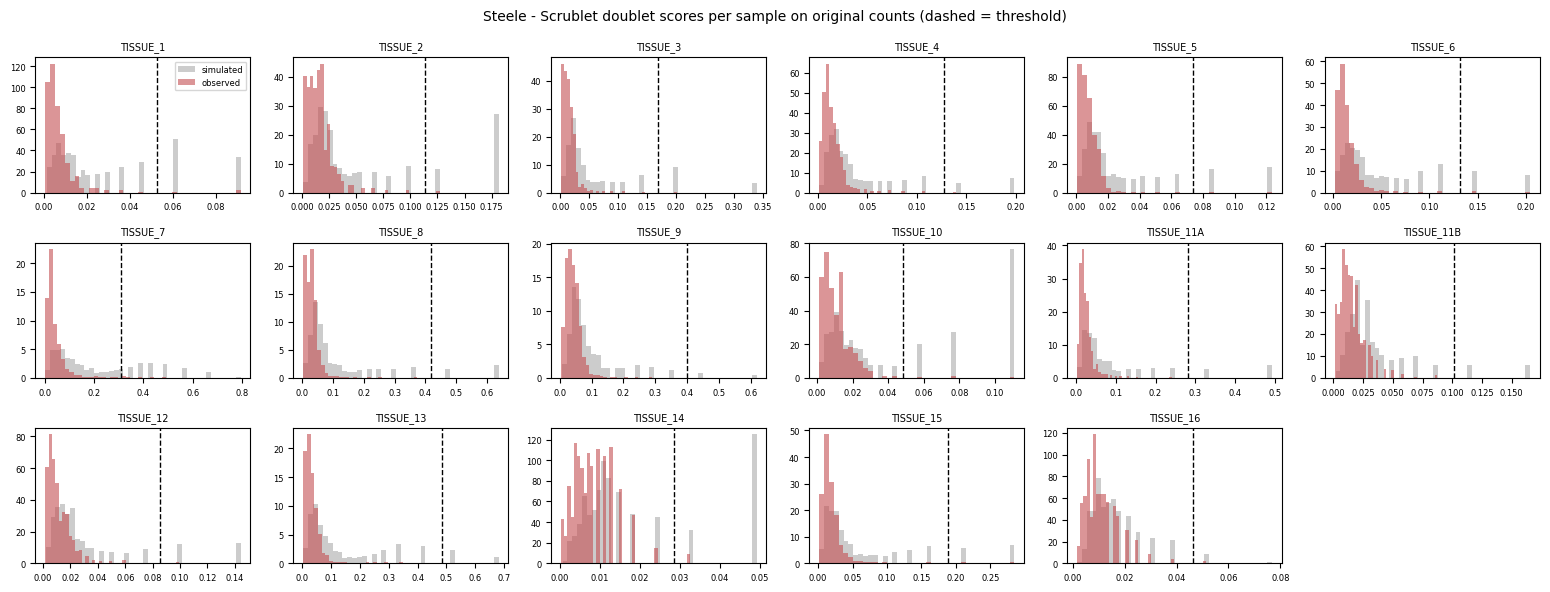


  Steele: expected 2.9% | observed 0.4% | bimodal in 17/17 samples
RAM in use: 1.9 GB


In [33]:
# ==========================================================================
# R1b · SCRUBLET PER SAMPLE ON ORIGINAL COUNTS   ·   Supplementary Fig. S2
# Expected rate = 0.8% per 1,000 cells recovered in that sample. Threshold = minimum
# between the two modes of the SIMULATED-doublet score histogram (Scrublet's own rule,
# implemented here so no scikit-image is needed); if that histogram is not bimodal the top
# expected-rate fraction of observed scores is flagged and the rule is recorded.
# Cached per cohort in REV_DIR/doublets_<cohort>.csv.
#
# WHY: one model per 10x lane because doublet rate scales with cells loaded per lane; expected rate
# from 10x guidance (0.8% per 1,000 cells); threshold at the minimum between the two modes of the
# simulated-doublet scores, Scrublet's recommended rule (fallback: top expected-rate fraction).
# ==========================================================================

if not RAW_SC_OK:
    print("R1b skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see R0)")
else:
    try:
        _scrub = sc.pp.scrublet
    except AttributeError:
        _scrub = sc.external.pp.scrublet


    def minimum_threshold(x, nbins=256, max_iter=10000):
        """Threshold at the minimum between exactly two histogram peaks, found by repeated
        3-point smoothing (the rule behind skimage.filters.threshold_minimum, which Scrublet
        uses). Returns None when the histogram never resolves into two peaks."""
        hist, edges = np.histogram(np.asarray(x, float), bins=nbins)
        h = hist.astype(float)
        centers = (edges[:-1] + edges[1:]) / 2
        for _ in range(max_iter):
            h = np.convolve(np.pad(h, 1, mode="edge"), np.ones(3) / 3, mode="valid")
            peaks = [i for i in range(1, len(h) - 1) if h[i - 1] < h[i] and h[i + 1] < h[i]]
            if len(peaks) == 2:
                a, b = peaks
                return float(centers[a + int(np.argmin(h[a:b + 1]))])
            if len(peaks) < 2:
                return None
        return None


    def scrublet_cohort(label, path, obs_all, reader):
        cache = rev_path("doublets_{}.csv".format(label.lower()))
        if not need_rev(cache):
            print("{}: using cached {}".format(label, os.path.basename(cache)))
            return pd.read_csv(cache, index_col=0), pd.read_csv(cache.replace(".csv", "_samples.csv"))
        # one Scrublet model per 10x lane: doublets form within a lane. The rebuilt Steele file
        # records the lane (TISSUE_11 = lanes 11A + 11B); otherwise each patient is one lane.
        _grp = "lane" if "lane" in obs_all.columns else "Patient"
        pats = obs_all[_grp].astype(str).values
        rows_out, samples, sims = [], [], {}
        print("\nSCRUBLET ON ORIGINAL COUNTS -- {}\n".format(label))
        print("  {:<12}{:>8}{:>10}{:>10}{:>11}  rule".format("sample", "cells", "expected", "observed", "threshold"))
        for p in pd.unique(pats):
            rows = np.flatnonzero(pats == p)
            if len(rows) < SCRUBLET_MIN_CELLS:
                print("  {:<12}{:>8,}  too few cells -- not scored".format(p, len(rows)))
                continue
            C, genes = reader(rows)
            rate = DOUBLET_RATE_PER_1K * len(rows) / 1000.0
            sub = anndata.AnnData(X=C.astype(np.float32), var=pd.DataFrame(index=pd.Index(genes)))
            sub.var_names_make_unique()
            _scrub(sub, expected_doublet_rate=rate, random_state=SEED, verbose=False, threshold=1.0)
            obs_s = sub.obs["doublet_score"].values
            sim_s = np.asarray(sub.uns["scrublet"]["doublet_scores_sim"])
            thr, rule = minimum_threshold(sim_s), "bimodal minimum"
            # a minimum that would call more than 3x the expected rate (+5 points) is a spurious
            # dip in the histogram, not the singlet/doublet boundary -> fall back, and say so
            if thr is not None and np.mean(obs_s > thr) > 3 * rate + 0.05:
                thr, rule = None, "minimum rejected (implausible rate); top expected fraction"
            if thr is None:
                thr = float(np.quantile(obs_s, 1 - rate))
                rule = rule if rule.startswith("minimum rejected") else "top expected fraction"
            called = obs_s > thr
            top10 = obs_s >= np.quantile(obs_s, 1 - TOP_SCORE_EXCLUDE)
            rows_out.append(pd.DataFrame({"Patient": p, "doublet_score": obs_s, "doublet_call": called,
                                          "top_score": top10}, index=obs_all.index[np.sort(rows)]))
            samples.append(dict(sample=p, cells=len(rows), expected_rate=rate,
                                observed_rate=float(called.mean()), threshold=thr, rule=rule))
            sims[p] = (obs_s, sim_s, thr)
            print("  {:<12}{:>8,}{:>9.1%}{:>10.1%}{:>11.3f}  {}".format(
                p, len(rows), rate, called.mean(), thr, rule))
            free(sub, C)
        tab = pd.concat(rows_out)
        samp = pd.DataFrame(samples)
        tab.to_csv(cache)
        samp.to_csv(cache.replace(".csv", "_samples.csv"), index=False)
        # ---- Supplementary Fig. S2: per-sample score distributions -----------------
        if FIGURES and sims:
            n = len(sims); ncol = 6; nrow = int(np.ceil(n / ncol))
            fig, axes = plt.subplots(nrow, ncol, figsize=(2.6 * ncol, 2.0 * nrow), squeeze=False)
            for ax, (p, (o, s, t)) in zip(axes.ravel(), sims.items()):
                ax.hist(s, bins=40, color="0.8", density=True, label="simulated")
                ax.hist(o, bins=40, color="#C44E52", alpha=0.6, density=True, label="observed")
                ax.axvline(t, color="k", lw=1, ls="--")
                ax.set_title(p, fontsize=7); ax.tick_params(labelsize=6)
            for ax in axes.ravel()[n:]:
                ax.axis("off")
            axes[0, 0].legend(fontsize=6)
            fig.suptitle("{} - Scrublet doublet scores per sample on original counts "
                         "(dashed = threshold)".format(label), fontsize=10)
            plt.tight_layout()
            _show("revR1_{}_doublet_scores".format(label.lower()))
        return tab, samp


    DOUBLETS, DOUBLET_SAMPLES = {}, {}
    for _lab, _path, _obs in [("Peng", PENG_PROC, peng_obs_all), ("Steele", STEELE_QC, steele_obs_all)]:
        _reader = COUNT_SRC[_lab][0]
        if _reader is None:
            print("\n{}: no exact original counts -> Scrublet NOT re-run (see R1a).".format(_lab))
            continue
        DOUBLETS[_lab], DOUBLET_SAMPLES[_lab] = scrublet_cohort(_lab, _path, _obs, _reader)
        _s = DOUBLET_SAMPLES[_lab]
        print("\n  {}: expected {:.1%} | observed {:.1%} | bimodal in {}/{} samples".format(
            _lab, np.average(_s["expected_rate"], weights=_s["cells"]),
            np.average(_s["observed_rate"], weights=_s["cells"]),
            int((_s["rule"] == "bimodal minimum").sum()), len(_s)))
    REV["doublet_samples"] = {k: v.to_dict(orient="records") for k, v in DOUBLET_SAMPLES.items()}
    print(mem())

In [34]:
# ==========================================================================
# R1c · HETEROTYPIC DOUBLETS + SENSITIVITY ANALYSIS
# Flags malignant-compartment cells co-expressing an epithelial marker with >= 2 stromal
# markers (epithelial-stromal) or with PTPRC (epithelial-immune). Then recomputes the
# partial Spearman for every signature (a) without flagged cells (heterotypic OR Scrublet
# call) and (b) without the top 10% doublet scores per sample.
#
# WHY: marker co-expression catches exactly the doublets the reviewers named and needs no counts, so
# it covers Peng too. Every signature is re-tested without flagged cells (and, for Steele, without
# the top 10% of doublet scores) so no conclusion depends on where a threshold sits.
# ==========================================================================

if not RAW_SC_OK:
    print("R1c skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see R0)")
else:
    def _raw_cols(ad, genes):
        names = pd.Index(ad.raw.var_names)
        out = {}
        for g in genes:
            if g in names:
                v = ad.raw.X[:, names.get_loc(g)]
                out[g] = np.asarray(v.todense()).ravel() if sparse.issparse(v) else np.asarray(v).ravel()
            else:
                out[g] = np.zeros(ad.n_obs)
        return out


    def hetero_flags(ad):
        c = _raw_cols(ad, HET_EPI + HET_STROMA + HET_IMMUNE)
        epi = np.max([c[g] for g in HET_EPI], axis=0) > HET_THR
        stro = (np.vstack([c[g] for g in HET_STROMA]) > HET_THR).sum(axis=0) >= 2
        imm = np.max([c[g] for g in HET_IMMUNE], axis=0) > HET_THR
        return epi & stro, epi & imm


    SIG_COLS = [t + "_sig" for t in TARGETS] + ["CE_sig"]
    REV["doublet_sensitivity"] = {}
    for _lab, _ad in [("Peng", mal), ("Steele", steele)]:
        es, ei = hetero_flags(_ad)
        _ad.obs["het_epi_stroma"], _ad.obs["het_epi_immune"] = es, ei
        flag = es | ei
        if _lab in DOUBLETS:
            d = DOUBLETS[_lab].reindex(_ad.obs_names)
            _ad.obs["doublet_score_raw"] = d["doublet_score"].values
            _ad.obs["doublet_call"] = d["doublet_call"].fillna(False).astype(bool).values
            _ad.obs["top_score"] = d["top_score"].fillna(False).astype(bool).values
            flag = flag | _ad.obs["doublet_call"].values
        _ad.obs["doublet_flag"] = flag
        print("\n{} malignant compartment ({:,} cells)".format(_lab, _ad.n_obs))
        print("  epithelial-stromal co-expression : {:,} ({:.2%})".format(int(es.sum()), es.mean()))
        print("  epithelial-immune co-expression  : {:,} ({:.2%})".format(int(ei.sum()), ei.mean()))
        if _lab in DOUBLETS:
            print("  Scrublet call (original counts)  : {:,} ({:.2%})".format(
                int(_ad.obs["doublet_call"].sum()), _ad.obs["doublet_call"].mean()))
        print("  any flag                         : {:,} ({:.2%})\n".format(int(flag.sum()), flag.mean()))
        rows = []
        for col in SIG_COLS:
            base = ps_vs(_ad.obs, col)
            kept = ps_vs(_ad.obs[~_ad.obs["doublet_flag"].values], col)
            rows += [rev_row("{} | all cells".format(col), base),
                     rev_row("{} | flagged cells removed".format(col), kept)]
            REV["doublet_sensitivity"]["{}|{}|flag_removed".format(_lab, col)] = mean_rho(kept)
            if "top_score" in _ad.obs:
                top = ps_vs(_ad.obs[~_ad.obs["top_score"].values], col)
                rows.append(rev_row("{} | top-10% scores removed".format(col), top))
                REV["doublet_sensitivity"]["{}|{}|top10_removed".format(_lab, col)] = mean_rho(top)
        show_rev(rows)


Peng malignant compartment (11,280 cells)
  epithelial-stromal co-expression : 1,269 (11.25%)
  epithelial-immune co-expression  : 24 (0.21%)
  any flag                         : 1,289 (11.43%)

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  VPS4A_sig | all cells                     24   15/24   -0.0365   [-0.0933, +0.0229]    0.1515                 
  VPS4A_sig | flagged cells removed         23   13/23   -0.0303   [-0.0873, +0.0320]    0.2595                 
  PRMT5_sig | all cells                     24    9/24   +0.0325   [-0.0145, +0.0772]    0.0691                 
  PRMT5_sig | flagged cells removed         23    8/23   +0.0345   [-0.0167, +0.0826]    0.0698                 
  MAT2A_sig | all cells                     24    2/24   +0.3094   [+0.2397, +0.3762]    0.0000                 
  MAT2A_sig | flagged cells removed         23    2/23   +0.3089   [+0.2407, +0.3768]    0.0000                 
  CE_sig | al

## R2 · Per-patient copy number, high-confidence malignant cells  ·  Supplementary Fig. S1

*Reviewer must-fix 9 (and the CAF/acinar point of 13). Methods → Transcriptional Programs and
Copy-Number Inference; Results → Cell Populations.* Section 6 inferred copy number once per
cohort on a 4,000-cell subsample against pooled immune + stromal cells. Here it is inferred
**per patient**, on **every** QC-passed malignant-labelled cell, against that patient's **own**
immune and stromal cells **plus normal epithelial cells** (the patient's own when ≥ 30 exist,
otherwise a pooled sample from the cohort's normal epithelium):

- **Peng**: normal epithelium = non-malignant cells whose TISCH lineage label is ductal,
  acinar, endocrine or epithelial (the column and labels used are printed).
- **Steele**: no normal ductal annotation exists, so normal epithelium = cells labelled acinar
  by the §6 marker sets. This is weaker and is said so in the manuscript.

Per-cell CNV score = mean |inferred copy number| over all windows (section 6 used
infercnvpy's cluster-level `cnv_score`; a per-cell value is needed to call individual cells).
A cell is **CNV-positive** above its own patient's reference 95th percentile. A
**high-confidence malignant cell** is CNV-positive, not doublet-flagged (R1), and not from a
control pancreas. The same runs also produce the focal 9p21/18q values used in R3, a
narrower-window run (`FOCAL_WINDOW` genes, no noise thresholding) so a focal deletion is not
averaged away.

Outputs: per-patient copy-number heatmap (patients × genomic windows) for each cohort, one
cell-level chromosome heatmap, the CNV-positive fraction per patient, *MAT2A* signature scores
in CNV-positive vs CNV-negative epithelial cells, and every signature re-tested on
high-confidence cells in **both** cohorts.

**Why these choices**

| choice | why |
|---|---|
| A reference per patient | Baseline expression differs between patients; a pooled reference can make patient-specific expression look like copy-number change. |
| Normal epithelium in the reference | Epithelial expression programs that immune and stromal cells lack could otherwise mimic copy-number change in malignant epithelium (the reviewers' request). The patient's own normal epithelial cells are used when at least 30 exist, otherwise cells from other patients. |
| Caps of 1,000 immune, 1,000 stromal and 500 normal epithelial cells | Bounded memory and runtime, and no single reference category dominates. |
| At least 20 malignant and 100 reference cells per patient | Fewer reference cells would make the 95th-percentile threshold unstable. |
| Per-cell CNV score = mean absolute inferred copy number | A per-cell value is needed to call individual cells; §6 used a cluster-level score. |
| 30-cell floor for the high-confidence tests | Removing CNV-negative and flagged cells shrinks every patient; 30 keeps most patients while the per-patient SE stays about 0.19. |

In [35]:
# ==========================================================================
# R2a · CELL ROLES FOR THE PER-PATIENT REFERENCE
# Peng: TISCH labels (malignant from the QC-passed object; immune / stromal from MAL_COL;
# normal epithelium from the lineage column). Steele: the section 6 marker vocabulary,
# computed once on the full object and cached (needs ~6 GB once; afterwards read from CSV).
#
# WHY: the per-patient reference needs explicit roles. Peng roles come from the TISCH lineage labels
# (made independently of this notebook); Steele has none, so roles come from marker scoring, with
# acinar-marker cells standing in for normal epithelium (a weaker reference, stated in the methods).
# ==========================================================================

if not RAW_SC_OK:
    print("R2a skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see R0)")
else:
    def peng_roles():
        obs = peng_obs_all
        roles = np.full(len(obs), "other", dtype=object)
        roles[(obs[MAL_COL] == "Immune cells").values] = "immune"
        roles[(obs[MAL_COL] == "Stromal cells").values] = "stromal"
        lin_cols = [c for c in obs.columns if "lineage" in str(c).lower() and c != MAL_COL]
        epi = np.zeros(len(obs), bool)
        if lin_cols:
            lc = lin_cols[0]
            lab = obs[lc].astype(str).str.lower()
            epi = lab.apply(lambda s: any(k in s for k in NORMAL_EPI_KEYS)).values & \
                  (obs[MAL_COL] != "Malignant cells").values
            print("Peng lineage column used: '{}'".format(lc))
            print("non-malignant lineage labels counted as normal epithelium:")
            print(obs.loc[epi, lc].astype(str).value_counts().to_string())
        else:
            print("Peng: no lineage column -- normal-epithelial reference unavailable")
        roles[epi] = "normal_epithelial"
        roles[obs.index.isin(mal.obs_names)] = "malignant"       # QC-passed malignant cells
        return roles


    def steele_roles():
        cache = rev_path("steele_cell_roles.csv")
        if not need_rev(cache):
            r = pd.read_csv(cache, index_col=0)["role"].reindex(steele_obs_all.index)
            return r.fillna("other").values.astype(object)
        sst = sc.read_h5ad(STEELE_QC)
        if sst.raw is not None and sst.raw.n_vars >= sst.n_vars:
            sst = sst.raw.to_adata()
        sets = {"immune": COMPARTMENT_MARKERS["Tcell"] + COMPARTMENT_MARKERS["myeloid"]
                          + COMPARTMENT_MARKERS["Bcell"],
                "stromal": COMPARTMENT_MARKERS["fibroblast"] + COMPARTMENT_MARKERS["endothelial"],
                "normal_epithelial": COMPARTMENT_MARKERS["acinar"]}
        sco = {}
        for name, genes in sets.items():
            sc.tl.score_genes(sst, [g for g in genes if g in sst.var_names], score_name="_s", use_raw=False)
            sco[name] = sst.obs["_s"].values.astype(float)
        lab = pd.DataFrame(sco, index=sst.obs_names).idxmax(axis=1)
        lab[sst.obs_names.isin(steele.obs_names)] = "malignant"
        lab[(~sst.obs_names.isin(steele.obs_names)) & lab.eq("malignant")] = "other"
        pd.DataFrame({"role": lab}).to_csv(cache)
        free(sst)
        return lab.reindex(steele_obs_all.index).fillna("other").values.astype(object)


    ROLES = {"Peng": peng_roles(), "Steele": steele_roles()}
    for _lab, _r in ROLES.items():
        print("\n{} roles:".format(_lab))
        print(pd.Series(_r).value_counts().to_string())
    print(mem())

Peng lineage column used: 'Celltype (major-lineage)'
non-malignant lineage labels counted as normal epithelium:
Celltype (major-lineage)
Ductal       10205
Acinar        2018
Endocrine      620

Peng roles:
stromal              16280
normal_epithelial    12843
immune               11654
malignant            11280
other                 5386

Steele roles:
immune               22487
malignant             9353
stromal               5870
normal_epithelial     3709
RAM in use: 1.8 GB



PER-PATIENT inferCNV -- Peng

  Healthy1     6 malignant cells
  Healthy11    3 malignant cells
  Healthy3     2 malignant cells
  Healthy7     1 malignant cells
  Healthy9     4 malignant cells


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  T1           ok (430 malignant, 618 reference, epithelium own)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  T13          ok (247 malignant, 1451 reference, epithelium own)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

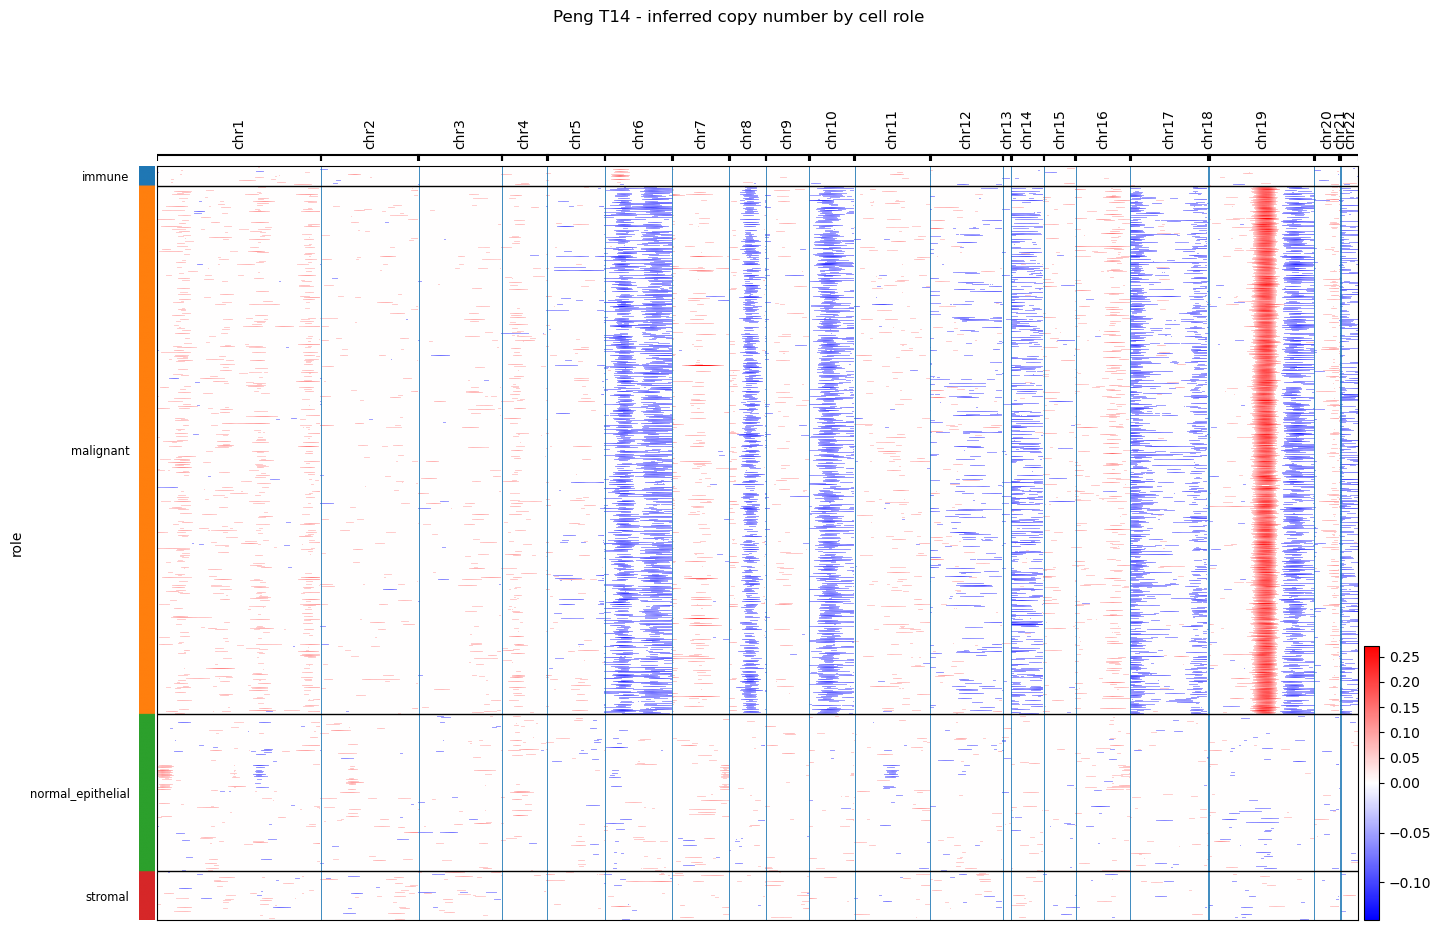

  T14          ok (1679 malignant, 717 reference, epithelium pooled)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  T15          ok (119 malignant, 1442 reference, epithelium own)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (56 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

  TISSUE_11    ok (1546 malignant, 2011 reference, epithelium own)
  TISSUE_12    15 malignant cells


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

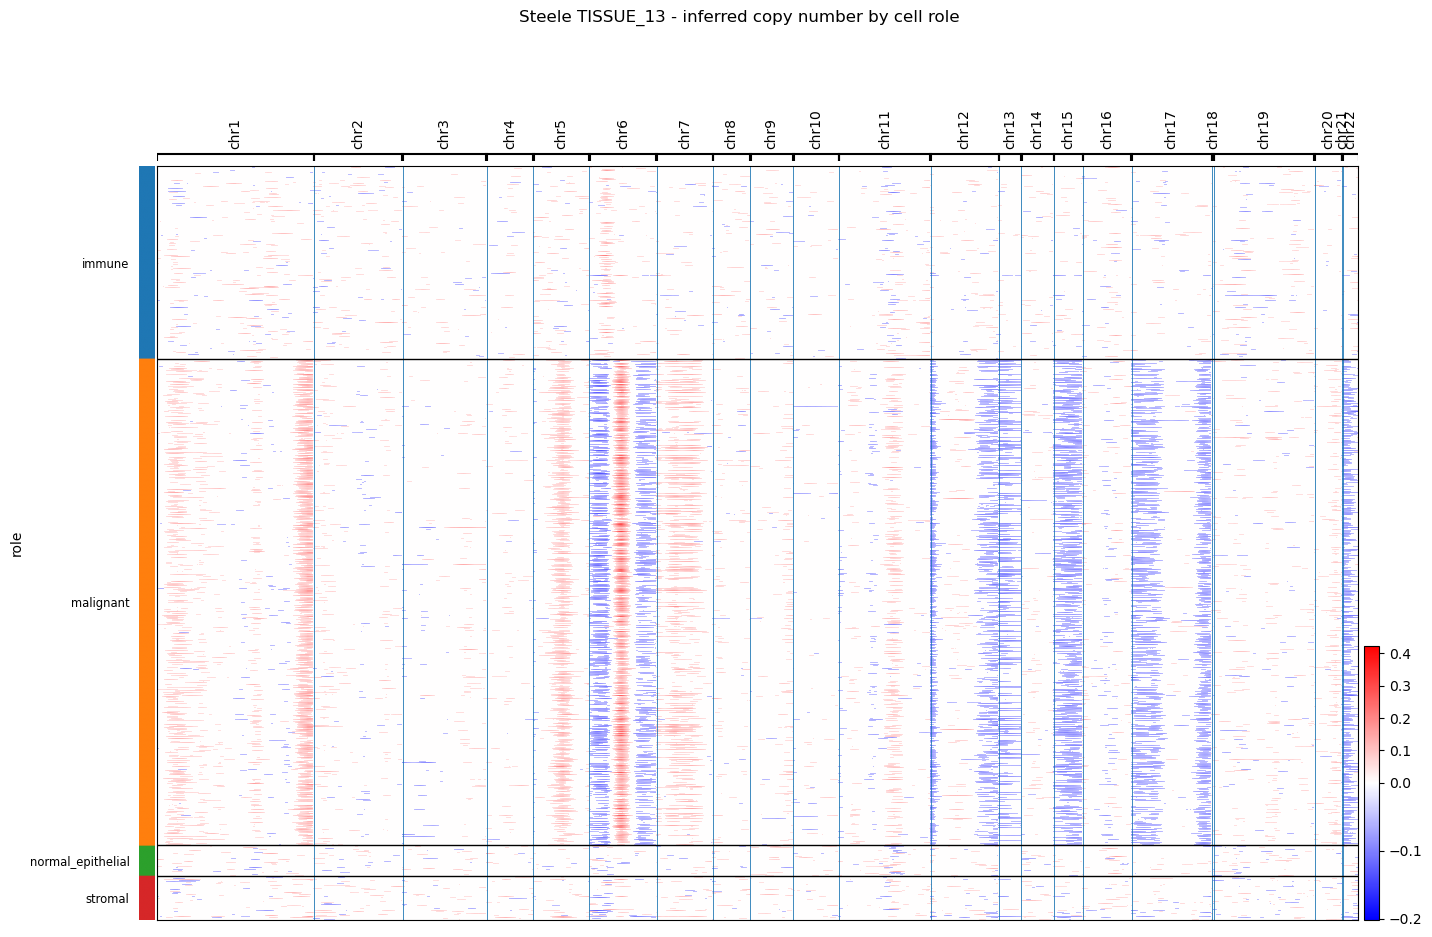

  TISSUE_13    ok (2529 malignant, 1386 reference, epithelium own)
  TISSUE_14    16 malignant cells


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  TISSUE_15    ok (408 malignant, 1478 reference, epithelium own)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (21 outputs left out)

  TISSUE_8     ok (817 malignant, 2065 reference, epithelium own)


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  TISSUE_9     ok (235 malignant, 1596 reference, epithelium own)
RAM in use: 1.8 GB


In [36]:
# ==========================================================================
# R2b · PER-PATIENT inferCNV (two windows) -- cached per cohort
# Window CNV_WINDOW (as section 6) -> per-cell CNV score and the CNV-positive call.
# Window FOCAL_WINDOW, dynamic_threshold=None -> 9p21 / 18q values for R3. Each run reads
# only that patient's rows. Per-cell results: REV_DIR/cnv_percell_<cohort>.csv; mean
# malignant profiles: REV_DIR/cnv_profiles_<cohort>.npz.
#
# WHY per patient: baseline expression differs between patients, and a pooled reference can make it
# look like copy-number change. Normal epithelium joins immune + stromal cells so epithelial
# expression programs cannot mimic CNV. Two windows: 250 genes for the arm-level CNV-positive call,
# 51 genes so focal 9p21/18q deletions are not averaged away (R3).
# ==========================================================================

if not RAW_SC_OK:
    print("R2b skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see R0)")
else:
    import infercnvpy as cnv


    def _infercnv(ad, key, window, dyn=1.5):
        kw = dict(reference_key="role", reference_cat=ad.uns["_ref_cats"], window_size=window,
                  step=CNV_STEP, key_added=key, dynamic_threshold=dyn)
        try:
            cnv.tl.infercnv(ad, n_jobs=1, **kw)
        except TypeError:                     # older infercnvpy without n_jobs
            cnv.tl.infercnv(ad, **kw)


    def region_values(ad, key, genes_in_region, window):
        """Per-cell mean inferred copy number over the windows that cover a set of genes.
        Reproduces infercnvpy's bookkeeping: within a chromosome genes are sorted by start and
        window k covers sorted genes [k*step, k*step + window). Checked against infercnvpy's own
        calculate_gene_values output on synthetic data before release."""
        X = ad.obsm["X_" + key]
        chr_pos = ad.uns[key]["chr_pos"]
        var = ad.var
        cols = set()
        present = [g for g in genes_in_region if g in var.index]
        for chrom in sorted(set(var.loc[present, "chromosome"])):
            if chrom not in chr_pos:
                continue
            genes = var.loc[var["chromosome"] == chrom].sort_values("start").index.values
            n = len(genes)
            pos = {g: i for i, g in enumerate(genes)}
            n_win = 1 if n <= window else len(range(0, n - window + 1, CNV_STEP))
            for g in present:
                if g not in pos:
                    continue
                i = pos[g]
                if n <= window:
                    ks = [0]
                else:
                    ks = range(max(0, int(np.ceil((i - window + 1) / CNV_STEP))),
                               min(n_win - 1, i // CNV_STEP) + 1)
                cols.update(chr_pos[chrom] + k for k in ks)
        cols = sorted(cols)
        if not cols:
            return np.full(ad.n_obs, np.nan)
        sub = X[:, cols]
        sub = sub.toarray() if sparse.issparse(sub) else np.asarray(sub)
        return sub.mean(axis=1)


    def cnv_patient(label, path, obs_all, roles, pat, rng, sig_genes, make_heatmap=False):
        pats = obs_all["Patient"].astype(str).values
        in_p = pats == pat
        mal_r = np.flatnonzero(in_p & (roles == "malignant"))
        imm = np.flatnonzero(in_p & (roles == "immune"))
        stro = np.flatnonzero(in_p & (roles == "stromal"))
        own_epi = np.flatnonzero(in_p & (roles == "normal_epithelial"))
        if len(mal_r) < MIN_MAL_CNV:
            return None, "{} malignant cells".format(len(mal_r))
        if len(imm) + len(stro) < REF_MIN:
            return None, "only {} own reference cells".format(len(imm) + len(stro))

        def take(idx, n):
            return np.sort(rng.choice(idx, size=min(n, len(idx)), replace=False)) if len(idx) else idx
        imm, stro = take(imm, REF_MAX_PER_CAT), take(stro, REF_MAX_PER_CAT)
        if len(own_epi) >= 30:
            epi, epi_src = take(own_epi, NORMAL_EPI_MAX), "own"
        else:
            epi, epi_src = take(np.flatnonzero((roles == "normal_epithelial") & ~in_p), NORMAL_EPI_MAX), "pooled"
        role_by_row = pd.Series(
            ["malignant"] * len(mal_r) + ["immune"] * len(imm) + ["stromal"] * len(stro)
            + ["normal_epithelial"] * len(epi),
            index=np.concatenate([mal_r, imm, stro, epi]))
        role_by_row = role_by_row[~role_by_row.index.duplicated()]
        X, genes, srt = h5_rows_lognorm(path, role_by_row.index.values)
        run = anndata.AnnData(X=X.astype(np.float32),
                              obs=pd.DataFrame({"role": role_by_row.reindex(srt).values},
                                               index=obs_all.index[srt].astype(str)),
                              var=pd.DataFrame(index=pd.Index(genes)))
        run.var_names_make_unique()
        # MAT2A signature score inside this run (comparable across this patient's cells only)
        sc.tl.score_genes(run, [g for g in sig_genes if g in run.var_names],
                          score_name="MAT2A_run", use_raw=False)
        # passenger / tumour-suppressor expression on the linear scale (CP10k)
        cp = {}
        for g in ["MTAP", "VPS4B", "CDKN2A", "SMAD4"]:
            if g in run.var_names:
                v = run[:, g].X
                v = v.toarray().ravel() if sparse.issparse(v) else np.asarray(v).ravel()
                cp[g] = np.expm1(v.astype(float))
            else:
                cp[g] = np.full(run.n_obs, np.nan)
        # genomic positions; autosomes only (infercnvpy drops chrX/chrY by default)
        run.var["chromosome"] = "chr" + run.var_names.map(GP["chromosome"]).astype(str)
        run.var["start"] = run.var_names.map(GP["start"])
        run.var["end"] = run.var_names.map(GP["end"])
        keep = run.var["start"].notna() & run.var["chromosome"].isin(["chr" + str(i) for i in range(1, 23)])
        run = run[:, keep.values].copy()
        run.var["start"] = run.var["start"].astype(int)
        run.var["end"] = run.var["end"].astype(int)
        run.uns["_ref_cats"] = [c for c in ["immune", "stromal", "normal_epithelial"]
                                if (run.obs["role"] == c).sum() > 0]
        _infercnv(run, "cnv", CNV_WINDOW)
        Xc = run.obsm["X_cnv"]
        score = np.asarray(abs(Xc).mean(axis=1)).ravel()
        is_ref = run.obs["role"].isin(run.uns["_ref_cats"]).values
        ref95 = float(np.quantile(score[is_ref], CNV_POS_Q))
        _infercnv(run, "cnvf", FOCAL_WINDOW, dyn=None)
        out = pd.DataFrame({"Patient": pat, "role": run.obs["role"].values, "cnv_score": score,
                            "cnv_pos": score > ref95, "ref95": ref95, "epi_ref": epi_src,
                            "MAT2A_run": run.obs["MAT2A_run"].values}, index=run.obs_names)
        for loc, lg in LOCUS_GENES.items():
            out["focal_" + loc] = region_values(run, "cnvf", lg, FOCAL_WINDOW)
        for g, v in cp.items():
            out[g + "_cp10k"] = v
        is_mal = run.obs["role"].values == "malignant"
        prof = np.asarray(Xc[is_mal].mean(axis=0)).ravel()
        if make_heatmap and FIGURES:
            try:
                cnv.pl.chromosome_heatmap(run, groupby="role", show=False)
                plt.suptitle("{} {} - inferred copy number by cell role".format(label, pat), y=1.02)
                _show("revR2_{}_{}_chromosome_heatmap".format(label.lower(), pat))
            except Exception as err:
                print("  [chromosome heatmap skipped: {}]".format(str(err)[:60]))
        chr_pos = dict(run.uns["cnv"]["chr_pos"])
        free(run, X, Xc)
        return (out, prof, chr_pos), "ok ({} malignant, {} reference, epithelium {})".format(
            int(is_mal.sum()), int(is_ref.sum()), epi_src)


    def cnv_cohort(label, path, obs_all, roles, sig_genes):
        cache = rev_path("cnv_percell_{}.csv".format(label.lower()))
        pcache = rev_path("cnv_profiles_{}.npz".format(label.lower()))
        if not need_rev(cache) and os.path.exists(pcache):
            print("{}: using cached {}".format(label, os.path.basename(cache)))
            z = np.load(pcache, allow_pickle=True)
            return pd.read_csv(cache, index_col=0), dict(z["profiles"].item()), dict(z["chr_pos"].item())
        pats_all = obs_all["Patient"].astype(str).values
        order = sorted(set(pats_all[roles == "malignant"]))
        n_mal = pd.Series(pats_all[roles == "malignant"]).value_counts()
        example = n_mal.index[0]
        tabs, profiles, chr_pos = [], {}, None
        print("\nPER-PATIENT inferCNV -- {}\n".format(label))
        for i, pat in enumerate(order):
            rng_p = np.random.default_rng([SEED, i])          # own stream per patient
            res_p, msg = cnv_patient(label, path, obs_all, roles, pat, rng_p, sig_genes,
                                     make_heatmap=(pat == example))
            print("  {:<12} {}".format(pat, msg))
            if res_p is None:
                continue
            tab, prof, cp = res_p
            tabs.append(tab); profiles[pat] = prof; chr_pos = cp
        out = pd.concat(tabs)
        out.to_csv(cache)
        np.savez(pcache, profiles=np.array(profiles, dtype=object), chr_pos=np.array(chr_pos, dtype=object))
        print(mem())
        return out, profiles, chr_pos


    CNVT, CNVPROF = {}, {}
    _mat_sig = signatures["MAT2A"]
    CNVT["Peng"], CNVPROF["Peng"], _cp_peng = cnv_cohort("Peng", PENG_PROC, peng_obs_all, ROLES["Peng"], _mat_sig)
    CNVT["Steele"], CNVPROF["Steele"], _cp_steele = cnv_cohort("Steele", STEELE_QC, steele_obs_all, ROLES["Steele"], _mat_sig)
    CHR_POS = {"Peng": _cp_peng, "Steele": _cp_steele}


Peng: CNV-positive malignant-labelled cells 8,721/11,264 (77.4%) across 24 patients
  per patient: T12 17%, T10 38%, T4 41%, T20 45%, T18 55%, T1 55%, T24 56%, T13 56%, T23 59%, T2 63%, T21 63%, T16 68%, T11 68%, T19 72%, T5 75%, T17 82%, T22 84%, T3 87%, T8 88%, T6 93%, T9 94%, T15 94%, T7 96%, T14 100%


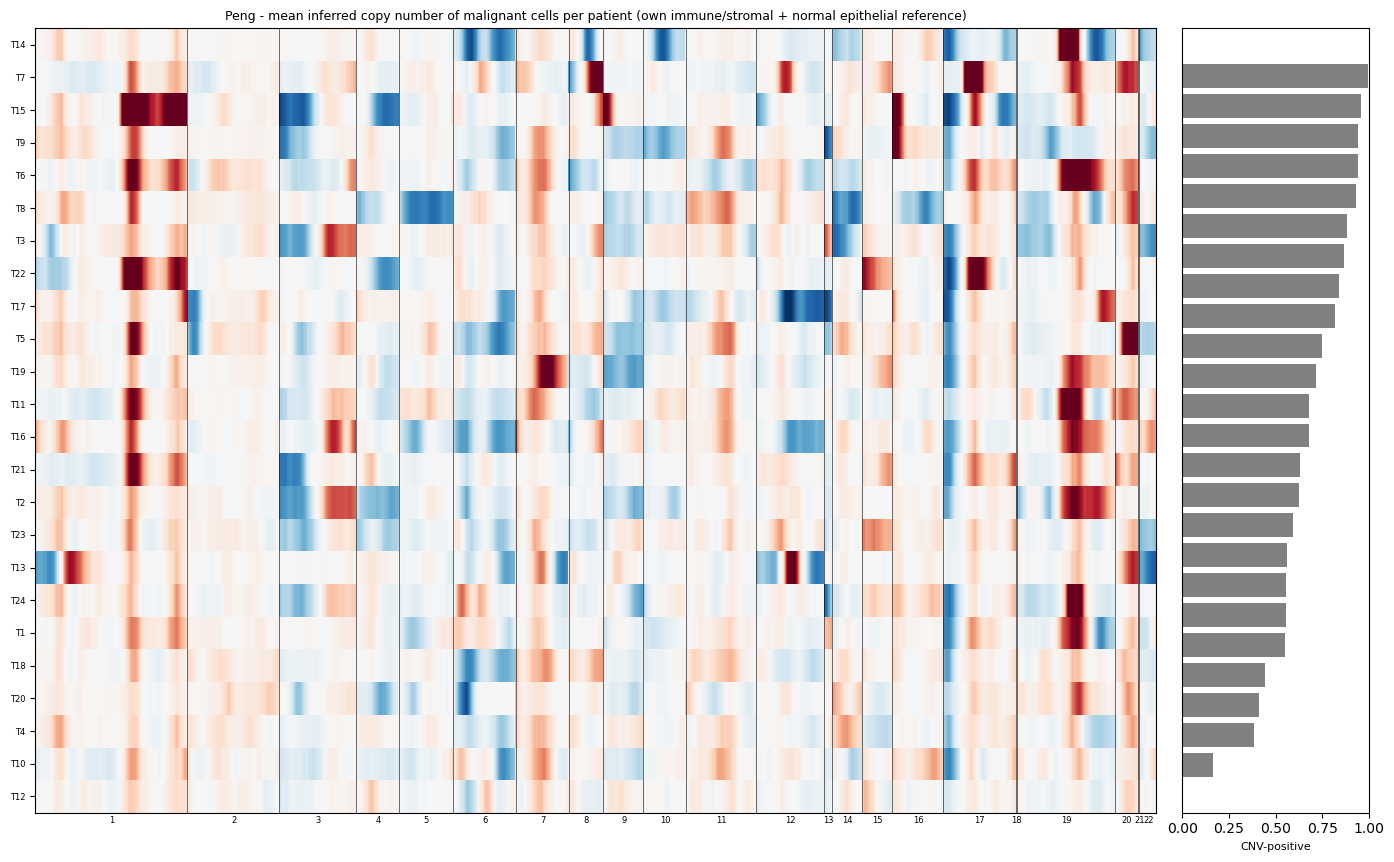


Steele: CNV-positive malignant-labelled cells 6,305/9,322 (67.6%) across 14 patients
  per patient: TISSUE_16 2%, TISSUE_4 21%, TISSUE_11 32%, TISSUE_5 47%, TISSUE_10 74%, TISSUE_15 77%, TISSUE_9 80%, TISSUE_7 82%, TISSUE_8 86%, TISSUE_13 86%, TISSUE_3 87%, TISSUE_2 89%, TISSUE_6 95%, TISSUE_1 95%


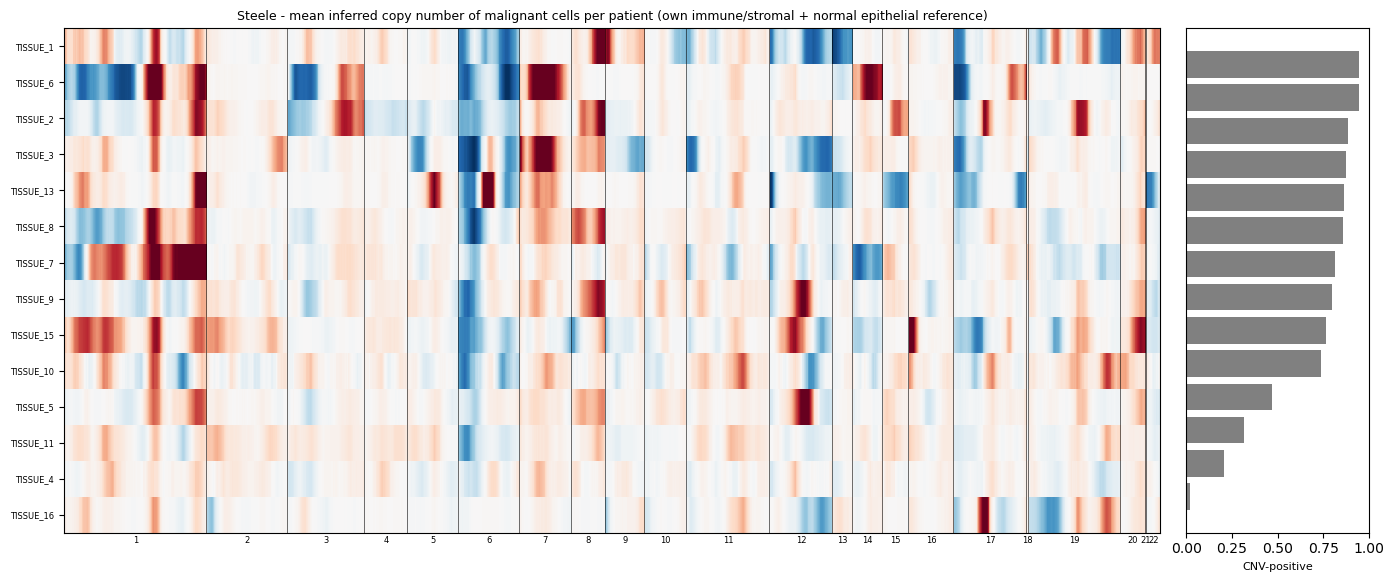


Peng: MAT2A score, CNV+ minus CNV- malignant (patient medians): mean +0.0163, 19/21 patients higher in CNV+, Wilcoxon p = 0.0009

Steele: MAT2A score, CNV+ minus CNV- malignant (patient medians): mean +0.0316, 12/13 patients higher in CNV+, Wilcoxon p = 0.0024


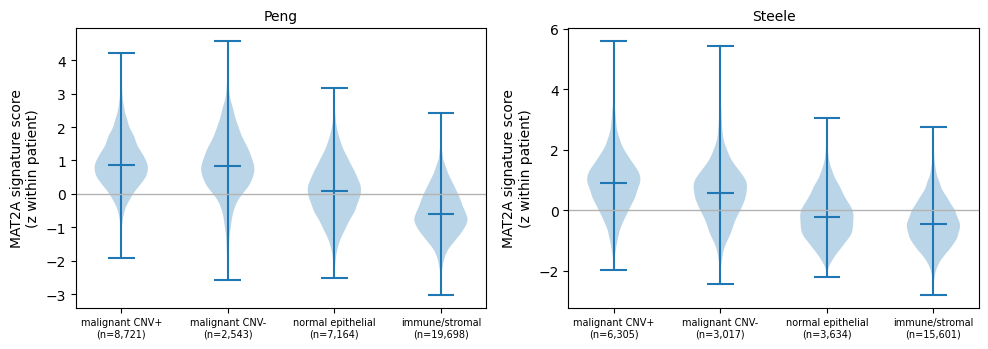

In [37]:
# ==========================================================================
# R2c · CNV FIGURES   ·   Supplementary Fig. S1
# (a) per-patient mean malignant copy-number profile, patients x genomic windows
# (b) fraction CNV-positive per patient
# (c) MAT2A signature score (within-patient z) in CNV-positive malignant, CNV-negative
#     malignant, and normal epithelial reference cells
# ==========================================================================

if not RAW_SC_OK:
    print("R2c skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see R0)")
else:
    for _lab in ["Peng", "Steele"]:
        t = CNVT[_lab]
        m = t[t["role"] == "malignant"]
        frac = m.groupby("Patient")["cnv_pos"].mean().sort_values()
        print("\n{}: CNV-positive malignant-labelled cells {:,}/{:,} ({:.1%}) across {} patients".format(
            _lab, int(m["cnv_pos"].sum()), len(m), m["cnv_pos"].mean(), m["Patient"].nunique()))
        print("  per patient: " + ", ".join("{} {:.0%}".format(p, v) for p, v in frac.items()))
        REV.setdefault("cnv_pos_frac", {})[_lab] = {"overall": float(m["cnv_pos"].mean()),
                                                    "per_patient": frac.round(3).to_dict()}
        if not FIGURES:
            continue
        prof = CNVPROF[_lab]
        pats = list(frac.index[::-1])
        M = np.vstack([prof[p] for p in pats if p in prof])
        vmax = np.quantile(np.abs(M), 0.99)
        fig, axes = plt.subplots(1, 2, figsize=(14, 0.28 * len(pats) + 2.0),
                                 gridspec_kw={"width_ratios": [6, 1]})
        ax = axes[0]
        ax.imshow(M, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax, interpolation="nearest")
        cp = CHR_POS[_lab]
        starts = sorted(cp.items(), key=lambda kv: kv[1])
        for k, (chrom, s0) in enumerate(starts):
            ax.axvline(s0 - 0.5, color="k", lw=0.4)
            s1 = starts[k + 1][1] if k + 1 < len(starts) else M.shape[1]
            ax.text((s0 + s1) / 2, M.shape[0] - 0.4, chrom.replace("chr", ""), ha="center", va="top", fontsize=6)
        ax.set_yticks(range(len(pats))); ax.set_yticklabels(pats, fontsize=6)
        ax.set_xticks([])
        ax.set_title("{} - mean inferred copy number of malignant cells per patient "
                     "(own immune/stromal + normal epithelial reference)".format(_lab), fontsize=9)
        ax2 = axes[1]
        ax2.barh(range(len(pats)), [frac[p] for p in pats], color="0.5")
        ax2.set_yticks([]); ax2.set_xlim(0, 1); ax2.invert_yaxis()
        ax2.set_xlabel("CNV-positive", fontsize=8)
        plt.tight_layout()
        _show("revR2_{}_patient_cnv_heatmap".format(_lab.lower()))

    # (c) MAT2A score by CNV status, z-scored within each patient's run
    if FIGURES:
        fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    for j, _lab in enumerate(["Peng", "Steele"]):
        t = CNVT[_lab].copy()
        t["z"] = t.groupby("Patient")["MAT2A_run"].transform(lambda v: (v - v.mean()) / v.std())
        t["group"] = np.where(t["role"] == "normal_epithelial", "normal epithelial",
                      np.where(t["role"] != "malignant", "immune/stromal",
                      np.where(t["cnv_pos"], "malignant CNV+", "malignant CNV-")))
        # within-patient paired comparison of CNV+ vs CNV- malignant medians
        pp = t[t["role"] == "malignant"].groupby(["Patient", "cnv_pos"])["MAT2A_run"].median().unstack()
        pp = pp.dropna()
        cnt = t[t["role"] == "malignant"].groupby(["Patient", "cnv_pos"]).size().unstack().reindex(pp.index)
        pp = pp[(cnt[True] >= 10) & (cnt[False] >= 10)]
        if len(pp) >= 5:
            d = pp[True] - pp[False]
            print("\n{}: MAT2A score, CNV+ minus CNV- malignant (patient medians): mean {:+.4f}, "
                  "{}/{} patients higher in CNV+, Wilcoxon p = {:.4f}".format(
                      _lab, d.mean(), int((d > 0).sum()), len(d), wilcoxon(d)[1]))
            REV.setdefault("mat2a_cnv_pos_minus_neg", {})[_lab] = dict(
                mean=float(d.mean()), n=len(d), n_pos=int((d > 0).sum()), p=float(wilcoxon(d)[1]))
        else:
            print("\n{}: too few patients with >= 10 CNV+ and CNV- cells for the paired test".format(_lab))
        if FIGURES:
            ax = axes[j]
            groups = ["malignant CNV+", "malignant CNV-", "normal epithelial", "immune/stromal"]
            data = [t.loc[t["group"] == gname, "z"].dropna().values for gname in groups]
            ok = [k for k, dd in enumerate(data) if len(dd) > 5]
            ax.violinplot([data[k] for k in ok], positions=range(len(ok)), showmedians=True)
            ax.set_xticks(range(len(ok)))
            ax.set_xticklabels(["{}\n(n={:,})".format(groups[k], len(data[k])) for k in ok], fontsize=7)
            ax.axhline(0, color="0.7", lw=1)
            ax.set_ylabel("MAT2A signature score\n(z within patient)")
            ax.set_title(_lab, fontsize=10)
    if FIGURES:
        plt.tight_layout()
        _show("revR2_mat2a_by_cnv_status")

In [38]:
# ==========================================================================
# R2d · HIGH-CONFIDENCE MALIGNANT CELLS -- every signature re-tested, BOTH cohorts
# high-confidence = CNV-positive in its own patient's run AND not doublet-flagged (R1)
# AND not from a control pancreas. Also reports the cells TISCH labels malignant in the
# Peng control pancreata, and confirms none of those samples is among the analysed patients.
#
# WHY a 30-cell floor: removing CNV-negative and doublet-flagged cells shrinks every patient; 30 keeps
# most patients while the per-patient SE of the correlation stays about 0.19.
# ==========================================================================

if not RAW_SC_OK:
    print("R2d skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see R0)")
else:
    for _lab, _ad in [("Peng", mal), ("Steele", steele)]:
        t = CNVT[_lab]
        pos = t.loc[t["role"] == "malignant", "cnv_pos"].reindex(_ad.obs_names)
        _ad.obs["cnv_pos_pp"] = pos.values                    # NaN = patient not run
        healthy = _ad.obs["Patient"].astype(str).str.startswith("Healthy").values
        _ad.obs["hc_malignant"] = (pos.fillna(False).astype(bool).values
                                   & ~_ad.obs["doublet_flag"].values & ~healthy)
        print("\n{}: high-confidence malignant cells {:,}/{:,} ({:.1%})".format(
            _lab, int(_ad.obs["hc_malignant"].sum()), _ad.n_obs, _ad.obs["hc_malignant"].mean()))
        REV.setdefault("hc_cells", {})[_lab] = int(_ad.obs["hc_malignant"].sum())

    # Peng control pancreata: malignant-labelled cells, their CNV status, and the analysed set
    _h = mal.obs[mal.obs["Patient"].astype(str).str.startswith("Healthy")]
    print("\nPeng control pancreata: {:,} cells labelled malignant across {} samples".format(
        len(_h), _h["Patient"].nunique()))
    if len(_h):
        print(_h.groupby("Patient", observed=True).agg(
            cells=("cnv_pos_pp", "size"),
            cnv_positive=("cnv_pos_pp", lambda v: np.nanmean(v.astype(float)) if v.notna().any() else np.nan)
        ).to_string())
    _analysed = sorted(res["MAT2A"].keys())
    _bad = [p for p in _analysed if str(p).startswith("Healthy")]
    print("\nanalysed Peng patients (>= {} cells): {}".format(MIN_CELLS, ", ".join(map(str, _analysed))))
    print("control pancreata among them: {}".format(_bad if _bad else "NONE -- every analysed patient is a tumour"))
    REV["peng_controls_in_analysis"] = _bad

    print("\nSIGNATURES ON HIGH-CONFIDENCE MALIGNANT CELLS (30-cell floor, as in the aneuploidy test)\n")
    REV["hc_rhos"] = {}
    for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null)]:
        sub_obs = _ad.obs[_ad.obs["hc_malignant"].values]
        rows = []
        for col in SIG_COLS:
            r = ps_vs(sub_obs, col, min_cells=30)
            REV["hc_rhos"]["{}|{}".format(_lab, col)] = r
            rows.append(rev_row("{} {} | high-confidence".format(_lab, col), r, _null))
        show_rev(rows)
        print()


Peng: high-confidence malignant cells 7,653/11,280 (67.8%)

Steele: high-confidence malignant cells 6,253/9,353 (66.9%)

Peng control pancreata: 16 cells labelled malignant across 5 samples
           cells  cnv_positive
Patient                       
Healthy1       6           NaN
Healthy3       2           NaN
Healthy7       1           NaN
Healthy9       4           NaN
Healthy11      3           NaN

analysed Peng patients (>= 50 cells): T1, T10, T11, T12, T13, T14, T15, T16, T17, T18, T19, T2, T20, T21, T22, T23, T24, T3, T4, T5, T6, T7, T8, T9
control pancreata among them: NONE -- every analysed patient is a tumour

SIGNATURES ON HIGH-CONFIDENCE MALIGNANT CELLS (30-cell floor, as in the aneuploidy test)

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng VPS4A_sig | high-confidence          22   15/22   -0.0701   [-0.1431, +0.0022]    0.1055    -1.0   0.2727
  Peng PRMT5_sig | high-confidence          22    8/2

## R3 · Passenger-gene loss (9p21 / *MTAP*, 18q / *VPS4B*)  ·  Supplementary Table S8, Fig. S7

*Reviewer must-fix 1 and 11; recommended 1. Methods → Inference of Passenger-Gene Loss.*
Neither cohort has public matched genomic sequencing or *MTAP* immunohistochemistry
so loss is inferred per tumour from **two independent lines of
evidence** in the R2 runs:

1. **Copy number.** The focal-window inferred copy number averaged over the windows covering
   genes within 2 Mb of *MTAP*/*CDKN2A* (9p21) and between *SMAD4* and *VPS4B* (18q). A
   malignant cell has a loss when this is below the 5th percentile of its own patient's immune
   + stromal reference; a tumour has copy-number loss when ≥ 30% of its malignant cells do.
2. **Expression.** A homozygous deletion removes the transcript, so pseudobulk *MTAP* (9p21) or
   *VPS4B* (18q) in the tumour's malignant cells is divided by that in the same tumour's immune
   + stromal cells.

| call | rule |
|---|---|
| likely homozygous | copy-number loss **and** expression ratio < 0.25 |
| possible homozygous (expression only) | ratio < 0.25 without copy-number loss — a focal deletion can be narrower than the window |
| likely heterozygous | copy-number loss **and** ratio 0.25–0.75 |
| copy-number loss only | copy-number loss, expression not reduced |
| no evidence | neither |

The thresholds are fixed in R0. Uncertainty = fraction of 1,000 bootstrap resamples of cells
(malignant and reference resampled separately) that give the same call. Expression-based
inference is weak evidence for a focal homozygous deletion, and per-cell 9p21 calls are noisy;
tumour-level calls are therefore primary and per-cell restriction is supporting evidence.

**Why these thresholds**

| threshold | value | why |
|---|---|---|
| cell-level loss | below the patient's reference 5th percentile | By construction, 5% of diploid reference cells fall below it, so the per-cell false-positive rate is fixed. |
| tumor-level copy-number loss | ≥ 30% of malignant cells | A clonal or major subclonal deletion, rather than noise in a few cells. |
| near-absent expression | ratio < 0.25 | A homozygous deletion removes the transcript; the residual allows for ambient RNA and contaminating normal cells. |
| reduced expression | ratio 0.25–0.75 | Heterozygous loss roughly halves expression; the band allows for dosage compensation and noise. |
| 2 Mb padding, 51-gene window | | Enough genes around each anchor for a stable focal value without averaging in the whole chromosome arm. |
| 1,000 bootstrap resamples | | Malignant and reference cells are resampled separately, so each call's agreement reflects both sources of noise. |

The expression ratio compares malignant cells with immune and stromal cells, which also differ in
baseline expression; that is why copy-number loss without reduced expression is kept as its own
category rather than forced into a call, and why the ratio against normal epithelium is recorded
as well.


Peng - 18q (VPS4B):
  call
  no_evidence            12
  cn_loss_only            9
  likely_heterozygous     3

Peng - 9p21 (MTAP):
  call
  no_evidence                      11
  likely_homozygous                 4
  likely_heterozygous               4
  cn_loss_only                      3
  possible_homozygous_expr_only     2

Steele - 18q (VPS4B):
  call
  no_evidence                      9
  likely_heterozygous              3
  possible_homozygous_expr_only    1
  cn_loss_only                     1

Steele - 9p21 (MTAP):
  call
  no_evidence                      7
  possible_homozygous_expr_only    3
  cn_loss_only                     2
  likely_homozygous                2

full table -> TableS2_passenger_loss_calls.csv


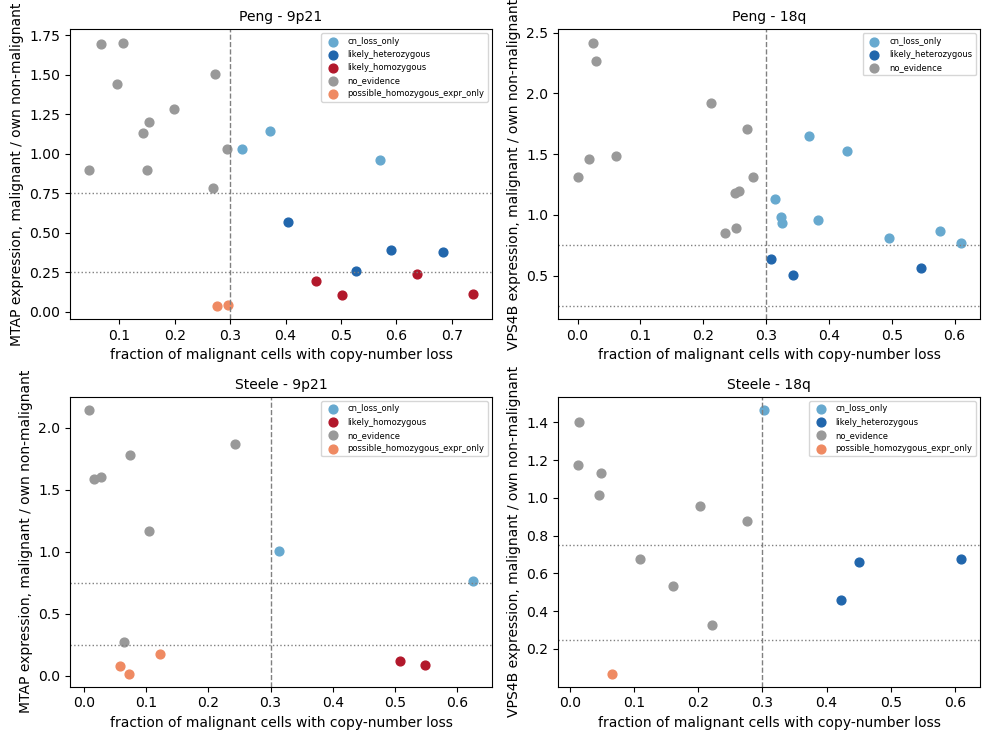

In [39]:
# ==========================================================================
# R3a · PER-TUMOUR LOSS CALLS WITH BOOTSTRAP UNCERTAINTY   ·   Supplementary Table S8
#
# WHY two lines of evidence: inferred copy number alone is noisy at a focal locus, and expression
# alone is weak evidence for a homozygous deletion (the reviewers' point), so a call needs both, and
# each call's stability is measured by resampling malignant and reference cells separately.
# ==========================================================================

if not RAW_SC_OK:
    print("R3a skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see R0)")
else:
    LOSS_EVIDENCE = {"likely_homozygous", "possible_homozygous_expr_only", "likely_heterozygous"}


    def loss_call(frac_loss, ratio):
        if not np.isfinite(ratio):
            return "no_expression_reference"
        cn = frac_loss >= LOSS_FRAC_MIN
        if ratio < HOM_RATIO_MAX:
            return "likely_homozygous" if cn else "possible_homozygous_expr_only"
        if cn and ratio < HET_RATIO_MAX:
            return "likely_heterozygous"
        return "cn_loss_only" if cn else "no_evidence"


    def tumour_calls(label):
        t = CNVT[label]
        rows, cell_loss = [], {}
        for pat, g in t.groupby("Patient"):
            own_ref = g[g["role"].isin(["immune", "stromal"])]
            m = g[g["role"] == "malignant"]
            if len(own_ref) < 20 or len(m) < MIN_MAL_CNV:
                continue
            # seed from a STABLE hash of the patient name: Python's hash() changes every
            # process (the list(set) bug from section 11), zlib.crc32 does not
            rng_b = np.random.default_rng([SEED, 7, zlib.crc32(str(pat).encode())])
            for loc, passenger in LOCUS_PASSENGER.items():
                fcol, ecol = "focal_" + loc, passenger + "_cp10k"
                thr = np.nanquantile(own_ref[fcol], LOSS_REF_Q)
                loss = (m[fcol] < thr).values
                for cid, v in zip(m.index, loss):
                    cell_loss[(cid, loc)] = bool(v)
                frac = float(loss.mean())
                den = own_ref[ecol].mean()
                ratio = float(m[ecol].mean() / den) if den > 0 else np.nan
                call = loss_call(frac, ratio)
                # bootstrap: resample malignant and reference cells separately
                same = 0
                mf, me, re_ = m[fcol].values, m[ecol].values, own_ref[ecol].values
                rf = own_ref[fcol].values
                for _ in range(N_BOOT_CALL):
                    bm_ = rng_b.integers(0, len(mf), len(mf)); br = rng_b.integers(0, len(rf), len(rf))
                    thr_b = np.nanquantile(rf[br], LOSS_REF_Q)
                    fr_b = float(np.mean(mf[bm_] < thr_b))
                    den_b = np.nanmean(re_[br])
                    ra_b = float(np.nanmean(me[bm_]) / den_b) if den_b > 0 else np.nan
                    same += loss_call(fr_b, ra_b) == call
                epi = g[g["role"] == "normal_epithelial"][ecol].mean()
                rows.append(dict(cohort=label, patient=pat, locus=loc, passenger=passenger,
                                 n_malignant=len(m), frac_cells_loss=round(frac, 3),
                                 expr_ratio_vs_own_nonmalignant=round(ratio, 3) if np.isfinite(ratio) else np.nan,
                                 expr_ratio_vs_normal_epithelium=round(float(m[ecol].mean() / epi), 3)
                                 if epi and epi > 0 else np.nan,
                                 call=call, bootstrap_agreement=round(same / N_BOOT_CALL, 3)))
        return pd.DataFrame(rows), cell_loss


    CALLS, CELL_LOSS = [], {}
    for _lab in ["Peng", "Steele"]:
        _c, _cl = tumour_calls(_lab)
        CALLS.append(_c); CELL_LOSS[_lab] = _cl
    CALLS = pd.concat(CALLS, ignore_index=True)
    CALLS.to_csv(rev_path("TableS2_passenger_loss_calls.csv"), index=False)
    for (_lab, _loc), _g in CALLS.groupby(["cohort", "locus"]):
        print("\n{} - {} ({}):".format(_lab, _loc, LOCUS_PASSENGER[_loc]))
        print("  " + _g["call"].value_counts().to_string().replace("\n", "\n  "))
    print("\nfull table -> TableS2_passenger_loss_calls.csv")
    REV["passenger_calls"] = CALLS.groupby(["cohort", "locus"])["call"].value_counts().unstack(fill_value=0).to_dict(orient="index")
    REV["passenger_calls"] = {"{}|{}".format(*k): v for k, v in REV["passenger_calls"].items()}

    if FIGURES:
        fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
        colors = {"likely_homozygous": "#B2182B", "possible_homozygous_expr_only": "#EF8A62",
                  "likely_heterozygous": "#2166AC", "cn_loss_only": "#67A9CF",
                  "no_evidence": "0.6", "no_expression_reference": "0.85"}
        for i, _lab in enumerate(["Peng", "Steele"]):
            for j, _loc in enumerate(LOCI):
                ax = axes[i, j]
                g = CALLS[(CALLS["cohort"] == _lab) & (CALLS["locus"] == _loc)]
                for call, gg in g.groupby("call"):
                    ax.scatter(gg["frac_cells_loss"], gg["expr_ratio_vs_own_nonmalignant"],
                               s=40, color=colors.get(call, "k"), label=call)
                ax.axvline(LOSS_FRAC_MIN, color="0.5", ls="--", lw=1)
                ax.axhline(HOM_RATIO_MAX, color="0.5", ls=":", lw=1)
                ax.axhline(HET_RATIO_MAX, color="0.5", ls=":", lw=1)
                ax.set_xlabel("fraction of malignant cells with copy-number loss")
                ax.set_ylabel("{} expression, malignant / own non-malignant".format(LOCUS_PASSENGER[_loc]))
                ax.set_title("{} - {}".format(_lab, _loc), fontsize=10)
                ax.legend(fontsize=6)
        plt.tight_layout()
        _show("revR3_passenger_loss_calls")

In [40]:
# ==========================================================================
# R3b · ASSOCIATIONS INSIDE TUMOURS (AND CELLS) WITH EVIDENCE OF THE RELEVANT LOSS
# Each target is tested against its own passenger locus (VPS4A <- 18q; PRMT5, MAT2A <- 9p21):
# (i) tumours with any loss evidence, (ii) likely-homozygous tumours only, (iii) within
# tumours with evidence, only cells individually called as having the loss (30-cell floor).
#
# WHY tumour-level first: per-cell focal calls are noisy, so tumours with evidence of loss are the
# primary restriction and cells called with loss are supporting evidence. With <= 5 tumours a Wilcoxon
# test cannot reach p < 0.05 (smallest p = 0.0625), so those rows are read from their CIs.
# ==========================================================================

if not RAW_SC_OK:
    print("R3b skipped -- needs peng_processed.h5ad and steele_qc_lognorm.h5ad (see R0)")
else:
    REV["loss_strat"] = {}
    for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null)]:
        print("\n{} -- association restricted by passenger-loss evidence\n".format(_lab))
        rows = []
        for t in TARGETS:
            loc = TARGET_LOCUS[t]
            g = CALLS[(CALLS["cohort"] == _lab) & (CALLS["locus"] == loc)]
            ev = set(g.loc[g["call"].isin(LOSS_EVIDENCE), "patient"].astype(str))
            hom = set(g.loc[g["call"] == "likely_homozygous", "patient"].astype(str))
            pats = _ad.obs["Patient"].astype(str)
            for name, sel, mc in [("tumours with {} loss evidence".format(loc), pats.isin(ev).values, MIN_CELLS),
                                  ("likely-homozygous {} tumours".format(loc), pats.isin(hom).values, MIN_CELLS)]:
                r = ps_vs(_ad.obs[sel], t + "_sig", min_cells=mc)
                REV["loss_strat"]["{}|{}|{}".format(_lab, t, name)] = r
                if len(r) >= 3:
                    rows.append(rev_row("{} | {}".format(t, name), r, _null))
                else:
                    print("  {:<8} {:<34} only {} tumours -- not tested".format(t, name, len(r)))
            cl = CELL_LOSS[_lab]
            cell_sel = np.array([pats.iloc[k] in ev and cl.get((cid, loc), False)
                                 for k, cid in enumerate(_ad.obs_names)])
            r = ps_vs(_ad.obs[cell_sel], t + "_sig", min_cells=30)
            REV["loss_strat"]["{}|{}|cells with loss".format(_lab, t)] = r
            if len(r) >= 3:
                rows.append(rev_row("{} | cells called with {} loss".format(t, loc), r, _null))
        if rows:
            show_rev(rows)


Peng -- association restricted by passenger-loss evidence

  VPS4A    likely-homozygous 18q tumours      only 0 tumours -- not tested
                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  VPS4A | tumours with 18q loss evidence     3     1/3   -0.0068   [-0.0957, +0.0590]    1.0000    -0.3   0.7622
  PRMT5 | tumours with 9p21 loss evidence   10    5/10   -0.0231   [-0.1111, +0.0519]    1.0000    -0.5   0.6054
  PRMT5 | likely-homozygous 9p21 tumours     4     2/4   +0.0300   [-0.0625, +0.1225]    0.6250    +0.1   0.8961
  PRMT5 | cells called with 9p21 loss       10    4/10   +0.0152   [-0.0445, +0.0681]    0.4922    -0.0   0.9690
  MAT2A | tumours with 9p21 loss evidence   10    1/10   +0.3070   [+0.2042, +0.4129]    0.0039    +3.4   0.0070
  MAT2A | likely-homozygous 9p21 tumours     4     1/4   +0.1834   [+0.0584, +0.2874]    0.2500    +1.9   0.0559
  MAT2A | cells called with 9p21 loss       10    0/10   +0.2600   [+0.166

## R4 · Do the signatures predict measured dependency? DepMap held-out validation  ·  Supplementary Table S3

*Reviewer must-fix 2, 3 and 5. Methods → Derivation of the Dependency Signature; Validation of
the Signatures Against Measured Dependency.* The reviewer's central objection: nothing showed
the signatures track dependency. This section tests that **inside DepMap**, where dependency
is measured, before any single-cell use.

**Held-out validation.** Five-fold cross-validation stratified by lineage, repeated 10 times.
In every split the signature is **re-derived on the training lines only** and scored on the
held-out lines as the mean z-scored expression of its genes (z computed with training means and
SDs), so no held-out line touches gene selection. Reported, on the pooled held-out predictions:

- **ρ(score, Chronos)** — Spearman; *negative* means a higher signature score predicts stronger
  dependency (Chronos: lower = more dependent)
- **out-of-sample R²** of Chronos from a line fitted on the training folds
- **AUROC**, most-dependent quartile vs least-dependent quartile, and at the absolute
  Chronos ≤ −0.5 cut where both classes have ≥ 10 lines
- **ΔR²**: nested models of Chronos with target expression + lineage + proliferation, with and
  without the signature — does the signature add anything beyond those?

**Independent dependency dataset.** The out-of-fold scores are correlated with DEMETER2
(RNA interference) dependency for the lines it covers; the Chronos–DEMETER2 correlation of the
target itself is printed as the ceiling.

**Alternative derivations (must-fix 3).** Passenger loss from **DepMap copy number** instead of
an expression cut-off: *MTAP* by deep deletion (relative copy number < 0.25), because the PRMT5 and
MAT2A vulnerabilities need homozygous loss; *VPS4B* by copy loss (relative copy number < 0.75),
because its homozygous deletion is rare and the VPS4A vulnerability was defined by 18q loss
(Neggers et al. 2020). A context with fewer than 40 lines is reported and skipped; **lineage held
constant** (gene and Chronos ranks residualised on lineage before correlating); cut-offs of
10%, 33% and 50%; and **passenger-intact** lines (no deletion, passenger expression ≥ median)
as the comparison that should not carry the collateral-lethal interaction. Each is reported
with its held-out performance, its overlap with the original 100 genes, and its single-cell
association in both cohorts. Deletion-derived and intact-derived signatures are then compared
**in held-out PDAC lines** (derived without any PDAC line).

**Composition (must-fix 5).** Over-representation of all 100 genes of each signature against
GO biological process, Reactome and MSigDB Hallmark, with the DepMap gene universe as background.

The recovery of *PRMT5* at rank 10 (section 7) is a wiring check only and is not used as
evidence here.

**Why these choices**

| choice | why |
|---|---|
| Five folds, ten repeats | A standard split; repeating with new random folds averages away the luck of any single split. |
| Folds stratified by lineage | Each held-out fold has the same lineage mix as the training folds, so performance is not inflated or deflated by lineage imbalance. |
| Re-derivation inside each training fold, z-scores from training data | No held-out line influences gene selection or scaling, so the evaluation has no leakage. |
| AUROC between dependency quartiles | Avoids choosing an arbitrary absolute dependency threshold; the AUROC at the absolute −0.5 cut is computed as well and saved in the validation table. |
| ΔR² over target expression, lineage and proliferation | Tests whether the signature adds anything beyond the trivial predictors the reviewers named. |
| Contexts with fewer than 40 lines skipped | A derivation from fewer lines is too noisy to interpret. |
| Copy-number scale detected automatically | DepMap has distributed copy number on linear and log2 scales in different releases; the scale is inferred from the values and printed. |

In [41]:
# ==========================================================================
# R4a · DEPMAP METADATA, COPY NUMBER, DELETION CALLS
# Lineage + PDAC flag from Model.csv. Copy number loaded for the passenger genes only (the
# full matrix is large), with the same default-entry / metadata / ' (entrez)' contract as
# section 7; its scale is detected and printed. Deep deletion = relative CN < DEL_REL_CN.
#
# WHY: deletion calls from DepMap copy number replace the expression cut-off the reviewers objected to;
# the cross-table shows how far the two agree. Copy-number scale is detected from the values because
# DepMap has shipped linear and log2 scales in different releases.
# ==========================================================================

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

HAVE_MODEL = os.path.exists(DEPMAP_MODEL)
HAVE_CN = os.path.exists(DEPMAP_CN)
if HAVE_MODEL:
    model = pd.read_csv(DEPMAP_MODEL).set_index("ModelID")
    LINEAGE = model["OncotreeLineage"].reindex(expr.index).fillna("Unknown").astype(str)
    IS_PDAC = (model["OncotreePrimaryDisease"].reindex(expr.index).fillna("")
               .str.contains("Pancreatic Adenocarcinoma", case=False))
    print("lineages: {} | PDAC lines with dependency + expression: {}".format(
        LINEAGE.nunique(), int(IS_PDAC.sum())))
else:
    LINEAGE = pd.Series("Unknown", index=expr.index)
    IS_PDAC = pd.Series(False, index=expr.index)
    print("!! Model.csv missing -> lineage-held, stratified CV and PDAC analyses are degraded")


def load_depmap_cols(path, genes):
    """Section 7's loader contract, reading only the requested gene columns."""
    head = list(pd.read_csv(path, nrows=0).columns)
    want = [head[0]] + [c for c in head if c in ("ModelID", "IsDefaultEntryForModel")] + \
           [c for c in head if c.split(" (")[0].strip() in genes]
    m = pd.read_csv(path, usecols=list(dict.fromkeys(want)))
    if "ModelID" in m.columns:
        if "IsDefaultEntryForModel" in m.columns:
            col = m["IsDefaultEntryForModel"]
            m = m[col.astype(str).str.lower().isin(["true", "yes", "1"]) | (col == True)]
        m = m.set_index("ModelID")
    else:
        m = m.set_index(m.columns[0])
    m = m.drop(columns=[c for c in m.columns if c.split(" (")[0].strip() in META], errors="ignore")
    m.columns = [c.split(" (")[0].strip() for c in m.columns]
    m = m.loc[:, ~m.columns.duplicated()].select_dtypes(include=[np.number])
    return m[~m.index.duplicated()]


DELETED = {}
if HAVE_CN:
    # The scale differs between DepMap copy-number files AND between releases: the 26Q2+
    # OmicsCNGeneWGS.csv is linear relative copy number, PortalOmicsCNGeneLog2.csv is log2(x+1),
    # and OmicsCNGene.csv was log2(x+1) up to 25Q1. Linear and log2(x+1) both centre on 1, so
    # the median cannot tell them apart; amplification-prone genes can: in log2(x+1) a value
    # above 6 would mean a 63-fold gain, while in linear scale ERBB2/MYC amplicons exceed it.
    _AMP = ["MYC", "ERBB2", "CCND1", "KRAS", "EGFR", "CDK4", "MDM2"]
    _cn_all = load_depmap_cols(DEPMAP_CN, ["MTAP", "VPS4B", "CDKN2A", "SMAD4", "CDS1"] + _AMP)
    cnm = _cn_all[[g for g in ["MTAP", "VPS4B", "CDKN2A", "SMAD4", "CDS1"] if g in _cn_all.columns]]
    med, vmin = float(np.nanmedian(cnm.values)), float(np.nanmin(cnm.values))
    _ampc = [g for g in _AMP if g in _cn_all.columns]
    amp_max = float(np.nanmax(_cn_all[_ampc].values)) if _ampc else float("nan")
    _nm = os.path.basename(DEPMAP_CN).lower()
    if CN_SCALE != "auto":
        scale = CN_SCALE
    elif "log2" in _nm:
        scale = "log2(x+1)"
    elif "absolute" in _nm or med >= 1.4:
        scale = "absolute"
    elif -0.4 < med < 0.4 and vmin < 0:
        scale = "log2"
    elif "wgs" in _nm or amp_max > 6:
        scale = "linear"
    else:
        scale = "log2(x+1)"
    rel = {"linear": cnm, "log2(x+1)": 2 ** cnm - 1, "log2": 2 ** cnm, "absolute": cnm / 2.0}[scale]
    print("copy number: {} ({} lines) | median {:.2f}, min {:.2f}, max over amplicon genes {:.1f} "
          "-> read as {} relative copy number (set CN_SCALE in R0 to override)".format(
              os.path.basename(DEPMAP_CN), len(cnm), med, vmin, amp_max, scale))
    for pg in ["MTAP", "VPS4B"]:
        d = (rel[pg] < LOSS_CN[pg]).reindex(expr.index)
        DELETED[pg] = d
        print("  {:<6} {} (relative CN < {}) in {:,} of {:,} lines with copy number".format(
            pg, LOSS_WORD[pg], LOSS_CN[pg], int(d.fillna(False).astype(bool).sum()), int(d.notna().sum())))
    # MTAP deep deletion is common but far from universal (published: roughly 10-20% of lines);
    # a fraction outside 3-40% means the scale was misread, and the deletion analyses are skipped
    _f = float(DELETED["MTAP"].dropna().astype(float).mean())
    if not 0.03 <= _f <= 0.40:
        print("!! MTAP called deleted in {:.0%} of lines -- implausible, so the copy-number scale was "
              "probably misread. Deletion-based analyses skipped; check the file.".format(_f))
        DELETED = {}
    # how the expression cut-off and the deletion call agree
    for pg in [g for g in ("MTAP", "VPS4B") if g in DELETED]:
        q = expr[pg] <= expr[pg].quantile(LOW_Q)
        ok = DELETED[pg].notna()
        print("\n  {}: bottom-quartile expression vs {}".format(pg, LOSS_WORD[pg]))
        print("  " + pd.crosstab(q[ok], DELETED[pg][ok].astype(bool),
                                 rownames=["expr_bottom_quartile"], colnames=["deleted"])
              .to_string().replace("\n", "\n  "))
else:
    print("!! {} missing -> deletion-based analyses skipped".format(os.path.basename(DEPMAP_CN)))

# deletion-positive vs deletion-negative: is the target more needed when its passenger is lost?
print("\nTARGET DEPENDENCY BY PASSENGER LOSS (Chronos; lower = more dependent)\n")
REV["del_vs_intact_chronos"] = {}
for t in TARGETS:
    pg = TARGET_CONTEXT[t]
    if pg not in DELETED:
        continue
    d = DELETED[pg].reindex(dep.index)
    a, b = dep.loc[d == True, t].dropna(), dep.loc[d == False, t].dropna()
    if len(a) < 3 or len(b) < 3:
        print("  {:<6} too few {} {} lines (n={}) for the comparison".format(t, pg, LOSS_WORD[pg], len(a)))
        continue
    p = mannwhitneyu(a, b, alternative="two-sided")[1]
    print("  {:<6} {} {} median {:+.3f} (n={}) vs intact {:+.3f} (n={})   p = {:.2e}".format(
        t, pg, LOSS_WORD[pg], a.median(), len(a), b.median(), len(b), p))
    REV["del_vs_intact_chronos"][t] = dict(med_del=float(a.median()), n_del=len(a),
                                          med_intact=float(b.median()), n_intact=len(b), p=float(p),
                                          call="{} < {}".format(LOSS_WORD[pg], LOSS_CN[pg]))

# line-level programs (unsupervised: no dependency information, so no leakage in CV)
def line_score(genes):
    g = [x for x in genes if x in expr.columns]
    z = (expr[g] - expr[g].mean()) / expr[g].std().replace(0, np.nan)
    return z.mean(axis=1)

PROLIF_LINE, EPI_LINE, EMT_LINE = line_score(PROLIF), line_score(EPI_MARKERS), line_score(EMT_MARKERS)
print("\nline-level proliferation / epithelial / EMT scores computed")

lineages: 29 | PDAC lines with dependency + expression: 44
copy number: OmicsCNGeneWGS.csv (1763 lines) | median 0.88, min 0.00, max over amplicon genes 254.9 -> read as linear relative copy number (set CN_SCALE in R0 to override)
  MTAP   deep deletion (relative CN < 0.25) in 183 of 1,063 lines with copy number
  VPS4B  copy loss (relative CN < 0.75) in 362 of 1,063 lines with copy number

  MTAP: bottom-quartile expression vs deep deletion
  deleted               False  True 
  expr_bottom_quartile              
  False                   796      2
  True                     84    181

  VPS4B: bottom-quartile expression vs copy loss
  deleted               False  True 
  expr_bottom_quartile              
  False                   601    194
  True                    100    168

TARGET DEPENDENCY BY PASSENGER LOSS (Chronos; lower = more dependent)

  VPS4A  VPS4B copy loss median -0.472 (n=362) vs intact -0.280 (n=701)   p = 1.04e-34
  PRMT5  MTAP deep deletion median -1.432 (n=183)

In [42]:
# ==========================================================================
# R4b · DERIVATION AND HELD-OUT EVALUATION MACHINERY
# corr_with reproduces section 7's Spearman (Pearson of average ranks) in one matrix
# product; derive() must reproduce signatures[] exactly -- checked below before use.
#
# WHY this machinery: the signature is re-derived on the training folds ONLY and z-scored with training
# means and SDs, so no held-out line touches gene selection (no leakage). Folds are stratified by
# lineage so each held-out set has the training set's lineage mix.
# ==========================================================================

# corr_with: Pearson correlation of average ranks IS the Spearman correlation (ties get average
# ranks), computed for every gene at once as one matrix product instead of 19,000 spearmanr calls.
def corr_with(E, y):
    """Spearman of every column of E with y, ranks taken within these lines."""
    R = E.rank(axis=0).values
    r = rankdata(y)
    R = R - R.mean(axis=0)
    r = r - r.mean()
    with np.errstate(invalid="ignore", divide="ignore"):
        c = (R.T @ r) / (np.sqrt((R ** 2).sum(axis=0)) * np.sqrt((r ** 2).sum()))
    return pd.Series(c, index=E.columns)


# corr_within_lineage: projecting the lineage indicators out of both rank vectors gives a partial
# Spearman correlation with lineage held constant -- the reviewers' request (must-fix 3) to stop
# genes that merely mark a tissue of origin from entering a dependency signature.
def corr_within_lineage(E, y, lin):
    """Lineage held constant: ranks of every gene and of y are residualised on lineage
    indicators before correlating, so a gene that only separates lineages scores ~0."""
    R = E.rank(axis=0).values
    r = rankdata(y).astype(float)
    D = pd.get_dummies(lin.astype(str)).values.astype(float)
    P = D @ np.linalg.pinv(D)
    R = R - P @ R
    r = r - P @ r
    with np.errstate(invalid="ignore", divide="ignore"):
        c = (R.T @ r) / (np.sqrt((R ** 2).sum(axis=0)) * np.sqrt((r ** 2).sum()))
    return pd.Series(c, index=E.columns)


# derive: the section-7 derivation as a function, so the identical rule can be re-run inside every
# cross-validation fold and every alternative context. `exclude` removes genes BEFORE ranking (used
# to rebuild signatures without identity genes, R5d / R8c).
def derive(target, lines, n=100, lineage_held=False, exclude=None):
    lines = pd.Index(lines).intersection(dep.index[dep[target].notna()])
    e = expr.loc[lines]
    e = e.loc[:, e.std() > 0]
    if exclude:
        e = e.drop(columns=[g for g in exclude if g in e.columns])
    y = dep.loc[lines, target].values
    c = corr_within_lineage(e, y, LINEAGE.reindex(lines)) if lineage_held else corr_with(e, y)
    return c.dropna().sort_values().head(n).index.tolist()


def ctx_quantile(pg, q):
    return expr.index[expr[pg] <= expr[pg].quantile(q)]


def ctx_deleted(pg):
    return expr.index[DELETED[pg].reindex(expr.index).fillna(False).astype(bool).values]


# ctx_intact: lines with no deletion call AND passenger expression at or above the median -- lines
# that clearly keep the passenger, so the collateral-lethal interaction should be absent there.
def ctx_intact(pg):
    d = DELETED[pg].reindex(expr.index)
    return expr.index[(d == False).values & (expr[pg] >= expr[pg].median()).values]


# guard: the fast derivation must reproduce section 7's signatures
for t in TARGETS:
    again = derive(t, ctx_quantile(TARGET_CONTEXT[t], LOW_Q))
    ov = len(set(again) & set(signatures[t]))
    print("{:<6} fast derivation reproduces {}/100 of section 7's genes".format(t, ov))
    assert ov >= 98, "derivation does not reproduce section 7 -- stop"


# sig_score: each gene z-scored with TRAINING-line means and SDs, then averaged with equal weight per
# gene. Using training statistics for the held-out lines is what keeps the evaluation leak-free.
def sig_score(train, test, genes):
    g = [x for x in genes if x in expr.columns]
    mu = expr.loc[train, g].mean()
    sd = expr.loc[train, g].std().replace(0, np.nan)
    return ((expr.loc[test, g] - mu) / sd).mean(axis=1)


# _design: lineage indicators for lineages with >= 5 training lines; rarer lineages are pooled into
# 'other' so every coefficient is estimable. One indicator is dropped as the reference level so the
# design is not collinear with the intercept.
def _design(lines, levels, extra=None):
    lin = LINEAGE.reindex(lines).where(LINEAGE.reindex(lines).isin(levels), "other")
    D = pd.get_dummies(pd.Categorical(lin, categories=list(levels) + ["other"])).values[:, 1:]
    cols = [D.astype(float)]
    if extra is not None:
        cols = [np.asarray(e, float).reshape(len(lines), -1) for e in extra] + cols
    return np.column_stack(cols)


def ols_predict(Xtr, ytr, Xte):
    A = np.column_stack([np.ones(len(Xtr)), Xtr])
    beta = np.linalg.lstsq(A, ytr, rcond=None)[0]
    return np.column_stack([np.ones(len(Xte)), Xte]) @ beta


# r2: OUT-OF-SAMPLE R^2 against the mean of the held-out values. It can be negative, meaning the
# prediction is worse than the mean -- reported as computed, never truncated at zero.
def r2(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    return float(1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2))


# auc_quartiles: most-dependent quartile (label 1) vs least-dependent quartile; the middle half is
# left out, so no arbitrary dependency threshold is needed. A higher score should mean more dependent.
def auc_quartiles(y, s):
    lo, hi = np.quantile(y, 0.25), np.quantile(y, 0.75)
    sel = (y <= lo) | (y >= hi)
    return float(roc_auc_score((y[sel] <= lo).astype(int), s[sel]))


def auc_abs(y, s):
    lab = (y <= STRONG_DEP_ABS).astype(int)
    if lab.sum() < 10 or (1 - lab).sum() < 10:
        return np.nan
    return float(roc_auc_score(lab, s))


# cv_eval: lineages with fewer lines than folds are pooled for stratification (StratifiedKFold needs
# >= one line per class per fold); each repeat reshuffles with its own seed; the BASE model is target
# expression + lineage + proliferation and the FULL model adds the signature, so delta R^2 is what the
# signature adds beyond those trivial predictors (must-fix 3).
def cv_eval(target, lines, derive_fn, n_rep=CV_REPEATS):
    """Repeated stratified 5-fold CV. Returns (mean metrics, sd metrics, out-of-fold score
    averaged over repeats)."""
    lines = pd.Index(lines).intersection(dep.index[dep[target].notna()])
    y = dep.loc[lines, target]
    strat = LINEAGE.reindex(lines).fillna("Unknown")
    vc = strat.value_counts()
    strat = strat.where(strat.map(vc) >= CV_FOLDS, "other")
    mets, oof = [], []
    for rep in range(n_rep):
        skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED + rep)
        s_pred, y_hat, yb, yf = (pd.Series(np.nan, index=lines) for _ in range(4))
        for tr, te in skf.split(np.zeros(len(lines)), strat.values):
            Ltr, Lte = lines[tr], lines[te]
            genes = derive_fn(target, Ltr)
            s_tr, s_te = sig_score(Ltr, Ltr, genes), sig_score(Ltr, Lte, genes)
            s_pred[Lte] = s_te.values
            b = np.polyfit(s_tr.values, y[Ltr].values, 1)
            y_hat[Lte] = np.polyval(b, s_te.values)
            levels = [l for l, c in LINEAGE.reindex(Ltr).value_counts().items() if c >= 5]
            base_tr = _design(Ltr, levels, [expr.loc[Ltr, target], PROLIF_LINE.reindex(Ltr)])
            base_te = _design(Lte, levels, [expr.loc[Lte, target], PROLIF_LINE.reindex(Lte)])
            yb[Lte] = ols_predict(base_tr, y[Ltr].values, base_te)
            yf[Lte] = ols_predict(np.column_stack([base_tr, s_tr.values]), y[Ltr].values,
                                  np.column_stack([base_te, s_te.values]))
        yy, ss = y.values, s_pred.values
        mets.append(dict(rho=spearmanr(ss, yy)[0], r2=r2(yy, y_hat.values),
                         auc_quartile=auc_quartiles(yy, ss), auc_abs=auc_abs(yy, ss),
                         r2_base=r2(yy, yb.values), r2_full=r2(yy, yf.values)))
        oof.append(s_pred)
    df = pd.DataFrame(mets)
    df["delta_r2"] = df["r2_full"] - df["r2_base"]
    return df.mean(), df.std(), pd.concat(oof, axis=1).mean(axis=1), len(lines)


print("\nCV machinery ready: {} folds x {} repeats".format(CV_FOLDS, CV_REPEATS))

VPS4A  fast derivation reproduces 100/100 of section 7's genes
PRMT5  fast derivation reproduces 100/100 of section 7's genes
MAT2A  fast derivation reproduces 100/100 of section 7's genes

CV machinery ready: 5 folds x 10 repeats


In [43]:
# ==========================================================================
# R4c · HELD-OUT VALIDATION, ALTERNATIVE DERIVATIONS, PDAC HOLD-OUT, DEMETER2
# Runs every derivation for every target (a few minutes). Results:
# REV_DIR/TableS1_depmap_validation.csv. Single-cell rho = partial Spearman with the
# classical score for a signature derived on the FULL context of that variant.
#
# WHY each comparison: alternative derivations answer must-fix 3 (copy number, lineage held, other
# cut-offs, passenger-intact lines); the PDAC hold-out tests transfer to the disease in question;
# DEMETER2 is an independent technology (RNAi), with the target's own Chronos-DEMETER2 agreement as
# the ceiling any signature could reach.
# ==========================================================================

MIN_CTX_LINES = 40      # a context with fewer lines (with Chronos) is too small to derive and
                        # cross-validate a 100-gene signature; it is reported and skipped


def _n_ctx(t, ctx):
    """Lines of a context that have a Chronos score for the target."""
    return len(pd.Index(ctx).intersection(dep.index[dep[t].notna()]))


VARIANTS = {"original (bottom 25% expression)": (lambda pg: ctx_quantile(pg, LOW_Q), {})}
for q in CUTOFFS:
    if q != LOW_Q:
        VARIANTS["bottom {:.0%} expression".format(q)] = (lambda pg, q=q: ctx_quantile(pg, q), {})
VARIANTS["lineage held constant"] = (lambda pg: ctx_quantile(pg, LOW_Q), {"lineage_held": True})
if DELETED:
    VARIANTS["passenger-loss lines (copy number)"] = (ctx_deleted, {})
    VARIANTS["passenger-intact lines"] = (ctx_intact, {})

D2 = None
if os.path.exists(DEMETER2) and HAVE_MODEL and "CCLEName" in model.columns:
    _d2 = pd.read_csv(DEMETER2, index_col=0)
    _d2.index = [str(i).split(" (")[0].strip() for i in _d2.index]
    _d2 = _d2[~_d2.index.duplicated()].T
    _c2m = model.reset_index().dropna(subset=["CCLEName"]).set_index("CCLEName")["ModelID"]
    _d2.index = _d2.index.map(_c2m)
    D2 = _d2[_d2.index.notna()]
    D2 = D2[~D2.index.duplicated()]
    print("DEMETER2: {} lines mapped to ModelID".format(len(D2)))
else:
    print("!! DEMETER2 (or Model.csv) missing -> independent-dataset check skipped")


def sc_assoc(genes):
    """Mean partial Spearman with the classical score in both cohorts for a gene list."""
    out = {}
    for lab, ad in [("Peng", mal), ("Steele", steele)]:
        present = score(ad, genes, "_v")
        out[lab] = mean_rho(ps_vs(ad.obs, "_v")) if len(present) >= 20 else np.nan
        del ad.obs["_v"]
    return out


TS1, OOF = [], {}
for t in TARGETS:
    pg = TARGET_CONTEXT[t]
    for vname, (ctx_fn, kw) in VARIANTS.items():
        ctx = ctx_fn(pg)
        if _n_ctx(t, ctx) < MIN_CTX_LINES:
            print("  {:<6} {:<36} n={:<4} -- too few lines to derive a signature; skipped".format(
                t, vname, _n_ctx(t, ctx)))
            TS1.append(dict(target=t, derivation=vname, n_lines=_n_ctx(t, ctx)))
            continue
        fn = lambda tt, L, kw=kw: derive(tt, L, **kw)
        m, s, oof, n = cv_eval(t, ctx, fn)
        full_genes = derive(t, ctx, **kw)
        jac = len(set(full_genes) & set(signatures[t])) / len(set(full_genes) | set(signatures[t]))
        sca = sc_assoc(full_genes)
        row = dict(target=t, derivation=vname, n_lines=n,
                   rho_score_chronos=m["rho"], rho_sd=s["rho"], r2_oos=m["r2"],
                   auc_quartiles=m["auc_quartile"], auc_abs=m["auc_abs"],
                   r2_base=m["r2_base"], r2_full=m["r2_full"], delta_r2=m["delta_r2"],
                   jaccard_vs_original=jac, sc_rho_peng=sca["Peng"], sc_rho_steele=sca["Steele"])
        if D2 is not None and t in D2.columns:
            both = oof.index.intersection(D2.index[D2[t].notna()])
            if len(both) >= 20:
                row["rho_oof_demeter2"] = spearmanr(oof[both], D2.loc[both, t])[0]
                row["rho_chronos_demeter2"] = spearmanr(dep.loc[both, t], D2.loc[both, t])[0]
                row["n_demeter2"] = len(both)
        TS1.append(row)
        if vname.startswith("original"):
            OOF[t] = (oof, ctx)
        print("  {:<6} {:<36} n={:<4} rho={:+.3f}  R2={:+.3f}  AUC={:.2f}  dR2={:+.3f}  "
              "J={:.2f}  sc: Peng {:+.3f} / Steele {:+.3f}{}".format(
                  t, vname, n, m["rho"], m["r2"], m["auc_quartile"], m["delta_r2"], jac,
                  sca["Peng"], sca["Steele"],
                  "  D2 rho={:+.3f} (ceiling {:+.3f}, n={})".format(
                      row["rho_oof_demeter2"], row["rho_chronos_demeter2"], row["n_demeter2"])
                  if "rho_oof_demeter2" in row else ""))
    print()

TS1 = pd.DataFrame(TS1)

# held-out PDAC lines: derive WITHOUT any PDAC line, test on PDAC lines only
print("HELD-OUT PDAC LINES (derived on non-PDAC lines)\n")
PD = []
pdac_all = expr.index[IS_PDAC.values]
for t in TARGETS:
    pg = TARGET_CONTEXT[t]
    plan = [("original (bottom 25% expression)", ctx_quantile(pg, LOW_Q))]
    if DELETED:
        plan += [("passenger-loss lines (copy number)", ctx_deleted(pg)),
                 ("passenger-intact lines", ctx_intact(pg))]
    for vname, ctx in plan:
        tr = ctx[~IS_PDAC.reindex(ctx).fillna(False).values]
        if _n_ctx(t, tr) < MIN_CTX_LINES:
            print("  {:<6} {:<36} n={} non-PDAC lines -- too few to derive; skipped".format(t, vname, _n_ctx(t, tr)))
            continue
        genes = derive(t, tr)
        tests = {"PDAC lines (all)": pdac_all.intersection(dep.index[dep[t].notna()])}
        if DELETED:
            tests["PDAC lines with {} {}".format(pg, "loss" if pg == "VPS4B" else "deletion")] = pdac_all.intersection(ctx_deleted(pg)).intersection(dep.index[dep[t].notna()])
        for tname, te in tests.items():
            if len(te) < 6:
                print("  {:<6} {:<36} {:<32} n={} -- too few".format(t, vname, tname, len(te)))
                continue
            sco = sig_score(tr, te, genes)
            rho = spearmanr(sco, dep.loc[te, t])[0]
            PD.append(dict(target=t, derivation=vname, test_set=tname, n=len(te), rho=rho))
            print("  {:<6} {:<36} {:<32} n={:<3} rho={:+.3f}".format(t, vname, tname, len(te), rho))
PD = pd.DataFrame(PD)
TS1.to_csv(rev_path("TableS1_depmap_validation.csv"), index=False)
PD.to_csv(rev_path("TableS1b_pdac_holdout.csv"), index=False)
REV["depmap_validation"] = TS1.round(4).to_dict(orient="records")
REV["pdac_holdout"] = PD.round(4).to_dict(orient="records")
print("\nwrote TableS1_depmap_validation.csv, TableS1b_pdac_holdout.csv")

DEMETER2: 701 lines mapped to ModelID
  VPS4A  original (bottom 25% expression)     n=285  rho=-0.441  R2=+0.176  AUC=0.83  dR2=+0.128  J=1.00  sc: Peng -0.036 / Steele -0.010  D2 rho=-0.294 (ceiling +0.588, n=118)
  VPS4A  bottom 10% expression                n=114  rho=-0.477  R2=+0.157  AUC=0.86  dR2=+0.129  J=0.17  sc: Peng -0.111 / Steele -0.110  D2 rho=-0.505 (ceiling +0.699, n=36)
  VPS4A  bottom 33% expression                n=376  rho=-0.431  R2=+0.160  AUC=0.84  dR2=+0.119  J=0.52  sc: Peng -0.003 / Steele +0.041  D2 rho=-0.237 (ceiling +0.519, n=161)
  VPS4A  bottom 50% expression                n=570  rho=-0.376  R2=+0.128  AUC=0.78  dR2=+0.089  J=0.25  sc: Peng +0.045 / Steele +0.092  D2 rho=-0.265 (ceiling +0.543, n=237)
  VPS4A  lineage held constant                n=285  rho=-0.435  R2=+0.146  AUC=0.83  dR2=+0.105  J=0.33  sc: Peng -0.097 / Steele -0.046  D2 rho=-0.304 (ceiling +0.588, n=118)
  VPS4A  passenger-loss lines (copy number)   n=362  rho=-0.242  R2=-0.001  AU

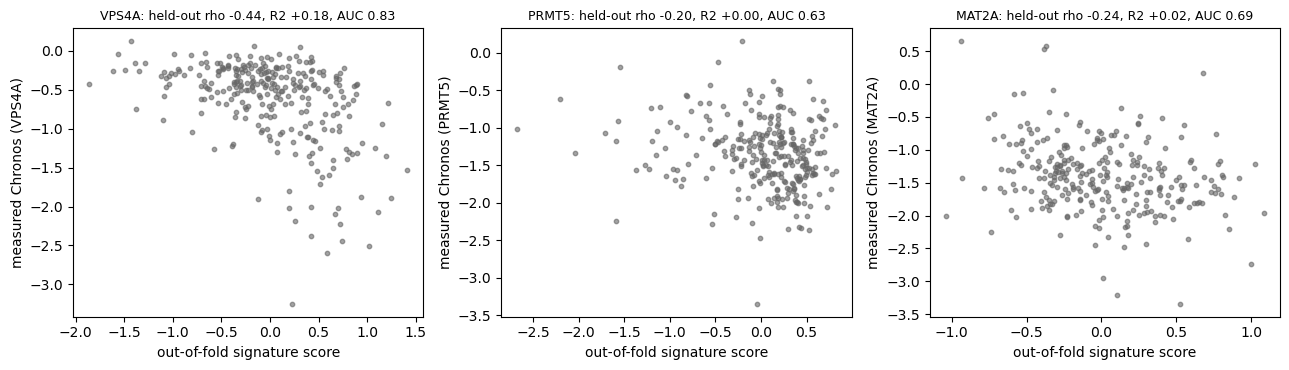

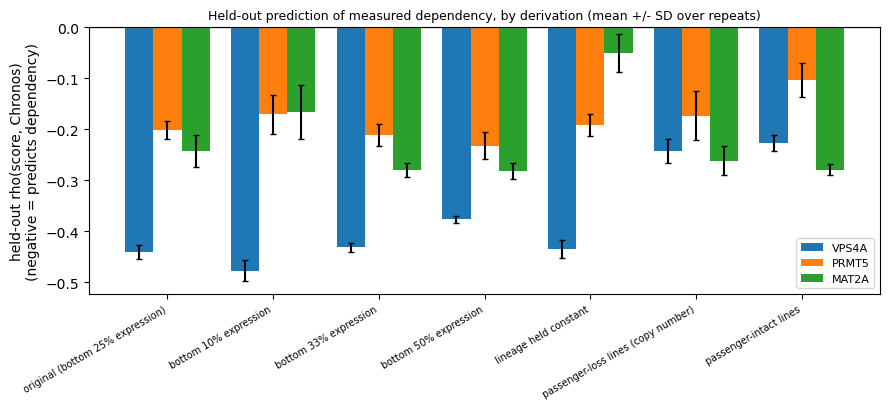

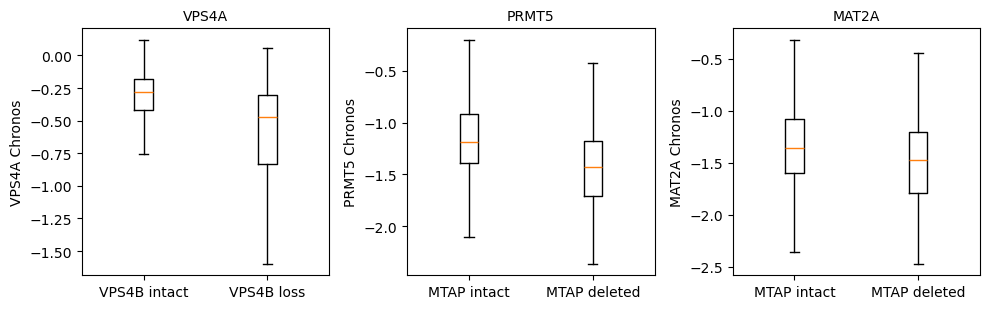

In [44]:
# ==========================================================================
# R4d · FIGURES   ·   held-out validation (Supplementary Fig. S3, with Table S3)
# (a) out-of-fold signature score vs measured Chronos, original derivation, per target
# (b) held-out rho for every derivation, per target
# (c) Chronos by passenger deletion status
# ==========================================================================

if FIGURES:
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    for ax, t in zip(axes, TARGETS):
        if t not in OOF:                     # original derivation skipped (too few lines)
            ax.set_title("{}: not derived".format(t), fontsize=9); ax.axis("off")
            continue
        oof, ctx = OOF[t]
        y = dep.loc[oof.index, t]
        ax.scatter(oof, y, s=10, color="0.4", alpha=0.6)
        rr = TS1[(TS1["target"] == t) & TS1["derivation"].str.startswith("original")].iloc[0]
        ax.set_title("{}: held-out rho {:+.2f}, R2 {:+.2f}, AUC {:.2f}".format(
            t, rr["rho_score_chronos"], rr["r2_oos"], rr["auc_quartiles"]), fontsize=9)
        ax.set_xlabel("out-of-fold signature score")
        ax.set_ylabel("measured Chronos ({})".format(t))
    plt.tight_layout()
    _show("revR4_heldout_scatter")

    fig, ax = plt.subplots(figsize=(9, 4.2))
    vnames = list(VARIANTS)
    w = 0.8 / len(TARGETS)
    for j, t in enumerate(TARGETS):
        _g = TS1[TS1["target"] == t].set_index("derivation").reindex(vnames)   # skipped = NaN bar
        vals, errs = _g["rho_score_chronos"].values, _g["rho_sd"].values
        ax.bar(np.arange(len(vnames)) + (j - 1) * w, vals, w, yerr=errs, label=t, capsize=2)
    ax.axhline(0, color="0.5", lw=1)
    ax.set_xticks(range(len(vnames)))
    ax.set_xticklabels(vnames, rotation=30, ha="right", fontsize=7)
    ax.set_ylabel("held-out rho(score, Chronos)\n(negative = predicts dependency)")
    ax.legend(fontsize=8)
    ax.set_title("Held-out prediction of measured dependency, by derivation (mean +/- SD over repeats)", fontsize=9)
    plt.tight_layout()
    _show("revR4_variants")

    if DELETED:
        fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
        for ax, t in zip(axes, TARGETS):
            pg = TARGET_CONTEXT[t]
            d = DELETED[pg].reindex(dep.index)
            ax.boxplot([dep.loc[d == False, t].dropna(), dep.loc[d == True, t].dropna()],
                       showfliers=False)
            ax.set_xticks([1, 2])
            ax.set_xticklabels(["{} intact".format(pg), "{} {}".format(pg, "loss" if pg == "VPS4B" else "deleted")])
            ax.set_ylabel("{} Chronos".format(t)); ax.set_title(t, fontsize=10)
        plt.tight_layout()
        _show("revR4_deletion_vs_intact")

In [45]:
# ==========================================================================
# R4e · WHAT THE SIGNATURES ARE MADE OF -- over-representation of ALL 100 genes
# Enrichr libraries (cached in REV_DIR) with the DepMap gene universe as background.
# gseapy is needed (pip install gseapy); without it the gene lists are written to CSV for
# manual g:Profiler / Enrichr analysis.
#
# WHY the DepMap gene universe as background: an enrichment test must compare against the genes that
# could have been selected, which are the genes in the DepMap expression matrix.
# ==========================================================================

def enrichr_libs(names=("GO_Biological_Process_2023", "Reactome_2022", "MSigDB_Hallmark_2020")):
    if os.path.exists(GENESET_JSON) and not REV_FORCE:
        with open(GENESET_JSON) as fh:
            return json.load(fh)
    import gseapy
    try:
        libs = {n: gseapy.get_library(name=n, organism="Human") for n in names}
    except Exception as err:                 # offline / Enrichr down: an earlier download will do
        if os.path.exists(GENESET_JSON):
            print("  Enrichr unreachable ({}) -> using the cached libraries".format(type(err).__name__))
            with open(GENESET_JSON) as fh:
                return json.load(fh)
        raise
    with open(GENESET_JSON, "w") as fh:
        json.dump(libs, fh)
    return libs


pd.DataFrame({t: pd.Series(signatures[t]) for t in TARGETS}).to_csv(rev_path("signature_genes.csv"), index=False)
LIBS = None
try:
    import gseapy
    LIBS = enrichr_libs()
    _gs = {"{}: {}".format(lib.split("_20")[0], term): genes
           for lib, d in LIBS.items() for term, genes in d.items()}
    ORA = []
    for t in TARGETS:
        enr = gseapy.enrich(gene_list=signatures[t], gene_sets=_gs, background=list(expr.columns),
                            outdir=None, cutoff=1.0, no_plot=True)
        df = enr.results.sort_values("Adjusted P-value")
        df.insert(0, "target", t)
        ORA.append(df)
        top = df.head(8)
        print("\n{} signature -- top terms (BH-adjusted p):".format(t))
        for _, r in top.iterrows():
            print("  {:<70} {:>8}  q={:.3g}".format(str(r["Term"])[:70], r["Overlap"], r["Adjusted P-value"]))
        REV.setdefault("ora_top", {})[t] = top[["Term", "Overlap", "Adjusted P-value"]].round(6).to_dict(orient="records")
    pd.concat(ORA).to_csv(rev_path("TableS1c_signature_enrichment.csv"), index=False)
    print("\nwrote TableS1c_signature_enrichment.csv")
except ImportError:
    print("gseapy not installed -> signature_genes.csv written for manual enrichment analysis")
except Exception as err:                     # no internet and no cached libraries
    LIBS = None
    print("!! gene-set libraries unavailable ({}: {}) -> R4e skipped; R5 falls back to EPI_MARKERS. "
          "signature_genes.csv written for manual analysis.".format(type(err).__name__, str(err)[:80]))


VPS4A signature -- top terms (BH-adjusted p):
  GO_Biological_Process: Protein Transport (GO:0015031)                    11/308  q=0.000416
  Reactome: Membrane Trafficking R-HSA-199991                              15/594  q=0.000416
  Reactome: Vesicle-mediated Transport R-HSA-5653656                       15/632  q=0.000427
  GO_Biological_Process: Endosomal Transport (GO:0016197)                   8/176  q=0.00133
  GO_Biological_Process: Endoplasmic Reticulum To Golgi Vesicle-Mediated    6/113  q=0.00765
  Reactome: COPI-mediated Anterograde Transport R-HSA-6807878                5/80  q=0.00921
  GO_Biological_Process: Golgi Organization (GO:0007030)                    6/127  q=0.00921
  GO_Biological_Process: Regulation Of Autophagosome Assembly (GO:200078     4/39  q=0.00921

PRMT5 signature -- top terms (BH-adjusted p):
  MSigDB_Hallmark: E2F Targets                                             11/200  q=9.64e-06
  MSigDB_Hallmark: G2-M Checkpoint                               

## R5 · Is the *MAT2A* association an epithelial-program association?

*Reviewer must-fix 5 and 6; recommended 3. Methods → Signature Scoring; Results → Robustness;
Discussion → The MAT2A Signature Association.* The circularity check tests only shared
genes. Here the *MAT2A* association is tested against **independently defined programs** that
could produce a positive association with no dependency behind it:

| program | definition |
|---|---|
| epithelial differentiation | GO:0030855 (Enrichr GO Biological Process 2023) |
| secretory activity | GO:0045055 regulated exocytosis |
| methionine metabolism | curated methionine-cycle, salvage and SAM-dependent polyamine genes (R0) |
| published classical / basal | Raghavan et al. 2021 scClassical / scBasal (if the CSV is supplied) |

For each: its own association with the classical score; the *MAT2A* association **adjusted** for
it (added to the QC covariates on both sides); and all non-classical programs together. Then
the signature is taken apart: each gene's own association with the classical score, split into
**epithelial-identity** genes (GO epithelial differentiation, or |ρ| > 0.4 with an epithelial
score across all DepMap lines) and the rest. Finally — the reviewer's strongest test — the
signature is **rebuilt without epithelial-identity genes**, two ways (dropped; or excluded before
ranking so the 100 slots refill), and re-tested both for its single-cell association **and**
for held-out prediction of measured dependency (R4 machinery).

A methionine-metabolism *transcript* score is not a measure of metabolite concentration or flux;
it is reported as transcriptional context only.

**Why these choices**

| choice | why |
|---|---|
| Programs defined outside this study | Gene Ontology terms, a curated methionine list and published single-cell signatures cannot have been tuned to the *MAT2A* result. |
| Programs added as covariates on both sides | The same partial-correlation logic as the QC covariates (§2). |
| Epithelial identity = GO epithelial differentiation, or \|ρ\| > 0.40 with a DepMap epithelial score | Two independent definitions, one curated and one data-driven; 0.40 is a conventional threshold for a moderate correlation. |
| Two rebuilds (dropped; excluded before ranking) | Dropping tests the existing genes; excluding before ranking tests whether a signature built without them would still exist. |

In [46]:
# ==========================================================================
# R5a · INDEPENDENT PROGRAMS -- defined, scored in both cohorts, tested
#
# WHY these programs: each is defined outside this study (GO terms, a curated methionine list,
# published single-cell signatures), so none can have been tuned to the MAT2A result.
# ==========================================================================

def term_genes(lib, go_id):
    hits = [k for k in LIBS[lib] if go_id in k]
    if not hits:
        raise KeyError("{} not found in {}".format(go_id, lib))
    return hits[0], sorted(set(LIBS[lib][hits[0]]))


PROGRAMS = {}
if LIBS is not None:
    _n, _g = term_genes("GO_Biological_Process_2023", GO_EPITHELIAL)
    PROGRAMS["epithelial differentiation"] = _g
    print("epithelial differentiation <- '{}' ({} genes)".format(_n, len(_g)))
    try:
        _n, _g = term_genes("GO_Biological_Process_2023", GO_SECRETORY)
    except KeyError:
        _n, _g = term_genes("GO_Biological_Process_2023", "GO:0006887")   # exocytosis
    PROGRAMS["secretory (exocytosis)"] = _g
    print("secretory activity          <- '{}' ({} genes)".format(_n, len(_g)))
else:
    PROGRAMS["epithelial identity markers"] = EPI_MARKERS
    print("!! gseapy unavailable: epithelial program falls back to EPI_MARKERS; no secretory program")
PROGRAMS["methionine metabolism"] = METHIONINE
RAGH = {}
if os.path.exists(RAGHAVAN_SIGS):
    _r = pd.read_csv(RAGHAVAN_SIGS)
    for _s, _gg in _r.groupby("signature"):
        RAGH[str(_s)] = sorted(set(_gg["gene"].astype(str)))
    print("Raghavan et al. signatures: " + ", ".join("{} ({})".format(k, len(v)) for k, v in RAGH.items()))
else:
    print("!! raghavan2021_signatures.csv missing -> published single-cell subtype signatures skipped")

for name, genes in PROGRAMS.items():
    print("  {:<28} overlap with MAT2A signature: {:>2} | with Moffitt classical: {:>2}".format(
        name, len(set(genes) & set(signatures["MAT2A"])), len(set(genes) & set(MOFFITT_CLASSICAL))))

PRG_COL = {}
for name, genes in list(PROGRAMS.items()) + [("Raghavan " + k, v) for k, v in RAGH.items()]:
    col = "prg_" + "".join(ch if ch.isalnum() else "_" for ch in name.lower())[:28]
    PRG_COL[name] = col
    for ad in (mal, steele):
        score(ad, genes, col)

print("\nEACH PROGRAM vs THE CLASSICAL SCORE (partial Spearman, QC-controlled)\n")
for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null)]:
    show_rev([rev_row("{} {}".format(_lab, n), ps_vs(_ad.obs, c), _null) for n, c in PRG_COL.items()])
    print()

epithelial differentiation <- 'Epithelial Cell Differentiation (GO:0030855)' (132 genes)
secretory activity          <- 'Regulated Exocytosis (GO:0045055)' (51 genes)
Raghavan et al. signatures: IC (30), scBasal (30), scClassical (30)
  epithelial differentiation   overlap with MAT2A signature:  1 | with Moffitt classical:  1
  secretory (exocytosis)       overlap with MAT2A signature:  1 | with Moffitt classical:  0
  methionine metabolism        overlap with MAT2A signature:  0 | with Moffitt classical:  0

EACH PROGRAM vs THE CLASSICAL SCORE (partial Spearman, QC-controlled)

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng epithelial differentiation           24    3/24   +0.1579   [+0.0957, +0.2220]    0.0001    +1.6   0.0969
  Peng secretory (exocytosis)               24   11/24   +0.0263   [-0.0211, +0.0750]    0.4389    +0.1   0.9301
  Peng methionine metabolism                24    6/24   +0.0682   [+0.0310

In [47]:
# ==========================================================================
# R5b · MAT2A ASSOCIATION ADJUSTED FOR EACH PROGRAM (added to the covariates on BOTH sides)
#
# WHY add each program on both sides: the same partial-correlation logic as the QC covariates.
# ==========================================================================

NONCLASS = [c for n, c in PRG_COL.items() if not n.lower().startswith("raghavan")]
REV["program_adjusted"] = {}
print("MAT2A vs CLASSICAL, ADJUSTED FOR INDEPENDENT PROGRAMS\n")
for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null)]:
    rows = [rev_row("{} MAT2A | QC only".format(_lab), ps_vs(_ad.obs, "MAT2A_sig"), _null)]
    for n, c in PRG_COL.items():
        r = ps_vs(_ad.obs, "MAT2A_sig", covars=QC_COVARS + [c])
        REV["program_adjusted"]["{}|{}".format(_lab, n)] = r
        rows.append(rev_row("{} MAT2A | + {}".format(_lab, n), r, _null))
    r = ps_vs(_ad.obs, "MAT2A_sig", covars=QC_COVARS + NONCLASS)
    REV["program_adjusted"]["{}|all non-classical programs".format(_lab)] = r
    rows.append(rev_row("{} MAT2A | + all non-classical programs".format(_lab), r, _null))
    show_rev(rows)
    print()

MAT2A vs CLASSICAL, ADJUSTED FOR INDEPENDENT PROGRAMS

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng MAT2A | QC only                      24    2/24   +0.3094   [+0.2397, +0.3762]    0.0000    +3.4   0.0070
  Peng MAT2A | + epithelial differentiatio  24    2/24   +0.2795   [+0.2108, +0.3463]    0.0000    +3.1   0.0100
  Peng MAT2A | + secretory (exocytosis)     24    1/24   +0.3098   [+0.2437, +0.3739]    0.0000    +3.4   0.0070
  Peng MAT2A | + methionine metabolism      24    2/24   +0.3122   [+0.2436, +0.3776]    0.0000    +3.5   0.0070
  Peng MAT2A | + Raghavan IC                24    0/24   +0.3379   [+0.2781, +0.3966]    0.0000    +3.8   0.0040
  Peng MAT2A | + Raghavan scBasal           24    1/24   +0.3164   [+0.2508, +0.3805]    0.0000    +3.5   0.0060
  Peng MAT2A | + Raghavan scClassical       24   12/24   -0.0310   [-0.0818, +0.0192]    0.2292    -0.6   0.5485
  Peng MAT2A | + all non-classical progra

In [48]:
# ==========================================================================
# R5c · WHICH GENES CARRY THE ASSOCIATION -- per-gene partial Spearman, epithelial vs rest
# Epithelial-identity genes = GO epithelial differentiation (if available) OR |rho| > 0.4 with
# the DepMap epithelial score across ALL lines. Fixed without any dependency information.
#
# WHY per gene: shows which genes carry the association and whether they are epithelial-identity
# genes, i.e. what the signature is made of (the reviewers' request).
# ==========================================================================

EPI_CORR = corr_with(expr, EPI_LINE.values)
EPI_IDENTITY = set(EPI_CORR.index[EPI_CORR.abs() > EPI_CORR_MAX])
if "epithelial differentiation" in PROGRAMS:
    EPI_IDENTITY |= set(PROGRAMS["epithelial differentiation"])
_mat_epi = sorted(set(signatures["MAT2A"]) & EPI_IDENTITY)
print("epithelial-identity genes defined: {:,} | in the MAT2A signature: {} -> {}".format(
    len(EPI_IDENTITY), len(_mat_epi), ", ".join(_mat_epi)))


def per_gene_rho(ad, genes, min_det=0.01):
    names = pd.Index(ad.raw.var_names)
    out = {}
    for g in genes:
        if g not in names:
            continue
        v = ad.raw.X[:, names.get_loc(g)]
        v = np.asarray(v.todense()).ravel() if sparse.issparse(v) else np.asarray(v).ravel()
        if (v > 0).mean() < min_det:
            continue
        ad.obs["_g"] = v
        out[g] = mean_rho(ps_vs(ad.obs, "_g"))
    if "_g" in ad.obs:
        del ad.obs["_g"]
    return pd.Series(out, dtype=float)


REV["per_gene"] = {}
for _lab, _ad in [("Peng", mal), ("Steele", steele)]:
    pg_r = per_gene_rho(_ad, signatures["MAT2A"])
    is_epi = pg_r.index.isin(EPI_IDENTITY)
    a, b = pg_r[is_epi], pg_r[~is_epi]
    p = mannwhitneyu(a, b, alternative="two-sided")[1] if len(a) >= 3 and len(b) >= 3 else np.nan
    print("\n{}: per-gene partial rho with classical -- epithelial-identity genes mean {:+.3f} (n={}) "
          "vs other genes {:+.3f} (n={}), Mann-Whitney p = {:.3g}".format(
              _lab, a.mean(), len(a), b.mean(), len(b), p))
    top = pg_r.sort_values(ascending=False).head(15)
    print("  top 15: " + ", ".join("{}{} {:+.2f}".format(g, "*" if g in EPI_IDENTITY else "", v)
                                   for g, v in top.items()) + "   (* = epithelial identity)")
    REV["per_gene"][_lab] = dict(epi_mean=float(a.mean()), n_epi=len(a), other_mean=float(b.mean()),
                                 n_other=len(b), p=float(p), top=top.round(3).to_dict())
    pg_r.rename("per_gene_partial_rho").to_csv(rev_path("mat2a_per_gene_{}.csv".format(_lab.lower())))

epithelial-identity genes defined: 1,559 | in the MAT2A signature: 56 -> ARHGAP27, ARRDC1, BAIAP3, BARX2, BCL2L1, BTC, C19orf33, CAPN8, CD164L2, CHDH, CLDN23, COBL, CRYBB3, CTSV, CYP4F11, DOK7, EPB41L4A, EPHA10, FAM83H, GOLT1A, GREP1, HDHD3, HSBP1L1, HTATIP2, IQANK1, KLHDC9, LCN2, LMNTD2, LTBR, MPL, MYO5C, NOXA1, PPP1R26, PROSER2, PTER, RAB17, RASAL1, RHOF, RHPN1, RSPH1, SERPINB1, SLC16A5, SLC37A1, SPINT2, SYNGR2, TESMIN, TFCP2L1, TGFA, TMEM139, TMEM265, TMPRSS13, TNFSF13, TSTD1, TTC9, VAMP8, ZNF185

Peng: per-gene partial rho with classical -- epithelial-identity genes mean +0.052 (n=51) vs other genes +0.011 (n=37), Mann-Whitney p = 0.00395
  top 15: C19orf33* +0.32, CAPN8* +0.31, TPD52 +0.21, VAMP8* +0.19, HDHD3* +0.14, LCN2* +0.13, SPINT2* +0.13, TSTD1* +0.12, SERPINB1* +0.12, CLDN23* +0.12, SLC37A1* +0.11, ARRDC1* +0.09, HTATIP2* +0.09, MYO5C* +0.09, PRKCD +0.08   (* = epithelial identity)

Steele: per-gene partial rho with classical -- epithelial-identity genes mean +0.045 (n=48)

In [49]:
# ==========================================================================
# R5d · MAT2A SIGNATURE REBUILT WITHOUT EPITHELIAL-IDENTITY GENES
# 'dropped'  = the original 100 minus epithelial-identity genes
# 'refilled' = epithelial-identity genes excluded BEFORE ranking, so 100 slots refill
# Each: single-cell association in both cohorts AND held-out DepMap prediction (R4 CV).
#
# WHY two rebuilds: dropping identity genes tests the existing signature; excluding them before
# ranking tests whether a signature built without them would exist at all. Both are also re-tested
# for held-out prediction of dependency.
# ==========================================================================

_ctx_mat = ctx_quantile(TARGET_CONTEXT["MAT2A"], LOW_Q)
EPI_VARIANTS = {
    "MAT2A original": lambda tt, L: derive(tt, L),
    "MAT2A epithelial genes dropped": lambda tt, L: [g for g in derive(tt, L) if g not in EPI_IDENTITY],
    "MAT2A epithelial genes excluded, refilled": lambda tt, L: derive(tt, L, exclude=EPI_IDENTITY),
}
REV["epi_removed"] = {}
for vname, fn in EPI_VARIANTS.items():
    genes = fn("MAT2A", _ctx_mat)
    m, s, _, n = cv_eval("MAT2A", _ctx_mat, fn)
    rows = []
    for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null)]:
        score(_ad, genes, "_epi")
        r = ps_vs(_ad.obs, "_epi")
        REV["epi_removed"]["{}|{}".format(_lab, vname)] = r
        rows.append(rev_row("{} {} ({} genes)".format(_lab, vname, len(genes)), r, _null))
        del _ad.obs["_epi"]
    show_rev(rows)
    print("    held-out DepMap: rho(score, Chronos) {:+.3f}  R2 {:+.3f}  AUC {:.2f}  dR2 {:+.3f}\n".format(
        m["rho"], m["r2"], m["auc_quartile"], m["delta_r2"]))
    REV["epi_removed"]["depmap|" + vname] = dict(rho=m["rho"], r2=m["r2"], auc=m["auc_quartile"],
                                                 delta_r2=m["delta_r2"], n_genes=len(genes))

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng MAT2A original (100 genes)           24    2/24   +0.3094   [+0.2397, +0.3762]    0.0000    +3.4   0.0070
  Steele MAT2A original (100 genes)         14    1/14   +0.3168   [+0.2294, +0.3993]    0.0002    +4.0   0.0010
    held-out DepMap: rho(score, Chronos) -0.243  R2 +0.024  AUC 0.69  dR2 -0.027

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng MAT2A epithelial genes dropped (44   24    2/24   +0.0965   [+0.0689, +0.1260]    0.0000    +0.9   0.3247
  Steele MAT2A epithelial genes dropped (4  14    5/14   +0.0809   [+0.0117, +0.1463]    0.0419    +0.9   0.3357
    held-out DepMap: rho(score, Chronos) -0.214  R2 -0.019  AUC 0.66  dR2 -0.059

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng MAT2A epithelial genes excluded, re  2

## R6 · Harder nulls, effect sizes with confidence intervals, multiple testing, equivalence

*Reviewer must-fix 7 and 12. Methods → Statistical Analysis; Controls (Table 1); Results; Supplementary
Table S4.* Three additions:

1. **Two harder nulls for *MAT2A*** (1,000 sets each, both cohorts): **variability- and
   detection-matched** (each signature gene replaced by one in the same mean × variance bin,
   with detection frequency within ±0.05) and **covariance-matched** (random sets from the same
   expression range whose mean pairwise correlation is pushed, by gene swaps, to within ±0.005 of
   the signature's own — so "any coordinated program" is the null).
2. **Effect sizes and testing**: every coefficient with a 95% patient-bootstrap CI, the empirical
   null p ((k + 1)/(n + 1)), and Benjamini–Hochberg q across the three targets and the
   commonly-essential control within each cohort. The two-SD rule, fixed before results were seen, is kept as a
   criterion but is reported as a convention, alongside these.
3. **Equivalence (TOST)** for *VPS4A* and *PRMT5* against ±0.10 (a correlation explaining 1% of rank
   variance, under one-third of the *MAT2A* coefficient). "No detected association" is the
   wording unless the 90% CI lies inside the margin.

**Why these choices**

| choice | why |
|---|---|
| Variability- and detection-matched null (same decile of mean and of variance; detection within ±0.05) | Matches the properties the reviewers said the expression-matched null left free. |
| Covariance-matched null (mean intergene correlation within ±0.005 of the signature's) | Makes "any coordinated program" the null, the reviewers' central concern. |
| Benjamini–Hochberg within each cohort, across three targets and the commonly-essential control | Controls the false-discovery rate over the tests that make the paper's claim on this axis. |
| 10,000 patient-bootstrap resamples | Stable 95% interval endpoints. |
| Equivalence margin ±0.10 | A correlation of 0.10 explains 1% of rank variance and is conventionally "small"; it is also under one-third of the *MAT2A* coefficient. TOST uses the 90% CI, as is standard (Lakens 2017). |

In [50]:
# ==========================================================================
# R6a · VARIABILITY/DETECTION-MATCHED AND COVARIANCE-MATCHED NULLS (MAT2A, both cohorts)
# Each null has its OWN seeded generator and draws from SORTED gene lists (the section-11
# determinism fixes). Cached per cohort.
#
# WHY these nulls: they control what the expression-matched null left free (variance, detection,
# gene-gene covariance), so 'any coordinated program' becomes the null.
# ==========================================================================

def gene_stats(ad):
    X = ad.raw.X
    if sparse.issparse(X):
        mean = np.asarray(X.mean(axis=0)).ravel()
        sq = np.asarray(X.multiply(X).mean(axis=0)).ravel()
        det = np.asarray((X > 0).mean(axis=0)).ravel()
    else:
        X = np.asarray(X)
        mean, sq, det = X.mean(axis=0), (X ** 2).mean(axis=0), (X > 0).mean(axis=0)
    return pd.DataFrame({"mean": mean, "var": sq - mean ** 2, "det": det},
                        index=[str(g) for g in ad.raw.var_names])


# Each harder null is built in two steps: draw the gene sets (the only random step, on its own
# seeded generator), then score them. Splitting them changes no number -- scoring never touched
# the generator -- but lets R8c score the same kind of null against other state axes.
# WHY deciles, and a widening tolerance: each replacement gene shares the template gene's mean decile
# and its variance decile within that, and its detection rate within DET_TOL. For rare genes no partner
# may exist at +/-0.05, so the tolerance doubles until >= 5 candidates exist (capped at 0.5): every
# template gene stays replaceable, and the matching never becomes looser than it has to.
def variability_matched_sets(ad, template, n=N_NULL, seed=SEED + 11):
    """n gene sets, each gene of the template swapped for one of similar mean, variance and
    detection rate (same mean decile, same variance decile within it, detection within DET_TOL)."""
    r = np.random.default_rng(seed)
    gs = gene_stats(ad)
    gs = gs[gs["det"] > 0].copy()
    gs["mb"] = pd.qcut(gs["mean"].rank(method="first"), 10, labels=False)
    gs["vb"] = gs.groupby("mb")["var"].transform(
        lambda v: pd.qcut(v.rank(method="first"), 10, labels=False))
    t = [g for g in template if g in gs.index]
    cand = {}
    for g in t:
        same = gs[(gs["mb"] == gs.at[g, "mb"]) & (gs["vb"] == gs.at[g, "vb"])]
        tol = DET_TOL
        while True:
            c = same.index[(np.abs(same["det"] - gs.at[g, "det"]) <= tol) & ~same.index.isin(t)]
            if len(c) >= 5 or tol > 0.5:
                break
            tol *= 2
        cand[g] = sorted(c)
    return [sorted({str(r.choice(cand[g])) for g in t if len(cand[g])}) for _ in range(n)]


def score_sets_vs_classical(ad, sets, name="_vm"):
    """Mean within-patient partial rho with the classical score for each gene set (ps_vs)."""
    out = []
    for picked in sets:
        sc.tl.score_genes(ad, picked, score_name=name, use_raw=True)
        out.append(mean_rho(ps_vs(ad.obs, name)))
    del ad.obs[name]
    return np.array(out)


def variability_matched_null(ad, template, n=N_NULL):
    return score_sets_vs_classical(ad, variability_matched_sets(ad, template, n), "_vm")


# WHY this construction: candidates come from the template's own 10th-90th percentile expression range;
# gene-gene correlations are computed on 3,000 cells and a pool of at most 3,000 genes (within laptop
# memory); genes are then swapped until the set's mean pairwise correlation is within COV_TOL of the
# signature's. The share of sets that reach the target is printed (100% in the reported run).
def covariance_matched_sets(ad, template, n=N_NULL, n_cells=3000, pool_max=3000, max_iter=4000,
                            seed=SEED + 12):
    """n random gene sets from the template's expression range whose mean gene-gene correlation
    (on n_cells cells) is swapped to within COV_TOL of the template's."""
    r = np.random.default_rng(seed)
    gs = gene_stats(ad)
    t = [g for g in template if g in gs.index]
    lo, hi = gs.loc[t, "mean"].quantile([0.1, 0.9])
    pool = sorted(set(gs.index[(gs["mean"] >= lo) & (gs["mean"] <= hi) & (gs["det"] > 0)]) - set(t))
    if len(pool) > pool_max:
        pool = sorted(r.choice(pool, pool_max, replace=False))
    genes = sorted(set(pool) | set(t))
    names = pd.Index([str(g) for g in ad.raw.var_names])
    cells = np.sort(r.choice(ad.n_obs, min(n_cells, ad.n_obs), replace=False))
    M = ad.raw.X[cells][:, names.get_indexer(genes)]
    M = M.toarray() if sparse.issparse(M) else np.asarray(M)
    with np.errstate(invalid="ignore", divide="ignore"):
        C = np.nan_to_num(np.corrcoef(M, rowvar=False))
    idx = {g: i for i, g in enumerate(genes)}
    ti = np.array([idx[g] for g in t])
    m = len(ti)
    target = (C[np.ix_(ti, ti)].sum() - m) / (m * (m - 1))
    pool_idx = np.array([idx[g] for g in pool])
    sets, gaps = [], []
    for _ in range(n):
        S = r.choice(pool_idx, m, replace=False)
        inS = set(S.tolist())
        sub = C[np.ix_(S, S)]
        rowsum = sub.sum(axis=1) - np.diag(sub)
        cur = rowsum.sum() / (m * (m - 1))
        for _it in range(max_iter):
            if abs(cur - target) <= COV_TOL:
                break
            a = int(r.integers(m))
            b = int(pool_idx[r.integers(len(pool_idx))])
            if b in inS:
                continue
            cb = C[b, S].sum() - C[b, S[a]]
            new = cur + 2 * (cb - rowsum[a]) / (m * (m - 1))
            if abs(new - target) < abs(cur - target):
                old = S[a]
                rowsum += C[S, b] - C[S, old]
                rowsum[a] = cb
                inS.discard(int(old)); inS.add(b)
                S[a] = b
                cur = new
        gaps.append(abs(cur - target))
        sets.append([genes[i] for i in sorted(S.tolist())])
    gaps = np.array(gaps)
    print("    covariance target {:+.4f}; null sets within +/-{} of it: {:.0%} (median gap {:.4f})".format(
        target, COV_TOL, np.mean(gaps <= COV_TOL), np.median(gaps)))
    return sets


def covariance_matched_null(ad, template, n=N_NULL, n_cells=3000, pool_max=3000, max_iter=4000):
    return score_sets_vs_classical(ad, covariance_matched_sets(ad, template, n, n_cells, pool_max, max_iter), "_cm")


HARD_NULLS = {}
for _lab, _ad, _sraw in [("Peng", mal, raw), ("Steele", steele, sraw)]:
    cache = rev_path("hard_nulls_{}.npz".format(_lab.lower()))
    tmpl = [g for g in signatures["MAT2A"] if g in _sraw]
    if need_rev(cache):
        print("{}: variability/detection-matched null ...".format(_lab))
        vm = variability_matched_null(_ad, tmpl)
        print("{}: covariance-matched null ...".format(_lab))
        cm = covariance_matched_null(_ad, tmpl)
        np.savez(cache, vm=vm, cm=cm)
    z = np.load(cache)
    HARD_NULLS[_lab] = {"variability/detection-matched": z["vm"], "covariance-matched": z["cm"]}
    obs_m = mean_rho((res if _lab == "Peng" else s_res)["MAT2A"])
    for k, nd in HARD_NULLS[_lab].items():
        print("  {} MAT2A {:+.4f} vs {} null: mean {:+.4f}, sd {:.4f} -> {:+.1f} SD, empirical p {:.4f}".format(
            _lab, obs_m, k, nd.mean(), nd.std(), sd_from(obs_m, nd), emp_p(obs_m, nd)))
        REV.setdefault("hard_nulls", {})["{}|{}".format(_lab, k)] = dict(
            null_mean=float(nd.mean()), null_sd=float(nd.std()), sd=float(sd_from(obs_m, nd)),
            emp_p=emp_p(obs_m, nd))
    print(mem())

Peng: variability/detection-matched null ...
Peng: covariance-matched null ...
    covariance target +0.0133; null sets within +/-0.005 of it: 100% (median gap 0.0049)
  Peng MAT2A +0.3094 vs variability/detection-matched null: mean +0.0899, sd 0.0837 -> +2.6 SD, empirical p 0.0150
  Peng MAT2A +0.3094 vs covariance-matched null: mean -0.0278, sd 0.0554 -> +6.1 SD, empirical p 0.0010
RAM in use: 2.2 GB
Steele: variability/detection-matched null ...
Steele: covariance-matched null ...
    covariance target +0.0306; null sets within +/-0.005 of it: 100% (median gap 0.0048)
  Steele MAT2A +0.3168 vs variability/detection-matched null: mean +0.0862, sd 0.0908 -> +2.5 SD, empirical p 0.0080
  Steele MAT2A +0.3168 vs covariance-matched null: mean -0.0226, sd 0.0596 -> +5.7 SD, empirical p 0.0010
RAM in use: 2.2 GB


cohort        signature  n  mean_rho  ci95_lo  ci95_hi  wilcoxon_p  wilcoxon_q  sd_from_random  empirical_p  empirical_q  tost_p  ci90_lo  ci90_hi  equivalent_within_margin
  Peng            VPS4A 24   -0.0365  -0.0933   0.0229      0.1515      0.1515         -0.6483       0.4915       0.6553  0.0241  -0.0887   0.0157                      True
  Peng            PRMT5 24    0.0325  -0.0145   0.0772      0.0691      0.0921          0.1642       0.8741       0.8741  0.0055  -0.0093   0.0744                      True
  Peng            MAT2A 24    0.3094   0.2397   0.3762      0.0000      0.0000          3.4226       0.0070       0.0280  1.0000   0.2483   0.3705                     False
  Peng common_essential 24   -0.1650  -0.2407  -0.0869      0.0007      0.0015         -2.1612       0.0320       0.0639  0.9413  -0.2335  -0.0965                     False
Steele            VPS4A 14   -0.0104  -0.1271   0.0980      0.9515      0.9515         -0.2499       0.8122       0.9431  0.0802  -0.11

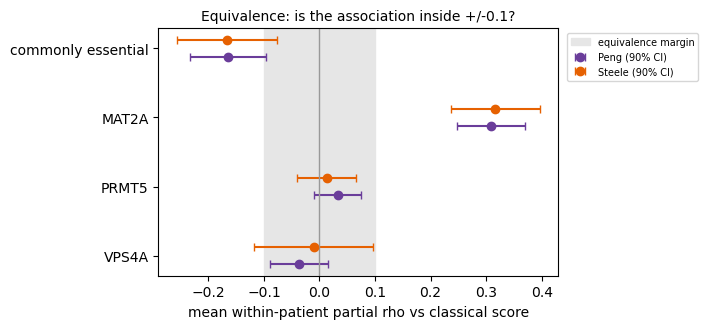

In [51]:
# ==========================================================================
# R6b · SUPPLEMENTARY TABLE S4 -- mean, 95% CI, Wilcoxon p + BH q, SD from the random null,
# empirical p + BH q, TOST equivalence (+/- EQ_MARGIN) with the 90% CI
#
# WHY BH within cohort over the three targets + commonly-essential control: those four tests make the
# claim on this axis. TOST uses the 90% CI against +/-0.10 (a correlation explaining 1% of variance).
# ==========================================================================

T3 = []
for _lab, _res, _null in [("Peng", res, null), ("Steele", s_res, s_null)]:
    keys = TARGETS + ["common_essential"]
    rows = [rev_row(k, _res[k], _null) for k in keys]
    qw = bh([r_["p"] for r_ in rows])
    qe = bh([r_["emp_p"] for r_ in rows])
    for r_, a, b in zip(rows, qw, qe):
        tt = tost(_res[r_["label"]])
        T3.append(dict(cohort=_lab, signature=r_["label"], n=r_["n"], mean_rho=r_["mean"],
                       ci95_lo=r_["ci_lo"], ci95_hi=r_["ci_hi"], wilcoxon_p=r_["p"], wilcoxon_q=a,
                       sd_from_random=r_["sd_null"], empirical_p=r_["emp_p"], empirical_q=b,
                       tost_p=tt["p_tost"], ci90_lo=tt["ci90"][0], ci90_hi=tt["ci90"][1],
                       equivalent_within_margin=tt["equivalent"]))
T3 = pd.DataFrame(T3)
T3.to_csv(rev_path("Table3_revised.csv"), index=False)
REV["table3"] = T3.round(5).to_dict(orient="records")
with pd.option_context("display.width", 200, "display.max_columns", 30):
    print(T3.round(4).to_string(index=False))
print("\nequivalence margin +/-{}: 'equivalent_within_margin' True only if the 90% CI is inside it."
      "\nwrote Table3_revised.csv".format(EQ_MARGIN))

if FIGURES:
    fig, ax = plt.subplots(figsize=(7.2, 3.4))
    for j, (_lab, col) in enumerate([("Peng", "#6A3D9A"), ("Steele", "#E66101")]):
        g = T3[T3["cohort"] == _lab].reset_index(drop=True)
        y = np.arange(len(g)) + (j - 0.5) * 0.25
        ax.errorbar(g["mean_rho"], y, xerr=[g["mean_rho"] - g["ci90_lo"], g["ci90_hi"] - g["mean_rho"]],
                    fmt="o", color=col, capsize=3, label="{} (90% CI)".format(_lab))
    ax.axvspan(-EQ_MARGIN, EQ_MARGIN, color="0.9", zorder=0, label="equivalence margin")
    ax.axvline(0, color="0.6", lw=1)
    ax.set_yticks(range(len(TARGETS) + 1)); ax.set_yticklabels(TARGETS + ["commonly essential"])
    ax.set_xlabel("mean within-patient partial rho vs classical score")
    ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    ax.set_title("Equivalence: is the association inside +/-{}?".format(EQ_MARGIN), fontsize=10)
    plt.tight_layout()
    _show("revR6_equivalence")

## R7 · Dependency-based positive controls, and a standardized Fig. 4b

*Reviewer must-fix 7. Methods → Controls; Results → Fig. 4.* The proliferation and classical
positive controls share genes with the programs they are tested against, so they show only that
the pipeline returns a signal where one is built in. Here **experimentally supported
subtype-selective dependencies** are passed through the **same DepMap-to-single-cell transfer**
as the targets (derivation → scoring → within-patient partial Spearman):

| control | source | expected direction vs the classical score |
|---|---|---|
| ***KRAS*** | classical PDAC lines are more *KRAS*-dependent than quasi-mesenchymal lines (Collisson et al. 2011, *Nat Med*) | **positive** |
| ***CDS2*** | synthetic-lethal dependency of cells with epithelial-to-mesenchymal transition signatures (Guo et al. 2025, *Cell Rep*) | **negative** (toward basal) |

*KRAS* has no passenger context, so its signature is derived across all lines and, separately,
within PDAC lines; *CDS2* is derived in *CDS1*-low lines (its paralog), mirroring the targets.
Before the single-cell test, DepMap is checked for the relationship each control relies on, and
each control signature is put through the same held-out validation as the targets. A control
counts as **detected** only if its 95% CI excludes zero in the expected direction **and** it
clears the random-gene null (empirical p < 0.05), the bar the targets are held to; whether its
DepMap premise holds is printed next to it, because a control whose premise fails in DepMap
cannot demonstrate sensitivity whatever it does in single cells.

**Fig. 4b, reconciled.** The original Fig. 4b values are differences in mean score in each
score's own units, which scale with each score's spread — so the +0.0292 for *MAT2A* is not
comparable with its partial ρ in Fig. 3. The axis is re-expressed two ways: a **standardized**
difference (divided by the within-patient SD of the score) and a **rank-based partial Spearman**
with the program score, both with patient-bootstrap CIs.

**Why the premise check comes first.** A positive control can only demonstrate sensitivity if the
dependency it relies on actually holds in DepMap; printing the premise beside each control stops a
control whose premise fails from being read as a pipeline failure, or as a success.

In [52]:
# ==========================================================================
# R7a · POSITIVE-CONTROL SIGNATURES -- DepMap checks, held-out validation, single-cell test
#
# WHY the DepMap premise is printed beside each control: a control whose premise fails in DepMap
# cannot demonstrate sensitivity, whatever it does in single cells.
# ==========================================================================

CLASSICAL_LINE = line_score(MOFFITT_CLASSICAL)
POS = {}
if "KRAS" in dep.columns:
    POS["KRAS (all lines)"] = ("KRAS", expr.index, +1)
    if IS_PDAC.sum() >= 20:
        POS["KRAS (PDAC lines)"] = ("KRAS", expr.index[IS_PDAC.values], +1)
if "CDS2" in dep.columns and "CDS1" in expr.columns:
    POS["CDS2 (CDS1-low lines)"] = ("CDS2", ctx_quantile("CDS1", LOW_Q), -1)

print("DEPMAP CHECKS FOR THE RELATIONSHIPS THE CONTROLS RELY ON\n")
if "KRAS" in dep.columns and IS_PDAC.sum() >= 10:
    pdl = expr.index[IS_PDAC.values].intersection(dep.index[dep["KRAS"].notna()])
    rho_k, p_k = spearmanr(dep.loc[pdl, "KRAS"], CLASSICAL_LINE.reindex(pdl))
    print("  KRAS Chronos vs line classical score, PDAC lines (n={}): rho {:+.3f}, p = {:.3g}  "
          "(negative = classical lines more KRAS-dependent)".format(len(pdl), rho_k, p_k))
    REV["kras_classical_depmap"] = dict(n=len(pdl), rho=float(rho_k), p=float(p_k))
if "CDS2" in dep.columns:
    al = dep.index[dep["CDS2"].notna()]
    rho_c = spearmanr(dep.loc[al, "CDS2"], EMT_LINE.reindex(al))[0]
    lowc = ctx_quantile("CDS1", LOW_Q).intersection(al)
    p_c = mannwhitneyu(dep.loc[lowc, "CDS2"], dep.loc[al.difference(lowc), "CDS2"])[1]
    print("  CDS2 Chronos vs line EMT score, all lines (n={}): rho {:+.3f}  "
          "(negative = mesenchymal lines more CDS2-dependent)".format(len(al), rho_c))
    print("  CDS2 Chronos, CDS1-low vs other lines: median {:+.3f} vs {:+.3f}, p = {:.2e}".format(
        dep.loc[lowc, "CDS2"].median(), dep.loc[al.difference(lowc), "CDS2"].median(), p_c))
    REV["cds2_depmap"] = dict(rho_emt=float(rho_c), p_cds1low=float(p_c))

# does the relationship each control relies on actually hold in DepMap? (a control whose premise
# fails cannot show sensitivity, whatever it does in single cells)
PREMISE = {}
if "kras_classical_depmap" in REV:
    PREMISE["KRAS"] = REV["kras_classical_depmap"]["rho"] < 0 and REV["kras_classical_depmap"]["p"] < 0.05
if "cds2_depmap" in REV:
    PREMISE["CDS2"] = REV["cds2_depmap"]["rho_emt"] < 0 and REV["cds2_depmap"]["p_cds1low"] < 0.05

print("\nPOSITIVE-CONTROL SIGNATURES THROUGH THE SAME TRANSFER\n")
POS_SIGS, REV["pos_ctrl"] = {}, {}
for name in list(POS):
    gene, lines, sign = POS[name][:3]          # [:3] so re-running this cell is safe
    genes = derive(gene, lines)
    POS_SIGS[name] = genes
    m, s, _, n = cv_eval(gene, lines, lambda tt, L: derive(tt, L))
    print("{} -- {} lines; held-out rho(score, Chronos) {:+.3f}, AUC {:.2f}".format(
        name, n, m["rho"], m["auc_quartile"]))
    col = "pc_" + "".join(ch for ch in name if ch.isalnum())[:16]
    rows = []
    for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null)]:
        score(_ad, genes, col)
        rc = ps_vs(_ad.obs, col)
        rb = ps_vs(_ad.obs, col, state_col="basal_score")
        rows += [rev_row("{} {} vs classical".format(_lab, name), rc, _null),
                 rev_row("{} {} vs basal".format(_lab, name), rb)]
        # detected = the 95% CI excludes zero in the expected direction AND the effect clears
        # the random-gene null (empirical p < 0.05) -- the same bar the targets are held to
        ci_ok = np.sign(mean_rho(rc)) == sign and (rows[-2]["ci_hi"] < 0 if sign < 0 else rows[-2]["ci_lo"] > 0)
        null_ok = rows[-2].get("emp_p", 1.0) < 0.05
        REV["pos_ctrl"]["{}|{}".format(_lab, name)] = dict(
            vs_classical=mean_rho(rc), vs_basal=mean_rho(rb), expected_sign=sign,
            ci_excludes_zero=bool(ci_ok), beyond_random_null=bool(null_ok),
            detected_in_expected_direction=bool(ci_ok and null_ok),
            premise_holds_in_depmap=PREMISE.get(gene), heldout_rho=float(m["rho"]))
    show_rev(rows)
    print("    expected direction vs classical: {} | DepMap premise holds: {}".format(
        "positive" if sign > 0 else "negative",
        {True: "yes", False: "NO", None: "not checked"}[PREMISE.get(gene)]))
    for l_ in ["Peng", "Steele"]:
        r_ = REV["pos_ctrl"]["{}|{}".format(l_, name)]
        print("    {:<7} CI excludes zero: {:<4} beyond random null: {:<4} -> detected: {}".format(
            l_, "yes" if r_["ci_excludes_zero"] else "no", "yes" if r_["beyond_random_null"] else "no",
            "YES" if r_["detected_in_expected_direction"] else "no"))
    print()
    POS[name] = (gene, lines, sign, col)

DEPMAP CHECKS FOR THE RELATIONSHIPS THE CONTROLS RELY ON

  KRAS Chronos vs line classical score, PDAC lines (n=44): rho +0.066, p = 0.669  (negative = classical lines more KRAS-dependent)
  CDS2 Chronos vs line EMT score, all lines (n=1140): rho -0.398  (negative = mesenchymal lines more CDS2-dependent)
  CDS2 Chronos, CDS1-low vs other lines: median -0.637 vs -0.174, p = 1.60e-81

POSITIVE-CONTROL SIGNATURES THROUGH THE SAME TRANSFER

KRAS (all lines) -- 1140 lines; held-out rho(score, Chronos) -0.277, AUC 0.72
                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  Peng KRAS (all lines) vs classical        24    0/24   +0.7242   [+0.6821, +0.7634]    0.0000    +8.3   0.0010
  Peng KRAS (all lines) vs basal            24    8/24   +0.0669   [-0.0189, +0.1483]    0.0691                 
  Steele KRAS (all lines) vs classical      14    0/14   +0.6956   [+0.6487, +0.7385]    0.0001    +8.9   0.0010
  Steele KRAS (all lines) vs 

cohort                 score     program  raw_diff  std_diff  std_lo  std_hi  rank_rho  rank_lo  rank_hi  n
  Peng         proliferation 4_cellcycle    0.2108    0.9576  0.8296  1.0864    0.4941   0.4251   0.5581 24
  Peng       classical score 8_classical    0.3509    1.0716  0.9652  1.1798    0.6396   0.5882   0.6876 24
  Peng                 VPS4A 8_classical    0.0047    0.0859 -0.0284  0.1997    0.1038   0.0440   0.1630 24
  Peng                 PRMT5 8_classical   -0.0082   -0.1863 -0.2688 -0.1084   -0.0791  -0.1257  -0.0343 24
  Peng                 MAT2A 8_classical    0.0292    0.5264  0.4191  0.6420    0.3652   0.3130   0.4184 24
  Peng      KRAS (all lines) 8_classical    0.0940    0.8592  0.7468  0.9770    0.5448   0.4877   0.5986 24
  Peng     KRAS (PDAC lines) 8_classical    0.0067    0.2266  0.1365  0.3237    0.1493   0.0983   0.1996 24
  Peng CDS2 (CDS1-low lines)     7_basal   -0.0990   -0.8419 -0.9273 -0.7535   -0.5424  -0.5857  -0.4946 24
Steele         proliferation

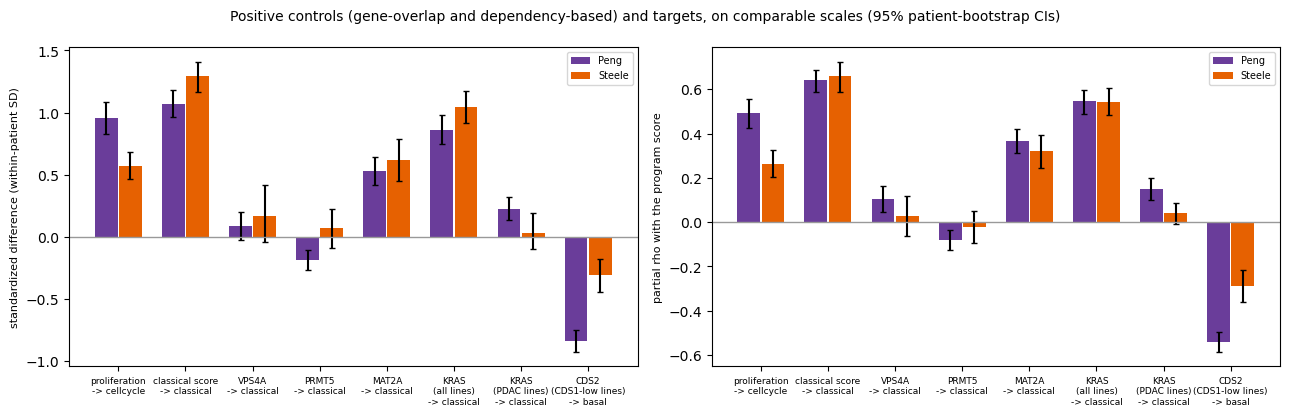

In [53]:
# ==========================================================================
# R7b · FIG. 4b RE-EXPRESSED -- raw (original units), standardized, and rank-based
# Steele program scores are computed here (section 8 scored programs in Peng only).
#
# WHY re-express Fig. 4b: raw score differences scale with each score's spread, so they are not
# comparable across signatures; standardised and rank versions are.
# ==========================================================================

for i, pname in enumerate(PROG_NAMES):
    top = [prog_genes[j] for j in np.argsort(programs[i])[::-1][:30] if prog_genes[j] in sraw]
    sc.tl.score_genes(steele, top, score_name="prog_" + pname, use_raw=True)


def program_restriction_std(obs, score_col, program, min_cells=MIN_CELLS):
    col = "prog_" + program
    raw_d, std_d = {}, {}
    for pat, g in obs.groupby("Patient", observed=True):
        if len(g) < min_cells:
            continue
        thr = g[col].quantile(0.66)
        hi, lo = g.loc[g[col] >= thr, score_col], g.loc[g[col] < thr, score_col]
        if len(hi) >= 10 and len(lo) >= 10:
            raw_d[pat] = hi.mean() - lo.mean()
            std_d[pat] = (hi.mean() - lo.mean()) / g[score_col].std()
    return raw_d, std_d


FIG4B = [("proliferation", "prolif", "4_cellcycle"),
         ("classical score", "classical_score", CLASSICAL_PROG)]
FIG4B += [(t, t + "_sig", CLASSICAL_PROG) for t in TARGETS]
for name, (gene, lines, sign, col) in POS.items():
    # each dependency control is tested against the program of the state it should mark
    FIG4B.append((name, col, CLASSICAL_PROG if sign > 0 else "7_basal"))

F4 = []
for _lab, _ad in [("Peng", mal), ("Steele", steele)]:
    for name, scol, prog in FIG4B:
        rd, sd_ = program_restriction_std(_ad.obs, scol, prog)
        rk = ps_vs(_ad.obs, scol, state_col="prog_" + prog)
        a, b, c = rev_row("", rd), rev_row("", sd_), rev_row("", rk)
        F4.append(dict(cohort=_lab, score=name, program=prog, raw_diff=a["mean"],
                       std_diff=b["mean"], std_lo=b["ci_lo"], std_hi=b["ci_hi"],
                       rank_rho=c["mean"], rank_lo=c["ci_lo"], rank_hi=c["ci_hi"], n=b["n"]))
F4 = pd.DataFrame(F4)
F4.to_csv(rev_path("Fig4b_revised.csv"), index=False)
REV["fig4b"] = F4.round(4).to_dict(orient="records")
print(F4.round(4).to_string(index=False))

if FIGURES:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, (val, lo, hi, lab) in zip(axes, [("std_diff", "std_lo", "std_hi", "standardized difference (within-patient SD)"),
                                             ("rank_rho", "rank_lo", "rank_hi", "partial rho with the program score")]):
        g = F4[F4["cohort"] == "Peng"].reset_index(drop=True)
        gs_ = F4[F4["cohort"] == "Steele"].reset_index(drop=True)
        x = np.arange(len(g))
        for off, gg, colr, cl in [(-0.18, g, "#6A3D9A", "Peng"), (0.18, gs_, "#E66101", "Steele")]:
            ax.bar(x + off, gg[val], 0.34, color=colr, label=cl,
                   yerr=[gg[val] - gg[lo], gg[hi] - gg[val]], capsize=2)
        ax.axhline(0, color="0.6", lw=1)
        ax.set_xticks(x)
        ax.set_xticklabels(["{}\n-> {}".format(s_.replace(" (", "\n("), p_.split("_", 1)[-1])
                            for s_, p_ in zip(g["score"], g["program"])],
                           fontsize=6.5)
        ax.set_ylabel(lab, fontsize=8)
        ax.legend(fontsize=7)
    fig.suptitle("Positive controls (gene-overlap and dependency-based) and targets, "
                 "on comparable scales (95% patient-bootstrap CIs)", fontsize=10)
    plt.tight_layout()
    _show("revR7_fig4b_standardized")

## R8 · The classical–basal axis, modelled explicitly

*Reviewer must-fix 8. Methods → Malignant Compartment and Subtype Scoring; Results.* Classical
and basal scores are already computed independently per cell (section 3/4); they anti-correlate
at −0.45 in Peng but only −0.03 in Steele, so a classical-high Steele cell need not be basal-low.
This section: every signature against the **basal** score; the classical association
**adjusted for the basal score**; the classical-minus-basal difference as an axis; four
within-patient groups (classical-only, basal-only, dual-high, dual-low, split at each patient's
median) with cell and patient counts and the *MAT2A* score in each; and, if supplied, the
published single-cell **scClassical / scBasal** signatures of Raghavan et al. 2021 as the axis.
If the cohorts still disagree after this, the manuscript presents Steele as a separate analysis.
R8c then puts the one new association R8a turns up -- the *VPS4A* signature rising with the basal
score -- through a battery of nulls and robustness tests, specified after the association was seen.

**Why split at each patient's own medians.** Every patient then contributes cells to every group
(classical-only, basal-only, dual-high, dual-low), so group differences cannot come from
differences between patients.

In [54]:
# ==========================================================================
# R8a · SIGNATURES vs BASAL, CLASSICAL | BASAL, CLASSICAL - BASAL, RAGHAVAN AXES
#
# WHY: the reviewers showed the two scores are not one axis in Steele, so every signature is tested
# against each score, with the other as a covariate, and against published single-cell signatures.
# ==========================================================================

for _ad in (mal, steele):
    _ad.obs["cls_minus_bas"] = _ad.obs["classical_score"] - _ad.obs["basal_score"]

_rag_cls = next((PRG_COL["Raghavan " + k] for k in RAGH if "class" in k.lower()), None)
_rag_bas = next((PRG_COL["Raghavan " + k] for k in RAGH if "basal" in k.lower()), None)
REV["axis"] = {}
for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null)]:
    print("\n{} -- {} cells; classical vs basal rho {:+.3f}\n".format(
        _lab, _ad.n_obs, spearmanr(_ad.obs["classical_score"], _ad.obs["basal_score"])[0]))
    rows = []
    for col in SIG_COLS:
        tests = [("vs classical (original)", ps_vs(_ad.obs, col)),
                 ("vs classical | basal adjusted", ps_vs(_ad.obs, col, covars=QC_COVARS + ["basal_score"])),
                 ("vs basal", ps_vs(_ad.obs, col, state_col="basal_score")),
                 ("vs basal | classical adjusted", ps_vs(_ad.obs, col, state_col="basal_score",
                                                         covars=QC_COVARS + ["classical_score"])),
                 ("vs classical minus basal", ps_vs(_ad.obs, col, state_col="cls_minus_bas"))]
        if _rag_cls:
            tests.append(("vs Raghavan scClassical", ps_vs(_ad.obs, col, state_col=_rag_cls)))
        if _rag_bas:
            tests.append(("vs Raghavan scBasal", ps_vs(_ad.obs, col, state_col=_rag_bas)))
        for tname, r in tests:
            rows.append(rev_row("{} {}".format(col.replace("_sig", ""), tname), r,
                                _null if tname.startswith("vs classical (") else None))
            REV["axis"]["{}|{}|{}".format(_lab, col, tname)] = r
    show_rev(rows)


Peng -- 11280 cells; classical vs basal rho -0.451

                                             n     neg      mean    95% CI (patients)         p      SD    emp p
  VPS4A vs classical (original)             24   15/24   -0.0365   [-0.0933, +0.0229]    0.1515    -0.6   0.4915
  VPS4A vs classical | basal adjusted       24   13/24   -0.0100   [-0.0660, +0.0442]    0.7898                 
  VPS4A vs basal                            24    0/24   +0.2944   [+0.2484, +0.3417]    0.0000                 
  VPS4A vs basal | classical adjusted       24    0/24   +0.2888   [+0.2436, +0.3357]    0.0000                 
  VPS4A vs classical minus basal            24   19/24   -0.1439   [-0.2057, -0.0814]    0.0005                 
  VPS4A vs Raghavan scClassical             24   14/24   -0.0190   [-0.0789, +0.0458]    0.2768                 
  VPS4A vs Raghavan scBasal                 24    0/24   +0.2769   [+0.2355, +0.3180]    0.0000                 
  PRMT5 vs classical (original)            


Peng -- dual-score groups (patients with >= 50 cells)

                cells  patients_with_>=10_cells  MAT2A_z_mean
subtype_group                                                
classical-only   3250                        24         0.120
basal-only       3250                        24        -0.040
dual-high        2376                        24         0.304
dual-low         2388                        24        -0.411
  dual-high minus basal-only MAT2A z (per patient): mean +0.482, 22/24 positive, p = 0.0000

Steele -- dual-score groups (patients with >= 50 cells)

                cells  patients_with_>=10_cells  MAT2A_z_mean
subtype_group                                                
classical-only   2172                        14         0.152
basal-only       2172                        14        -0.111
dual-high        2487                        14         0.489
dual-low         2491                        14        -0.524
  dual-high minus basal-only MAT2A z (per patient)

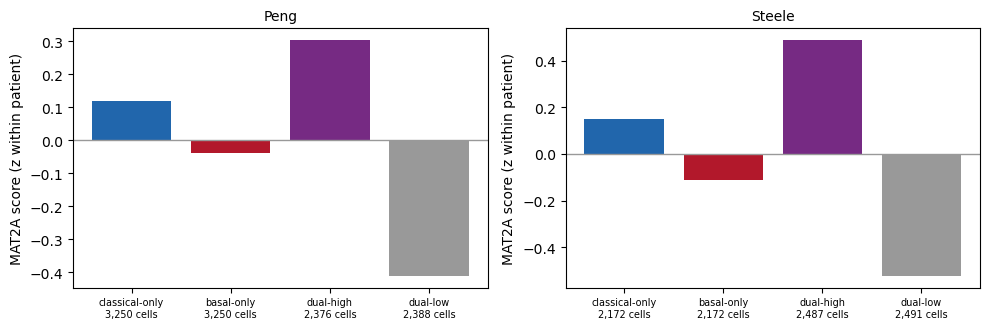

In [55]:
# ==========================================================================
# R8b · DUAL-SCORE GROUPS -- cells and patients per group, MAT2A score per group
# Split at each patient's median of each score; MAT2A as a within-patient z-score.
#
# WHY split at each patient's own medians: every patient contributes cells to every group, so group
# differences cannot come from differences between patients.
# ==========================================================================

GRP = ["classical-only", "basal-only", "dual-high", "dual-low"]
REV["dual_groups"] = {}
if FIGURES:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for j, (_lab, _ad) in enumerate([("Peng", mal), ("Steele", steele)]):
    o = _ad.obs
    ch = o.groupby("Patient", observed=True)["classical_score"].transform(lambda v: v > v.median())
    bh_ = o.groupby("Patient", observed=True)["basal_score"].transform(lambda v: v > v.median())
    grp = np.where(ch & ~bh_, "classical-only", np.where(~ch & bh_, "basal-only",
                   np.where(ch & bh_, "dual-high", "dual-low")))
    o["subtype_group"] = pd.Categorical(grp, categories=GRP)
    z = o.groupby("Patient", observed=True)["MAT2A_sig"].transform(lambda v: (v - v.mean()) / v.std())
    # cells per patient, as a plain number for every cell (Patient may be categorical)
    pats_ok = o.groupby("Patient", observed=True)["MAT2A_sig"].transform("size") >= MIN_CELLS
    tab = pd.DataFrame({
        "cells": o.loc[pats_ok, "subtype_group"].value_counts().reindex(GRP),
        "patients_with_>=10_cells": [int((o.loc[pats_ok & (o["subtype_group"] == g_)]
                                          .groupby("Patient", observed=True).size() >= 10).sum()) for g_ in GRP],
        "MAT2A_z_mean": [float(z[pats_ok & (o["subtype_group"] == g_)].mean()) for g_ in GRP]})
    # per-patient group means, so each patient counts once
    pm = pd.DataFrame({"z": z, "g": o["subtype_group"], "p": o["Patient"]})[pats_ok.values]
    pm = pm.groupby(["p", "g"], observed=True)["z"].mean().unstack()
    print("\n{} -- dual-score groups (patients with >= {} cells)\n".format(_lab, MIN_CELLS))
    print(tab.round(3).to_string())
    if {"dual-high", "basal-only"} <= set(pm.columns):
        d = (pm["dual-high"] - pm["basal-only"]).dropna()
        print("  dual-high minus basal-only MAT2A z (per patient): mean {:+.3f}, {}/{} positive, p = {:.4f}".format(
            d.mean(), int((d > 0).sum()), len(d), wilcoxon(d)[1] if len(d) >= 5 else np.nan))
    REV["dual_groups"][_lab] = tab.round(4).to_dict(orient="index")
    if FIGURES:
        ax = axes[j]
        ax.bar(range(4), tab["MAT2A_z_mean"], color=["#2166AC", "#B2182B", "#762A83", "0.6"])
        ax.set_xticks(range(4))
        ax.set_xticklabels(["{}\n{:,} cells".format(g_, int(c_)) for g_, c_ in zip(GRP, tab["cells"].fillna(0))], fontsize=7)
        ax.axhline(0, color="0.6", lw=1)
        ax.set_ylabel("MAT2A score (z within patient)")
        ax.set_title(_lab, fontsize=10)
if FIGURES:
    plt.tight_layout()
    _show("revR8_dual_groups")

### R8c · Is the *VPS4A*–basal association a finding? A test battery set after it was observed

R8a found something the original analysis never looked for: the *VPS4A* signature, which shows no
association with the classical score (and is statistically equivalent to zero on it in Peng, R6),
**rises with the basal score in every patient of both cohorts** (Peng +0.29, 0/24 patients
negative; Steele +0.27, 0/14), and it is the best-validated of the three signatures in held-out
DepMap lines (R4). An unplanned association needs the same battery the *MAT2A* association went
through, and more: the *MAT2A* signature turned out to track epithelial identity (R5), and the
*VPS4A* signature's top genes (*VGLL3*, *RUNX2*, *RND3*, *EMP1*, *PARVA*) suggest a mesenchymal
component, which this battery tests directly.

**This association was not anticipated.** It turned up in R8a, and every test below was specified
after it had been seen, so the manuscript reports it as an unanticipated finding, never as a
pre-specified one. The decision rule is Table 2's, the one the *MAT2A* association was judged by:
an effect **persists** when its 95% patient-bootstrap CI excludes zero and its Wilcoxon p < 0.05,
with the same sign as the full model. For every covariate and gene-removal test the fraction of the
full-model effect that is **kept** is printed as well, and those tests must keep at least one-third
of it (`R8C_MIN_KEPT = 0.33`; `None` applies Table 2's rule alone).

| test | challenge | required to pass |
|---|---|---|
| **Random null** | *VPS4A*-sized random gene sets on the basal axis | ≥ 2 SD above the null mean, empirical p < 0.05 |
| **Expression-matched null** | each signature gene swapped for a gene of similar mean expression | ≥ 2 SD, empirical p < 0.05 |
| **Variability/detection-matched null** | matched on mean, variance and detection rate | ≥ 2 SD, empirical p < 0.05 |
| **Covariance-matched null** | random sets with the signature's mean gene–gene correlation | ≥ 2 SD, empirical p < 0.05 |
| **Commonly-essential head-to-head** | *VPS4A* minus the commonly-essential control, per patient | *VPS4A* higher, Wilcoxon p < 0.05 |
| **Classical adjustment** | classical score as a covariate | persists, keeps at least one-third |
| **Circularity** | genes shared with Moffitt basal or Raghavan scBasal removed | persists, keeps at least one-third |
| **Proliferation** | proliferation score as a covariate | persists, keeps at least one-third |
| **Program adjustment** | mesenchymal, fibroblast, epithelial and secretory programs as covariates, together | persists, keeps at least one-third |
| **Mesenchymal-gene removal** | mesenchymal-identity genes dropped; and excluded before derivation (refilled) | both persist, keep at least one-third |
| **Single-gene** | each gene dropped in turn | no gene shifts the mean by > 30% |
| **Scoring method** | AUCell-style rank scoring | persists |
| **Published axis** | Raghavan scBasal as the state score | persists |
| **Derivation** | signature re-derived with lineage held constant; other cut-offs; copy-loss lines | lineage-held persists; ≥ 3/4 of the others persist |
| **High-confidence malignant cells** | CNV-positive, doublet-filtered cells only (R2) | persists |
| **Doublet-flagged cells removed** | R1 flags removed | persists |

*Supporting, not required:* whether basal-like **cell lines** are more *VPS4A*-dependent in DepMap
(the premise the single-cell result would imply); how many of the signature's genes individually
rise with the basal score; and whether the mesenchymal-free signatures still predict *VPS4A*
dependency in held-out lines. The commonly-essential control's and the other targets' basal
associations are printed alongside for scale.

**On the one-third retention bar.** It was set after the association was observed, as stated
above and in the manuscript. The retained fraction is printed for every test, so a reader can
apply any other bar.

In [56]:
# ==========================================================================
# R8c-1 · VPS4A ON THE BASAL AXIS -- THE FOUR NULLS (cached per cohort)
# One scoring pass per null gene set, evaluated on two axes at once: the basal score, and the
# basal score with the classical score as an extra covariate. FastPS gives exactly ps_vs's
# numbers (checked below) but ranks the state and builds the covariate projection once per
# patient, so each null set costs one scoring and one ranking. ~10-30 min per cohort at
# N_NULL_R8C = 1000; cached, so a REV_FORCE = False re-run reads it back.
#
# WHY four nulls rebuilt on the basal axis: the VPS4A association is held to the same nulls as MAT2A,
# recomputed on the axis it was found on. POST HOC: this battery was specified after the association
# was observed in R8a, and the manuscript says so.
# ==========================================================================

N_NULL_R8C = N_NULL                        # null sets per null type (the paper's 1000)
R8C_MIN_KEPT = 0.33                        # covariate / gene-removal tests must keep at least this
                                           # fraction of the full-model effect (None = Table 2's rule,
                                           # the effect persists, alone)
R8C_TARGET = "VPS4A"
R8C_AXES = {"basal": ("basal_score", QC_COVARS),
            "basal | classical adjusted": ("basal_score", QC_COVARS + ["classical_score"])}


class FastPS:
    """ps_vs for many score vectors against ONE state column and covariate set. Per patient
    the design [1, ranked covariates], its pseudo-inverse and the residualised state ranks are
    computed once; a new score then costs one ranking and one projection."""

    def __init__(self, obs, state_col, covars=None, min_cells=MIN_CELLS):
        covars = QC_COVARS if covars is None else covars
        self.parts = []
        for pat, g in obs.groupby("Patient", observed=True):
            if len(g) < min_cells:
                continue
            X = np.column_stack([np.ones(len(g))] + [rankdata(g[q].values) for q in covars])
            P = np.linalg.pinv(X)
            c = rankdata(g[state_col].values)
            rc = c - X @ (P @ c)
            if rc.std() < 1e-9:
                continue
            self.parts.append((pat, obs.index.get_indexer(g.index), X, P, rc))

    def __call__(self, values):
        out = {}
        for pat, idx, X, P, rc in self.parts:
            y = rankdata(values[idx])
            ry = y - X @ (P @ y)
            if ry.std() < 1e-9:
                continue
            out[pat] = float(np.corrcoef(ry, rc)[0, 1])
        return out


def random_sets(present, size, n, seed):
    """Random gene sets of the signature's size, from the sorted gene universe (section 11)."""
    r = np.random.default_rng(seed)
    pool = sorted(present)
    return [sorted(r.choice(pool, size=size, replace=False)) for _ in range(n)]


def expression_matched_sets(ad, template, n, seed):
    """Section 11's expression-matched null, as gene sets: each template gene is swapped for a
    random gene whose mean expression is within +/-20% of its own."""
    r = np.random.default_rng(seed)
    gm = pd.Series(np.asarray(ad.raw.X.mean(axis=0)).ravel(), index=[str(g) for g in ad.raw.var_names])
    cands = {g: gm[(gm > gm[g] * 0.8) & (gm < gm[g] * 1.2)].index for g in template if g in gm.index}
    out = []
    for _ in range(n):
        picked = [str(r.choice(c)) for g, c in cands.items() if len(c)]
        out.append(sorted(set(picked)))
    return out


def score_sets(ad, sets, fps, label=""):
    """Score every gene set once; the mean within-patient rho on every axis in fps."""
    out = {k: np.empty(len(sets)) for k in fps}
    t0 = time.time()
    for i, gs in enumerate(sets):
        sc.tl.score_genes(ad, gs, score_name="_n8", use_raw=True)
        v = ad.obs["_n8"].values
        for k, f in fps.items():
            out[k][i] = mean_rho(f(v))
        if (i + 1) % 250 == 0:
            print("      {} {}/{} ({:.0f} s)".format(label, i + 1, len(sets), time.time() - t0))
    del ad.obs["_n8"]
    return out


R8C_NULL_KINDS = ["random", "expression-matched", "variability/detection-matched", "covariance-matched"]
R8C = {"nulls": {}, "fps": {}}
for _lab, _ad, _present in [("Peng", mal, raw), ("Steele", steele, sraw)]:
    fps = {k: FastPS(_ad.obs, s_, c_) for k, (s_, c_) in R8C_AXES.items()}
    R8C["fps"][_lab] = fps
    # guard: FastPS must reproduce ps_vs exactly
    _a = mean_rho(fps["basal"](_ad.obs[R8C_TARGET + "_sig"].values))
    _b = mean_rho(ps_vs(_ad.obs, R8C_TARGET + "_sig", state_col="basal_score"))
    assert abs(_a - _b) < 1e-9, "FastPS does not reproduce ps_vs ({} vs {})".format(_a, _b)
    tmpl = [g for g in signatures[R8C_TARGET] if g in _present]
    cache = rev_path("vps4a_basal_nulls_{}.npz".format(_lab.lower()))
    if need_rev(cache):
        print("{}: {} null sets of each kind, {} genes per set".format(_lab, N_NULL_R8C, len(tmpl)))
        makers = {"random": lambda: random_sets(_present, len(tmpl), N_NULL_R8C, SEED + 21),
                  "expression-matched": lambda: expression_matched_sets(_ad, tmpl, N_NULL_R8C, SEED + 22),
                  "variability/detection-matched": lambda: variability_matched_sets(_ad, tmpl, N_NULL_R8C, seed=SEED + 23),
                  "covariance-matched": lambda: covariance_matched_sets(_ad, tmpl, N_NULL_R8C, seed=SEED + 24)}
        store = {}
        for kind in R8C_NULL_KINDS:
            print("    {} ...".format(kind))
            res_k = score_sets(_ad, makers[kind](), fps, label=kind)
            for ax_, arr in res_k.items():
                store["{}__{}".format(kind, ax_)] = arr
        np.savez(cache, **store)
    z = np.load(cache)
    R8C["nulls"][_lab] = {(k.split("__")[0], k.split("__")[1]): z[k] for k in z.files}

# observed values and distance from each null
R8C["observed"] = {}
NULL_TAB = []
for _lab, _ad in [("Peng", mal), ("Steele", steele)]:
    for ax_ in R8C_AXES:
        obs_v = mean_rho(R8C["fps"][_lab][ax_](_ad.obs[R8C_TARGET + "_sig"].values))
        R8C["observed"][(_lab, ax_)] = obs_v
        for kind in R8C_NULL_KINDS:
            nd = R8C["nulls"][_lab][(kind, ax_)]
            sd_ = sd_from(obs_v, nd)
            NULL_TAB.append(dict(cohort=_lab, axis=ax_, null=kind, observed=obs_v, null_mean=nd.mean(),
                                 null_sd=nd.std(), sd=sd_, emp_p=emp_p(obs_v, nd),
                                 passes=bool(sd_ >= 2 and emp_p(obs_v, nd) < 0.05)))
NULL_TAB = pd.DataFrame(NULL_TAB)
NULL_TAB.to_csv(rev_path("vps4a_basal_nulls.csv"), index=False)

# every signature on the basal axis, against the same random null (the null is signature-size
# matched, not signature-specific, so it serves all four, as section 11's does on the classical axis)
print("\nEVERY SIGNATURE vs BASAL SCORE -- distance from the basal-axis random null (manuscript Table 3)\n")
BASAL_T3 = []
for _lab, _ad in [("Peng", mal), ("Steele", steele)]:
    nd = R8C["nulls"][_lab][("random", "basal")]
    for col in SIG_COLS:
        r_ = rev_row(col, ps_vs(_ad.obs, col, state_col="basal_score"), nd)
        BASAL_T3.append(dict(cohort=_lab, signature=col.replace("_sig", ""), n=r_["n"], mean=r_["mean"],
                             ci_lo=r_["ci_lo"], ci_hi=r_["ci_hi"], p=r_["p"], sd_from_random=r_["sd_null"],
                             emp_p=r_["emp_p"]))
BASAL_T3 = pd.DataFrame(BASAL_T3)
BASAL_T3.to_csv(rev_path("Table3_basal_rows.csv"), index=False)
REV["basal_table3"] = BASAL_T3.round(4).to_dict(orient="records")
print(BASAL_T3.round(4).to_string(index=False))
print("\nVPS4A SIGNATURE vs BASAL SCORE -- distance from each null (required: the 'basal' axis)\n")
with pd.option_context("display.width", 200):
    print(NULL_TAB.round(4).to_string(index=False))

Peng: 1000 null sets of each kind, 96 genes per set
    random ...
      random 250/1000 (106 s)
      random 500/1000 (213 s)
      random 750/1000 (320 s)
      random 1000/1000 (426 s)
    expression-matched ...
      expression-matched 250/1000 (110 s)
      expression-matched 500/1000 (220 s)
      expression-matched 750/1000 (330 s)
      expression-matched 1000/1000 (440 s)
    variability/detection-matched ...
      variability/detection-matched 250/1000 (110 s)
      variability/detection-matched 500/1000 (220 s)
      variability/detection-matched 750/1000 (330 s)
      variability/detection-matched 1000/1000 (440 s)
    covariance-matched ...
    covariance target +0.0187; null sets within +/-0.005 of it: 100% (median gap 0.0049)
      covariance-matched 250/1000 (107 s)
      covariance-matched 500/1000 (214 s)
      covariance-matched 750/1000 (320 s)
      covariance-matched 1000/1000 (427 s)
Steele: 1000 null sets of each kind, 96 genes per set
    random ...
      rando

In [57]:
# ==========================================================================
# R8c-2 · VPS4A ON THE BASAL AXIS -- ROBUSTNESS TESTS, BOTH COHORTS
# Every test is named; each row: per-patient rhos -> mean, 95% patient-bootstrap CI, Wilcoxon p,
# and the fraction of the full-model effect kept. Pass rules are the ones fixed in the table.
#
# WHY these tests: each removes one alternative explanation (classical score, proliferation,
# mesenchymal/fibroblast/epithelial/secretory programs, shared genes, mesenchymal-identity genes,
# scoring method, published axis, derivation choices, non-malignant cells, doublets). The fraction
# of the effect retained is printed for every test so any bar can be applied.
# ==========================================================================

_sigcol = R8C_TARGET + "_sig"
_ctx_v = ctx_quantile(TARGET_CONTEXT[R8C_TARGET], LOW_Q)

# ---- gene sets the tests need, fixed without looking at the single-cell result -------------
BASAL_REF = set(MOFFITT_BASAL) | set(next((v for k, v in RAGH.items() if "basal" in k.lower()), []))
CLASS_REF = set(MOFFITT_CLASSICAL) | set(next((v for k, v in RAGH.items() if "class" in k.lower()), []))
_hall = []
if LIBS is not None:
    _hk = [k for k in LIBS.get("MSigDB_Hallmark_2020", {}) if "epithelial mesenchymal" in k.lower()]
    _hall = sorted(set(LIBS["MSigDB_Hallmark_2020"][_hk[0]])) if _hk else []
MESENCHYMAL_PROGRAM = _hall if _hall else EMT_MARKERS
# mesenchymal identity, defined the way R5c defines epithelial identity: |rho| > EPI_CORR_MAX
# with the DepMap EMT-marker score across all lines, plus the marker genes themselves
_emt_corr = corr_with(expr, EMT_LINE.values)
MES_IDENTITY = set(_emt_corr.index[_emt_corr.abs() > EPI_CORR_MAX]) | set(EMT_MARKERS) | set(_hall)
_vsig = signatures[R8C_TARGET]
print("{} signature: {} genes | shared with basal references: {} | with classical references: {}".format(
    R8C_TARGET, len(_vsig), sorted(set(_vsig) & BASAL_REF) or "none", sorted(set(_vsig) & CLASS_REF) or "none"))
print("mesenchymal program: {} ({} genes) | mesenchymal-identity genes: {:,}, of which in the signature: {} -> {}".format(
    "MSigDB Hallmark EMT" if _hall else "EMT_MARKERS", len(MESENCHYMAL_PROGRAM), len(MES_IDENTITY),
    len(set(_vsig) & MES_IDENTITY), ", ".join(sorted(set(_vsig) & MES_IDENTITY))))

# fibroblast program = section 5's 2_CAF program (top 30 genes), scored the same way in both cohorts
_caf_i = PROG_NAMES.index("2_CAF")
_caf_top = [prog_genes[j] for j in np.argsort(programs[_caf_i])[::-1][:30]]
R8C_PROG = {"mesenchymal": "r8c_mesenchymal", "fibroblast (2_CAF)": "r8c_fibroblast"}
for _ad in (mal, steele):
    score(_ad, MESENCHYMAL_PROGRAM, "r8c_mesenchymal")
    score(_ad, _caf_top, "r8c_fibroblast")
for n_ in ("epithelial differentiation", "secretory (exocytosis)", "epithelial identity markers"):
    if n_ in PRG_COL:
        R8C_PROG[n_] = PRG_COL[n_]

# alternative signatures (DepMap side; same for both cohorts)
_mes_dropped = [g for g in _vsig if g not in MES_IDENTITY]
_mes_refilled = derive(R8C_TARGET, _ctx_v, exclude=MES_IDENTITY)
_circ_free = [g for g in _vsig if g not in BASAL_REF]
_lin_held = derive(R8C_TARGET, _ctx_v, lineage_held=True)
_other_deriv = {}
for _vname, (_fn, _kw) in VARIANTS.items():
    if _vname.startswith("original") or "lineage" in _vname or "intact" in _vname:
        continue                                  # intact lines are the opposite context, not a derivation of it
    _ctx = _fn(TARGET_CONTEXT[R8C_TARGET])
    if _n_ctx(R8C_TARGET, _ctx) >= MIN_CTX_LINES:
        _other_deriv[_vname] = derive(R8C_TARGET, _ctx, **_kw)


def _rescored(ad, genes, covars=None, state="basal_score", cells=None):
    """Score a gene list, test it against the basal axis, clean up."""
    score(ad, genes, "_r8")
    o = ad.obs if cells is None else ad.obs[cells]
    r = ps_vs(o, "_r8", state_col=state, covars=covars)
    del ad.obs["_r8"]
    return r


def _summ(r, full_mean=None):
    v = _vals(r)
    if len(v) < 3:
        return dict(n=len(v), mean=np.nan, lo=np.nan, hi=np.nan, p=np.nan, kept=np.nan)
    lo, hi = boot_ci(v)
    return dict(n=len(v), mean=float(v.mean()), lo=lo, hi=hi, p=float(wilcoxon(v)[1]),
                kept=float(v.mean() / full_mean) if full_mean else np.nan)


def _persists(s):
    return bool(np.isfinite(s["mean"]) and s["lo"] > 0 and s["p"] < 0.05)


def _retains(s):
    """Persists, plus the optional kept-fraction bar R8C_MIN_KEPT (None = Table 2's rule only)."""
    return _persists(s) and (R8C_MIN_KEPT is None or s["kept"] >= R8C_MIN_KEPT)


R8C_ROWS = []          # one row per (cohort, test, variant)
for _lab, _ad, _null in [("Peng", mal, null), ("Steele", steele, s_null)]:
    o = _ad.obs
    full = ps_vs(o, _sigcol, state_col="basal_score")
    fm = mean_rho(full)

    def add(test, variant, r, rule, required=True, note="", show_kept=True):
        s = _summ(r, fm if show_kept else None) if r is not None else \
            dict(n=0, mean=np.nan, lo=np.nan, hi=np.nan, p=np.nan, kept=np.nan)
        if r is None:
            status = "not run"
        elif len(r) < 3:                          # too few patients with enough cells to test
            status, note = "not run", (note + "; " if note else "") + "fewer than 3 patients with >= {} cells".format(MIN_CELLS)
        elif rule == "retains":
            status = "pass" if _retains(s) else "fail"
        elif rule == "persists":
            status = "pass" if _persists(s) else "fail"
        else:
            status = rule                         # decided by the caller
        R8C_ROWS.append(dict(cohort=_lab, test=test, variant=variant, required=required, rule=rule,
                             status=status, note=note, **s))

    add("Full model", "VPS4A vs basal, QC covariates", full, "persists", required=False)
    # head-to-head and the other signatures, for scale
    ce = ps_vs(o, "CE_sig", state_col="basal_score")
    hh = paired_vs(full, ce)
    add("Commonly-essential head-to-head", "VPS4A minus commonly-essential (per patient)",
        {p: full[p] - ce[p] for p in set(full) & set(ce)},
        "pass" if (hh["mean_diff"] > 0 and hh["p"] < 0.05) else "fail",
        note="{} of {} patients VPS4A higher, p = {:.2g}".format(hh["n"] - hh["n_more_neg"], hh["n"], hh["p"]),
        show_kept=False)
    for t_ in [t for t in TARGETS if t != R8C_TARGET] + ["CE"]:
        add("For scale", "{} vs basal".format(t_), ps_vs(o, t_ + "_sig", state_col="basal_score"),
            "persists", required=False, show_kept=False)
    # covariates
    add("Classical adjustment", "+ classical score", ps_vs(o, _sigcol, "basal_score", QC_COVARS + ["classical_score"]), "retains")
    add("Proliferation", "+ proliferation score", ps_vs(o, _sigcol, "basal_score", QC_COVARS + ["prolif"]), "retains")
    for n_, c_ in R8C_PROG.items():
        add("Program adjustment", "+ " + n_, ps_vs(o, _sigcol, "basal_score", QC_COVARS + [c_]), "retains", required=False)
    add("Program adjustment", "+ all programs together",
        ps_vs(o, _sigcol, "basal_score", QC_COVARS + list(R8C_PROG.values())), "retains")
    # gene removal
    _ov = sorted(set(_vsig) & BASAL_REF)
    if _ov:
        add("Circularity", "{} shared gene(s) removed".format(len(_ov)), _rescored(_ad, _circ_free), "retains",
            note=", ".join(_ov))
    else:
        add("Circularity", "no gene shared with the basal references", full, "pass", note="nothing to remove")
    add("Mesenchymal-gene removal", "dropped ({} genes left)".format(len(_mes_dropped)),
        _rescored(_ad, _mes_dropped) if len(_mes_dropped) >= 20 else None, "retains",
        note="" if len(_mes_dropped) >= 20 else "fewer than 20 genes left -- the signature is mostly mesenchymal-identity genes")
    add("Mesenchymal-gene removal", "excluded before derivation, refilled", _rescored(_ad, _mes_refilled), "retains")
    # single-gene (leave-one-out), with FastPS
    fb = R8C["fps"][_lab]["basal"]
    genes_p = [g for g in _vsig if g in set(_ad.raw.var_names)]
    loo = []
    for g in genes_p:
        sc.tl.score_genes(_ad, [x for x in genes_p if x != g], score_name="_lo8", use_raw=True)
        loo.append((g, mean_rho(fb(_ad.obs["_lo8"].values)) - fm))
    del _ad.obs["_lo8"]
    loo.sort(key=lambda x: abs(x[1]), reverse=True)
    worst = abs(loo[0][1]) / abs(fm)
    add("Single-gene", "worst single-gene drop: {}".format(loo[0][0]), full,
        "pass" if worst <= 0.30 else "fail",
        note="{:.0f}% of the effect; next: {}".format(100 * worst, ", ".join(
            "{} {:.0f}%".format(g, 100 * abs(d) / abs(fm)) for g, d in loo[1:4])), show_kept=False)
    # scoring method, published axis
    _ad.obs["_auc8"] = manual_aucell(_ad, genes_p)
    add("Scoring method", "AUCell-style rank score", ps_vs(o, "_auc8", state_col="basal_score"), "persists")
    del _ad.obs["_auc8"]
    add("Published axis", "Raghavan scBasal as the state score",
        ps_vs(o, _sigcol, state_col=_rag_bas) if _rag_bas else None, "persists")
    # derivation
    add("Derivation", "lineage held constant", _rescored(_ad, _lin_held), "persists")
    for vn, gl in _other_deriv.items():
        add("Derivation", vn, _rescored(_ad, gl), "persists", required=False)
    # cell subsets (need the full single-cell files: R1, R2)
    hc = o["hc_malignant"].astype(bool).values if "hc_malignant" in o else None
    add("High-confidence malignant cells", "CNV-positive, doublet-filtered",
        ps_vs(o[hc], _sigcol, state_col="basal_score") if hc is not None else None, "persists")
    df_ = o["doublet_flag"].astype(bool).values if "doublet_flag" in o else None
    add("Doublet-flagged cells removed", "R1 flags removed",
        ps_vs(o[~df_], _sigcol, state_col="basal_score") if df_ is not None else None, "persists")

R8C_TAB = pd.DataFrame(R8C_ROWS)

# the derivation rule: lineage-held is required (above); >= 3/4 of the other derivations must persist
for _lab in ("Peng", "Steele"):
    oth = R8C_TAB[(R8C_TAB["cohort"] == _lab) & (R8C_TAB["test"] == "Derivation") & ~R8C_TAB["required"]]
    k, n = int((oth["status"] == "pass").sum()), len(oth)
    R8C_ROWS.append(dict(cohort=_lab, test="Derivation", variant="other derivations: {}/{} persist".format(k, n),
                         required=True, rule="3/4", status=("pass" if n and k >= np.ceil(0.75 * n) else
                                                             "not run" if not n else "fail"),
                         note="", n=n, mean=np.nan, lo=np.nan, hi=np.nan, p=np.nan, kept=np.nan))
# the four nulls (basal axis) and their pass/fail, from R8c-1
for _, r_ in NULL_TAB[NULL_TAB["axis"] == "basal"].iterrows():
    R8C_ROWS.append(dict(cohort=r_["cohort"], test=r_["null"].capitalize() + " null", variant="basal axis",
                         required=True, rule="2 SD", status="pass" if r_["passes"] else "fail",
                         note="{:+.1f} SD, empirical p {:.4f}".format(r_["sd"], r_["emp_p"]),
                         n=np.nan, mean=r_["observed"], lo=np.nan, hi=np.nan, p=np.nan, kept=np.nan))
R8C_TAB = pd.DataFrame(R8C_ROWS)
R8C_TAB.to_csv(rev_path("vps4a_basal_battery.csv"), index=False)

for _lab in ("Peng", "Steele"):
    g = R8C_TAB[R8C_TAB["cohort"] == _lab]
    print("\n{} -- VPS4A SIGNATURE vs BASAL SCORE\n".format(_lab))
    print("  {:<37}{:<46}{:>4}{:>9}{:>21}{:>9}{:>7}  {:<8} {}".format(
        "test", "variant", "n", "mean", "95% CI (patients)", "p", "kept", "status", "note"))
    for _, r_ in g.iterrows():
        ci = "[{:+.3f}, {:+.3f}]".format(r_["lo"], r_["hi"]) if np.isfinite(r_["lo"]) else ""
        print("  {:<37}{:<46}{:>4}{:>9}{:>21}{:>9}{:>7}  {:<8} {}".format(
            r_["test"][:36], str(r_["variant"])[:45],
            "" if not np.isfinite(r_["n"]) else int(r_["n"]),
            "" if not np.isfinite(r_["mean"]) else "{:+.3f}".format(r_["mean"]), ci,
            "" if not np.isfinite(r_["p"]) else "{:.4f}".format(r_["p"]),
            "" if not np.isfinite(r_["kept"]) else "{:.0%}".format(r_["kept"]),
            (r_["status"].upper() if r_["required"] else r_["status"]), r_["note"]))
print("\n(UPPER-CASE status = a required test; lower-case = reported for context)")

VPS4A signature: 100 genes | shared with basal references: ['EMP1'] | with classical references: none
mesenchymal program: MSigDB Hallmark EMT (200 genes) | mesenchymal-identity genes: 1,663, of which in the signature: 26 -> ARF4, BDNF, CD59, CYBRD1, EVI5, FAM114A1, FSTL1, GNG12, GPC1, LAMA4, LAYN, PARVA, PRNP, PTPN14, QSOX1, RTN4, SDC4, SDCBP, SNX7, SOCS5, SPOCD1, TIMP2, TMEM43, UBE2E3, VAMP3, YIPF5

Peng -- VPS4A SIGNATURE vs BASAL SCORE

  test                                 variant                                          n     mean    95% CI (patients)        p   kept  status   note
  Full model                           VPS4A vs basal, QC covariates                   24   +0.294     [+0.248, +0.342]   0.0000   100%  pass     
  Commonly-essential head-to-head      VPS4A minus commonly-essential (per patient)    24   +0.503     [+0.394, +0.609]   0.0000         PASS     23 of 24 patients VPS4A higher, p = 3.6e-07
  For scale                            PRMT5 vs basal              

DEPMAP -- line basal score vs VPS4A Chronos (prediction: rho < 0)

  lines                                           n             rho (p)        lineage held (p)    lineage + EMT held (p)
  VPS4B-low lines (the signature's context)     285      -0.195 (0.00095)        -0.084 (0.18)          -0.136 (0.029)
  all lines                                    1140      -0.144 (1.1e-06)        -0.054 (0.07)          -0.071 (0.018)
  VPS4B copy-loss lines                         362      +0.100 (0.057)        +0.115 (0.034)          +0.071 (0.19)
  PDAC lines                                     44      -0.171 (0.27)           n/a           -0.301 (0.05)

  -> DepMap premise (does NOT support): basal-like lines are not shown to be more VPS4A-dependent within lineages in the VPS4B-low context

PER-GENE breadth: each signature gene's own expression vs the basal score

  Peng: 74 of 95 detected genes rise with the basal score (78%); top 10: CD59* +0.19, EMP1 +0.18, MYOF +0.16, YWHAZ +0.15, RND3 +0.

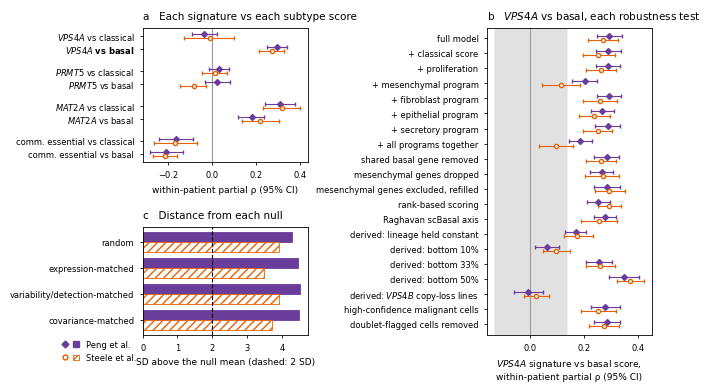

In [58]:
# ==========================================================================
# R8c-3 · SUPPORTING EVIDENCE, FIGURE AND VERDICT
# (a) DepMap: are basal-like lines more VPS4A-dependent? Lower Chronos = more dependent, so the
#     single-cell result predicts a NEGATIVE rho between a line's basal score and its VPS4A Chronos.
#     Moffitt basal genes mark squamous lineages across DepMap, so the lineage-held value is the
#     one that bears on the question; PDAC lines alone are few.
# (b) per-gene breadth on the basal axis; (c) held-out DepMap prediction of the mesenchymal-free
#     signatures (R4's CV). None of these is required for the verdict.
#
# WHY the DepMap check: if basal-like lines were not more VPS4A-dependent in DepMap, the single-cell
# association would rest on transcription alone; the result is printed whichever way it falls.
# ==========================================================================

def _partial_rank(x, y, Z=None):
    """Spearman of x and y, optionally with both rank vectors residualised on Z (columns =
    covariates, already numeric). p from the t distribution on n - k - 2 df."""
    ok = x.notna() & y.notna()
    x, y = x[ok], y[ok]
    rx, ry = rankdata(x).astype(float), rankdata(y).astype(float)
    k = 0
    if Z is not None:
        Zx = Z.loc[x.index].astype(float)
        Z = np.column_stack([np.ones(len(x)), Zx.fillna(Zx.mean()).values])
        Pz = Z @ np.linalg.pinv(Z)
        rx, ry = rx - Pz @ rx, ry - Pz @ ry
        k = np.linalg.matrix_rank(Z) - 1
    r = float(np.corrcoef(rx, ry)[0, 1])
    df = len(x) - k - 2
    p = float(2 * tdist.sf(abs(r) * np.sqrt(df / max(1e-12, 1 - r ** 2)), df)) if df > 0 else np.nan
    return r, p, len(x)


BAS_LINE, CLS_LINE = line_score(MOFFITT_BASAL), line_score(MOFFITT_CLASSICAL)
_ylin = dep[R8C_TARGET]
_sets = {"VPS4B-low lines (the signature's context)": _ctx_v, "all lines": expr.index}
if DELETED and "VPS4B" in DELETED:
    _sets["VPS4B copy-loss lines"] = ctx_deleted("VPS4B")
_sets["PDAC lines"] = expr.index[IS_PDAC.values]
DEPMAP_BASAL = []
print("DEPMAP -- line basal score vs VPS4A Chronos (prediction: rho < 0)\n")
print("  {:<44}{:>5}{:>20}{:>24}{:>26}".format("lines", "n", "rho (p)", "lineage held (p)", "lineage + EMT held (p)"))
for nm, L in _sets.items():
    L = pd.Index(L).intersection(_ylin.dropna().index)
    if len(L) < 10:
        print("  {:<44}{:>5}  too few".format(nm, len(L)))
        continue
    x, y = BAS_LINE.reindex(L), _ylin.reindex(L)
    r0 = _partial_rank(x, y)
    lin = pd.get_dummies(LINEAGE.reindex(L).astype(str), drop_first=True).astype(float)
    r1 = _partial_rank(x, y, lin) if lin.shape[1] and nm != "PDAC lines" else (np.nan, np.nan, len(L))
    Z2 = pd.concat([lin, EMT_LINE.reindex(L).rename("emt")], axis=1) if nm != "PDAC lines" else EMT_LINE.reindex(L).to_frame()
    r2_ = _partial_rank(x, y, Z2)
    DEPMAP_BASAL.append(dict(lines=nm, n=len(L), rho=r0[0], p=r0[1], rho_lineage=r1[0], p_lineage=r1[1],
                             rho_lineage_emt=r2_[0], p_lineage_emt=r2_[1]))
    print("  {:<44}{:>5}{:>+12.3f} ({:.2g}){:>14} {}{:>16} {}".format(
        nm, len(L), r0[0], r0[1],
        "{:+.3f}".format(r1[0]) if np.isfinite(r1[0]) else "n/a", "({:.2g})".format(r1[1]) if np.isfinite(r1[1]) else "",
        "{:+.3f}".format(r2_[0]), "({:.2g})".format(r2_[1])))
DEPMAP_BASAL = pd.DataFrame(DEPMAP_BASAL)
_main = DEPMAP_BASAL[DEPMAP_BASAL["lines"].str.startswith("VPS4B-low")]
_supports = bool(len(_main) and _main["rho_lineage"].iloc[0] < 0 and _main["p_lineage"].iloc[0] < 0.05)
print("\n  -> DepMap premise ({}): basal-like lines {} more VPS4A-dependent within lineages in the VPS4B-low context".format(
    "SUPPORTS" if _supports else "does NOT support", "ARE" if _supports else "are not shown to be"))

# (b) per-gene breadth
print("\nPER-GENE breadth: each signature gene's own expression vs the basal score\n")
BREADTH = {}
for _lab, _ad in [("Peng", mal), ("Steele", steele)]:
    names = pd.Index(_ad.raw.var_names)
    fb = R8C["fps"][_lab]["basal"]
    pg_ = {}
    for g in _vsig:
        if g not in names:
            continue
        v = _ad.raw.X[:, names.get_loc(g)]
        v = np.asarray(v.todense()).ravel() if sparse.issparse(v) else np.asarray(v).ravel()
        if (v > 0).mean() < 0.01:
            continue
        pg_[g] = mean_rho(fb(v))
    pg_ = pd.Series(pg_).sort_values(ascending=False)
    BREADTH[_lab] = pg_
    print("  {}: {} of {} detected genes rise with the basal score ({:.0%}); top 10: {}".format(
        _lab, int((pg_ > 0).sum()), len(pg_), (pg_ > 0).mean(),
        ", ".join("{}{} {:+.2f}".format(g, "*" if g in MES_IDENTITY else "", v) for g, v in pg_.head(10).items())))
print("  (* = mesenchymal-identity gene)")
_both = BREADTH["Peng"].to_frame("Peng").join(BREADTH["Steele"].to_frame("Steele"), how="inner")
print("  the same genes carry it in both cohorts? per-gene rho, Peng vs Steele: Spearman {:+.2f} (n = {})".format(
    spearmanr(_both["Peng"], _both["Steele"])[0], len(_both)))

# (c) do the mesenchymal-free signatures still predict VPS4A dependency in held-out lines?
print("\nHELD-OUT DEPMAP PREDICTION of VPS4A dependency (R4 CV, VPS4B-low context)\n")
R8C_CV = {}
for vname, fn in {"original": lambda tt, L: derive(tt, L),
                  "mesenchymal genes dropped": lambda tt, L: [g for g in derive(tt, L) if g not in MES_IDENTITY],
                  "mesenchymal genes excluded, refilled": lambda tt, L: derive(tt, L, exclude=MES_IDENTITY)}.items():
    m, s, _, n = cv_eval(R8C_TARGET, _ctx_v, fn)
    R8C_CV[vname] = dict(rho=m["rho"], r2=m["r2"], auc=m["auc_quartile"], delta_r2=m["delta_r2"])
    print("  {:<40} rho {:+.3f}  R2 {:+.3f}  AUC {:.2f}  dR2 {:+.3f}".format(vname, m["rho"], m["r2"], m["auc_quartile"], m["delta_r2"]))

# ---- verdict ---------------------------------------------------------------------------------
req = R8C_TAB[R8C_TAB["required"]]
failed = req[req["status"] == "fail"]
notrun = req[req["status"] == "not run"]


def _which(df):
    """'test (cohorts)' for each test in df, tests in table order."""
    return "; ".join("{} ({})".format(t, ", ".join(sorted(set(df.loc[df["test"] == t, "cohort"]))))
                     for t in dict.fromkeys(df["test"]))


if len(failed):
    verdict = "NOT A FINDING -- failed: " + _which(failed)
    if len(notrun):
        verdict += " | not run: " + _which(notrun)
elif len(notrun):
    verdict = "INCOMPLETE -- every test that ran passed; not run: " + _which(notrun)
else:
    verdict = "PASSES every required test in both cohorts (rule: {})".format(
        "Table 2 -- the effect persists" if R8C_MIN_KEPT is None
        else "persists and keeps >= {:.0%} of the effect".format(R8C_MIN_KEPT))
print("\n" + "=" * 100)
print("VPS4A-BASAL VERDICT: " + verdict)
print("DepMap premise: " + ("supports" if _supports else "does not support") + " the single-cell result (supporting only)")
print("=" * 100)

REV["vps4a_basal"] = dict(
    verdict=verdict, depmap_premise_supports=_supports,
    nulls=NULL_TAB.round(5).to_dict(orient="records"),
    battery=R8C_TAB.round(5).to_dict(orient="records"),
    depmap_basal=DEPMAP_BASAL.round(5).to_dict(orient="records"),
    breadth={k: dict(n_pos=int((v > 0).sum()), n=len(v), top=v.head(10).round(3).to_dict()) for k, v in BREADTH.items()},
    heldout_cv=R8C_CV)

# ---- manuscript Fig. 6 ---------------------------------------------------------------------
# (a) every signature against the classical AND the basal score (R8a numbers, 95% CIs);
# (b) the VPS4A-basal association under each robustness test, both cohorts, against each
#     cohort's basal-axis random null (+/- 2 SD band); (c) distance from the four basal-axis nulls.
# Drawn at its printed size (6.5 x 3.8 in) so the font sizes are the sizes on the page, and
# written at 300 dpi to REV_DIR/Fig6_vps4a_basal.png for the manuscript.
FIG6_SKIP = ["For scale", "Commonly-essential head-to-head", "Single-gene", "Full model"]
COH = [("Peng", "D", "#6A3D9A", "#6A3D9A"), ("Steele", "o", "#E66101", "white")]   # marker, colour, fill
FIG6_RC = {"font.size": 6.5, "axes.titlesize": 7.5, "axes.labelsize": 6.5, "xtick.labelsize": 6,
           "ytick.labelsize": 6, "legend.fontsize": 6, "axes.linewidth": 0.6, "xtick.major.width": 0.6,
           "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5}


def _fig6_label(test, variant):
    """Short row label for panel (b). The battery's own names are written for the printed table
    (R8C_TAB keeps them); a figure row needs a few words. Unknown names fall back to the full one."""
    v = str(variant)
    fixed = {"Full model": "full model", "Classical adjustment": "+ classical score",
             "Proliferation": "+ proliferation", "Circularity": "shared basal gene removed",
             "Scoring method": "rank-based scoring", "Published axis": "Raghavan scBasal axis",
             "High-confidence malignant cells": "high-confidence malignant cells",
             "Doublet-flagged cells removed": "doublet-flagged cells removed"}
    if test in fixed:
        return fixed[test]
    if test == "Program adjustment":
        v = v.replace(" (2_CAF)", "").replace(" (exocytosis)", "").replace("epithelial differentiation", "epithelial")
        return v if "together" in v else v + " program"
    if test == "Mesenchymal-gene removal":
        return "mesenchymal genes dropped" if v.startswith("dropped") else "mesenchymal genes excluded, refilled"
    if test == "Derivation":
        return "derived: " + v.replace(" expression", "").replace("passenger-loss lines (copy number)",
                                                                    "VPS4B copy-loss lines")
    return "{}: {}".format(test, v)


if FIGURES:
    with plt.rc_context(FIG6_RC):
        # constrained layout; one legend for all three panels, below panel (c)'s labels;
        # panel (c) is drawn as horizontal bars so its long category labels fill the left
        # column the way panel (a)'s labels do (no empty margin); checked box by box (R0)
        fig = ms_figure((6.5, 3.8))
        gsp = fig.add_gridspec(2, 2, width_ratios=[1.0, 1.0], height_ratios=[1.0, 0.8])

        # (a) signature x axis
        ax = fig.add_subplot(gsp[0, 0])
        sigs = [("VPS4A_sig", "VPS4A"), ("PRMT5_sig", "PRMT5"), ("MAT2A_sig", "MAT2A"), ("CE_sig", "comm. essential")]
        axes_ = [("vs classical (original)", "classical"), ("vs basal", "basal")]
        ylab, yv = [], []
        k = 0
        for col, nm in sigs:
            for key, axname in axes_:
                ylab.append("{} vs {}".format(nm, axname)); yv.append(k); k += 1
            k += 0.6                                            # gap between signatures
        yv = np.array(yv)[::-1].astype(float)
        ax.axvline(0, color="0.6", lw=0.8)
        for off, (lab, mk, colr, fill) in zip((0.14, -0.14), COH):
            means, los, his = [], [], []
            for col, nm in sigs:
                for key, axname in axes_:
                    r_ = rev_row("", REV["axis"]["{}|{}|{}".format(lab, col, key)])
                    means.append(r_["mean"]); los.append(r_["ci_lo"]); his.append(r_["ci_hi"])
            means, los, his = map(np.array, (means, los, his))
            ax.errorbar(means, yv + off, xerr=[means - los, his - means], fmt=mk, color=colr, mfc=fill,
                        ms=3, capsize=1.2, elinewidth=0.8)
        ax.set_yticks(yv); ax.set_yticklabels([gi(l_) for l_ in ylab])
        for t_, l_ in zip(ax.get_yticklabels(), ylab):
            if l_.startswith("VPS4A vs basal"):            # the result the figure is about
                t_.set_fontweight("bold")
        ax.set_xlabel("within-patient partial ρ (95% CI)")
        ax.set_title("a   Each signature vs each subtype score", loc="left")

        # (c) distance from the four nulls, horizontal bars (filled = Peng, hatched = Steele)
        ax = fig.add_subplot(gsp[1, 0])
        nb_ = NULL_TAB[NULL_TAB["axis"] == "basal"]
        yb = np.arange(len(R8C_NULL_KINDS))[::-1].astype(float)
        for j, (lab, mk, colr, fill) in enumerate(COH):
            v = nb_[nb_["cohort"] == lab].set_index("null").reindex(R8C_NULL_KINDS)["sd"]
            ax.barh(yb + (0.5 - j) * 0.38, v, 0.38, color=colr if fill != "white" else "white", lw=0.6,
                    edgecolor=colr, hatch=None if fill != "white" else "////")
        ax.axvline(2, color="k", ls="--", lw=0.8)
        ax.set_yticks(yb)
        ax.set_yticklabels(["random", "expression-matched", "variability/detection-matched", "covariance-matched"])
        ax.set_xlabel("SD above the null mean (dashed: 2 SD)")
        ax.set_title("c   Distance from each null", loc="left")

        # (b) robustness forest
        ax = fig.add_subplot(gsp[:, 1])
        rows_ = R8C_TAB[np.isfinite(R8C_TAB["lo"].astype(float)) & ~R8C_TAB["test"].isin(FIG6_SKIP)].copy()
        full_ = R8C_TAB[R8C_TAB["test"] == "Full model"].copy()
        rows_ = pd.concat([full_, rows_])
        rows_["label"] = [_fig6_label(t_, v_) for t_, v_ in zip(rows_["test"], rows_["variant"])]
        labels = list(dict.fromkeys(rows_["label"]))
        y = np.arange(len(labels))[::-1].astype(float)
        for lab, mk, colr, fill in COH:
            nd = R8C["nulls"][lab][("random", "basal")]
            ax.axvspan(nd.mean() - 2 * nd.std(), nd.mean() + 2 * nd.std(), color="0.5", alpha=0.12, lw=0, zorder=0)
        ax.axvline(0, color="0.6", lw=0.8)
        for off, (lab, mk, colr, fill) in zip((0.14, -0.14), COH):
            g = rows_[rows_["cohort"] == lab]
            yy = [y[labels.index(l_)] + off for l_ in g["label"]]
            ax.errorbar(g["mean"], yy, xerr=[g["mean"] - g["lo"], g["hi"] - g["mean"]], fmt=mk, color=colr,
                        mfc=fill, ms=3, capsize=1.2, elinewidth=0.8)
        ax.set_yticks(y); ax.set_yticklabels([gi(l_) for l_ in labels])
        ax.set_ylim(y.min() - 0.7, y.max() + 0.7)
        ax.set_xlabel(gi("VPS4A signature vs basal score,\nwithin-patient partial ρ (95% CI)"))
        ax.set_title(gi("b   VPS4A vs basal, each robustness test"), loc="left")

        # one legend -- each cohort's symbol (a, b) and bar style (c) -- in the corner below
        # panel (c)'s category labels, beside its axis label
        ms_legend_under_labels(fig.axes[1],
                               [(Line2D([], [], ls="", marker="D", ms=3.5, color=COH[0][2]), Patch(color=COH[0][2])),
                                (Line2D([], [], ls="", marker="o", ms=3.5, color=COH[1][2], mfc="white"),
                                 Patch(facecolor="white", edgecolor=COH[1][2], hatch="////", lw=0.6))],
                               ["Peng et al.", "Steele et al."], handler_map={tuple: HandlerTuple(ndivide=None, pad=0.5)})
        LAYOUT["Fig. 6"] = fig_layout_check(fig, "Fig. 6")
        plt.savefig(rev_path("Fig6_vps4a_basal.png"), dpi=300, bbox_inches="tight")
        _show("Fig6_vps4a_basal")

In [1]:
# ==========================================================================
# R8d · BENJAMINI-HOCHBERG ACROSS BOTH AXES   ·   Supplementary Table S4b
# The classical-axis q values (R6b) correct over four tests per cohort: three targets plus
# the commonly essential control. Once the basal score is modelled too (R8a / R8c), each
# cohort carries eight tests: four signatures x two axes. This cell corrects over all eight,
# separately for the Wilcoxon p and the empirical null p, so no basal-axis result is
# reported without correction. It computes nothing new except the correction itself.
# Stand-alone: it uses T3 (R6b) and BASAL_T3 (R8c-1) if they are in memory, and otherwise
# reads the CSVs those cells saved, so it can run in a fresh kernel.
# ==========================================================================
import os
import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests

_rev = os.path.join(os.path.expanduser("~/Downloads"), "revision")      # where R0 saves outputs
_cls = T3 if "T3" in globals() else pd.read_csv(os.path.join(_rev, "Table3_revised.csv"))
_bas = BASAL_T3 if "BASAL_T3" in globals() else pd.read_csv(os.path.join(_rev, "Table3_basal_rows.csv"))

# one label for the control, which R6b and R8c-1 spell differently
_label = {"common_essential": "commonly essential", "CE": "commonly essential"}

# stack the classical rows (R6b column names) and the basal rows (R8c-1 column names)
rows8 = []
for _, r_ in _cls.iterrows():
    rows8.append(dict(cohort=r_["cohort"], axis="classical",
                      signature=_label.get(r_["signature"], r_["signature"]),
                      mean_rho=r_["mean_rho"], wilcoxon_p=r_["wilcoxon_p"], empirical_p=r_["empirical_p"]))
for _, r_ in _bas.iterrows():
    rows8.append(dict(cohort=r_["cohort"], axis="basal",
                      signature=_label.get(r_["signature"], r_["signature"]),
                      mean_rho=r_["mean"], wilcoxon_p=r_["p"], empirical_p=r_["emp_p"]))
BH8 = pd.DataFrame(rows8)

# BH within each cohort over its eight tests, for each kind of p value
for kind in ("wilcoxon", "empirical"):
    BH8[kind + "_q8"] = np.nan
    for _coh, _idx in BH8.groupby("cohort").groups.items():
        BH8.loc[_idx, kind + "_q8"] = multipletests(BH8.loc[_idx, kind + "_p"].values,
                                                     method="fdr_bh")[1]

# sanity check: eight tests per cohort, or the correction family is wrong
assert BH8.groupby("cohort").size().eq(8).all(), BH8.groupby("cohort").size()

BH8.to_csv(os.path.join(_rev, "TableS4b_BH_both_axes.csv"), index=False)
if "REV" in globals():
    REV["bh_both_axes"] = BH8.round(5).to_dict(orient="records")         # for R10's number file
print("BENJAMINI-HOCHBERG OVER BOTH AXES (8 tests per cohort)\n")
print(BH8.round(4).to_string(index=False))

BENJAMINI-HOCHBERG OVER BOTH AXES (8 tests per cohort)

cohort      axis          signature  mean_rho  wilcoxon_p  empirical_p  wilcoxon_q8  empirical_q8
  Peng classical              VPS4A   -0.0365      0.1515       0.4915       0.1731        0.6553
  Peng classical              PRMT5    0.0325      0.0691       0.8741       0.0921        0.8741
  Peng classical              MAT2A    0.3094      0.0000       0.0070       0.0000        0.0160
  Peng classical commonly essential   -0.1650      0.0007       0.0320       0.0012        0.0511
Steele classical              VPS4A   -0.0104      0.9515       0.8122       0.9515        0.9282
Steele classical              PRMT5    0.0134      0.6257       0.9431       0.7151        0.9431
Steele classical              MAT2A    0.3168      0.0002       0.0010       0.0007        0.0040
Steele classical commonly essential   -0.1666      0.0107       0.0290       0.0172        0.0464
  Peng     basal              VPS4A    0.2944      0.0000     

## R9 · Benchmark of the consensus-clustered NMF against standard cNMF  ·  Supplementary Fig. S8

*Reviewer must-fix 13. Methods → Transcriptional Programs.* Section 5's factorisation is now
called **consensus-clustered NMF adapted from cNMF**: it factorises log-normalised data and clusters
the spectra of repeated scikit-learn NMF runs with k-means, without cNMF's outlier filter. Here the
published `cnmf` package (Kotliar et al. 2019) is run on the **same cells and the same 2,000 genes**
but on **linear-scale** normalised expression (CP10k, i.e. `expm1` of the log-normalised matrix —
the Peng data contain no raw counts), at K = 6, 8, 10, 12 with its default local-density outlier
filter. Compared: spectra (Spearman of gene loadings, programs matched one-to-one by the Hungarian
algorithm), cell-level usages (cNMF usage vs the program score used downstream), and persistence of
each program across K. The fibroblast/pericyte and acinar programs are then examined in
high-confidence malignant versus excluded cells (R2), to test whether they come from non-malignant
or mixed cells. Runtime ≈ 30–60 min; cached.

**Why these choices**

| choice | why |
|---|---|
| The published `cnmf` package on linear CP10k counts | The reference implementation, run the way its authors recommend, so differences reflect the adaptation in §5. |
| The same cells and the same 2,000 genes | Any difference comes from the method, not the input. |
| 50 iterations per K at K = 6, 8, 10, 12 | Enough repeated factorizations to form a consensus at every K the §5 sweep used, within laptop runtime. |
| Local-density threshold 0.5 | The cnmf package's default. |
| One-to-one matching of programs by loading correlation | Each program is compared with exactly one partner, so one cnmf program cannot be credited twice; the best partner at each K is reported as well. |

cNMF genes: 2000 of section 5's 2000 (dropped: 0 absent, 0 constant)
[Worker 0]. Starting task 0.
[Worker 0]. Starting task 1.
[Worker 0]. Starting task 2.
[Worker 0]. Starting task 3.
[Worker 0]. Starting task 4.
[Worker 0]. Starting task 5.
[Worker 0]. Starting task 6.
[Worker 0]. Starting task 7.
[Worker 0]. Starting task 8.
[Worker 0]. Starting task 9.
[Worker 0]. Starting task 10.
[Worker 0]. Starting task 11.
[Worker 0]. Starting task 12.
[Worker 0]. Starting task 13.
[Worker 0]. Starting task 14.
[Worker 0]. Starting task 15.
[Worker 0]. Starting task 16.
[Worker 0]. Starting task 17.
[Worker 0]. Starting task 18.
[Worker 0]. Starting task 19.
[Worker 0]. Starting task 20.
[Worker 0]. Starting task 21.
[Worker 0]. Starting task 22.
[Worker 0]. Starting task 23.
[Worker 0]. Starting task 24.
[Worker 0]. Starting task 25.
[Worker 0]. Starting task 26.
[Worker 0]. Starting task 27.
[Worker 0]. Starting task 28.
[Worker 0]. Starting task 29.
[Worker 0]. Starting task 30.
[Worker 0].

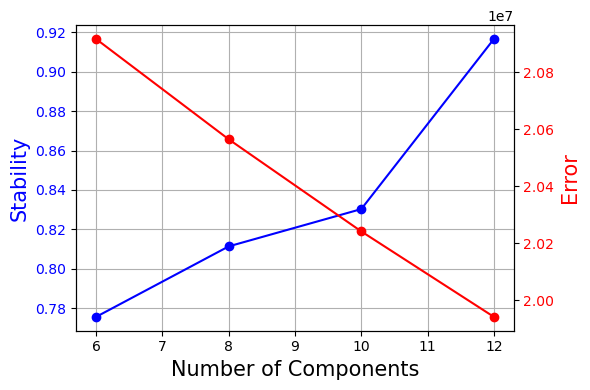

cNMF consensus loaded for K = 6, 8, 10, 12


In [59]:
# ==========================================================================
# R9a · STANDARD cNMF ON THE SAME CELLS AND GENES (cached in REV_DIR/cnmf_bench)
#
# WHY the published package on linear counts: the reference implementation run as its authors
# recommend, on the same cells and genes, so any difference reflects the adaptation in section 5.
# ==========================================================================

try:
    from cnmf import cNMF
    HAVE_CNMF = True
except ImportError:
    HAVE_CNMF = False
    print("cnmf not installed (pip install cnmf) -> R9 benchmark skipped")

CNMF_RES = {}
if HAVE_CNMF:
    cn_dir, cn_name = rev_path("cnmf_bench"), "peng_malignant"
    cn = cNMF(output_dir=cn_dir, name=cn_name)
    done_flag = os.path.join(cn_dir, cn_name, "revision_done.flag")
    if need_rev(done_flag):
        lin = anndata.AnnData(X=expm1_sparse(mal.raw.X).astype(np.float32),
                              obs=pd.DataFrame(index=mal.obs_names),
                              var=pd.DataFrame(index=[str(g) for g in mal.raw.var_names]))
        lin.var_names_make_unique()
        # cnmf divides every gene by its standard deviation; a gene that is constant in these
        # cells would turn the final usage refit into NaN, so such genes are left out (and counted)
        _gi = lin.var_names.get_indexer(prog_genes)
        _Xg = lin.X[:, _gi[_gi >= 0]]
        _Xg = _Xg.toarray() if sparse.issparse(_Xg) else np.asarray(_Xg)
        cn_genes = [g for g, sd_ in zip(np.asarray(prog_genes)[_gi >= 0], _Xg.std(axis=0)) if sd_ > 0]
        print("cNMF genes: {} of section 5's {} (dropped: {} absent, {} constant)".format(
            len(cn_genes), len(prog_genes), int((_gi < 0).sum()), int((_gi >= 0).sum()) - len(cn_genes)))
        in_fn = rev_path("cnmf_input_cp10k.h5ad")
        lin.write_h5ad(in_fn)
        free(lin, _Xg)
        genes_fn = rev_path("cnmf_genes.txt")
        with open(genes_fn, "w") as fh:
            fh.write("\n".join(cn_genes))
        cn.prepare(counts_fn=in_fn, components=CNMF_BENCH_K, n_iter=CNMF_BENCH_ITER,
                   seed=SEED, genes_file=genes_fn)
        cn.factorize(worker_i=0, total_workers=1)
        cn.combine()
        dt_used = {}
        for k in CNMF_BENCH_K:
            # cnmf's outlier filter can (rarely) leave fewer spectra than K; then the
            # consensus is redone without the filter (threshold 2.0) and that is reported
            try:
                cn.consensus(k=k, density_threshold=CNMF_DENSITY, show_clustering=False)
                dt_used[k] = CNMF_DENSITY
            except (ValueError, RuntimeError) as err:
                print("  K={}: density filter {} left too few spectra ({}) -> consensus without filter".format(
                    k, CNMF_DENSITY, str(err)[:50]))
                cn.consensus(k=k, density_threshold=2.0, show_clustering=False)
                dt_used[k] = 2.0
        with open(done_flag, "w") as fh:
            json.dump({str(k): v for k, v in dt_used.items()}, fh)
    with open(done_flag) as fh:
        CNMF_DT = {int(k): float(v) for k, v in json.load(fh).items()}
    print("cNMF density threshold used per K:", CNMF_DT)
    try:
        cn.k_selection_plot(close_fig=False)
        plt.show()
    except Exception as err:
        print("  [k-selection plot skipped: {}]".format(str(err)[:60]))

    def load_cnmf(k):
        """(usage cells x programs, spectra programs x genes) from cnmf's consensus files."""
        try:
            u, s_, _, _ = cn.load_results(K=k, density_threshold=CNMF_DT[k])
            return u, s_.T                     # load_results returns genes x programs
        except Exception:
            dt = str(CNMF_DT[k]).replace(".", "_")
            base = os.path.join(cn_dir, cn_name)
            u = pd.read_csv(os.path.join(base, "{}.usages.k_{}.dt_{}.consensus.txt".format(cn_name, k, dt)),
                            sep="\t", index_col=0)
            s_ = pd.read_csv(os.path.join(base, "{}.gene_spectra_score.k_{}.dt_{}.txt".format(cn_name, k, dt)),
                             sep="\t", index_col=0)
            return u, s_

    for k in CNMF_BENCH_K:
        CNMF_RES[k] = load_cnmf(k)
    print("cNMF consensus loaded for K = {}".format(", ".join(map(str, CNMF_RES))))

     program  cnmf_program  spectra_rho  usage_rho  best_K10  best_rho_K10  best_rho_K6  best_rho_K8  best_rho_K12                                cnmf_top_genes
    1_ductal            10        0.011      0.171         1         0.259        0.272        0.264         0.428 GLIS3-AS1, MYT1, PGLYRP2, SNAI1, TTLL9, SOX30
       2_CAF             6        0.712      0.710         6         0.712        0.762        0.754         0.589       CALD1, SPARC, IGFBP7, ACTA2, THY1, MYL9
      3_tuft             8        0.594      0.267         8         0.594        0.589        0.594         0.592            LRMP, BMX, SH2D6, HCK, RGS13, AVIL
 4_cellcycle             7        0.539      0.464         7         0.539        0.550        0.558         0.520       PTTG1, TPX2, CDC20, CCNB1, BIRC5, HMGB2
    5_acinar             5        0.537      0.498         5         0.537        0.211        0.605         0.500     RAMP2, PLVAP, CD93, CLEC14A, ECSCR, GNG11
6_intestinal             4        

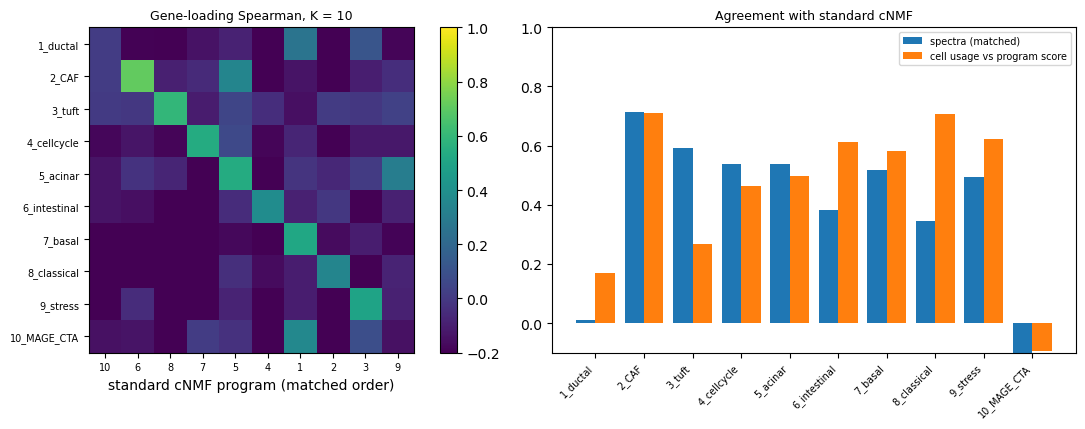

In [60]:
# ==========================================================================
# R9b · SPECTRA, USAGES AND PERSISTENCE ACROSS K   ·   Supplementary Fig. S8
# spectra_rho / usage_rho: each of our programs paired one-to-one with a cNMF program at K = 10
# (Hungarian assignment on gene-loading Spearman). best_K10: the cNMF program it correlates with
# best when the one-to-one constraint is dropped -- where the two differ, two of our programs
# compete for the same cNMF program (one program split or merged). best_rho_K*: best match at
# each other K, also unconstrained.
#
# WHY one-to-one matching: each program is compared with exactly one partner, so a single cnmf
# program cannot be credited twice; the best partner at each K is reported as well.
# ==========================================================================

from scipy.optimize import linear_sum_assignment

if CNMF_RES:
    ours = pd.DataFrame(programs, index=PROG_NAMES, columns=prog_genes)
    u10, s10 = CNMF_RES[CNMF_K]
    common = [g for g in prog_genes if g in s10.columns]
    Rm = np.array([[spearmanr(ours.loc[p, common], s10.loc[q, common])[0] for q in s10.index]
                   for p in ours.index])
    ri, ci = linear_sum_assignment(-Rm)
    match = {PROG_NAMES[a]: (s10.index[b], Rm[a, b]) for a, b in zip(ri, ci)}
    un = u10.div(u10.sum(axis=1), axis=0).reindex(mal.obs_names)
    rows = []
    for p in PROG_NAMES:
        q, rs = match[p]
        ru = spearmanr(mal.obs["prog_" + p], un[q], nan_policy="omit")[0]
        persist = {}
        for k in CNMF_BENCH_K:
            if k == CNMF_K:
                continue
            sk = CNMF_RES[k][1]
            cc = [g for g in common if g in sk.columns]
            persist[k] = max(spearmanr(ours.loc[p, cc], sk.loc[qq, cc])[0] for qq in sk.index)
        top_c = ", ".join(s10.loc[q].sort_values(ascending=False).index[:6])
        a_ = PROG_NAMES.index(p)
        b_any = int(np.argmax(Rm[a_]))               # unconstrained best partner at K = 10
        rows.append(dict(program=p, cnmf_program=q, spectra_rho=rs, usage_rho=ru,
                         best_K10=s10.index[b_any], best_rho_K10=Rm[a_, b_any],
                         **{"best_rho_K{}".format(k): v for k, v in persist.items()}, cnmf_top_genes=top_c))
    BENCH = pd.DataFrame(rows)
    BENCH.to_csv(rev_path("FigS3_cnmf_benchmark.csv"), index=False)
    REV["cnmf_benchmark"] = BENCH.round(3).to_dict(orient="records")
    print(BENCH.round(3).to_string(index=False))
    _split = BENCH[BENCH["best_K10"].astype(str) != BENCH["cnmf_program"].astype(str)]
    for _, r_ in _split.iterrows():                  # where the one-to-one pairing was forced
        _rivals = BENCH.loc[BENCH["cnmf_program"].astype(str) == str(r_["best_K10"]), "program"].tolist()
        print("  {}: best cNMF partner is program {} (rho {:+.2f}), already paired with {}; "
              "the one-to-one match is program {} (rho {:+.2f})".format(
                  r_["program"], r_["best_K10"], r_["best_rho_K10"], ", ".join(_rivals) or "none",
                  r_["cnmf_program"], r_["spectra_rho"]))
    if FIGURES:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
        im = axes[0].imshow(Rm[:, ci][np.argsort(ri)], cmap="viridis", vmin=-0.2, vmax=1)
        axes[0].set_yticks(range(10)); axes[0].set_yticklabels(PROG_NAMES, fontsize=7)
        axes[0].set_xticks(range(10)); axes[0].set_xticklabels([str(s10.index[c]) for c in ci], fontsize=7)
        axes[0].set_xlabel("standard cNMF program (matched order)")
        axes[0].set_title("Gene-loading Spearman, K = 10", fontsize=9)
        plt.colorbar(im, ax=axes[0], fraction=0.046)
        x = np.arange(10)
        axes[1].bar(x - 0.2, BENCH["spectra_rho"], 0.4, label="spectra (matched)")
        axes[1].bar(x + 0.2, BENCH["usage_rho"], 0.4, label="cell usage vs program score")
        axes[1].set_xticks(x); axes[1].set_xticklabels(PROG_NAMES, rotation=45, ha="right", fontsize=7)
        axes[1].set_ylim(-0.1, 1); axes[1].legend(fontsize=7)
        axes[1].set_title("Agreement with standard cNMF", fontsize=9)
        plt.tight_layout()
        _show("revR9_cnmf_benchmark")

In [61]:
# ==========================================================================
# R9c · WHERE DO THE FIBROBLAST/PERICYTE AND ACINAR PROGRAMS COME FROM?
# Program score in high-confidence malignant cells vs excluded cells (CNV-negative or
# doublet-flagged), and the CNV / doublet status of the top-5% cells for each program.
#
# WHY: the reviewers asked why fibroblast/pericyte and acinar programs appear in a malignant
# compartment; doublet flags, CNV status and lineage markers in the top-scoring cells answer it.
# ==========================================================================

if "hc_malignant" not in mal.obs or "cnv_pos_pp" not in mal.obs:
    print("R9c skipped -- needs the R2 copy-number calls (peng_processed.h5ad / steele_qc_lognorm.h5ad)")
else:
    REV["caf_acinar"] = {}
    o = mal.obs
    run_ok = o["cnv_pos_pp"].notna().values
    hc = o["hc_malignant"].values
    excl = run_ok & ~hc
    for p, markers in [("2_CAF", ["COL1A1", "PDGFRB", "ACTA2"]), ("5_acinar", ["PRSS1", "CTRB1", "CPA1"])]:
        col = "prog_" + p
        a, b = o.loc[hc, col], o.loc[excl, col]
        pv = mannwhitneyu(a, b)[1]
        top = o[col] >= o[col].quantile(0.95)
        mk = _raw_cols(mal, markers)
        print("\n{}: score in high-confidence malignant {:+.3f} (n={:,}) vs excluded {:+.3f} (n={:,}), p = {:.2e}".format(
            p, a.median(), len(a), b.median(), len(b), pv))
        print("  top-5% {} cells: CNV-positive {:.1%} (all cells {:.1%}), doublet-flagged {:.1%} (all {:.1%})".format(
            p, np.nanmean(o.loc[top & run_ok, "cnv_pos_pp"].astype(float)),
            np.nanmean(o.loc[run_ok, "cnv_pos_pp"].astype(float)),
            o.loc[top, "doublet_flag"].mean(), o["doublet_flag"].mean()))
        print("  marker expression (mean log1p CP10k), top-5% vs rest: " + ", ".join(
            "{} {:.2f} vs {:.2f}".format(g, mk[g][top.values].mean(), mk[g][~top.values].mean()) for g in markers))
        REV["caf_acinar"][p] = dict(hc_median=float(a.median()), excl_median=float(b.median()), p=float(pv),
                                    top5_cnv_pos=float(np.nanmean(o.loc[top & run_ok, "cnv_pos_pp"].astype(float))),
                                    top5_doublet=float(o.loc[top, "doublet_flag"].mean()))


2_CAF: score in high-confidence malignant +0.056 (n=7,653) vs excluded +0.183 (n=3,611), p = 2.68e-256
  top-5% 2_CAF cells: CNV-positive 54.8% (all cells 77.4%), doublet-flagged 48.2% (all 11.4%)
  marker expression (mean log1p CP10k), top-5% vs rest: COL1A1 1.83 vs 0.50, PDGFRB 0.44 vs 0.04, ACTA2 1.32 vs 0.31

5_acinar: score in high-confidence malignant +0.967 (n=7,653) vs excluded +1.007 (n=3,611), p = 1.94e-23
  top-5% 5_acinar cells: CNV-positive 73.6% (all cells 77.4%), doublet-flagged 1.2% (all 11.4%)
  marker expression (mean log1p CP10k), top-5% vs rest: PRSS1 1.82 vs 0.25, CTRB1 1.17 vs 0.06, CPA1 0.87 vs 0.05


## R10 · Revised Fig. 5, and every revision number in one file

*Results → Robustness of the MAT2A Association; Table 2.* The *MAT2A* robustness forest is redrawn
with every test now in Table 2, **both cohorts**, each coefficient with a 95% patient-bootstrap CI,
against each cohort's ±2 SD random-null band. Rows that need an input that was missing are left
out and listed. Then everything the revision computed is written to
`REV_DIR/revision_results.json`, and the cell prints, placeholder by placeholder, the numbers the
manuscript's highlighted gaps need — so the paper is filled from this run, not from memory.

Fig. 5 layout: 27 boxes, 0 intersecting pair(s); largest empty area 0.75 x 0.50 in (2.3% of the figure) -> OK


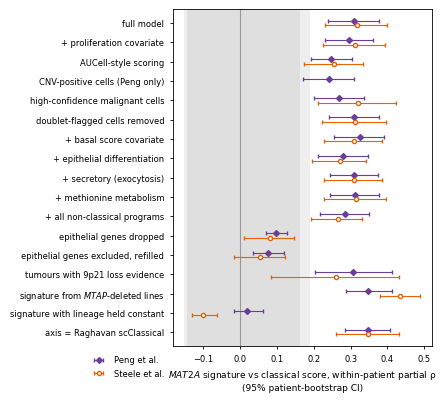

In [62]:
# ==========================================================================
# R10a · REVISED FIG. 5 -- MAT2A under every robustness test, both cohorts, with 95% CIs
# Only cheap deterministic recomputation here; everything else is read from REV.
# ==========================================================================

def _alt_sig(kind):
    if kind == "deletion" and DELETED:
        return derive("MAT2A", ctx_deleted("MTAP"))
    if kind == "lineage":
        return derive("MAT2A", ctx_quantile("MTAP", LOW_Q), lineage_held=True)
    return None


def _sig_rho(ad, genes):
    if genes is None:
        return None
    score(ad, genes, "_f5")
    r = ps_vs(ad.obs, "_f5")
    del ad.obs["_f5"]
    return r


_alt = {k: _alt_sig(k) for k in ["deletion", "lineage"]}
FOREST = []
for _lab, _ad, _res in [("Peng", mal, res), ("Steele", steele, s_res)]:
    o = _ad.obs
    # rows needing section 6's CNV object or R1-R3 stay empty when those were skipped
    ent = [
        ("full model", _res["MAT2A"]),
        ("+ proliferation covariate", ps_vs(o, "MAT2A_sig", covars=QC_COVARS + ["prolif"])),
        ("AUCell-style scoring", ps_vs(o, "MAT2A_auc")),
    ]
    if _lab == "Peng":                           # the original aneuploidy test (section 14) is Peng-only
        ent.append(("CNV-positive cells (Peng only)",
                    ps_vs(sub, "MAT2A_sig", min_cells=30) if globals().get("sub") is not None else None))
    ent += [
        ("high-confidence malignant cells", REV.get("hc_rhos", {}).get("{}|MAT2A_sig".format(_lab))),
        ("doublet-flagged cells removed", ps_vs(o[~o["doublet_flag"].astype(bool).values], "MAT2A_sig")
         if "doublet_flag" in o else None),
        ("+ basal score covariate", ps_vs(o, "MAT2A_sig", covars=QC_COVARS + ["basal_score"])),
    ]
    for n in PRG_COL:
        if not n.lower().startswith("raghavan"):
            ent.append(("+ " + n, REV["program_adjusted"].get("{}|{}".format(_lab, n))))
    ent += [("+ all non-classical programs", REV["program_adjusted"].get("{}|all non-classical programs".format(_lab))),
            ("epithelial genes dropped", REV["epi_removed"].get("{}|MAT2A epithelial genes dropped".format(_lab))),
            ("epithelial genes excluded, refilled", REV["epi_removed"].get("{}|MAT2A epithelial genes excluded, refilled".format(_lab))),
            ("tumours with 9p21 loss evidence", REV.get("loss_strat", {}).get("{}|MAT2A|tumours with 9p21 loss evidence".format(_lab))),
            ("signature from MTAP-deleted lines", _sig_rho(_ad, _alt["deletion"])),
            ("signature with lineage held constant", _sig_rho(_ad, _alt["lineage"]))]
    if _rag_cls:
        ent.append(("axis = Raghavan scClassical", REV["axis"].get("{}|MAT2A_sig|vs Raghavan scClassical".format(_lab))))
    for name, r in ent:
        if r is None or len(r) < 3:                  # a CI needs at least 3 patients
            FOREST.append(dict(cohort=_lab, test=name, n=0 if r is None else len(r), mean=np.nan))
            continue
        rr = rev_row(name, r)
        FOREST.append(dict(cohort=_lab, test=name, n=rr["n"], mean=rr["mean"], lo=rr["ci_lo"],
                           hi=rr["ci_hi"], p=rr["p"], neg=rr["neg"]))
FOREST = pd.DataFrame(FOREST)
FOREST.to_csv(rev_path("Fig5_revised.csv"), index=False)
REV["fig5"] = FOREST.round(4).to_dict(orient="records")
_missing = FOREST[FOREST["mean"].isna()]
if len(_missing):
    print("rows without an estimate (input missing, or fewer than 3 patients with enough cells):")
    print("  " + "\n  ".join("{} - {} (patients: {})".format(c, t, n_) for c, t, n_ in
                             zip(_missing["cohort"], _missing["test"], _missing["n"])))

if FIGURES:
    with plt.rc_context(MS_RC):
        # drawn at its printed size (4.3 in wide), so the font sizes are the sizes on the page;
        # constrained layout, legend in the corner below the row labels, checked box by box (R0)
        tests = list(dict.fromkeys(FOREST["test"]))
        fig = ms_figure((4.3, 0.18 * len(tests) + 0.85))
        ax = fig.subplots()
        y = np.arange(len(tests))[::-1]
        for nd in (null, s_null):                       # overlap of the two bands reads darker
            ax.axvspan(nd.mean() - 2 * nd.std(), nd.mean() + 2 * nd.std(), color="0.5", alpha=0.13, lw=0, zorder=0)
        ax.axvline(0, color="0.6", lw=0.8)
        for off, _lab, mk, colr in [(0.12, "Peng", "D", "#6A3D9A"), (-0.12, "Steele", "o", "#E66101")]:
            g = FOREST[(FOREST["cohort"] == _lab) & FOREST["mean"].notna()].set_index("test")
            yy = [y[tests.index(t_)] + off for t_ in g.index]
            ax.errorbar(g["mean"], yy, xerr=[g["mean"] - g["lo"], g["hi"] - g["mean"]], fmt=mk, color=colr,
                        ms=3, capsize=1.2, elinewidth=0.8, label=_lab + " et al.", mfc=colr if _lab == "Peng" else "white")
        ax.set_yticks(y); ax.set_yticklabels([gi(t_) for t_ in tests])
        ax.set_ylim(y.min() - 0.7, y.max() + 0.7)
        ax.set_xlabel(gi("MAT2A signature vs classical score, within-patient partial ρ\n(95% patient-bootstrap CI)"))
        ms_legend_under_labels(ax, *ax.get_legend_handles_labels())   # below the tick labels, beside the x label
        LAYOUT["Fig. 5"] = fig_layout_check(fig, "Fig. 5")
        plt.savefig(rev_path("Fig5_mat2a_robustness.png"), dpi=300, bbox_inches="tight")   # manuscript Fig. 5
        _show("revR10_fig5_forest")

In [63]:
# ==========================================================================
# R10b · EVERY REVISION NUMBER TO ONE FILE, AND THE MANUSCRIPT PLACEHOLDERS FILLED
# ==========================================================================

def _jsonable(x):
    if isinstance(x, dict):
        return {str(k): _jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_jsonable(v) for v in x]
    if isinstance(x, (np.floating, float)):
        return None if not np.isfinite(x) else float(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.bool_,)):
        return bool(x)
    return x


# entries that hold per-patient coefficients are summarised (n, mean, 95% CI) before writing
PER_PATIENT = {"hc_rhos", "loss_strat", "program_adjusted", "epi_removed", "axis"}
_out = {}
for k, v in REV.items():
    if k in PER_PATIENT:
        _out[k] = {kk: (vv if kk.startswith("depmap|") else
                        dict(zip(["n", "mean", "ci_lo", "ci_hi"], [len(vv), mean_rho(vv), *boot_ci(vv)])))
                   for kk, vv in v.items()}
    else:
        _out[k] = v
with open(rev_path("revision_results.json"), "w") as fh:
    json.dump(_jsonable(_out), fh, indent=1)
print("wrote", rev_path("revision_results.json"))


def _f(r):
    ok = r is not None and np.isfinite(r.get("mean", np.nan))
    return "{:+.3f} [{:+.3f}, {:+.3f}]  n={}".format(r["mean"], r["lo"], r["hi"], int(r["n"])) if ok else "n/a"


def _fr(cohort, test):
    g = FOREST[(FOREST["cohort"] == cohort) & (FOREST["test"] == test)]
    return None if g.empty else g.iloc[0].to_dict()


print("\nNUMBERS FOR THE MANUSCRIPT'S HIGHLIGHTED PLACEHOLDERS\n")
if not RAW_SC_OK:
    print("!! R1-R3 were SKIPPED (peng_processed.h5ad / steele_qc_lognorm.h5ad missing): the doublet,\n"
          "   copy-number, high-confidence-cell and 9p21/18q-loss placeholders below stay empty.\n")
print("Doublets (Results, Cell Populations):", REV.get("count_source"))
for lab, ss in REV.get("doublet_samples", {}).items():
    s_ = pd.DataFrame(ss)
    print("  {}: expected {:.1%}, observed {:.1%}, bimodal {}/{} samples".format(
        lab, np.average(s_["expected_rate"], weights=s_["cells"]),
        np.average(s_["observed_rate"], weights=s_["cells"]), int((s_["rule"] == "bimodal minimum").sum()), len(s_)))
print("High-confidence malignant cells:", REV.get("hc_cells"))
print("Peng control pancreata among analysed patients:",
      (REV["peng_controls_in_analysis"] or "none") if "peng_controls_in_analysis" in REV else "n/a (R2 skipped)")
print("CNV-positive fraction (per-patient runs):", {k: round(v["overall"], 3) for k, v in REV.get("cnv_pos_frac", {}).items()})
print("MAT2A, CNV+ minus CNV- malignant:", REV.get("mat2a_cnv_pos_minus_neg"))
print("\nDepMap held-out validation (original derivation):")
for r in REV.get("depmap_validation", []):
    if r["derivation"].startswith("original"):
        print("  {:<6} rho {:+.3f}  R2 {:+.3f}  AUC {:.2f}  dR2 {:+.3f}  D2 {}".format(
            r["target"], r["rho_score_chronos"], r["r2_oos"], r["auc_quartiles"], r["delta_r2"],
            "{:+.3f}".format(r["rho_oof_demeter2"]) if r.get("rho_oof_demeter2") is not None and np.isfinite(r.get("rho_oof_demeter2", np.nan)) else "n/a"))
print("\nTarget dependency by passenger deletion:", REV.get("del_vs_intact_chronos"))
print("\nMAT2A robustness (Peng | Steele):")
for t_ in dict.fromkeys(FOREST["test"]):
    print("  {:<42} {:<30} {}".format(t_, _f(_fr("Peng", t_)), _f(_fr("Steele", t_))))
def _verdict(r):
    """Three outcomes, never conflated: an association, equivalence to zero, or neither."""
    q = r.get("wilcoxon_q")
    if q is not None and np.isfinite(q) and q < 0.05:
        return "ASSOCIATION detected (Wilcoxon q < 0.05)"
    if r["equivalent_within_margin"]:
        return "EQUIVALENT to zero within the margin"
    if r["ci95_lo"] > 0 or r["ci95_hi"] < 0:
        return "INCONCLUSIVE - 95% CI excludes zero but the Wilcoxon test is not significant"
    return "INCONCLUSIVE - neither an association nor equivalence shown"


print("\nEquivalence (TOST, +/-{}):".format(EQ_MARGIN))
for r in REV["table3"]:
    if r["signature"] in ("VPS4A", "PRMT5"):
        print("  {} {:<6} mean {:+.4f}, 90% CI [{:+.4f}, {:+.4f}], TOST p {:.4f} -> {}".format(
            r["cohort"], r["signature"], r["mean_rho"], r["ci90_lo"], r["ci90_hi"], r["tost_p"], _verdict(r)))
print("\nDependency positive controls (rho vs classical, detected, DepMap premise holds):")
for k, v in REV.get("pos_ctrl", {}).items():
    print("  {:<32} {:+.3f}  detected: {:<5} premise: {}".format(
        k, v["vs_classical"], str(v["detected_in_expected_direction"]), v.get("premise_holds_in_depmap")))
print("Harder nulls (MAT2A):", {k: round(v["sd"], 2) for k, v in REV.get("hard_nulls", {}).items()})
print("Per-gene split (epithelial vs other):", {k: (round(v["epi_mean"], 3), round(v["other_mean"], 3), round(v["p"], 4))
                                                 for k, v in REV.get("per_gene", {}).items()})
if "cnmf_benchmark" in REV:
    b_ = pd.DataFrame(REV["cnmf_benchmark"])
    print("cNMF benchmark: median matched spectra rho {:.2f}, median usage rho {:.2f}".format(
        b_["spectra_rho"].median(), b_["usage_rho"].median()))
if "vps4a_basal" in REV:                         # R8c: the one new association, and its verdict
    vb_ = REV["vps4a_basal"]
    print("\nVPS4A signature vs basal score (R8c):")
    for r in vb_["battery"]:
        if r["test"] == "Full model":
            print("  {:<8} {:+.3f} [{:+.3f}, {:+.3f}]  n={}".format(r["cohort"], r["mean"], r["lo"], r["hi"], int(r["n"])))
    for r in vb_["nulls"]:
        if r["axis"] == "basal":
            print("  {:<8} {:<30} {:+.1f} SD, empirical p {:.4f}".format(r["cohort"], r["null"] + " null", r["sd"], r["emp_p"]))
    print("  verdict: " + vb_["verdict"])
    print("  DepMap premise (basal-like lines more VPS4A-dependent, lineage held): " +
          ("supports" if vb_["depmap_premise_supports"] else "does not support"))
print("\nAll tables and figures for the revision are in", REV_DIR)

wrote C:\Users\The_R/Downloads\revision\revision_results.json

NUMBERS FOR THE MANUSCRIPT'S HIGHLIGHTED PLACEHOLDERS

Doublets (Results, Cell Populations): {'Peng': 'NO exact count source -- Scrublet not re-run for this cohort', 'Steele': 'stored layers/counts'}
  Steele: expected 2.9%, observed 0.4%, bimodal 17/17 samples
High-confidence malignant cells: {'Peng': 7653, 'Steele': 6253}
Peng control pancreata among analysed patients: none
CNV-positive fraction (per-patient runs): {'Peng': 0.774, 'Steele': 0.676}
MAT2A, CNV+ minus CNV- malignant: {'Peng': {'mean': 0.01633394691166482, 'n': 21, 'n_pos': 19, 'p': 0.0008516311645507812}, 'Steele': {'mean': 0.03161564939902789, 'n': 13, 'n_pos': 12, 'p': 0.00244140625}}

DepMap held-out validation (original derivation):
  VPS4A  rho -0.441  R2 +0.176  AUC 0.83  dR2 +0.128  D2 -0.294
  PRMT5  rho -0.201  R2 +0.000  AUC 0.63  dR2 -0.056  D2 -0.213
  MAT2A  rho -0.243  R2 +0.024  AUC 0.69  dR2 -0.027  D2 -0.153

Target dependency by passenger d

## R11 · Manuscript figures

*Revision.* The six main figures of the revised manuscript, each drawn as one composite and written
at 300 dpi to `~/Downloads/revision/`. These are the files that go into the manuscript.

| figure | content | file | drawn in | insert at |
|---|---|---|---|---|
| 1 | aneuploidy of the malignant compartment, both cohorts | `Fig1_cnv.png` | R11a | 5.0 in wide |
| 2 | technical confounds, and their removal by residualization | `Fig2_confounds.png` | R11b | 6.5 in |
| 3 | the signatures on the classical axis, against the random null | `Fig3_classical_axis.png` | R11c | 5.6 in |
| 4 | specificity against generic essentiality, and the positive controls | `Fig4_specificity_controls.png` | R11d | 6.3 in |
| 5 | the *MAT2A* signature under every robustness test | `Fig5_mat2a_robustness.png` | R10a | 4.3 in |
| 6 | the *VPS4A* signature on the basal axis | `Fig6_vps4a_basal.png` | R8c-3 | 6.5 in |

Each figure is drawn at the size it is printed, so inserting it at the width above gives 6-7 pt text
on the page and keeps the manuscript at 20 pages.

Every panel is drawn from objects computed earlier in the notebook, or from the inferCNV files
section 6 wrote, so nothing here changes a number in the paper. The only new computation is the
UMAP layout of Fig. 1, which is for display. Peng et al. is drawn as purple diamonds and Steele et al.
as orange open circles throughout, as in Figs. 5 and 6. R11e checks that all six files exist.

Peng    8,000 cells | malignant / reference CNV ratio 2.70x | 84.2% of malignant cells above the reference 95th percentile
Steele  8,000 cells | malignant / reference CNV ratio 2.50x | 65.8% of malignant cells above the reference 95th percentile
Fig. 1 layout: 32 boxes, 0 intersecting pair(s); largest empty area 1.00 x 0.40 in (2.4% of the figure) -> OK


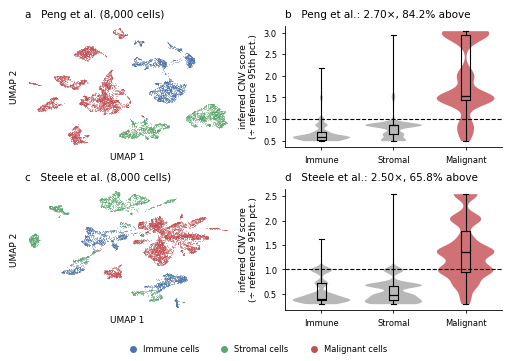

In [64]:
# ==========================================================================
# R11a · FIG. 1 -- most malignant-compartment cells are aneuploid, both cohorts
# (a, c) uncorrected UMAP of each cohort's 8,000-cell inferCNV subsample, coloured by
#        compartment (4,000 malignant, 2,000 immune, 2,000 stromal cells)
# (b, d) inferred CNV score by compartment, divided by the 95th percentile of the diploid
#        (immune + stromal) reference, so the dashed line at 1.0 is the aneuploidy threshold
# The ratio and the percentage in each panel title use section 6's definitions exactly:
# mean malignant score / mean reference score, and malignant cells above the reference 95th
# percentile. Reads the files section 6 wrote; reruns nothing from inferCNV.
# ==========================================================================

FIG_DPI = 300                                       # every manuscript figure is written at 300 dpi
PENG_COL, STEELE_COL = "#6A3D9A", "#E66101"         # the cohort colours of Figs. 5 and 6
COMP = [("Immune cells", "Immune", "#4C72B0"),      # (label in the file, axis label, colour)
        ("Stromal cells", "Stromal", "#55A868"),
        ("Malignant cells", "Malignant", "#C44E52")]
# Every figure is drawn at the size it is printed (figsize = printed width x height in inches),
# so the font sizes are the sizes on the page (MS_RC, R0: 6-7 pt text, 7.5 pt panel titles). The
# widths match the manuscript's figure frames, so a figure can be swapped in without reflowing
# the pages. Each figure uses constrained layout (ms_figure), keeps every legend and label
# outside the plotting areas (ms_legend), and is checked box by box before it is saved
# (fig_layout_check, R0). MS_RC is applied with plt.rc_context, so later figures are untouched.
FIG_SIZE = {1: (5.0, 3.5), 2: (6.5, 3.0), 3: (5.6, 3.47), 4: (6.3, 2.45)}   # Figs. 5 and 6: R10a, R8c-3
FIG_RC = MS_RC
SIG_COLORS = {"VPS4A": "#1B9E77", "PRMT5": "#E7298A", "MAT2A": "#D62728", "common_essential": "0.3"}


def _panel(ax, letter, title):
    """Panel letter and title, left-aligned above the axes, as in the submitted figures."""
    ax.set_title("{}   {}".format(letter, title), loc="left", fontsize=7.5)


def _despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def _lognorm_x(a):
    """The expression matrix as log-normalised values. The inferCNV files carry the matrix
    section 6 read (log-normalised in both cohorts); if a file ever arrives with raw counts
    (values far above what log1p of 10,000-count data can reach), normalise it the same way
    Steele et al. was normalised in Methods, so the UMAP is built on comparable values."""
    b = sc.AnnData(X=a.X.copy(), obs=pd.DataFrame(index=a.obs_names), var=pd.DataFrame(index=a.var_names))
    if float(b.X.max()) > 50:                       # .max() works on dense and sparse matrices
        sc.pp.normalize_total(b, target_sum=1e4)
        sc.pp.log1p(b)
    return b


def _umap_xy(a, cohort):
    """Uncorrected UMAP of one inferCNV subsample: 2,000 highly variable genes, scaled, 30
    principal components, 15-neighbour graph, UMAP. Display only -- no statistic uses it.
    Cached to REV_DIR so a re-run redraws instantly; random_state fixes the layout without
    touching any other analysis's random stream."""
    cache = rev_path("fig1_umap_{}.csv".format(cohort))
    if os.path.exists(cache) and not REV_FORCE:
        xy = pd.read_csv(cache, index_col=0)
        if list(xy.index.astype(str)) == list(a.obs_names.astype(str)):
            return xy.values
    b = _lognorm_x(a)
    sc.pp.highly_variable_genes(b, n_top_genes=min(2000, b.n_vars - 1))
    b = b[:, b.var["highly_variable"].values].copy()
    sc.pp.scale(b, max_value=10)
    sc.tl.pca(b, n_comps=min(30, b.n_vars - 1, b.n_obs - 1), random_state=SEED)
    sc.pp.neighbors(b, n_neighbors=15, random_state=SEED)
    sc.tl.umap(b, random_state=SEED)
    xy = pd.DataFrame(b.obsm["X_umap"], index=a.obs_names, columns=["UMAP1", "UMAP2"])
    xy.to_csv(cache)
    return xy.values


FIG1_IN = [("Peng", PENG_CNV, MAL_COL), ("Steele", STEELE_CNV, "ref_label")]
REV["fig1"] = {}
_have = [os.path.exists(p) for _, p, _ in FIG1_IN]
if not all(_have):
    print("Fig. 1 skipped -- missing inferCNV file(s): {}. Section 6 writes them.".format(
        ", ".join(os.path.basename(p) for (_, p, _), h in zip(FIG1_IN, _have) if not h)))
else:
    _f1 = {}
    for _lab, _path, _lcol in FIG1_IN:
        _a = sc.read_h5ad(_path)
        _a.obs[_lcol] = _a.obs[_lcol].astype(str)
        _sco = _a.obs["cnv_score"].astype(float)
        _ref = _sco[_a.obs[_lcol].isin(["Immune cells", "Stromal cells"])]
        _mal = _sco[_a.obs[_lcol] == "Malignant cells"]
        _ref95 = float(_ref.quantile(0.95))
        _ratio = float(_mal.mean() / _ref.mean())       # section 6's ratio (mean / mean)
        _above = float((_mal > _ref95).mean())          # section 6's CNV-positive fraction
        REV["fig1"][_lab] = dict(n_cells=int(_a.n_obs), ratio=_ratio, pct_above=100 * _above,
                                 ref95=_ref95, n_malignant=int(len(_mal)), n_reference=int(len(_ref)))
        print("{:<7} {:,} cells | malignant / reference CNV ratio {:.2f}x | {:.1%} of malignant cells "
              "above the reference 95th percentile".format(_lab, _a.n_obs, _ratio, _above))
        _f1[_lab] = dict(xy=_umap_xy(_a, _lab), lab=_a.obs[_lcol].values,
                         norm=(_sco / _ref95).values, ratio=_ratio, above=_above)
        free(_a)

    if FIGURES:
        with plt.rc_context(FIG_RC):
            fig = ms_figure(FIG_SIZE[1])
            axes = fig.subplots(2, 2, gridspec_kw={"width_ratios": [1, 1.05]})
            for row, _lab in enumerate(["Peng", "Steele"]):
                d = _f1[_lab]
                # (a, c) UMAP: reference compartments first, malignant last, so the malignant
                # cells are not hidden under the much smaller reference clusters
                ax = axes[row, 0]
                for _key, _short, _c in COMP:
                    m = d["lab"] == _key
                    ax.scatter(d["xy"][m, 0], d["xy"][m, 1], s=0.6, color=_c, alpha=0.55, lw=0, rasterized=True)
                ax.set_xticks([]); ax.set_yticks([])
                for s_ in ax.spines.values():
                    s_.set_visible(False)
                ax.margins(0.02)
                ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
                _panel(ax, "ac"[row], "{} et al. ({:,} cells)".format(_lab, len(d["lab"])))
                # (b, d) normalised CNV score per compartment: violin = full distribution,
                # box = median and IQR, whiskers = full range
                ax = axes[row, 1]
                data = [d["norm"][d["lab"] == k] for k, _, _ in COMP]
                vp = ax.violinplot(data, positions=range(3), widths=0.8, showextrema=False)
                for body, (_, _, _c) in zip(vp["bodies"], COMP):
                    body.set_facecolor("0.65" if _c != COMP[2][2] else _c)
                    body.set_edgecolor("none"); body.set_alpha(0.8)
                ax.boxplot(data, positions=range(3), widths=0.13, whis=(0, 100), showfliers=False,
                           medianprops=dict(color="k", lw=0.9), boxprops=dict(lw=0.8), whiskerprops=dict(lw=0.8),
                           capprops=dict(lw=0.8))
                ax.axhline(1.0, color="k", ls="--", lw=0.8)
                ax.set_xticks(range(3)); ax.set_xticklabels([s for _, s, _ in COMP])
                ax.set_ylabel("inferred CNV score\n(÷ reference 95th pct.)")
                _despine(ax)
                _panel(ax, "bd"[row], "{} et al.: {:.2f}×, {:.1%} above".format(_lab, d["ratio"], d["above"]))
            # the compartment colours, once, in a strip below the panels (never over the cells)
            ms_legend(fig, [Line2D([], [], ls="", marker="o", ms=4, color=c) for _, _, c in COMP],
                      ["{} cells".format(sh) for _, sh, _ in COMP], "lower", handletextpad=0.2)
            LAYOUT["Fig. 1"] = fig_layout_check(fig, "Fig. 1")
            plt.savefig(rev_path("Fig1_cnv.png"), dpi=FIG_DPI, bbox_inches="tight")   # manuscript Fig. 1
            _show("revR11_fig1_cnv")

Peng -- Spearman of each score with the QC covariates (all malignant cells)
                 Depth  Genes  Mito.
Classical       -0.076  0.025  0.339
Basal           -0.023 -0.056 -0.192
VPS4A            0.324  0.192 -0.279
PRMT5            0.158  0.195 -0.015
MAT2A            0.209  0.157 -0.025
Comm. essential -0.024  0.237 -0.106
  classical vs mito fraction: raw rho +0.339 -> after residualization +0.031

Steele -- Spearman of each score with the QC covariates (all malignant cells)
                 Depth  Genes  Mito.
Classical        0.183  0.151  0.267
Basal            0.173  0.145 -0.151
VPS4A            0.573  0.588 -0.129
PRMT5            0.311  0.341 -0.267
MAT2A            0.553  0.547  0.066
Comm. essential  0.380  0.366 -0.285
  classical vs mito fraction: raw rho +0.267 -> after residualization +0.029

Fig. 2 layout: 139 boxes, 0 intersecting pair(s); largest empty area 2.66 x 0.20 in (2.9% of the figure) -> OK


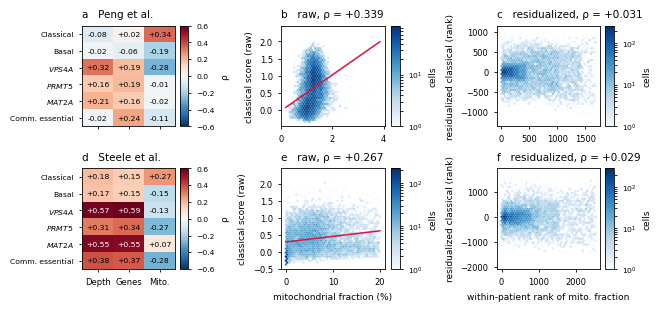

In [65]:
# ==========================================================================
# R11b · FIG. 2 -- the technical confounds, and their removal
# (a, d) Spearman correlation, across all malignant cells, of each score with the three QC
#        covariates (section 9's table, both cohorts, with the basal score and the
#        commonly-essential control added because both are tested in the paper)
# (b, e) the strongest subtype-score confound drawn: raw classical score vs mitochondrial
#        fraction, with the least-squares line
# (c, f) the same after the correction every coefficient in the paper uses: the classical rank
#        residualised on the three QC ranks within each patient, against the within-patient
#        rank of mitochondrial fraction. A flat panel means the confound is gone.
# Pure consumer of mal.obs / steele.obs; no random numbers.
# ==========================================================================

CONF_ROWS = [("classical_score", "Classical"), ("basal_score", "Basal"), ("VPS4A_sig", "VPS4A"),
             ("PRMT5_sig", "PRMT5"), ("MAT2A_sig", "MAT2A"), ("CE_sig", "Comm. essential")]
CONF_COLS = [("log_counts", "Depth"), ("n_genes_by_counts", "Genes"),     # sequencing depth, detected
             ("pct_counts_mt", "Mito.")]                                   # genes, mitochondrial fraction


def _within_patient_resid(obs, col, xcol="pct_counts_mt", covars=None, min_cells=MIN_CELLS):
    """Per patient, the rank of `col` OLS-residualised on the QC-covariate ranks -- exactly the
    quantity partial_spearman correlates -- and the within-patient rank of `xcol` for the x axis.
    Patients below MIN_CELLS are skipped, as in every test in the paper."""
    covars = covars or QC_COVARS
    rx, ry = [], []
    for _, g in obs.groupby("Patient", observed=True):
        if len(g) < min_cells:
            continue
        Q = np.column_stack([rankdata(g[q].values) for q in covars])
        ry.append(resid(rankdata(g[col].values), Q))
        rx.append(rankdata(g[xcol].values))
    return np.concatenate(rx), np.concatenate(ry)


CONF = {}
REV["fig2_confounds"] = {}
for _lab, _o in [("Peng", mal.obs), ("Steele", steele.obs)]:
    rows = [r for r in CONF_ROWS if r[0] in _o]
    M = pd.DataFrame([[spearmanr(_o[r], _o[c])[0] for c, _ in CONF_COLS] for r, _ in rows],
                     index=[n for _, n in rows], columns=[n for _, n in CONF_COLS])
    _x, _y = _within_patient_resid(_o, "classical_score")
    CONF[_lab] = dict(M=M, raw_x=_o["pct_counts_mt"].values.astype(float),
                      raw_y=_o["classical_score"].values.astype(float), res_x=_x, res_y=_y,
                      rho_raw=spearmanr(_o["pct_counts_mt"], _o["classical_score"])[0],
                      rho_res=spearmanr(_x, _y)[0])
    REV["fig2_confounds"][_lab] = dict(matrix=M.round(3).to_dict(), rho_raw=float(CONF[_lab]["rho_raw"]),
                                       rho_residualised=float(CONF[_lab]["rho_res"]))
    print("{} -- Spearman of each score with the QC covariates (all malignant cells)".format(_lab))
    print(M.round(3).to_string())
    print("  classical vs mito fraction: raw rho {:+.3f} -> after residualization {:+.3f}\n".format(
        CONF[_lab]["rho_raw"], CONF[_lab]["rho_res"]))

if FIGURES:
    with plt.rc_context(FIG_RC):
        fig = ms_figure(FIG_SIZE[2])
        axes = fig.subplots(2, 3, gridspec_kw={"width_ratios": [0.9, 1, 1]})
        for row, _lab in enumerate(["Peng", "Steele"]):
            d = CONF[_lab]
            # (a, d) heatmap with the coefficient printed in each cell (text inside its own panel)
            ax = axes[row, 0]
            im = ax.imshow(d["M"].values, cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
            for i in range(d["M"].shape[0]):
                for j in range(d["M"].shape[1]):
                    v = d["M"].values[i, j]
                    ax.text(j, i, "{:+.2f}".format(v), ha="center", va="center", fontsize=5.5,
                            color="white" if abs(v) > 0.4 else "black")
            ax.set_xticks(range(d["M"].shape[1]))
            ax.set_xticklabels(d["M"].columns if row == 1 else [])            # bottom row only, unrotated
            ax.set_yticks(range(d["M"].shape[0])); ax.set_yticklabels([gi(n) for n in d["M"].index], fontsize=5.5)
            cb = fig.colorbar(im, ax=ax, aspect=12); cb.set_label("ρ")
            cb.ax.tick_params(labelsize=5.5)
            _panel(ax, "ad"[row], "{} et al.".format(_lab))
            # (b, e) raw: classical score vs mitochondrial fraction, hexbin + least-squares line;
            # the coefficient goes in the panel title, not over the cells
            ax = axes[row, 1]
            hb = ax.hexbin(d["raw_x"], d["raw_y"], gridsize=40, bins="log", mincnt=1, cmap="Blues", lw=0)
            b_ = np.polyfit(d["raw_x"], d["raw_y"], 1)
            xs = np.linspace(np.nanmin(d["raw_x"]), np.nanmax(d["raw_x"]), 50)
            ax.plot(xs, np.polyval(b_, xs), color="crimson", lw=1.1)
            ax.set_xlabel("mitochondrial fraction (%)" if row == 1 else ""); ax.set_ylabel("classical score (raw)")
            cb = fig.colorbar(hb, ax=ax, aspect=12); cb.set_label("cells")
            cb.ax.tick_params(labelsize=5.5)
            _panel(ax, "be"[row], "raw, ρ = {:+.3f}".format(d["rho_raw"]))
            # (c, f) after: residualised classical rank vs within-patient rank of mito fraction
            ax = axes[row, 2]
            hb = ax.hexbin(d["res_x"], d["res_y"], gridsize=40, bins="log", mincnt=1, cmap="Blues", lw=0)
            ax.set_xlabel("within-patient rank of mito. fraction" if row == 1 else "")
            ax.set_ylabel("residualized classical (rank)")
            cb = fig.colorbar(hb, ax=ax, aspect=12); cb.set_label("cells")
            cb.ax.tick_params(labelsize=5.5)
            _panel(ax, "cf"[row], "residualized, ρ = {:+.3f}".format(d["rho_res"]))
        LAYOUT["Fig. 2"] = fig_layout_check(fig, "Fig. 2")
        plt.savefig(rev_path("Fig2_confounds.png"), dpi=FIG_DPI, bbox_inches="tight")   # manuscript Fig. 2
        _show("revR11_fig2_confounds")

Fig. 3 layout: 56 boxes, 0 intersecting pair(s); largest empty area 0.55 x 1.21 in (3.6% of the figure) -> CHECK


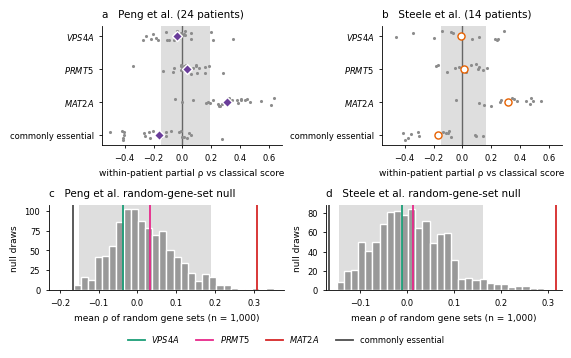

Peng    null mean +0.0186, SD 0.0850 | VPS4A -0.0365 (-0.6 SD) | PRMT5 +0.0325 (+0.2 SD) | MAT2A +0.3094 (+3.4 SD) | commonly essential -0.1650 (-2.2 SD)
Steele  null mean +0.0088, SD 0.0769 | VPS4A -0.0104 (-0.2 SD) | PRMT5 +0.0134 (+0.1 SD) | MAT2A +0.3168 (+4.0 SD) | commonly essential -0.1666 (-2.3 SD)


In [66]:
# ==========================================================================
# R11c · FIG. 3 -- the signatures on the classical axis, against the random null
# (a, b) per-patient forest: grey points = patients, diamond/circle = mean across patients,
#        grey band = that cohort's random-gene-set null mean +/- 2 SD
# (c, d) the random-gene-set null itself (section 11's `null`, section 15's `s_null`), with each
#        signature's mean coefficient marked; signatures outside the band in red
# Pure consumer of res / s_res / null / s_null. The jitter has its own RNG stream, so drawing
# this figure cannot shift any null (see the note in section 11).
# ==========================================================================

F3_KEYS = TARGETS + ["common_essential"]
F3_NAME = {"common_essential": "commonly essential"}

if FIGURES:
    with plt.rc_context(FIG_RC):
        _jit = np.random.default_rng(SEED + 311)                  # display jitter only
        fig = ms_figure(FIG_SIZE[3])
        # two rows as subfigures, each laid out on its own, so the histograms are not pushed
        # right to line up with the forest panels' long labels (that left an empty column)
        _top, _bot = fig.subfigures(2, 1, height_ratios=[1.05, 1])
        axes = np.array([_top.subplots(1, 2), _bot.subplots(1, 2)])
        _xmin = min(min(min(r_.values()) for r_ in (res[k], s_res[k])) for k in F3_KEYS)
        _xmax = max(max(max(r_.values()) for r_ in (res[k], s_res[k])) for k in F3_KEYS)
        for col, (_lab, _res, _null, _c, _mk) in enumerate([("Peng", res, null, PENG_COL, "D"),
                                                             ("Steele", s_res, s_null, STEELE_COL, "o")]):
            lo_b, hi_b = _null.mean() - 2 * _null.std(), _null.mean() + 2 * _null.std()
            # (a, b) forest
            ax = axes[0, col]
            ax.axvspan(lo_b, hi_b, color="0.87", zorder=0, lw=0)
            ax.axvline(0, color="0.4", lw=1)
            for j, k in enumerate(F3_KEYS):
                yy = len(F3_KEYS) - 1 - j
                r = np.array(list(_res[k].values()))
                ax.scatter(r, yy + _jit.uniform(-0.15, 0.15, len(r)), s=5, color="0.55", lw=0, zorder=2)
                ax.scatter([r.mean()], [yy], s=26, marker=_mk, edgecolors="white" if _mk == "D" else _c,
                           facecolors=_c if _mk == "D" else "white", linewidths=1.0, zorder=3)
            ax.set_yticks(range(len(F3_KEYS)))
            ax.set_yticklabels([gi(F3_NAME.get(k, k)) for k in F3_KEYS][::-1])
            ax.set_xlim(_xmin - 0.05, _xmax + 0.05)
            ax.set_xlabel("within-patient partial ρ vs classical score")
            _despine(ax)
            _panel(ax, "ab"[col], "{} et al. ({} patients)".format(_lab, len(_res["MAT2A"])))
            # (c, d) null histogram; each signature is a coloured line, named in the legend below
            # the panels rather than in text over the histogram
            ax = axes[1, col]
            ax.axvspan(lo_b, hi_b, color="0.87", zorder=0, lw=0)
            ax.hist(_null, bins=30, color="0.6", edgecolor="white", zorder=1)
            for k in F3_KEYS:
                ax.axvline(float(np.mean(list(_res[k].values()))), color=SIG_COLORS[k], lw=1.3, zorder=2)
            ax.set_xlabel("mean ρ of random gene sets (n = {:,})".format(len(_null)))
            ax.set_ylabel("null draws")
            _despine(ax)
            _panel(ax, "cd"[col], "{} et al. random-gene-set null".format(_lab))
        ms_legend(_bot, [Line2D([], [], color=SIG_COLORS[k], lw=1.3) for k in F3_KEYS],
                  [gi(F3_NAME.get(k, k)) for k in F3_KEYS], "lower")
        LAYOUT["Fig. 3"] = fig_layout_check(fig, "Fig. 3")
        plt.savefig(rev_path("Fig3_classical_axis.png"), dpi=FIG_DPI, bbox_inches="tight")   # manuscript Fig. 3
        _show("revR11_fig3_classical_axis")
        for _lab, _res, _null in [("Peng", res, null), ("Steele", s_res, s_null)]:
            print("{:<7} null mean {:+.4f}, SD {:.4f} | ".format(_lab, _null.mean(), _null.std()) +
                  " | ".join("{} {:+.4f} ({:+.1f} SD)".format(F3_NAME.get(k, k), np.mean(list(_res[k].values())),
                                                             sd_from(np.mean(list(_res[k].values())), _null))
                             for k in F3_KEYS))

Fig. 4 layout: 32 boxes, 0 intersecting pair(s); largest empty area 1.30 x 0.45 in (3.9% of the figure) -> CHECK


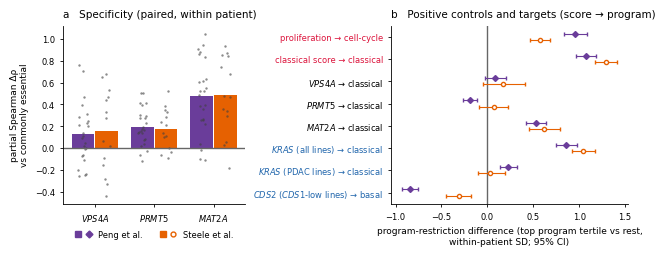

tick labels: red = gene-overlap controls, blue = dependency-based controls, black = targets
cohort                 score     program  std_diff  std_lo  std_hi  n
  Peng         proliferation 4_cellcycle     0.958   0.830   1.086 24
  Peng       classical score 8_classical     1.072   0.965   1.180 24
  Peng                 VPS4A 8_classical     0.086  -0.028   0.200 24
  Peng                 PRMT5 8_classical    -0.186  -0.269  -0.108 24
  Peng                 MAT2A 8_classical     0.526   0.419   0.642 24
  Peng      KRAS (all lines) 8_classical     0.859   0.747   0.977 24
  Peng     KRAS (PDAC lines) 8_classical     0.227   0.136   0.324 24
  Peng CDS2 (CDS1-low lines)     7_basal    -0.842  -0.927  -0.754 24
Steele         proliferation 4_cellcycle     0.572   0.466   0.679 14
Steele       classical score 8_classical     1.292   1.167   1.410 14
Steele                 VPS4A 8_classical     0.168  -0.044   0.413 14
Steele                 PRMT5 8_classical     0.068  -0.093   0.220 1

In [67]:
# ==========================================================================
# R11d · FIG. 4 -- specificity against generic essentiality, and the positive controls
# (a) the within-patient head-to-head on the classical axis: each target signature minus the
#     commonly-essential control, per patient (points) and averaged (bars), both cohorts
# (b) R7b's positive controls and the targets on one comparable scale: the program-restriction
#     difference (each patient's top program tertile minus the rest) divided by the
#     within-patient SD of the score, with 95% patient-bootstrap CIs, both cohorts.
#     Gene-overlap controls in red, dependency-based controls in blue, targets in black.
# Pure consumer of res / s_res and of F4 from R7b. The jitter has its own RNG stream.
# ==========================================================================

if FIGURES:
    with plt.rc_context(FIG_RC):
        _jit = np.random.default_rng(SEED + 411)                  # display jitter only
        fig = ms_figure(FIG_SIZE[4])
        axes = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1, 1.3]})
        # (a) head-to-head
        ax = axes[0]
        for i, t in enumerate(TARGETS):
            for off, (_lab, _res, _c) in zip((-0.2, 0.2), [("Peng", res, PENG_COL), ("Steele", s_res, STEELE_COL)]):
                pats = sorted(set(_res[t]) & set(_res["common_essential"]))
                d = np.array([_res[t][p] - _res["common_essential"][p] for p in pats])
                ax.bar(i + off, d.mean(), 0.38, color=_c, zorder=1)
                ax.scatter(i + off + _jit.uniform(-0.08, 0.08, len(d)), d, s=3, color="0.25", alpha=0.6,
                           lw=0, zorder=2)
        ax.axhline(0, color="0.4", lw=1)
        ax.set_xticks(range(len(TARGETS))); ax.set_xticklabels([gi(t) for t in TARGETS])
        ax.set_ylabel("partial Spearman Δρ\nvs commonly essential")
        _despine(ax)
        _panel(ax, "a", "Specificity (paired, within patient)")
        # (b) positive controls and targets, standardized, with CIs
        ax = axes[1]
        order = list(dict.fromkeys(F4["score"]))
        yy = {s_: len(order) - 1 - i for i, s_ in enumerate(order)}
        ax.axvline(0, color="0.4", lw=1)
        for off, _lab, _mk, _c in [(0.14, "Peng", "D", PENG_COL), (-0.14, "Steele", "o", STEELE_COL)]:
            g = F4[(F4["cohort"] == _lab) & F4["std_diff"].notna()]
            ax.errorbar(g["std_diff"], [yy[s_] + off for s_ in g["score"]],
                        xerr=[g["std_diff"] - g["std_lo"], g["std_hi"] - g["std_diff"]], fmt=_mk, ms=3,
                        color=_c, mfc=_c if _mk == "D" else "white", capsize=1.2, lw=0.8)
        _prog = dict(zip(F4["score"], F4["program"]))
        _pretty = lambda p: p.split("_", 1)[-1].replace("cellcycle", "cell-cycle")
        ax.set_yticks([yy[s_] for s_ in order])
        ax.set_yticklabels([gi("{} → {}".format(s_, _pretty(_prog[s_]))) for s_ in order])
        _gene_overlap = {"proliferation", "classical score"}
        for tl, s_ in zip(ax.get_yticklabels(), order):
            tl.set_color("crimson" if s_ in _gene_overlap else ("#2166AC" if s_ in POS else "black"))
        ax.set_xlabel("program-restriction difference (top program tertile vs rest,\nwithin-patient SD; 95% CI)")
        _despine(ax)
        _panel(ax, "b", "Positive controls and targets (score → program)")
        # one legend for both panels -- bar colour (a) and symbol (b) of each cohort -- under
        # panel (a), in the space beside panel (b)'s two-line axis label
        axes[0].legend([(Patch(color=PENG_COL), Line2D([], [], ls="", marker="D", ms=3.5, color=PENG_COL)),
                        (Patch(color=STEELE_COL), Line2D([], [], ls="", marker="o", ms=3.5, color=STEELE_COL,
                                                         mfc="white"))],
                       ["Peng et al.", "Steele et al."], loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2,
                       frameon=False, borderaxespad=0.0, handler_map={tuple: HandlerTuple(ndivide=None, pad=0.5)})
        LAYOUT["Fig. 4"] = fig_layout_check(fig, "Fig. 4")
        plt.savefig(rev_path("Fig4_specificity_controls.png"), dpi=FIG_DPI, bbox_inches="tight")   # manuscript Fig. 4
        _show("revR11_fig4_specificity_controls")
        print("tick labels: red = gene-overlap controls, blue = dependency-based controls, black = targets")
        print(F4[["cohort", "score", "program", "std_diff", "std_lo", "std_hi", "n"]].round(3).to_string(index=False))

In [68]:
# ==========================================================================
# R11e · THE SIX MANUSCRIPT FIGURES -- present, and at what size
# Lists each file with its pixel size and its print size at 300 dpi, names the cell to re-run
# for any that is missing, and adds the Fig. 1 and Fig. 2 numbers to revision_results.json.
# ==========================================================================

from PIL import Image

MS_FIGS = [("Fig. 1", "Fig1_cnv.png", "R11a"), ("Fig. 2", "Fig2_confounds.png", "R11b"),
           ("Fig. 3", "Fig3_classical_axis.png", "R11c"), ("Fig. 4", "Fig4_specificity_controls.png", "R11d"),
           ("Fig. 5", "Fig5_mat2a_robustness.png", "R10a"), ("Fig. 6", "Fig6_vps4a_basal.png", "R8c-3")]
print("MANUSCRIPT FIGURES in {}\n".format(REV_DIR))
_miss = []
for _lab, _fn, _cell in MS_FIGS:
    _p = rev_path(_fn)
    if os.path.exists(_p):
        with Image.open(_p) as _im:
            w_, h_ = _im.size
        print("  {:<7}{:<32}{:>5} x {:<5} px  ({:.1f} x {:.1f} in at 300 dpi)".format(
            _lab, _fn, w_, h_, w_ / FIG_DPI, h_ / FIG_DPI))
    else:
        _miss.append(_cell)
        print("  {:<7}{:<32}MISSING -- run {}{}".format(_lab, _fn, _cell, "" if FIGURES else " with FIGURES = True"))
print("\n{} of 6 present.".format(6 - len(_miss)))
print("\nLAYOUT (each element a box: no two may intersect, no large empty area)")
for _lab, _fn, _cell in MS_FIGS:
    v = LAYOUT.get(_lab)
    print("  {:<7}{}".format(_lab, "not drawn in this run" if v is None else
          "OK" if v["ok"] else "CHECK -- {} overlap(s), largest empty area {:.2f} x {:.2f} in".format(
              len(v["overlaps"]), *v["empty_in"])))

_jp = rev_path("revision_results.json")              # R10b wrote this file; add the figure numbers to it
if os.path.exists(_jp):
    with open(_jp) as fh:
        _js = json.load(fh)
    _js["fig1"] = _jsonable(REV.get("fig1", {}))
    _js["fig2_confounds"] = _jsonable(REV.get("fig2_confounds", {}))
    with open(_jp, "w") as fh:
        json.dump(_js, fh, indent=1)
    print("Fig. 1 and Fig. 2 numbers added to", _jp)

MANUSCRIPT FIGURES in C:\Users\The_R/Downloads\revision

  Fig. 1 Fig1_cnv.png                     1534 x 1084  px  (5.1 x 3.6 in at 300 dpi)
  Fig. 2 Fig2_confounds.png               1984 x 934   px  (6.6 x 3.1 in at 300 dpi)
  Fig. 3 Fig3_classical_axis.png          1714 x 1075  px  (5.7 x 3.6 in at 300 dpi)
  Fig. 4 Fig4_specificity_controls.png    1994 x 769   px  (6.6 x 2.6 in at 300 dpi)
  Fig. 5 Fig5_mat2a_robustness.png        1324 x 1207  px  (4.4 x 4.0 in at 300 dpi)
  Fig. 6 Fig6_vps4a_basal.png             2123 x 1174  px  (7.1 x 3.9 in at 300 dpi)

6 of 6 present.

LAYOUT (each element a box: no two may intersect, no large empty area)
  Fig. 1 OK
  Fig. 2 OK
  Fig. 3 CHECK -- 0 overlap(s), largest empty area 0.55 x 1.21 in
  Fig. 4 CHECK -- 0 overlap(s), largest empty area 1.30 x 0.45 in
  Fig. 5 OK
  Fig. 6 CHECK -- 1 overlap(s), largest empty area 0.45 x 3.57 in
Fig. 1 and Fig. 2 numbers added to C:\Users\The_R/Downloads\revision\revision_results.json


## 16 · Druggability — Pharos / TCRD Target Development Levels  ·  *not in the revised manuscript*

*Methods/Results → Druggability.* The **Target Development Level (TDL)** grades a protein by how
much chemical matter exists against it:

| TDL | meaning |
|---|---|
| **Tclin** | approved drugs exist |
| **Tchem** | chemical probes / potent small molecules exist |
| **Tbio** | biology characterised, no chemical matter |
| **Tdark** | understudied |

Two descriptive questions (not hypothesis tests): (1) how tractable are the three targets and
their passenger / tumour-suppressor context? (2) does tractability differ across the malignant
**states** — the fraction of each program's top 30 genes that are Tclin or Tchem?
*Revision:* removed from the manuscript at the reviewers' request (Recommended Issue 2); kept here
for reference only, descriptive.
Queried **live** from the Pharos GraphQL API, with a cached fallback, so the notebook reports the
current value rather than one assumed from memory.

In [69]:
# ==========================================================================
# 16 · DRUGGABILITY -- THE THREE TARGETS (Pharos, live)
# Target Development Level for each target, its passenger gene, and the tumour suppressor
# deleted alongside it. A clean live pull refreshes the cache; if the API is down the cache
# is read and never overwritten with a failed pull.
# ==========================================================================

import requests, os, time

PHAROS  = "https://pharos-api.ncats.io/graphql"
QUERY   = "query($q: ITarget!){ target(q:$q){ sym tdl fam novelty } }"
TDL_CSV = os.path.join(DOWNLOADS, "target_tdl.csv")     # cache of a good run

PHAROS_ERRORS = {}                                       # REVISION: first GraphQL error per gene

def get_tdl(gene, retries=3):
    """One Pharos lookup. Returns the record; a NOT_FOUND record only when Pharos answers cleanly
    that it has no such target; or None when the query failed (network or HTTP error, or a GraphQL
    error -- REVISION: an error used to be recorded as NOT_FOUND). None is never written to a cache."""
    for k in range(retries):
        try:
            r = requests.post(PHAROS, json={"query": QUERY, "variables": {"q": {"sym": gene}}},
                              timeout=20)
            r.raise_for_status()
            js = r.json()
            t = (js.get("data") or {}).get("target")
            if t:
                return {"gene": gene, "tdl": t.get("tdl"), "family": t.get("fam"),
                        "novelty": t.get("novelty")}
            if js.get("errors"):                         # server-side error, not an absent target
                PHAROS_ERRORS.setdefault(gene, str(js["errors"][0].get("message", js["errors"][0]))[:160])
                raise RuntimeError("Pharos GraphQL error")
            return {"gene": gene, "tdl": "NOT_FOUND", "family": None, "novelty": None}
        except Exception:
            time.sleep(0.5 * (k + 1))
    return None                                          # None = query failed (do NOT write)

TDL_OK = {"Tclin", "Tchem", "Tbio", "Tdark"}
# REVISION: the submission run's own live pull (its printed output), the last-resort fallback
SUBMISSION_PULL = {"VPS4A": ("Tbio", None, 0.015081), "PRMT5": ("Tchem", "Epigenetic", 0.003955),
                   "MAT2A": ("Tchem", "Enzyme", 0.006677), "VPS4B": ("Tchem", None, 0.007887),
                   "MTAP": ("Tchem", "Enzyme", 0.004855), "CDKN2A": ("Tbio", "Enzyme", 0.000141),
                   "SMAD4": ("Tbio", "TF", 0.000471)}

CONTEXT = TARGETS + ["VPS4B", "MTAP", "CDKN2A", "SMAD4"]
live    = {g: get_tdl(g) for g in CONTEXT}
cached  = {}
if os.path.exists(TDL_CSV):
    for _, r_ in pd.read_csv(TDL_CSV).iterrows():
        if r_.get("tdl") in TDL_OK:                      # a NOT_FOUND written by an earlier run is ignored
            cached[r_["gene"]] = {"gene": r_["gene"], "tdl": r_["tdl"], "family": r_.get("family"),
                                  "novelty": r_.get("novelty")}
rows = []
for g in CONTEXT:                                        # per gene: live -> cache -> submission pull
    if live[g] is not None and live[g]["tdl"] in TDL_OK:
        rows.append(dict(live[g], source="live"))
    elif g in cached:
        rows.append(dict(cached[g], source="cache"))
    elif g in SUBMISSION_PULL:
        t_, f_, n_ = SUBMISSION_PULL[g]
        rows.append({"gene": g, "tdl": t_, "family": f_, "novelty": n_, "source": "submission-run pull"})
    else:
        rows.append({"gene": g, "tdl": "NOT_FOUND", "family": None, "novelty": None, "source": "none"})
tdl_targets = pd.DataFrame(rows)
_n_live = int((tdl_targets["source"] == "live").sum())
if _n_live == len(CONTEXT):                              # clean live pull -> refresh cache
    tdl_targets.drop(columns="source").to_csv(TDL_CSV, index=False)
    print("TARGET DEVELOPMENT LEVELS  (queried live from Pharos; cache refreshed)\n")
else:                                                    # never overwrite the cache with a partial pull
    print("TARGET DEVELOPMENT LEVELS  ({}/{} live; the rest from the cache or the submission run's pull --"
          " see 'source'; cache not overwritten)\n".format(_n_live, len(CONTEXT)))
    for g in CONTEXT:
        if live[g] is None or live[g]["tdl"] not in TDL_OK:
            why = PHAROS_ERRORS.get(g, "no response" if live[g] is None else "Pharos returned no target")
            print("  {} live lookup failed: {}".format(g, why))
    print()

print(tdl_targets.to_string(index=False))
print("\n-> descriptive only: PRMT5 and MAT2A (both Tchem) have inhibitors in clinical trials; VPS4A")
print("   (Tbio) has no potent small-molecule ligand on record. MAT2A is the target whose signature is")
print("   associated with the classical score; this does not show the association predicts response.")

TARGET DEVELOPMENT LEVELS  (3/7 live; the rest from the cache or the submission run's pull -- see 'source'; cache not overwritten)

  VPS4A live lookup failed: Pharos returned no target
  PRMT5 live lookup failed: Pharos returned no target
  CDKN2A live lookup failed: Pharos returned no target
  SMAD4 live lookup failed: Pharos returned no target

  gene   tdl     family  novelty              source
 VPS4A  Tbio       None 0.015081 submission-run pull
 PRMT5 Tchem Epigenetic 0.003955 submission-run pull
 MAT2A Tchem     Enzyme 0.006677                live
 VPS4B Tchem       None 0.007887                live
  MTAP Tchem     Enzyme 0.004855                live
CDKN2A  Tbio     Enzyme 0.000141 submission-run pull
 SMAD4  Tbio         TF 0.000471 submission-run pull

-> descriptive only: PRMT5 and MAT2A (both Tchem) have inhibitors in clinical trials; VPS4A
   (Tbio) has no potent small-molecule ligand on record. MAT2A is the target whose signature is
   associated with the classical scor

In [70]:
# ==========================================================================
# 16 · DRUGGABILITY BY MALIGNANT STATE (Pharos, live)   ·   not in the revised manuscript
# For each NMF program, the fraction of its top 30 genes that are Tclin or Tchem. Descriptive,
# not a hypothesis test. Same live-pull-with-cache-fallback contract as the cell above.
# ==========================================================================

TOP_N    = 30
PROG_CSV = os.path.join(DOWNLOADS, "tractability_by_program.csv")   # cache of a good run

prog_top = {}
for i, name in enumerate(PROG_NAMES):
    prog_top[name] = [prog_genes[j] for j in np.argsort(programs[i])[::-1][:TOP_N]
                      if prog_genes[j] in raw]

def query_tractability():
    """Query Pharos for each program's top genes. Returns the table, or None if any
    gene query fails -- so a blocked run falls back to the cache instead of writing zeros."""
    order = ["Tclin", "Tchem", "Tbio", "Tdark"]
    all_genes = sorted(set(g for v in prog_top.values() for g in v))
    print("querying Pharos for {} program genes (a few minutes)...\n".format(len(all_genes)))
    cache = {}
    for i, g in enumerate(all_genes):
        rec = get_tdl(g)
        if rec is None:
            return None                                  # bail -> use the cache
        cache[g] = rec["tdl"]
        time.sleep(0.12)
        if (i + 1) % 50 == 0:
            print("  {}/{}".format(i + 1, len(all_genes)))
    rows = []
    for name, genes in prog_top.items():
        tdls = [cache.get(g, "NOT_FOUND") for g in genes]
        n = max(len(genes), 1)
        d = {"program": name, "n_genes": len(genes)}
        for k in order:
            d[k] = sum(1 for t in tdls if t == k)
        d["pct_tractable"] = round(100 * sum(1 for t in tdls if t in ("Tclin", "Tchem")) / n, 1)
        rows.append(d)
    return pd.DataFrame(rows)[["program", "n_genes", *order, "pct_tractable"]]

tract = query_tractability()

if tract is not None:                                    # clean live pull -> refresh cache
    tract.to_csv(PROG_CSV, index=False)
    print("\nTRACTABILITY BY MALIGNANT STATE  (queried live; cache refreshed)\n")
elif os.path.exists(PROG_CSV):                           # API down -> read cache, never overwrite
    tract = pd.read_csv(PROG_CSV).fillna("")
    print("\nTRACTABILITY BY MALIGNANT STATE  (Pharos unreachable; using cached values)\n")
else:
    raise RuntimeError("Pharos unreachable and no cache at {} -- run once on open internet.".format(PROG_CSV))

print(tract.sort_values("pct_tractable", ascending=False).to_string(index=False))

querying Pharos for 217 program genes (a few minutes)...

  50/217
  100/217
  150/217
  200/217

TRACTABILITY BY MALIGNANT STATE  (queried live; cache refreshed)

     program  n_genes  Tclin  Tchem  Tbio  Tdark  pct_tractable
      3_tuft       30      5      6    16      3           36.7
 4_cellcycle       30      1      8    21      0           30.0
    5_acinar       30      4      5    18      1           30.0
6_intestinal       30      1      5    19      1           20.0
    9_stress       30      0      6    22      0           20.0
    1_ductal       30      0      5    19      2           16.7
 8_classical       30      1      4    22      1           16.7
       2_CAF       30      1      3    25      1           13.3
     7_basal       30      1      3    23      1           13.3
 10_MAGE_CTA       30      0      3    23      1           10.0


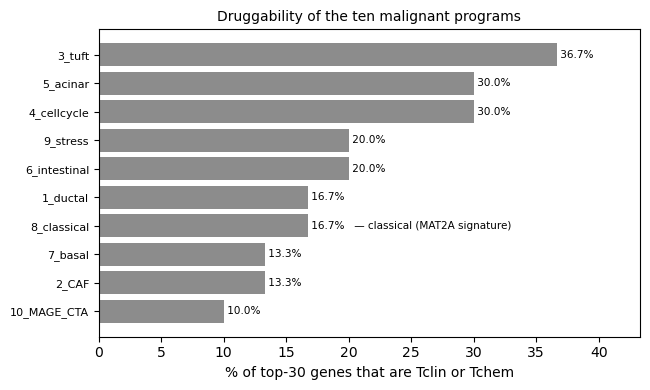

In [71]:
# ===========================================================================
# FIGURE - DRUGGABILITY BY MALIGNANT STATE   ·   not in the revised manuscript
# ===========================================================================
# Pure consumer of `tract` from the cell above: the fraction of each program's
# top 30 genes that are Tclin or Tchem, ordered most to least druggable. The
# classical program (where the MAT2A signature concentrates) is tagged inline
# on its own value label (not colour-highlighted) - it ranks mid-pack, and a
# highlight would imply an extremity the data do not show.
if FIGURES:
    _t = tract.sort_values("pct_tractable", ascending=True)
    _progs = list(_t["program"])
    _pct = list(_t["pct_tractable"].astype(float))
    _fig, _ax = plt.subplots(figsize=(6.6, 4.0))
    _ax.barh(range(len(_progs)), _pct, color="0.55")
    _ax.set_yticks(range(len(_progs)))
    _ax.set_yticklabels(_progs, fontsize=8)
    # The classical program's callout is now INLINED onto its own value label.
    # Previously it was a separate arrow annotation whose text was parked to the
    # right of the bar tip, directly on top of the "16.7%" number; an inline tag
    # extends into the empty space past the bar and can never cover the value.
    _ci = _progs.index(CLASSICAL_PROG) if CLASSICAL_PROG in _progs else -1
    for _i, _v in enumerate(_pct):
        _lab = " {:.1f}%".format(_v)
        if _i == _ci:
            _lab += "   \u2014 classical (MAT2A signature)"
        _ax.text(_v, _i, _lab, va="center", fontsize=7.5)
    _ax.set_xlabel("% of top-30 genes that are Tclin or Tchem")
    _ax.set_title("Druggability of the ten malignant programs", fontsize=10)
    _ax.margins(x=0.18)
    plt.tight_layout()
    _show("druggability_by_program")

## 17 · Summary

*Results / Conclusion.* The three targets, both cohorts, side by side: coefficient, distance from
each cohort's own random-gene-set null (in SD), and Wilcoxon p. The final panel places all four
signatures on the null-distance axis for both cohorts at a glance. The revision's numbers —
equivalence tests, held-out DepMap validation, harder nulls, CIs — are collected in §R10.
This summary is on the **classical** axis; the *VPS4A*–basal association is tested in §R8c.

This summary is on the classical axis; the basal-axis results are in §R8.

In [72]:
# ==========================================================================
# 17 · SUMMARY TABLE
# The three targets in both cohorts: coefficient, SD from each cohort's own random null, and
# Wilcoxon p. Written to summary_three_targets.csv.
# ==========================================================================

print("RESULTS\n")
rows = []
for t in TARGETS:
    p, s = summarise(res[t]), summarise(s_res[t])
    rows.append({"target": t,
                 "Peng rho": round(p["mean_rho"], 4),
                 "Peng SD": round(sd_from(p["mean_rho"], null), 1),
                 "Peng p": round(p["p"], 4),
                 "Steele rho": round(s["mean_rho"], 4),
                 "Steele SD": round(sd_from(s["mean_rho"], s_null), 1),
                 "Steele p": round(s["p"], 4)})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
summary.to_csv(os.path.join(DOWNLOADS, "summary_three_targets.csv"), index=False)
print()
print("  VPS4A : not separated from a random gene list -- no detected association")
print("          (equivalence to zero: R6).")
print("  PRMT5 : not separated from a random gene list -- no detected association (R6).")
print("  MAT2A : positively associated with the classical score in both cohorts, above")
print("          the commonly-essential control (which moves the opposite way). Whether this")
print("          reflects dependency or epithelial programs: R4-R8.")
print()
print("  Gene-overlap positive controls register (section 13); dependency-based")
print("  positive controls and equivalence tests are in R7 and R6.")
print()
print("  saved: summary_three_targets.csv")

RESULTS

target  Peng rho  Peng SD  Peng p  Steele rho  Steele SD  Steele p
 VPS4A   -0.0365     -0.6  0.1515     -0.0104       -0.2    0.9515
 PRMT5    0.0325      0.2  0.0691      0.0134        0.1    0.6257
 MAT2A    0.3094      3.4  0.0000      0.3168        4.0    0.0002

  VPS4A : not separated from a random gene list -- no detected association
          (equivalence to zero: R6).
  PRMT5 : not separated from a random gene list -- no detected association (R6).
  MAT2A : positively associated with the classical score in both cohorts, above
          the commonly-essential control (which moves the opposite way). Whether this
          reflects dependency or epithelial programs: R4-R8.

  Gene-overlap positive controls register (section 13); dependency-based
  positive controls and equivalence tests are in R7 and R6.

  saved: summary_three_targets.csv


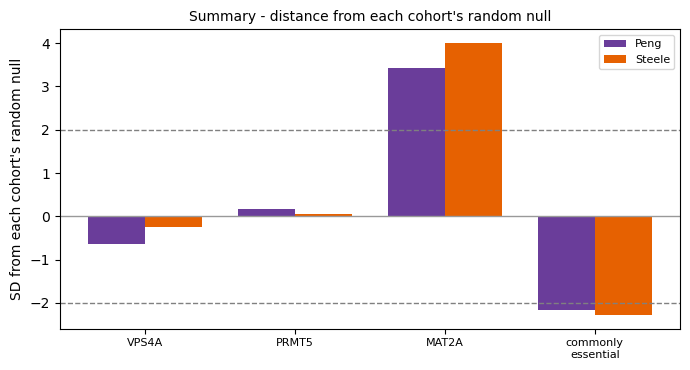

In [73]:
# ===========================================================================
# FIGURE - SUMMARY: distance from the random null, both cohorts
# ===========================================================================
# Pure consumer of res / s_res / null / s_null. All four signatures on the
# null-distance (SD) axis for both cohorts, with the +/-2 SD decision lines. One
# panel that carries the paper's whole result: MAT2A outside the band in both
# cohorts; VPS4A/PRMT5 inside; commonly-essential outside on the negative side.
if FIGURES:
    _keys = TARGETS + ["common_essential"]
    _peng_sd = [sd_from(summarise(res[k])["mean_rho"], null) for k in _keys]
    _stee_sd = [sd_from(summarise(s_res[k])["mean_rho"], s_null) for k in _keys]
    _x = np.arange(len(_keys)); _w = 0.38
    _fig, _ax = plt.subplots(figsize=(7.0, 3.8))
    _ax.bar(_x - _w / 2, _peng_sd, _w, color="#6A3D9A", label="Peng")
    _ax.bar(_x + _w / 2, _stee_sd, _w, color="#E66101", label="Steele")
    for _yv in (-2, 2):
        _ax.axhline(_yv, color="0.5", ls="--", lw=1)
    _ax.axhline(0, color="0.6", lw=1)
    _ax.set_xticks(_x)
    _ax.set_xticklabels([k.replace("common_essential", "commonly\nessential") for k in _keys],
                        fontsize=8)
    _ax.set_ylabel("SD from each cohort's random null")
    _ax.set_title("Summary - distance from each cohort's random null", fontsize=10)
    _ax.legend(fontsize=8)
    plt.tight_layout()
    _show("summary_sd_from_null")
